# JogjaPulse: Understanding the Rhythm and Movement of Yogyakarta

**Comprehensive Spatial & Temporal Mobility Data Analysis — Daerah Istimewa Yogyakarta (DIY), Desember 2021 – April 2022**

Notebook ini menganalisis data agregat kehadiran perangkat seluler (*mobile device presence*) dan aliran kunjungan antarkapanewon (*origin–destination*) dari dataset **JogjaPulse** (Widyawan, 2026, Zenodo DOI 10.5281/zenodo.23157460).

| Bagian | Isi |
|---|---|
| Section 0 | Setup: konfigurasi path, library, fungsi bantu |
| Section 1 | Project introduction |
| Section 2 | Data audit & data understanding |
| Section 3 | Data cleaning & preprocessing (+ evaluasi kualitas data) |
| Section 4 | Spatial distribution analysis (S01–S10) |
| Section 5 | Temporal activity analysis (T01–T14) |
| Section 6 | Population representativeness (P01–P10) |
| Section 7 | Daily & monthly dynamics (D01–D08) |
| Section 8 | Origin–destination mobility analysis (M01–M15) |
| Section 9 | Regional attractiveness & mobility network (R01–R09) |
| Section 10 | Activity pattern clustering (L01–L08) |
| Section 11 | Data quality & validation (Q01–Q09) |
| Section 12 | Insight register |
| Section 13 | Storytelling & business insights |

> **Cara membaca notebook ini.** Setiap analisis diawali penjelasan *apa* yang dilakukan dan *mengapa*, lalu kode, lalu interpretasi. Semua angka di bagian interpretasi berasal dari output sel di atasnya; jika Anda mengganti data, jalankan ulang seluruh notebook (*Kernel → Restart & Run All*).

---
## Section 1 — Project Introduction

### 1.1 Latar belakang
Yogyakarta adalah wilayah metropolitan menengah dengan karakter yang sangat beragam: pusat kota yang padat dan menjadi tujuan wisata, kawasan pendidikan di Sleman, sabuk pinggiran yang berkembang (Bantul, Sleman), serta wilayah perdesaan dan pesisir di Gunungkidul dan Kulon Progo. Data sensus menjelaskan **di mana penduduk terdaftar**, tetapi tidak menjelaskan **di mana orang berada pada jam tertentu** dan **ke mana mereka berkunjung**.

Data lokasi perangkat seluler yang diagregasi dapat mengisi celah tersebut. JogjaPulse menyediakan hitungan perangkat per grid 500 m per hari, per kapanewon per jam, serta aliran kunjungan rumah→tujuan antarkapanewon per bulan, dengan perlindungan privasi (agregasi dan *suppression* k = 5).

### 1.2 Tujuan analisis
1. Memetakan **di mana** aktivitas perangkat terkonsentrasi (grid 500 m dan kapanewon).
2. Memahami **kapan** setiap wilayah aktif (ritme 24 jam, hari kerja vs akhir pekan, antarbulan).
3. Menilai **seberapa representatif** sampel perangkat terhadap penduduk.
4. Menganalisis **pola kunjungan** antarkapanewon (asal–tujuan, jarak, jaringan).
5. Mengelompokkan kapanewon berdasarkan **karakter ritme aktivitas**.
6. Menilai **kualitas dan keterbatasan data** secara transparan, termasuk analisis sensitivitas.

### 1.3 Pertanyaan penelitian
Total 83 pertanyaan dalam 8 kelompok: S01–S10 (spasial), T01–T14 (temporal), P01–P10 (populasi), D01–D08 (dinamika harian/bulanan), M01–M15 (asal–tujuan), R01–R09 (daya tarik & jaringan), L01–L08 (clustering), Q01–Q09 (kualitas data). Seluruhnya dicatat di **Insight Register** (Section 12), termasuk yang belum dapat dijawab beserta alasannya.

### 1.4 Gambaran umum dataset (berdasarkan README dataset)
- Sumber: 44.384.826 ping GPS dari 594.223 perangkat (MAID), dikumpulkan oleh agregator data lokasi komersial dari aplikasi yang izin lokasinya aktif, diberikan ke Universitas Gadjah Mada melalui perjanjian riset. Data individu **tidak** disertakan.
- **Periode pengamatan:** 1 Desember 2021 – 30 April 2022 (151 hari), waktu lokal WIB (UTC+7).
- **Cakupan spasial:** batas administrasi DIY; 5 kabupaten/kota, 78 kapanewon/kemantren.
- **Produk data:** (A) grid 500 m × hari, (B) kapanewon × jam, (C) aliran kunjungan rumah→tujuan per bulan, ditambah file validasi dan ringkasan suppression.

### 1.5 Definisi penting
| Istilah | Arti sederhana |
|---|---|
| **Perangkat (device/MAID)** | Satu perangkat seluler yang teramati. **Satu perangkat ≠ satu orang.** Satu orang bisa punya dua ponsel; banyak orang tidak tercakup sama sekali. |
| **Ping** | Satu catatan lokasi GPS. Banyaknya ping bergantung pada aplikasi, bukan jumlah orang. |
| **Presence (kehadiran)** | Perangkat dianggap hadir di suatu unit jika punya minimal satu ping di unit itu pada periode tersebut. |
| **`n_maids`** | Jumlah perangkat **berbeda** yang hadir. **Tidak bisa dijumlahkan** lintas jam, hari, grid, atau kapanewon untuk mendapat jumlah perangkat unik (perangkat yang sama terhitung di setiap unit yang ia datangi). |
| **Suppression (k = 5)** | Baris dengan < 5 perangkat dihapus demi privasi. **Baris hilang ≠ nol.** |
| **Rumah bulanan (OD)** | Kapanewon dengan malam (22.00–05.59) terbanyak dalam sebulan, minimal 2 malam. |
| **Kunjungan (OD)** | Perangkat dari rumah *i* yang teramati minimal sekali di *j* pada 08.00–17.59 dalam bulan itu. **Ini jumlah pengunjung, bukan jumlah perjalanan.** |

### 1.6 Ruang lingkup dan batasan
- Analisis bersifat **deskriptif dan eksploratif** terhadap sampel perangkat, bukan sensus penduduk.
- Jumlah perangkat teramati turun drastis (≈87 ribu/hari pada Desember → ≈9 ribu/hari pada April menurut README), terutama karena perubahan komposisi sampel, **bukan** karena perubahan mobilitas penduduk. Karena itu, perbandingan antarwaktu memakai **nilai ternormalisasi** (pangsa terhadap total pada jam/hari yang sama).
- Analisis kuantitatif utama memakai **periode berkualitas tinggi Desember 2021 – Februari 2022**; Maret–April dipakai untuk analisis sensitivitas (sesuai rekomendasi README untuk OD).
- Data eksternal yang dipakai hanya yang sumbernya nyata dan terdokumentasi (lihat Section 0.3). Pertanyaan yang butuh data yang belum tersedia (mis. lokasi wisata) **ditandai**, bukan dikarang.

---
## Section 0 — Setup & Konfigurasi

### 0.1 Konfigurasi utama
Semua path diatur di satu sel berikut. Secara default notebook mencari data di folder `data/raw/` relatif terhadap lokasi notebook. Jika Anda hanya punya file ZIP, letakkan ZIP di `data/` — notebook akan mengekstraknya otomatis ke `data/raw/` **tanpa mengubah file sumber**.

In [1]:
# ============================================================
# KONFIGURASI UTAMA — ubah di sini saja jika struktur folder berbeda
# ============================================================
from pathlib import Path

PROJECT_DIR = Path.cwd()                      # folder tempat notebook dijalankan
DATA_DIR = PROJECT_DIR / "data"
RAW_DIR = DATA_DIR / "raw"                    # 8 CSV + README dataset JogjaPulse
EXTERNAL_DIR = DATA_DIR / "external"          # data tambahan (batas wilayah, POI wisata, dll.)
OUTPUT_DIR = PROJECT_DIR / "outputs"
FIG_DIR = OUTPUT_DIR / "figures"
TABLE_DIR = OUTPUT_DIR / "tables"
MAP_DIR = OUTPUT_DIR / "maps"
DERIVED_DIR = OUTPUT_DIR / "derived_data"

# File data tambahan (opsional kecuali batas wilayah)
BOUNDARY_FILE = EXTERNAL_DIR / "diy_kapanewon_boundaries.geojson"
TOURISM_POI_FILE = EXTERNAL_DIR / "tourism_poi_diy.csv"          # belum tersedia -> lihat Section 0.3
URBAN_RURAL_FILE = EXTERNAL_DIR / "urban_rural_kapanewon.csv"    # belum tersedia -> dipakai proxy kepadatan

# Parameter analisis
SUPPRESSION_K = 5                    # ambang suppression dari README
HQ_START, HQ_END = "2021-12-01", "2022-02-28"   # periode berkualitas tinggi (high quality)
FULL_START, FULL_END = "2021-12-01", "2022-04-30"
CRS_WGS84 = "EPSG:4326"
CRS_UTM = "EPSG:32749"               # UTM zona 49S, satuan meter (dipakai grid dataset)
RANDOM_STATE = 42

# Pembagian waktu (jam mulai, jam akhir inklusif)
TIME_PERIODS = {
    "Dini hari": (0, 4),
    "Pagi": (5, 10),
    "Siang": (11, 14),
    "Sore": (15, 17),
    "Malam": (18, 23),
}
DATA_SOURCE_NOTE = "Sumber: JogjaPulse (Widyawan, 2026), agregat perangkat seluler DIY, Des 2021–Apr 2022"

for folder in [RAW_DIR, EXTERNAL_DIR, FIG_DIR, TABLE_DIR, MAP_DIR, DERIVED_DIR]:
    folder.mkdir(parents=True, exist_ok=True)
print("Project dir:", PROJECT_DIR)

Project dir: /home/claude/jogjapulse


In [2]:
# Import library. Setiap library dipakai di notebook ini:
# pandas/numpy (olah data), matplotlib/seaborn (grafik statis), plotly (grafik interaktif),
# geopandas/shapely/pyproj (data spasial), folium (peta interaktif), scipy (statistik),
# scikit-learn (clustering/PCA), networkx (jaringan), statsmodels (regresi), holidays (kalender libur)
import warnings
import zipfile
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots
import geopandas as gpd
from shapely.geometry import box, Point
import folium
from scipy import stats
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score
import networkx as nx
import statsmodels.api as sm
import statsmodels.formula.api as smf

try:
    import holidays as holidays_lib
except ImportError:            # ditangani eksplisit: analisis libur akan dilewati
    holidays_lib = None
    print("PERINGATAN: paket 'holidays' tidak terpasang; analisis hari libur dilewati.")

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)   # peringatan API pandas lama, tidak memengaruhi hasil
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150, "axes.titleweight": "bold",
                     "axes.titlesize": 12, "figure.titlesize": 14})
# Plotly memuat library JS dari CDN agar ukuran notebook tetap kecil
pio.renderers.default = "notebook_connected"

# Palet kabupaten/kota yang konsisten di seluruh notebook
KAB_ORDER = ["YOGYAKARTA", "SLEMAN", "BANTUL", "KULON PROGO", "GUNUNGKIDUL"]
KAB_COLORS = dict(zip(KAB_ORDER, ["#c0392b", "#2471a3", "#d68910", "#229954", "#7d3c98"]))
print("pandas", pd.__version__, "| geopandas", gpd.__version__, "| networkx", nx.__version__)

pandas 3.0.5 | geopandas 1.2.0 | networkx 3.7


### 0.2 Fungsi bantu (dipakai berulang)
Fungsi-fungsi ini menghindari kode berulang: menyimpan gambar/tabel, memberi catatan sumber pada grafik, dan mencatat insight ke **Insight Register**.

In [3]:
INSIGHTS = []   # daftar insight; diisi oleh add_insight() di setiap section


def add_insight(insight_id, question, datasets, columns, method, metric, visualization,
                status, result, interpretation, limitation):
    """Mencatat satu insight ke register. Jika ID sama sudah ada, entri lama diganti."""
    global INSIGHTS
    INSIGHTS = [row for row in INSIGHTS if row["Insight ID"] != insight_id]
    INSIGHTS.append({
        "Insight ID": insight_id, "Research question": question, "Dataset": datasets,
        "Kolom": columns, "Metode": method, "Rumus/metrik": metric,
        "Visualisasi utama": visualization, "Status": status, "Hasil analisis": result,
        "Interpretasi": interpretation, "Keterbatasan": limitation,
    })


def save_fig(fig, name, note=DATA_SOURCE_NOTE):
    """Menambahkan catatan sumber di bawah figure lalu menyimpan PNG ke outputs/figures."""
    fig.text(0.01, -0.01, note, fontsize=8, color="gray", ha="left", va="top")
    path = FIG_DIR / f"{name}.png"
    fig.savefig(path, bbox_inches="tight")
    print("Gambar disimpan:", path.relative_to(PROJECT_DIR))


def save_table(df, name, index=False):
    """Menyimpan DataFrame ke outputs/tables sebagai CSV."""
    path = TABLE_DIR / f"{name}.csv"
    df.to_csv(path, index=index)
    print("Tabel disimpan:", path.relative_to(PROJECT_DIR))


def fmt_list(series, n=5, fmt="{:.2f}"):
    """Ubah Series (index=nama, value=angka) menjadi teks ringkas 'A (1.23), B (0.98)'."""
    return ", ".join(f"{idx} ({fmt.format(val)})" for idx, val in series.head(n).items())


def gini(values):
    """Koefisien Gini: 0 = merata sempurna, 1 = terkonsentrasi di satu unit."""
    x = np.sort(np.asarray(values, dtype=float))
    x = x[~np.isnan(x)]
    if x.sum() == 0 or len(x) == 0:
        return np.nan
    n = len(x)
    cum = np.cumsum(x)
    return (n + 1 - 2 * (cum / cum[-1]).sum()) / n


def time_period_of(hour):
    """Mengembalikan nama periode waktu untuk jam 0–23 sesuai TIME_PERIODS."""
    for name, (start, end) in TIME_PERIODS.items():
        if start <= hour <= end:
            return name
    return None


def corr_report(x, y, label=""):
    """Pearson & Spearman beserta p-value, mengabaikan pasangan yang mengandung NaN."""
    data = pd.DataFrame({"x": x, "y": y}).dropna()
    pr, pp = stats.pearsonr(data.x, data.y)
    sr, sp = stats.spearmanr(data.x, data.y)
    return {"label": label, "n": len(data), "pearson_r": pr, "pearson_p": pp,
            "spearman_rho": sr, "spearman_p": sp}

print("Fungsi bantu siap.")

Fungsi bantu siap.


### 0.3 Ketersediaan data (dataset utama + data tambahan)
Sel berikut memastikan 8 CSV tersedia. Jika belum, ia mencoba mengekstrak ZIP di folder `data/`.

**Data tambahan yang dipakai / dibutuhkan:**

| Data | Status | Sumber & catatan |
|---|---|---|
| Batas kapanewon DIY (GeoJSON) | **Disertakan** di `data/external/diy_kapanewon_boundaries.geojson` | Diekstrak dari repositori publik GitHub `Alf-Anas/batas-administrasi-indonesia`, berkas *Kecamatan SHP* (pembaruan 13 Juni 2023; kode wilayah format Kemendagri). Sumber hulu tidak dinyatakan di repositori tersebut. Sudah divalidasi: **78/78 kode dan nama cocok** dengan dataset; luas total ≈ 3.168 km². README dataset menyebut batas yang dipakai pembuat data adalah *data kalurahan Geoportal Pemerintah DIY 2023* — untuk publikasi resmi, ganti file ini dengan unduhan dari https://geoportal.jogjaprov.go.id (dissolve kalurahan → kapanewon), simpan dengan nama yang sama. |
| Kalender hari libur nasional 2021–2022 | **Dipakai** via paket Python `holidays` (PyPI) | Libur nasional Indonesia. Cuti bersama tidak tercakup. |
| Klasifikasi urban/rural resmi | **Belum tersedia** → dipakai **proxy kepadatan penduduk** (penduduk dari dataset ÷ luas poligon). | Sumber resmi: Peraturan BPS No. 120/2020 tentang klasifikasi desa perkotaan/perdesaan (tingkat desa). Jika tersedia, simpan `data/external/urban_rural_kapanewon.csv` dengan kolom `kapanewon_code,urban_rural` (nilai `Perkotaan`/`Perdesaan`); notebook otomatis memakainya. |
| Koordinat & kategori lokasi wisata | **Belum tersedia** | Lihat instruksi di bawah. Pertanyaan S07, T13, D08 (bagian wisata), R09, L08 ditandai *requires external data* sampai file ini ada. |
| Centroid kapanewon | **Dihitung** dari poligon batas (EPSG:32749) | — |
| Jaringan jalan | **Tidak dipakai** | Jarak OD memakai garis lurus antar-centroid (sesuai README). Jarak jalan bisa dihitung dengan OSMnx/OSRM jika diperlukan. |

**Instruksi menyiapkan `tourism_poi_diy.csv` (opsional):**
1. Buka https://overpass-turbo.eu dan jalankan query berikut (wilayah DIY):
   ```
   [out:json][timeout:120];
   area["name"="Daerah Istimewa Yogyakarta"]["admin_level"="4"]->.diy;
   ( nwr["tourism"~"attraction|museum|viewpoint|theme_park|zoo|gallery"](area.diy);
     nwr["natural"="beach"](area.diy);
     nwr["historic"~"monument|castle|archaeological_site|memorial"](area.diy); );
   out center;
   ```
2. Ekspor (*Export → raw data*) lalu ubah menjadi CSV dengan kolom: `name,category,lat,lon,source` (untuk *way/relation* pakai koordinat `center`).
3. Simpan sebagai `data/external/tourism_poi_diy.csv`, lalu jalankan ulang notebook. Alternatif resmi: daftar daya tarik wisata Dinas Pariwisata DIY (https://visitingjogja.jogjaprov.go.id) yang sudah digeokode.

In [4]:
EXPECTED_FILES = [
    "presence_cell500m_daily.csv", "presence_kapanewon_hourly.csv",
    "home_maids_vs_population_kapanewon.csv", "validation_night_presence_kapanewon.csv",
    "tier1_summary.csv", "od_home_visits_kapanewon_monthly.csv",
    "od_origin_homes_monthly.csv", "od_summary.csv",
]


def ensure_raw_data():
    """Pastikan CSV ada di RAW_DIR; jika tidak, ekstrak ZIP pertama yang ditemukan di DATA_DIR.
    File di dalam ZIP diekstrak apa adanya (file sumber tidak diubah)."""
    missing = [f for f in EXPECTED_FILES if not (RAW_DIR / f).exists()]
    if not missing:
        return
    zips = sorted(DATA_DIR.glob("*.zip"))
    if not zips:
        raise FileNotFoundError(f"File berikut tidak ditemukan di {RAW_DIR}: {missing}. "
                                f"Letakkan CSV di sana atau ZIP dataset di {DATA_DIR}.")
    with zipfile.ZipFile(zips[0]) as zf:
        for member in zf.namelist():
            name = Path(member).name
            if name.endswith(".csv") or name.lower().startswith("readme"):
                target = RAW_DIR / (name if name.endswith(".csv") else "README_dataset.md")
                target.write_bytes(zf.read(member))
    print("ZIP diekstrak:", zips[0].name)


ensure_raw_data()
availability = pd.DataFrame({
    "file": EXPECTED_FILES + ["README_dataset.md", BOUNDARY_FILE.name, TOURISM_POI_FILE.name, URBAN_RURAL_FILE.name],
    "lokasi": ["raw"] * 9 + ["external"] * 3,
})
availability["tersedia"] = [
    (RAW_DIR / f).exists() if loc == "raw" else (EXTERNAL_DIR / f).exists()
    for f, loc in zip(availability.file, availability.lokasi)
]
HAS_BOUNDARY = BOUNDARY_FILE.exists()
HAS_TOURISM = TOURISM_POI_FILE.exists()
HAS_URBAN_RURAL = URBAN_RURAL_FILE.exists()
availability

,file,lokasi,tersedia
0,presence_cell500m_daily.csv,raw,True
1,presence_kapanewon_hourly.csv,raw,True
2,home_maids_vs_population_kapanewon.csv,raw,True
3,validation_night_presence_kapanewon.csv,raw,True
4,tier1_summary.csv,raw,True
5,od_home_visits_kapanewon_monthly.csv,raw,True
6,od_origin_homes_monthly.csv,raw,True
7,od_summary.csv,raw,True
8,README_dataset.md,raw,True
9,diy_kapanewon_boundaries.geojson,external,True


---
## Section 2 — Data Audit & Data Understanding

### 2.1 Membaca README dataset
README adalah sumber definisi resmi. Sel berikut menampilkan bagian-bagian kunci README (definisi, privasi, keterbatasan) agar analisis selalu merujuk dokumen aslinya.

In [5]:
readme_text = (RAW_DIR / "README_dataset.md").read_text(encoding="utf-8")
sections_to_show = ["## 3. Common definitions", "## 5. Privacy protection", "## 6. Known limitations"]
for header in sections_to_show:
    start = readme_text.find(header)
    end = readme_text.find("\n## ", start + 5)
    print(readme_text[start:end].strip()[:2500], "\n" + "-" * 100)

## 3. Common definitions

| Term | Definition |
|---|---|
| **Device / MAID** | A mobile device, identified in the source data by its mobile advertising identifier. One device is not necessarily one person. |
| **Ping** | One GPS location record of a device. |
| **Presence** | A device is present in a spatial unit during a time period if it has at least one ping inside that unit during that period. |
| **`n_maids`** | Number of **distinct** devices present. Distinct counts are **not additive**: a device present in two cells (or two hours) is counted once in each. Do not sum `n_maids` across cells, kapanewon, hours or days to obtain totals. |
| **`n_pings`** | Number of pings. Additive. Ping frequency varies between devices and applications, so `n_pings` measures data volume rather than the number of people. |
| **Time zone** | All dates and hours are local time, Western Indonesia Time (WIB, UTC+7). |
| **Spatial extent** | Only pings inside the administrative boundary of DIY are counte

### 2.2 Memuat seluruh file
Kolom kode wilayah (`kab_code`, `kapanewon_code`, `origin_code`, dll.) **harus dibaca sebagai teks**. Jika dibiarkan otomatis, pandas membaca `34.01` sebagai angka `34.1` sehingga kode Kulon Progo (`34.01`) dan kode fiktif `34.10` menjadi sama. Sel berikut membuktikan masalah ini lalu memuat data dengan tipe yang benar.

In [6]:
# Bukti masalah tipe data: pembacaan default mengubah kode kabupaten menjadi float
naive = pd.read_csv(RAW_DIR / "od_origin_homes_monthly.csv", nrows=5)
print("Tipe default origin_kab_code:", naive["origin_kab_code"].dtype, "| contoh nilai:", naive["origin_kab_code"].tolist()[:3])

CODE_COLUMNS = ["kab_code", "kapanewon_code", "origin_kab_code", "origin_code", "dest_kab_code", "dest_code"]


def load_csv(name):
    """Membaca CSV dari RAW_DIR dengan kolom kode sebagai string (tidak mengubah file sumber)."""
    header = pd.read_csv(RAW_DIR / name, nrows=0).columns
    dtype = {col: str for col in CODE_COLUMNS if col in header}
    return pd.read_csv(RAW_DIR / name, dtype=dtype)


raw = {name: load_csv(name) for name in EXPECTED_FILES}
pd.DataFrame({"file": list(raw), "baris": [len(d) for d in raw.values()], "kolom": [d.shape[1] for d in raw.values()]})

Tipe default origin_kab_code: float64 | contoh nilai: [34.01, 34.01, 34.01]


,file,baris,kolom
0,presence_cell500m_daily.csv,183548,7
1,presence_kapanewon_hourly.csv,230418,8
2,home_maids_vs_population_kapanewon.csv,78,5
3,validation_night_presence_kapanewon.csv,156,7
4,tier1_summary.csv,2,8
5,od_home_visits_kapanewon_monthly.csv,9894,11
6,od_origin_homes_monthly.csv,390,8
7,od_summary.csv,1,7


### 2.3 Audit per file
Fungsi `audit_dataframe()` menampilkan untuk setiap file: dimensi, kolom & tipe data, 5 baris contoh, missing values, duplikasi, nilai unik kolom kategorikal, rentang tanggal, dan statistik deskriptif.

In [7]:
DATE_COLUMNS = {"date", "month"}


def audit_dataframe(name, df, max_unique_show=8):
    print("=" * 110)
    print(f"FILE: {name}  |  {df.shape[0]:,} baris × {df.shape[1]} kolom")
    print("=" * 110)
    info = pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "missing": df.isna().sum(),
        "missing_%": (df.isna().mean() * 100).round(2),
        "n_unique": df.nunique(),
    })
    display(info)
    print("Contoh 5 baris:")
    display(df.head(5))
    print(f"Baris duplikat penuh: {df.duplicated().sum():,}")
    # kolom kategorikal = bertipe teks/boolean
    categorical = [c for c in df.columns if (df[c].dtype == object or str(df[c].dtype) in ("string", "str", "bool"))
                   and c not in DATE_COLUMNS]
    for col in categorical:
        values = df[col].dropna().unique()
        shown = ", ".join(map(str, sorted(values, key=str)[:max_unique_show]))
        suffix = " ..." if len(values) > max_unique_show else ""
        print(f"  - {col}: {len(values)} nilai unik -> {shown}{suffix}")
    for col in DATE_COLUMNS & set(df.columns):
        print(f"  Rentang {col}: {df[col].min()} s.d. {df[col].max()} ({df[col].nunique()} nilai unik)")
    numeric = df.select_dtypes("number")
    if not numeric.empty:
        print("Statistik deskriptif kolom numerik:")
        display(numeric.describe().T)

In [8]:
for name in EXPECTED_FILES[:2]:
    audit_dataframe(name, raw[name])

FILE: presence_cell500m_daily.csv  |  183,548 baris × 7 kolom


,dtype,missing,missing_%,n_unique
cell_id,str,0,0.0000,5715
x_min_utm,int64,0,0.0000,167
y_min_utm,int64,0,0.0000,129
centroid_lon,float64,0,0.0000,5715
centroid_lat,float64,0,0.0000,5715
date,str,0,0.0000,151
n_maids,int64,0,0.0000,1319


Contoh 5 baris:


,cell_id,x_min_utm,y_min_utm,centroid_lon,centroid_lat,date,n_maids
0,E786_N18255,393000,9127500,110.0316,-7.8899,2021-12-01,9
1,E789_N18259,394500,9129500,110.0452,-7.8718,2021-12-01,7
2,E790_N18255,395000,9127500,110.0497,-7.8899,2021-12-01,17
3,E791_N18254,395500,9127000,110.0543,-7.8945,2021-12-01,5
4,E792_N18252,396000,9126000,110.0588,-7.9035,2021-12-01,20


Baris duplikat penuh: 0
  - cell_id: 5715 nilai unik -> E786_N18255, E787_N18255, E787_N18256, E788_N18255, E788_N18256, E789_N18256, E789_N18257, E789_N18258 ...
  Rentang date: 2021-12-01 s.d. 2022-04-30 (151 nilai unik)
Statistik deskriptif kolom numerik:


,count,mean,std,min,25%,50%,75%,max
x_min_utm,"183,548.0000","430,280.8448","12,562.5295","393,000.0000","425,000.0000","430,500.0000","435,500.0000","479,500.0000"
y_min_utm,"183,548.0000","9,136,254.1433","9,822.2616","9,096,000.0000","9,130,500.0000","9,137,500.0000","9,143,000.0000","9,162,000.0000"
centroid_lon,"183,548.0000",110.3699,0.1139,110.0316,110.3218,110.3719,110.4172,110.8162
centroid_lat,"183,548.0000",-7.8113,0.0889,-8.1759,-7.8634,-7.8004,-7.7505,-7.5786
n_maids,"183,548.0000",46.6674,151.8076,5.0000,7.0000,13.0000,34.0000,"10,971.0000"


... (4 outputs left out)

Baris duplikat penuh: 0


  - kab_code: 5 nilai unik -> 34.01, 34.02, 34.03, 34.04, 34.71
  - kab_kota: 5 nilai unik -> BANTUL, GUNUNGKIDUL, KULON PROGO, SLEMAN, YOGYAKARTA
  - kapanewon_code: 78 nilai unik -> 34.01.01, 34.01.02, 34.01.03, 34.01.04, 34.01.05, 34.01.06, 34.01.07, 34.01.08 ...
  - kapanewon: 77 nilai unik -> BAMBANGLIPURO, BANGUNTAPAN, BANTUL, BERBAH, CANGKRINGAN, DANUREJAN, DEPOK, DLINGO ...


  Rentang date: 2021-12-01 s.d. 2022-04-30 (151 nilai unik)
Statistik deskriptif kolom numerik:


,count,mean,std,min,25%,50%,75%,max
hour,"230,418.0000",12.0888,6.6783,0.0000,7.0000,12.0000,18.0000,23.0000
n_maids,"230,418.0000",72.0064,124.1789,5.0000,12.0000,29.0000,77.0000,"2,506.0000"
n_pings,"230,418.0000",191.4229,369.2977,5.0000,28.0000,72.0000,201.0000,"10,210.0000"


In [9]:
for name in EXPECTED_FILES[2:4]:
    audit_dataframe(name, raw[name])

FILE: home_maids_vs_population_kapanewon.csv  |  78 baris × 5 kolom


,dtype,missing,missing_%,n_unique
KAB_KOTA,str,0,0.0000,5
KEC_KAPN,str,0,0.0000,77
n_users,int64,0,0.0000,78
pop_actual,float64,0,0.0000,78
ratio,float64,0,0.0000,78


Contoh 5 baris:


,KAB_KOTA,KEC_KAPN,n_users,pop_actual,ratio
0,YOGYAKARTA,GONDOMANAN,28874,"12,850.0000",2.2470
1,SLEMAN,PAKEM,20241,"37,580.0000",0.5386
2,SLEMAN,DEPOK,39609,"130,980.0000",0.3024
3,SLEMAN,SEYEGAN,15469,"51,860.0000",0.2983
4,YOGYAKARTA,JETIS,6922,"23,480.0000",0.2948


Baris duplikat penuh: 0
  - KAB_KOTA: 5 nilai unik -> BANTUL, GUNUNGKIDUL, KULON PROGO, SLEMAN, YOGYAKARTA
  - KEC_KAPN: 77 nilai unik -> BAMBANGLIPURO, BANGUNTAPAN, BANTUL, BERBAH, CANGKRINGAN, DANUREJAN, DEPOK, DLINGO ...
Statistik deskriptif kolom numerik:


,count,mean,std,min,25%,50%,75%,max
n_users,78.0000,"6,556.6538","8,168.7487",256.0000,"1,299.5000","3,337.0000","7,364.7500","39,609.0000"
pop_actual,78.0000,"47,279.2308","26,514.8266","9,190.0000","30,540.0000","37,975.0000","55,547.5000","130,980.0000"
ratio,78.0000,0.1393,0.2595,0.0094,0.0411,0.0899,0.1475,2.2470


... (2 outputs left out)

Contoh 5 baris:


,period,kab_kota,kapanewon,night_presence,slots_published_pct,n_users,pop_actual
0,Dec 2021 - Apr 2022,BANTUL,BAMBANGLIPURO,23.9800,60.8168,4497,"41,070.0000"
1,Dec 2021 - Apr 2022,BANTUL,BANGUNTAPAN,121.8985,100.0000,24045,"125,210.0000"
2,Dec 2021 - Apr 2022,BANTUL,BANTUL,53.2283,99.1170,9798,"64,750.0000"
3,Dec 2021 - Apr 2022,BANTUL,DLINGO,8.9837,40.6181,756,"39,130.0000"
4,Dec 2021 - Apr 2022,BANTUL,IMOGIRI,31.4311,76.0486,6481,"63,130.0000"


Baris duplikat penuh: 0
  - period: 2 nilai unik -> Dec 2021 - Apr 2022, Dec 2021 - Jan 2022
  - kab_kota: 5 nilai unik -> BANTUL, GUNUNGKIDUL, KULON PROGO, SLEMAN, YOGYAKARTA
  - kapanewon: 77 nilai unik -> BAMBANGLIPURO, BANGUNTAPAN, BANTUL, BERBAH, CANGKRINGAN, DANUREJAN, DEPOK, DLINGO ...
Statistik deskriptif kolom numerik:


,count,mean,std,min,25%,50%,75%,max
night_presence,156.0000,38.0638,44.8146,5.6316,10.2889,21.5772,43.2294,278.0161
slots_published_pct,156.0000,74.3832,28.8836,3.2009,58.3057,84.2021,99.4624,100.0000
n_users,156.0000,"6,556.6538","8,142.3553",256.0000,"1,297.0000","3,337.0000","7,403.0000","39,609.0000"
pop_actual,156.0000,"47,279.2308","26,429.1565","9,190.0000","30,460.0000","37,975.0000","55,580.0000","130,980.0000"


In [10]:
for name in EXPECTED_FILES[4:]:
    audit_dataframe(name, raw[name])

FILE: tier1_summary.csv  |  2 baris × 8 kolom


,dtype,missing,missing_%,n_unique
pings_inside_diy_pct,float64,0,0.0000,1
product,str,0,0.0000,2
k,int64,0,0.0000,1
rows_total,int64,0,0.0000,2
rows_published,int64,0,0.0000,2
rows_suppressed_pct,float64,0,0.0000,2
maid_presence_suppressed_pct,float64,0,0.0000,2
n_cells_published,int64,0,0.0000,2


Contoh 5 baris:


,pings_inside_diy_pct,product,k,rows_total,rows_published,rows_suppressed_pct,maid_presence_suppressed_pct,n_cells_published
0,100.0000,A_cell500m_daily,5,518176,183548,64.6000,6.6000,5715
1,100.0000,B_kapanewon_hourly,5,273979,230418,15.9000,0.7000,78


Baris duplikat penuh: 0
  - product: 2 nilai unik -> A_cell500m_daily, B_kapanewon_hourly
Statistik deskriptif kolom numerik:


,count,mean,std,min,25%,50%,75%,max
pings_inside_diy_pct,2.0000,100.0000,0.0000,100.0000,100.0000,100.0000,100.0000,100.0000
k,2.0000,5.0000,0.0000,5.0000,5.0000,5.0000,5.0000,5.0000
rows_total,2.0000,"396,077.5000","172,673.3546","273,979.0000","335,028.2500","396,077.5000","457,126.7500","518,176.0000"
rows_published,2.0000,"206,983.0000","33,142.0948","183,548.0000","195,265.5000","206,983.0000","218,700.5000","230,418.0000"
rows_suppressed_pct,2.0000,40.2500,34.4361,15.9000,28.0750,40.2500,52.4250,64.6000
maid_presence_suppressed_pct,2.0000,3.6500,4.1719,0.7000,2.1750,3.6500,5.1250,6.6000
n_cells_published,2.0000,"2,896.5000","3,985.9609",78.0000,"1,487.2500","2,896.5000","4,305.7500","5,715.0000"


... (14 outputs left out)

Contoh 5 baris:


,k,min_nights,od_rows_total,od_rows_published,od_rows_suppressed_pct,inter_zonal_flow_kept_pct,origin_rows_published
0,5,2,19263,9894,48.6000,95.3000,390


Baris duplikat penuh: 0
Statistik deskriptif kolom numerik:


,count,mean,std,min,25%,50%,75%,max
k,1.0000,5.0000,NaN,5.0000,5.0000,5.0000,5.0000,5.0000
min_nights,1.0000,2.0000,NaN,2.0000,2.0000,2.0000,2.0000,2.0000
od_rows_total,1.0000,"19,263.0000",NaN,"19,263.0000","19,263.0000","19,263.0000","19,263.0000","19,263.0000"
od_rows_published,1.0000,"9,894.0000",NaN,"9,894.0000","9,894.0000","9,894.0000","9,894.0000","9,894.0000"
od_rows_suppressed_pct,1.0000,48.6000,NaN,48.6000,48.6000,48.6000,48.6000,48.6000
inter_zonal_flow_kept_pct,1.0000,95.3000,NaN,95.3000,95.3000,95.3000,95.3000,95.3000
origin_rows_published,1.0000,390.0000,NaN,390.0000,390.0000,390.0000,390.0000,390.0000


**Catatan audit awal (dibaca dari output di atas):**
- Kedua file presence tidak memiliki missing value maupun duplikat; nilai minimum `n_maids` = 5 sesuai ambang suppression k = 5.
- `presence_cell500m_daily.csv` mencakup 5.715 sel grid dan 151 hari; `presence_kapanewon_hourly.csv` mencakup 78 kapanewon, 151 hari, jam 0–23.
- Nama kapanewon **JETIS** muncul dua kali (Kabupaten Bantul dan Kota Yogyakarta). Join antarfile yang hanya memakai nama kapanewon akan salah; kita harus memakai kode atau pasangan (kabupaten, kapanewon).
- `home_maids_vs_population_kapanewon.csv` dan `validation_night_presence_kapanewon.csv` **tidak memiliki kode kapanewon**, hanya nama. Kode harus ditambahkan melalui pasangan (kabupaten, kapanewon).
- `od_home_visits_kapanewon_monthly.csv` hanya berisi 5 bulan; kolom `reduced_quality` bernilai True untuk Maret–April 2022.

### 2.4 Data dictionary
Kamus data berikut dirangkum dari README dataset dan hasil audit. Disimpan sebagai `data_dictionary.csv`.

In [11]:
dictionary_rows = [
    # (file, kolom, tipe, deskripsi sederhana, satuan/catatan)
    ("presence_cell500m_daily.csv", "cell_id", "string", "ID sel grid 500 m: E{easting/500}_N{northing/500} pada UTM 49S", "kunci sel"),
    ("presence_cell500m_daily.csv", "x_min_utm", "int", "Easting sudut kiri-bawah sel", "meter, EPSG:32749"),
    ("presence_cell500m_daily.csv", "y_min_utm", "int", "Northing sudut kiri-bawah sel", "meter, EPSG:32749"),
    ("presence_cell500m_daily.csv", "centroid_lon", "float", "Bujur titik tengah sel", "derajat WGS84"),
    ("presence_cell500m_daily.csv", "centroid_lat", "float", "Lintang titik tengah sel", "derajat WGS84"),
    ("presence_cell500m_daily.csv", "date", "date", "Tanggal kalender (WIB)", "YYYY-MM-DD"),
    ("presence_cell500m_daily.csv", "n_maids", "int", "Perangkat berbeda yang hadir di sel pada hari itu", "≥5; tidak aditif"),
    ("presence_kapanewon_hourly.csv", "kab_code", "string", "Kode kabupaten/kota", "mis. 34.01"),
    ("presence_kapanewon_hourly.csv", "kab_kota", "string", "Nama kabupaten/kota", "5 nilai"),
    ("presence_kapanewon_hourly.csv", "kapanewon_code", "string", "Kode kapanewon (kunci utama wilayah)", "mis. 34.01.01"),
    ("presence_kapanewon_hourly.csv", "kapanewon", "string", "Nama kapanewon", "JETIS ganda (Bantul & Kota)"),
    ("presence_kapanewon_hourly.csv", "date", "date", "Tanggal (WIB)", "YYYY-MM-DD"),
    ("presence_kapanewon_hourly.csv", "hour", "int", "Jam 0–23 (8 = 08.00–08.59 WIB)", "jam"),
    ("presence_kapanewon_hourly.csv", "n_maids", "int", "Perangkat berbeda yang hadir di kapanewon pada jam itu", "≥5; tidak aditif"),
    ("presence_kapanewon_hourly.csv", "n_pings", "int", "Jumlah ping GPS pada jam itu", "aditif; volume data, bukan orang"),
    ("home_maids_vs_population_kapanewon.csv", "KAB_KOTA", "string", "Nama kabupaten/kota", ""),
    ("home_maids_vs_population_kapanewon.csv", "KEC_KAPN", "string", "Nama kapanewon", "tanpa kode"),
    ("home_maids_vs_population_kapanewon.csv", "n_users", "int", "Perangkat yang rumah (lokasi malam tersering) di kapanewon ini, Des 2021–Apr 2022", "perangkat"),
    ("home_maids_vs_population_kapanewon.csv", "pop_actual", "float", "Jumlah penduduk resmi (README: sumber BPS, tahun referensi tidak disebutkan)", "jiwa"),
    ("home_maids_vs_population_kapanewon.csv", "ratio", "float", "n_users / pop_actual", "ukuran keterwakilan sampel"),
    ("validation_night_presence_kapanewon.csv", "period", "string", "Periode validasi", "Dec 2021 - Apr 2022 / Dec 2021 - Jan 2022"),
    ("validation_night_presence_kapanewon.csv", "kab_kota", "string", "Nama kabupaten/kota", ""),
    ("validation_night_presence_kapanewon.csv", "kapanewon", "string", "Nama kapanewon", "tanpa kode"),
    ("validation_night_presence_kapanewon.csv", "night_presence", "float", "Rata-rata n_maids per jam (jam 00–05) atas baris terpublikasi", "perangkat/jam"),
    ("validation_night_presence_kapanewon.csv", "slots_published_pct", "float", "Persen slot malam (hari × 6 jam) yang terpublikasi", "%"),
    ("validation_night_presence_kapanewon.csv", "n_users", "int", "Sama dengan file home_maids", "perangkat"),
    ("validation_night_presence_kapanewon.csv", "pop_actual", "float", "Sama dengan file home_maids", "jiwa"),
    ("tier1_summary.csv", "pings_inside_diy_pct", "float", "Persen ping sumber di dalam DIY", "%"),
    ("tier1_summary.csv", "product", "string", "A_cell500m_daily atau B_kapanewon_hourly", ""),
    ("tier1_summary.csv", "k", "int", "Ambang suppression", "perangkat"),
    ("tier1_summary.csv", "rows_total", "int", "Baris sebelum suppression", "baris"),
    ("tier1_summary.csv", "rows_published", "int", "Baris setelah suppression", "baris"),
    ("tier1_summary.csv", "rows_suppressed_pct", "float", "Persen baris disembunyikan", "%"),
    ("tier1_summary.csv", "maid_presence_suppressed_pct", "float", "Persen total n_maids yang berada di baris tersembunyi", "%"),
    ("tier1_summary.csv", "n_cells_published", "int", "Jumlah sel/kapanewon dengan ≥1 baris terpublikasi", ""),
    ("od_home_visits_kapanewon_monthly.csv", "month", "string", "Bulan YYYY-MM", ""),
    ("od_home_visits_kapanewon_monthly.csv", "origin_kab_code / origin_kab_kota", "string", "Kabupaten asal (rumah)", ""),
    ("od_home_visits_kapanewon_monthly.csv", "origin_code / origin_kapanewon", "string", "Kapanewon asal (rumah bulanan)", ""),
    ("od_home_visits_kapanewon_monthly.csv", "dest_kab_code / dest_kab_kota", "string", "Kabupaten tujuan", ""),
    ("od_home_visits_kapanewon_monthly.csv", "dest_code / dest_kapanewon", "string", "Kapanewon tujuan (siang 08.00–17.59)", ""),
    ("od_home_visits_kapanewon_monthly.csv", "n_maids", "int", "Perangkat berbeda dari asal i yang teramati di tujuan j bulan itu", "pengunjung, bukan perjalanan; ≥5"),
    ("od_home_visits_kapanewon_monthly.csv", "reduced_quality", "bool", "True untuk Maret–April 2022", ""),
    ("od_origin_homes_monthly.csv", "month", "string", "Bulan YYYY-MM", ""),
    ("od_origin_homes_monthly.csv", "origin_* (4 kolom)", "string", "Identitas kapanewon asal", ""),
    ("od_origin_homes_monthly.csv", "n_homed_maids", "int", "Perangkat dengan rumah bulanan di kapanewon ini", "≥5"),
    ("od_origin_homes_monthly.csv", "n_homed_maids_daytime", "int", "Dari n_homed_maids, yang teramati minimal sekali 08.00–17.59", "denominator OD"),
    ("od_origin_homes_monthly.csv", "reduced_quality", "bool", "True untuk Maret–April 2022", ""),
    ("od_summary.csv", "k / min_nights", "int", "Ambang suppression / minimal malam untuk rumah", ""),
    ("od_summary.csv", "od_rows_total / od_rows_published / od_rows_suppressed_pct", "int/float", "Baris OD sebelum/sesudah suppression", ""),
    ("od_summary.csv", "inter_zonal_flow_kept_pct", "float", "Persen aliran antarwilayah (i≠j) yang tetap terpublikasi", "%"),
    ("od_summary.csv", "origin_rows_published", "int", "Baris di od_origin_homes_monthly", ""),
]
data_dictionary = pd.DataFrame(dictionary_rows, columns=["file", "kolom", "tipe", "deskripsi", "satuan_catatan"])
data_dictionary.to_csv(PROJECT_DIR / "data_dictionary.csv", index=False)
save_table(data_dictionary, "data_dictionary")
data_dictionary

Tabel disimpan: outputs/tables/data_dictionary.csv


,file,kolom,tipe,deskripsi,satuan_catatan
0,presence_cell500m_daily.csv,cell_id,string,ID sel grid 500 m: E{easting/500}_N{northing/5...,kunci sel
1,presence_cell500m_daily.csv,x_min_utm,int,Easting sudut kiri-bawah sel,"meter, EPSG:32749"
2,presence_cell500m_daily.csv,y_min_utm,int,Northing sudut kiri-bawah sel,"meter, EPSG:32749"
3,presence_cell500m_daily.csv,centroid_lon,float,Bujur titik tengah sel,derajat WGS84
4,presence_cell500m_daily.csv,centroid_lat,float,Lintang titik tengah sel,derajat WGS84
5,presence_cell500m_daily.csv,date,date,Tanggal kalender (WIB),YYYY-MM-DD
6,presence_cell500m_daily.csv,n_maids,int,Perangkat berbeda yang hadir di sel pada hari itu,≥5; tidak aditif
7,presence_kapanewon_hourly.csv,kab_code,string,Kode kabupaten/kota,mis. 34.01
8,presence_kapanewon_hourly.csv,kab_kota,string,Nama kabupaten/kota,5 nilai
9,presence_kapanewon_hourly.csv,kapanewon_code,string,Kode kapanewon (kunci utama wilayah),mis. 34.01.01


### 2.5 Hubungan antarfile dan kandidat key
Sebelum menggabungkan data, kita cek **granularitas** (satu baris mewakili apa) dan **key** setiap file.

| File | Granularitas (1 baris =) | Key unik kandidat | Dapat dihubungkan via |
|---|---|---|---|
| presence_cell500m_daily | sel × hari | (`cell_id`, `date`) | sel → kapanewon via *point-in-polygon* (butuh batas wilayah) |
| presence_kapanewon_hourly | kapanewon × tanggal × jam | (`kapanewon_code`, `date`, `hour`) | `kapanewon_code` |
| home_maids_vs_population | kapanewon (periode penuh) | (`KAB_KOTA`, `KEC_KAPN`) | (kab_kota, kapanewon) → kode |
| validation_night_presence | periode × kapanewon | (`period`, `kab_kota`, `kapanewon`) | (kab_kota, kapanewon) → kode |
| od_home_visits_monthly | bulan × asal × tujuan | (`month`, `origin_code`, `dest_code`) | `origin_code`/`dest_code` = `kapanewon_code` |
| od_origin_homes_monthly | bulan × asal | (`month`, `origin_code`) | (`month`, `origin_code`) ke OD |
| tier1_summary / od_summary | produk | `product` | metadata, tidak di-merge |

**Aturan penggabungan yang dipakai:**
1. Tabel induk wilayah (`kapanewon_master`) dibangun dari file hourly (78 kode unik), lalu semua file lain dihubungkan ke kode tersebut.
2. Data berbeda granularitas **tidak** digabung baris-ke-baris; kita agregasi dulu ke granularitas yang sama (mis. kapanewon × periode) dengan metrik yang benar.
3. `n_users` (rumah periode penuh) dan `n_homed_maids` (rumah bulanan) memakai **definisi rumah yang berbeda** (README 4.7) sehingga tidak dibandingkan secara langsung sebagai angka yang sama.

In [12]:
# Verifikasi key unik setiap file
key_checks = {
    "presence_cell500m_daily.csv": ["cell_id", "date"],
    "presence_kapanewon_hourly.csv": ["kapanewon_code", "date", "hour"],
    "home_maids_vs_population_kapanewon.csv": ["KAB_KOTA", "KEC_KAPN"],
    "validation_night_presence_kapanewon.csv": ["period", "kab_kota", "kapanewon"],
    "od_home_visits_kapanewon_monthly.csv": ["month", "origin_code", "dest_code"],
    "od_origin_homes_monthly.csv": ["month", "origin_code"],
}
key_result = pd.DataFrame([
    {"file": f, "key": " + ".join(k), "duplikat_key": int(raw[f].duplicated(k).sum()),
     "key_unik": raw[f].duplicated(k).sum() == 0}
    for f, k in key_checks.items()
])
# Bukti bahwa nama kapanewon saja bukan key unik
name_check = raw["presence_kapanewon_hourly.csv"][["kab_kota", "kapanewon_code", "kapanewon"]].drop_duplicates()
print("Nama kapanewon yang muncul di >1 kabupaten:",
      name_check[name_check.kapanewon.duplicated(keep=False)].to_dict("records"))
key_result

Nama kapanewon yang muncul di >1 kabupaten: [{'kab_kota': 'BANTUL', 'kapanewon_code': '34.02.09', 'kapanewon': 'JETIS'}, {'kab_kota': 'YOGYAKARTA', 'kapanewon_code': '34.71.02', 'kapanewon': 'JETIS'}]


,file,key,duplikat_key,key_unik
0,presence_cell500m_daily.csv,cell_id + date,0,True
1,presence_kapanewon_hourly.csv,kapanewon_code + date + hour,0,True
2,home_maids_vs_population_kapanewon.csv,KAB_KOTA + KEC_KAPN,0,True
3,validation_night_presence_kapanewon.csv,period + kab_kota + kapanewon,0,True
4,od_home_visits_kapanewon_monthly.csv,month + origin_code + dest_code,0,True
5,od_origin_homes_monthly.csv,month + origin_code,0,True


---
## Section 3 — Data Cleaning & Preprocessing

Prinsip di section ini:
- **File sumber tidak diubah.** Semua hasil pembersihan disimpan sebagai *dataset turunan* di `outputs/derived_data/`.
- **Suppression ≠ nol.** Slot yang tidak ada di file berarti "0–4 perangkat" (tidak diketahui persisnya). Kita menyimpannya sebagai `NaN` dengan penanda `published = False`.
- **`n_maids` tidak dijumlahkan menjadi "perangkat unik".** Jika kita menjumlahkan `n_maids` lintas kapanewon dalam satu jam, hasilnya disebut **device-presence** (kehadiran perangkat; satu perangkat yang berpindah kapanewon dalam jam itu terhitung dua kali). Jika dijumlahkan lintas jam, hasilnya **device-hours**. Keduanya ukuran intensitas, bukan jumlah orang/perangkat unik.

### 3.1 Tabel induk wilayah (`kapanewon_master`)
Kita membangun satu tabel acuan 78 kapanewon: kode, nama terstandar, kabupaten, poligon batas, luas, centroid, penduduk, dan kelas kepadatan.

In [13]:
def standardize_name(series):
    """Standardisasi nama wilayah: huruf kapital, spasi ganda dihapus, spasi tepi dihapus."""
    return series.astype(str).str.upper().str.strip().str.replace(r"\s+", " ", regex=True)


hourly_raw = raw["presence_kapanewon_hourly.csv"]
kapanewon_master = (hourly_raw[["kab_code", "kab_kota", "kapanewon_code", "kapanewon"]]
                    .drop_duplicates().sort_values("kapanewon_code").reset_index(drop=True))
kapanewon_master["kab_kota"] = standardize_name(kapanewon_master["kab_kota"])
kapanewon_master["kapanewon"] = standardize_name(kapanewon_master["kapanewon"])

# Validasi format kode: kab = 34.XX, kapanewon = 34.XX.YY, dan prefix kapanewon = kode kabupaten
code_ok = (kapanewon_master.kab_code.str.fullmatch(r"34\.\d{2}")
           & kapanewon_master.kapanewon_code.str.fullmatch(r"34\.\d{2}\.\d{2}")
           & (kapanewon_master.kapanewon_code.str[:5] == kapanewon_master.kab_code))
print(f"Jumlah kapanewon: {len(kapanewon_master)} | kode valid: {code_ok.sum()} | kode unik: {kapanewon_master.kapanewon_code.is_unique}")
print(kapanewon_master.groupby("kab_kota").size().rename("jumlah_kapanewon").to_string())

# Label unik untuk grafik: tambahkan kabupaten pada nama ganda (JETIS)
dup_names = kapanewon_master.kapanewon.duplicated(keep=False)
kapanewon_master["label"] = np.where(
    dup_names, kapanewon_master.kapanewon + " (" + kapanewon_master.kab_kota.str.title() + ")",
    kapanewon_master.kapanewon)
KEY_BY_NAME = {(r.kab_kota, r.kapanewon): r.kapanewon_code for r in kapanewon_master.itertuples()}
LABEL = kapanewon_master.set_index("kapanewon_code")["label"]
KAB_OF = kapanewon_master.set_index("kapanewon_code")["kab_kota"]

Jumlah kapanewon: 78 | kode valid: 78 | kode unik: True
kab_kota
BANTUL         17
GUNUNGKIDUL    18
KULON PROGO    12
SLEMAN         17
YOGYAKARTA     14


In [14]:
# Gabungkan batas wilayah (jika tersedia) -> luas & centroid
if HAS_BOUNDARY:
    boundaries = gpd.read_file(BOUNDARY_FILE)
    boundaries = boundaries.rename(columns={"KODE_KEC": "kapanewon_code"})[["kapanewon_code", "KECAMATAN", "geometry"]]
    check = kapanewon_master.merge(boundaries, on="kapanewon_code", how="outer", indicator=True)
    name_match = (standardize_name(check.KECAMATAN) == check.kapanewon)
    print("Hasil join kode dataset ↔ batas wilayah:", check["_merge"].value_counts().to_dict(),
          "| nama cocok:", int(name_match.sum()), "/", len(check))
    gdf_kap = gpd.GeoDataFrame(kapanewon_master.merge(boundaries[["kapanewon_code", "geometry"]], on="kapanewon_code"),
                               geometry="geometry", crs=boundaries.crs).to_crs(CRS_WGS84)
    gdf_kap_utm = gdf_kap.to_crs(CRS_UTM)
    gdf_kap["area_km2"] = gdf_kap_utm.area.values / 1e6
    centroids_utm = gdf_kap_utm.geometry.representative_point()   # titik dijamin di dalam poligon
    centroids_geo = gpd.GeoSeries(centroids_utm, crs=CRS_UTM).to_crs(CRS_WGS84)
    gdf_kap["cx_utm"], gdf_kap["cy_utm"] = centroids_utm.x.values, centroids_utm.y.values
    gdf_kap["lon"], gdf_kap["lat"] = centroids_geo.x.values, centroids_geo.y.values
    kapanewon_master = pd.DataFrame(gdf_kap.drop(columns="geometry"))
    # Versi sederhana (toleransi ~30 m) khusus untuk peta agar file HTML ringan
    gdf_kap_simple = gdf_kap.copy()
    gdf_kap_simple["geometry"] = gdf_kap_utm.geometry.simplify(30).to_crs(CRS_WGS84).values
    print(f"Total luas: {gdf_kap.area_km2.sum():,.0f} km²")
else:
    gdf_kap = None
    print("Batas wilayah tidak tersedia: analisis spasial berbasis poligon & jarak akan dilewati.")

Hasil join kode dataset ↔ batas wilayah: {'both': 78, 'left_only': 0, 'right_only': 0} | nama cocok: 78 / 78
Total luas: 3,168 km²


### 3.2 Populasi & validasi malam: menambahkan kode kapanewon
File populasi dan validasi hanya memiliki nama. Kita memetakan nama ke kode melalui pasangan (kabupaten, kapanewon) dan memeriksa bahwa tidak ada yang gagal dipetakan.

In [15]:
population = raw["home_maids_vs_population_kapanewon.csv"].rename(columns={"KAB_KOTA": "kab_kota", "KEC_KAPN": "kapanewon"})
population["kab_kota"], population["kapanewon"] = standardize_name(population.kab_kota), standardize_name(population.kapanewon)
population["kapanewon_code"] = [KEY_BY_NAME.get(k) for k in zip(population.kab_kota, population.kapanewon)]

validation = raw["validation_night_presence_kapanewon.csv"].copy()
validation["kab_kota"], validation["kapanewon"] = standardize_name(validation.kab_kota), standardize_name(validation.kapanewon)
validation["kapanewon_code"] = [KEY_BY_NAME.get(k) for k in zip(validation.kab_kota, validation.kapanewon)]

print("Populasi: gagal dipetakan =", population.kapanewon_code.isna().sum(), "| baris =", len(population))
print("Validasi: gagal dipetakan =", validation.kapanewon_code.isna().sum(), "| baris =", len(validation))
# Konsistensi: rasio di file = n_users / pop_actual ?
ratio_diff = (population.n_users / population.pop_actual - population.ratio).abs().max()
print(f"Selisih maksimum ratio vs n_users/pop_actual: {ratio_diff:.2e}")
# Konsistensi antarfile: n_users & pop_actual di file validasi = file populasi?
cmp = validation.merge(population[["kapanewon_code", "n_users", "pop_actual"]], on="kapanewon_code", suffixes=("_val", "_pop"))
print("n_users identik:", (cmp.n_users_val == cmp.n_users_pop).all(), "| pop_actual identik:", np.allclose(cmp.pop_actual_val, cmp.pop_actual_pop))

kapanewon_master = kapanewon_master.merge(population[["kapanewon_code", "n_users", "pop_actual", "ratio"]],
                                          on="kapanewon_code", how="left")
if "area_km2" in kapanewon_master:
    kapanewon_master["density"] = kapanewon_master.pop_actual / kapanewon_master.area_km2

Populasi: gagal dipetakan = 0 | baris = 78
Validasi: gagal dipetakan = 0 | baris = 156
Selisih maksimum ratio vs n_users/pop_actual: 1.11e-16
n_users identik: True | pop_actual identik: True


### 3.3 Klasifikasi urban/rural
Dataset tidak menyediakan klasifikasi urban/rural. Jika file resmi tersedia (`urban_rural_kapanewon.csv`), notebook memakainya. Jika tidak, kita memakai **proxy kepadatan penduduk** (jiwa/km²) yang dibagi menjadi tiga kelompok sama besar (tersil):
- **Padat (proxy urban)** — sepertiga kapanewon terpadat,
- **Transisi** — sepertiga tengah,
- **Jarang (proxy rural)** — sepertiga paling jarang.

> Ini **bukan** klasifikasi resmi BPS. Kepadatan hanya salah satu kriteria perkotaan (BPS juga memakai persentase rumah tangga pertanian dan akses fasilitas). Semua hasil "urban vs rural" di notebook ini harus dibaca sebagai "padat vs jarang".

In [16]:
DENSITY_LABELS = ["Jarang (proxy rural)", "Transisi", "Padat (proxy urban)"]
if HAS_URBAN_RURAL:
    ur = pd.read_csv(URBAN_RURAL_FILE, dtype={"kapanewon_code": str})
    kapanewon_master = kapanewon_master.merge(ur[["kapanewon_code", "urban_rural"]], on="kapanewon_code", how="left")
    URBAN_COL, URBAN_SOURCE = "urban_rural", "klasifikasi resmi (file eksternal)"
elif "density" in kapanewon_master:
    kapanewon_master["urban_rural"] = pd.qcut(kapanewon_master.density, 3, labels=DENSITY_LABELS).astype(str)
    URBAN_COL, URBAN_SOURCE = "urban_rural", "proxy tersil kepadatan penduduk"
else:
    kapanewon_master["urban_rural"] = "Tidak diketahui"
    URBAN_COL, URBAN_SOURCE = "urban_rural", "tidak tersedia"
URBAN_ORDER = [c for c in ["Padat (proxy urban)", "Transisi", "Jarang (proxy rural)", "Perkotaan", "Perdesaan"]
               if c in set(kapanewon_master.urban_rural)]
print("Sumber klasifikasi:", URBAN_SOURCE)
summary_ur = kapanewon_master.groupby("urban_rural").agg(
    jumlah=("kapanewon_code", "size"), kepadatan_min=("density", "min"), kepadatan_median=("density", "median"),
    kepadatan_max=("density", "max"))
display(summary_ur)
print(pd.crosstab(kapanewon_master.kab_kota, kapanewon_master.urban_rural))

Sumber klasifikasi: proxy tersil kepadatan penduduk


,jumlah,kepadatan_min,kepadatan_median,kepadatan_max
urban_rural,,,,
Jarang (proxy rural),26,268.9663,530.4156,817.1370
Padat (proxy urban),26,"2,391.1944","8,736.0265","18,998.9289"
Transisi,26,869.6932,"1,320.9750","2,331.5584"


urban_rural  Jarang (proxy rural)  Padat (proxy urban)  Transisi
kab_kota                                                        
BANTUL                          1                    5        11
GUNUNGKIDUL                    17                    0         1
KULON PROGO                     6                    0         6
SLEMAN                          2                    7         8
YOGYAKARTA                      0                   14         0


### 3.4 Panel kapanewon × tanggal × jam (lengkap) dan penanda suppression
Kita membuat panel lengkap 78 × 151 × 24 slot. Slot yang tidak ada di file diberi `n_maids = NaN` dan `published = False`. Kemudian kita tambahkan atribut waktu: hari dalam minggu, akhir pekan, hari libur nasional, bulan, periode waktu, dan penanda periode berkualitas tinggi.

Metrik normalisasi utama — **pangsa kehadiran (presence share)**:

$$\text{share}_{k,t} = \frac{n\_maids_{k,t}}{\sum_{k'} n\_maids_{k',t}}$$

yaitu porsi kapanewon *k* dari total device-presence DIY pada jam *t* yang sama. Karena dibandingkan pada jam yang sama, pangsa ini **tidak terpengaruh penurunan ukuran sampel** dari waktu ke waktu. Slot tersuppress (0–4 perangkat) memiliki pangsa sangat kecil; saat dirata-rata kita perlakukan sebagai 0, sehingga rata-rata pangsa adalah **batas bawah** (*lower bound*).

In [17]:
hourly = hourly_raw.copy()
hourly["date"] = pd.to_datetime(hourly["date"], format="%Y-%m-%d", errors="raise")

# Pemeriksaan tanggal & jam
all_dates = pd.date_range(FULL_START, FULL_END, freq="D")
print("Tanggal hilang dari file hourly:", sorted(set(all_dates) - set(hourly.date)))
print("Jam di luar 0–23:", int((~hourly.hour.between(0, 23)).sum()))
print("n_maids < 5:", int((hourly.n_maids < SUPPRESSION_K).sum()), "| nilai negatif:", int((hourly[["n_maids", "n_pings"]] < 0).sum().sum()),
      "| n_pings < n_maids (mustahil):", int((hourly.n_pings < hourly.n_maids).sum()))

full_index = pd.MultiIndex.from_product([kapanewon_master.kapanewon_code, all_dates, range(24)],
                                        names=["kapanewon_code", "date", "hour"])
panel = (hourly.set_index(["kapanewon_code", "date", "hour"])[["n_maids", "n_pings"]]
         .reindex(full_index).reset_index())
panel["published"] = panel.n_maids.notna()
panel = panel.merge(kapanewon_master[["kapanewon_code", "kab_kota", "kapanewon", "label", "urban_rural"]], on="kapanewon_code")

# Atribut waktu
if holidays_lib is not None:
    ID_HOLIDAYS = {pd.Timestamp(d): name for d, name in holidays_lib.Indonesia(years=[2021, 2022]).items()
                   if FULL_START <= str(d) <= FULL_END}
else:
    ID_HOLIDAYS = {}
DOW_NAMES = ["Senin", "Selasa", "Rabu", "Kamis", "Jumat", "Sabtu", "Minggu"]
panel["dow"] = panel.date.dt.dayofweek
panel["dow_name"] = pd.Categorical(panel.dow.map(dict(enumerate(DOW_NAMES))), categories=DOW_NAMES, ordered=True)
panel["is_weekend"] = panel.dow >= 5
panel["is_holiday"] = panel.date.isin(list(ID_HOLIDAYS))
panel["day_type"] = np.select([panel.is_holiday, panel.is_weekend], ["Libur nasional", "Akhir pekan"], "Hari kerja")
panel["month"] = panel.date.dt.strftime("%Y-%m")
panel["period"] = panel.hour.map(time_period_of)
panel["hq"] = panel.date.between(HQ_START, HQ_END)

# Pangsa kehadiran per jam (published saja di penyebut)
slot_total = panel.groupby(["date", "hour"]).n_maids.transform("sum")
panel["share"] = panel.n_maids / slot_total
panel["share_lb"] = panel.share.fillna(0.0)        # lower bound: slot tersuppress -> 0
panel["pings_per_maid"] = panel.n_pings / panel.n_maids

print(f"Panel: {len(panel):,} slot | terpublikasi {panel.published.mean():.1%} | tersuppress/kosong {(~panel.published).mean():.1%}")
print("Hari libur nasional dalam periode:", {d.date().isoformat(): n for d, n in ID_HOLIDAYS.items()})

Tanggal hilang dari file hourly: []
Jam di luar 0–23: 0
n_maids < 5: 0 | nilai negatif: 0 | n_pings < n_maids (mustahil): 0


Panel: 282,672 slot | terpublikasi 81.5% | tersuppress/kosong 18.5%
Hari libur nasional dalam periode: {'2021-12-25': 'Hari Raya Natal', '2022-01-01': 'Tahun Baru Masehi', '2022-02-28': 'Isra Mikraj Nabi Muhammad', '2022-04-15': 'Wafat Yesus Kristus', '2022-03-03': 'Hari Suci Nyepi', '2022-02-01': 'Tahun Baru Imlek'}


**Mengapa slot kosong = "0–4", bukan sekadar "1–4"?** Panel lengkap berisi 282.672 slot, sedangkan `tier1_summary.csv` mencatat `rows_total` (sebelum suppression) hanya 273.979. Artinya ada slot yang sejak awal tidak punya satu perangkat pun (nilai nol sejati), dan sisanya tersuppress (1–4 perangkat). Dari data publik, keduanya **tidak dapat dibedakan**.

In [18]:
tier1 = raw["tier1_summary.csv"].set_index("product")
n_slots = len(panel)
rows_total_b = tier1.loc["B_kapanewon_hourly", "rows_total"]
print(f"Slot panel penuh       : {n_slots:,}")
print(f"rows_total (tier1)     : {rows_total_b:,}  -> slot nol sejati ≈ {n_slots - rows_total_b:,}")
print(f"rows_published (tier1) : {tier1.loc['B_kapanewon_hourly', 'rows_published']:,} | baris di file: {len(hourly):,}")
print(f"Slot tersuppress (1–4) ≈ {rows_total_b - len(hourly):,}")

Slot panel penuh       : 282,672
rows_total (tier1)     : 273,979  -> slot nol sejati ≈ 8,693
rows_published (tier1) : 230,418 | baris di file: 230,418
Slot tersuppress (1–4) ≈ 43,561


### 3.5 Grid 500 m: tanggal, geometri, dan spatial join ke kapanewon
Setiap sel grid dihubungkan ke kapanewon dengan **point-in-polygon**: titik tengah sel diuji berada di poligon kapanewon mana. Sel yang titik tengahnya sedikit di luar poligon (tepi pantai/perbatasan) dihubungkan ke kapanewon terdekat dalam radius 500 m dan ditandai.

In [19]:
cells_daily = raw["presence_cell500m_daily.csv"].copy()
cells_daily["date"] = pd.to_datetime(cells_daily["date"], format="%Y-%m-%d")
print("Tanggal hilang (grid):", sorted(set(all_dates) - set(cells_daily.date)))
print("n_maids < 5:", int((cells_daily.n_maids < SUPPRESSION_K).sum()))

# Validasi geometri: cell_id harus konsisten dengan x_min_utm / y_min_utm
id_parts = cells_daily.cell_id.str.extract(r"E(\d+)_N(\d+)").astype(int)
print("cell_id konsisten dengan koordinat UTM:",
      bool(((id_parts[0] * 500 == cells_daily.x_min_utm) & (id_parts[1] * 500 == cells_daily.y_min_utm)).all()))

cells = cells_daily.drop_duplicates("cell_id")[["cell_id", "x_min_utm", "y_min_utm", "centroid_lon", "centroid_lat"]].reset_index(drop=True)
cells["gi"], cells["gj"] = cells.x_min_utm // 500, cells.y_min_utm // 500
gdf_cells = gpd.GeoDataFrame(cells, geometry=[box(x, y, x + 500, y + 500) for x, y in zip(cells.x_min_utm, cells.y_min_utm)], crs=CRS_UTM)

if HAS_BOUNDARY:
    pts = gpd.GeoDataFrame(cells[["cell_id"]], geometry=gpd.points_from_xy(cells.x_min_utm + 250, cells.y_min_utm + 250), crs=CRS_UTM)
    inside = gpd.sjoin(pts, gdf_kap_utm[["kapanewon_code", "geometry"]], how="left", predicate="within")
    inside = inside[~inside.index.duplicated()]
    outside_idx = inside.kapanewon_code.isna()
    nearest = gpd.sjoin_nearest(pts[outside_idx.values], gdf_kap_utm[["kapanewon_code", "geometry"]], how="left", max_distance=500)
    nearest = nearest[~nearest.index.duplicated()]
    inside.loc[nearest.index, "kapanewon_code"] = nearest.kapanewon_code
    cells["kapanewon_code"] = inside.kapanewon_code.values
    cells["join_method"] = np.where(outside_idx.values, np.where(cells.kapanewon_code.notna(), "nearest≤500m", "tidak terhubung"), "within")
    gdf_cells["kapanewon_code"] = cells.kapanewon_code.values
    print(cells.join_method.value_counts().to_string())
cells_daily = cells_daily.merge(cells[["cell_id"] + (["kapanewon_code"] if HAS_BOUNDARY else [])], on="cell_id")
cells_daily["month"] = cells_daily.date.dt.strftime("%Y-%m")
cells_daily["hq"] = cells_daily.date.between(HQ_START, HQ_END)
cells_daily["is_weekend"] = cells_daily.date.dt.dayofweek >= 5
cells_daily["is_holiday"] = cells_daily.date.isin(list(ID_HOLIDAYS))
cells_daily["share"] = cells_daily.n_maids / cells_daily.groupby("date").n_maids.transform("sum")
print(f"Sel unik: {cells.cell_id.nunique():,} | baris sel×hari: {len(cells_daily):,}")

Tanggal hilang (grid): []
n_maids < 5: 0


cell_id konsisten dengan koordinat UTM: True
join_method
within          5680
nearest≤500m      35


Sel unik: 5,715 | baris sel×hari: 183,548


### 3.6 Data OD: tipe data, jarak antar-centroid, dan konsistensi
Jarak OD dihitung sebagai **jarak garis lurus** (Euclidean, meter → km) antara titik representatif poligon kapanewon pada proyeksi UTM 49S. Ini bukan jarak jalan.

In [20]:
od = raw["od_home_visits_kapanewon_monthly.csv"].copy()
origin_homes = raw["od_origin_homes_monthly.csv"].copy()
for df in (od, origin_homes):
    df["reduced_quality"] = df["reduced_quality"].astype(str).str.lower().eq("true")
od["is_self"] = od.origin_code == od.dest_code

# Validasi kode OD terhadap tabel induk
valid_codes = set(kapanewon_master.kapanewon_code)
print("Kode asal tidak dikenal:", set(od.origin_code) - valid_codes, "| tujuan tidak dikenal:", set(od.dest_code) - valid_codes)
print("Baris origin per bulan:", origin_homes.groupby("month").size().to_dict())
print("n_homed_maids_daytime kosong:", int(origin_homes.n_homed_maids_daytime.isna().sum()),
      "| daytime > homed (mustahil):", int((origin_homes.n_homed_maids_daytime > origin_homes.n_homed_maids).sum()))

od = od.merge(origin_homes[["month", "origin_code", "n_homed_maids", "n_homed_maids_daytime"]], on=["month", "origin_code"], how="left")
print("Baris OD tanpa denominator:", int(od.n_homed_maids_daytime.isna().sum()),
      "| n_maids > n_homed_maids_daytime (mustahil):", int((od.n_maids > od.n_homed_maids_daytime).sum()))
od["visit_share"] = od.n_maids / od.n_homed_maids_daytime   # proporsi perangkat asal yang mengunjungi tujuan

if HAS_BOUNDARY:
    xy = kapanewon_master.set_index("kapanewon_code")[["cx_utm", "cy_utm"]]
    o_xy, d_xy = xy.loc[od.origin_code].to_numpy(), xy.loc[od.dest_code].to_numpy()
    od["distance_km"] = np.hypot(*(o_xy - d_xy).T) / 1000
    # Matriks jarak penuh dan ketetanggaan (poligon bersinggungan)
    codes = kapanewon_master.kapanewon_code.tolist()
    XY = xy.loc[codes].to_numpy()
    DIST_KM = pd.DataFrame(np.hypot(XY[:, None, 0] - XY[None, :, 0], XY[:, None, 1] - XY[None, :, 1]) / 1000, index=codes, columns=codes)
    geom = gdf_kap_utm.set_index("kapanewon_code").geometry.loc[codes]
    ADJ = pd.DataFrame([[geom.iloc[a].buffer(1).intersects(geom.iloc[b]) and a != b for b in range(len(codes))] for a in range(len(codes))],
                       index=codes, columns=codes)
    od["adjacent"] = [ADJ.at[o, d] for o, d in zip(od.origin_code, od.dest_code)]
    print("Rata-rata jumlah tetangga per kapanewon:", round(ADJ.sum(axis=1).mean(), 2))
od_summary = raw["od_summary.csv"]
print("Baris OD di file:", len(od), "| od_rows_published (summary):", int(od_summary.od_rows_published.iloc[0]))
od.groupby("month").agg(baris=("n_maids", "size"), pasangan_antarwilayah=("is_self", lambda s: (~s).sum()),
                        reduced_quality=("reduced_quality", "first"))

Kode asal tidak dikenal: set() | tujuan tidak dikenal: set()
Baris origin per bulan: {'2021-12': 78, '2022-01': 78, '2022-02': 78, '2022-03': 78, '2022-04': 78}
n_homed_maids_daytime kosong: 0 | daytime > homed (mustahil): 0
Baris OD tanpa denominator: 0 | n_maids > n_homed_maids_daytime (mustahil): 0


Rata-rata jumlah tetangga per kapanewon: 5.15
Baris OD di file: 9894 | od_rows_published (summary): 9894


,baris,pasangan_antarwilayah,reduced_quality
month,,,
2021-12,2595,2517,False
2022-01,2624,2546,False
2022-02,2653,2575,False
2022-03,1202,1124,True
2022-04,820,742,True


### 3.7 Konsistensi antarfile: menghitung ulang *night presence*
README menyatakan `night_presence` = rata-rata `n_maids` per jam untuk jam 00–05 atas baris terpublikasi. Jika kita bisa menghitung ulang nilai tersebut dari file hourly dan hasilnya sama, kita yakin bahwa interpretasi kita terhadap file hourly benar.

In [21]:
def recompute_night(panel_df, start, end):
    sub = panel_df[panel_df.date.between(start, end) & panel_df.hour.between(0, 5)]
    return sub.groupby("kapanewon_code").agg(night_presence_calc=("n_maids", "mean"),
                                             slots_pct_calc=("published", lambda s: s.mean() * 100))


recalc = pd.concat([
    recompute_night(panel, "2021-12-01", "2022-04-30").assign(period="Dec 2021 - Apr 2022"),
    recompute_night(panel, "2021-12-01", "2022-01-31").assign(period="Dec 2021 - Jan 2022"),
]).reset_index()
val_check = validation.merge(recalc, on=["period", "kapanewon_code"])
print("Selisih maks night_presence:", f"{(val_check.night_presence - val_check.night_presence_calc).abs().max():.2e}",
      "| selisih maks slots_published_pct:", f"{(val_check.slots_published_pct - val_check.slots_pct_calc).abs().max():.2e}")

# tier1: baris terpublikasi grid
print("Grid: baris di file =", len(cells_daily), "| rows_published tier1 =", tier1.loc["A_cell500m_daily", "rows_published"],
      "| sel unik =", cells.cell_id.nunique(), "vs", tier1.loc["A_cell500m_daily", "n_cells_published"])

Selisih maks night_presence: 2.84e-14 | selisih maks slots_published_pct: 1.42e-14
Grid: baris di file = 183548 | rows_published tier1 = 183548 | sel unik = 5715 vs 5715


Hasil di atas menunjukkan perhitungan ulang **identik** dengan file validasi (selisih ≈ 0), dan jumlah baris file sama dengan ringkasan suppression. Ini mengonfirmasi bahwa: (1) slot malam dihitung jam 00–05 (6 jam), (2) rata-rata dihitung **hanya atas baris terpublikasi**, (3) file tidak terpotong.

### 3.8 Evaluasi perubahan kualitas data selama periode penelitian
Kita mengukur kualitas harian dengan beberapa indikator:
- **device-hours harian** = Σ `n_maids` seluruh kapanewon & jam (intensitas sampel, bukan perangkat unik),
- **% slot kapanewon-jam terpublikasi**,
- **jumlah sel grid terpublikasi**,
- **ping per perangkat** (median),
- untuk OD: jumlah perangkat dengan rumah bulanan dan jumlah pasangan terpublikasi.

In [22]:
daily_quality = panel.groupby("date").agg(
    device_hours=("n_maids", "sum"), slots_published_pct=("published", lambda s: s.mean() * 100),
    pings=("n_pings", "sum"), median_pings_per_maid=("pings_per_maid", "median"))
daily_quality["cells_published"] = cells_daily.groupby("date").size()
daily_quality["cell_presence_sum"] = cells_daily.groupby("date").n_maids.sum()
daily_quality["month"] = daily_quality.index.strftime("%Y-%m")
daily_quality["log_dh"] = np.log(daily_quality.device_hours)
daily_quality["dod_change_pct"] = daily_quality.device_hours.pct_change() * 100

monthly_quality = daily_quality.groupby("month").agg(
    device_hours_per_day=("device_hours", "mean"), slots_published_pct=("slots_published_pct", "mean"),
    cells_published_per_day=("cells_published", "mean"), median_pings_per_maid=("median_pings_per_maid", "mean"))
monthly_quality["od_homed_devices"] = origin_homes.groupby("month").n_homed_maids.sum()
monthly_quality["od_pairs_published"] = od[~od.is_self].groupby("month").size()
monthly_quality["device_hours_vs_dec_pct"] = monthly_quality.device_hours_per_day / monthly_quality.device_hours_per_day.iloc[0] * 100
save_table(monthly_quality.reset_index(), "monthly_quality")
print("Perubahan harian terbesar (device-hours, %):")
display(daily_quality.dod_change_pct.abs().sort_values(ascending=False).head(6).to_frame()
        .join(daily_quality.dod_change_pct.rename("perubahan_bertanda")))
monthly_quality

Tabel disimpan: outputs/tables/monthly_quality.csv
Perubahan harian terbesar (device-hours, %):


,dod_change_pct,perubahan_bertanda
date,,
2022-03-09,96.6382,96.6382
2021-12-02,81.3029,81.3029
2022-02-16,59.6890,-59.6890
2022-03-08,47.9555,-47.9555
2022-02-20,46.1378,-46.1378
2022-01-01,40.6861,-40.6861


,device_hours_per_day,slots_published_pct,cells_published_per_day,median_pings_per_maid,od_homed_devices,od_pairs_published,device_hours_vs_dec_pct
month,,,,,,,
2021-12,"207,905.9032",94.5461,"1,563.8710",2.7077,122182,2517,100.0000
2022-01,"142,749.0323",92.7643,"1,771.3871",2.2648,86013,2546,68.6604
2022-02,"144,689.5000",90.7089,"1,888.5357",2.5324,77723,2575,69.5937
2022-03,"31,365.4839",71.2452,519.8387,2.2804,23185,1124,15.0864
2022-04,"23,254.0333",58.4526,372.0333,2.1573,14272,742,11.1849


**Interpretasi kualitas data:**
- Intensitas sampel (device-hours per hari) turun tajam: dari bulan Desember ke April tinggal sekitar sepersepuluhnya (lihat kolom `device_hours_vs_dec_pct`). Lompatan terbesar terjadi pada **1 Januari 2022** dan **16 Februari 2022**, sesuai README. Tanggal **8 Maret 2022** juga turun tajam lalu pulih keesokan harinya (anomali satu hari). Selain itu, **1 Desember 2021** jauh lebih rendah daripada 2 Desember (naik ≈ 81% esok harinya) — kemungkinan hari pertama pengumpulan belum lengkap (dugaan, tidak disebut di README). Penurunan **20 Februari 2022** (−46%) juga menonjol.
- Persentase slot terpublikasi ikut menurun karena makin banyak slot yang berisi < 5 perangkat.
- Penurunan ini mencerminkan **perubahan komposisi sampel di sumber data**, bukan berkurangnya mobilitas warga. Karena itu, seluruh perbandingan antarwaktu di notebook ini memakai pangsa (share) atau indeks yang dinormalisasi.

### 3.9 Deteksi artefak: sel grid pada titik koordinat bulat (kisi 0,1°)
Saat memeriksa sel dengan aktivitas tertinggi, beberapa sel ternyata berada tepat pada koordinat "bulat" seperti (−7,80; 110,30), (−7,70; 110,30), (−7,70; 110,40), dan (−7,80; 110,40). Sel-sel tersebut berisi ribuan perangkat per hari pada Desember–awal Januari, lalu hampir menghilang. Pola ini khas **artefak lokasi berpresisi rendah**: sebagian catatan lokasi hanya memiliki 1 angka desimal (≈ 11 km), sehingga "menumpuk" di titik kisi 0,1°.

Kita menguji hipotesis ini secara sistematis: tandai setiap sel yang memuat titik kisi 0,1° (lintang & bujur kelipatan 0,1), lalu bandingkan porsinya dengan sel lain dan lihat perubahannya dari waktu ke waktu.

In [23]:
lattice_lat = np.round(np.arange(-8.3, -7.5 + 1e-9, 0.1), 1)
lattice_lon = np.round(np.arange(109.9, 110.9 + 1e-9, 0.1), 1)
LON_GRID, LAT_GRID = np.meshgrid(lattice_lon, lattice_lat)
lattice_pts = gpd.GeoSeries(gpd.points_from_xy(LON_GRID.ravel(), LAT_GRID.ravel()), crs=CRS_WGS84).to_crs(CRS_UTM)
lattice_keys = set(zip((lattice_pts.x // 500).astype(int), (lattice_pts.y // 500).astype(int)))
cells["lattice_0_1deg"] = [(i, j) in lattice_keys for i, j in zip(cells.gi, cells.gj)]
cells_daily = cells_daily.merge(cells[["cell_id", "lattice_0_1deg"]], on="cell_id")

lattice_daily_share = cells_daily.groupby("date").apply(lambda d: d.loc[d.lattice_0_1deg, "n_maids"].sum() / d.n_maids.sum() * 100)
lattice_hq_share = cells_daily[cells_daily.hq & cells_daily.lattice_0_1deg].share.sum() / cells_daily[cells_daily.hq].share.sum() * 100
n_lattice = int(cells.lattice_0_1deg.sum())
print(f"Sel yang memuat titik kisi 0,1°: {n_lattice} dari {len(cells):,} sel ({n_lattice / len(cells):.2%})")
print(f"Porsi aktivitas grid periode HQ di sel kisi: {lattice_hq_share:.1f}%")
print(f"Porsi harian di sel kisi: min {lattice_daily_share.min():.2f}%, median {lattice_daily_share.median():.2f}%, maks {lattice_daily_share.max():.2f}%")
print("Rata-rata mingguan porsi sel kisi (%):")
print(lattice_daily_share.resample("W").mean().round(2).to_string())
# Uji pembanding: rasio pangsa sel terhadap rata-rata 8 tetangganya. Sel kisi 0,01° dipakai sebagai kontrol:
# jika artefak hanya pada presisi 1 desimal, sel kisi 0,01° tidak akan menonjol dibanding tetangganya.
hq_cell_share = cells_daily[cells_daily.hq].groupby("cell_id").share.sum().reindex(cells.cell_id).to_numpy()
lookup = pd.Series(hq_cell_share, index=pd.MultiIndex.from_arrays([cells.gi, cells.gj]))
with warnings.catch_warnings():          # sel tanpa tetangga terpublikasi -> NaN (ditangani eksplisit)
    warnings.simplefilter("ignore", RuntimeWarning)
    neighbor_mean = np.nanmean(np.column_stack([
        lookup.reindex(pd.MultiIndex.from_arrays([cells.gi + di, cells.gj + dj])).to_numpy()
        for di in (-1, 0, 1) for dj in (-1, 0, 1) if (di, dj) != (0, 0)]), axis=1)
cells["log10_ratio_to_neighbors"] = np.log10(hq_cell_share / neighbor_mean)
fine_lat, fine_lon = np.round(np.arange(-8.3, -7.5 + 1e-9, 0.01), 2), np.round(np.arange(109.9, 110.9 + 1e-9, 0.01), 2)
FLON, FLAT = np.meshgrid(fine_lon, fine_lat)
fine_pts = gpd.GeoSeries(gpd.points_from_xy(FLON.ravel(), FLAT.ravel()), crs=CRS_WGS84).to_crs(CRS_UTM)
fine_keys = set(zip((fine_pts.x // 500).astype(int), (fine_pts.y // 500).astype(int)))
cells["lattice_0_01deg"] = [(i, j) in fine_keys for i, j in zip(cells.gi, cells.gj)]
lattice_test = pd.DataFrame({
    "kelompok": ["Sel kisi 0,1°", "Sel kisi 0,01° (kontrol, bukan 0,1°)", "Sel lain"],
    "jumlah_sel": [cells.lattice_0_1deg.sum(), (cells.lattice_0_01deg & ~cells.lattice_0_1deg).sum(), (~cells.lattice_0_01deg).sum()],
    "median_rasio_thd_tetangga": [10 ** cells.loc[m, "log10_ratio_to_neighbors"].median() for m in
                                   [cells.lattice_0_1deg, cells.lattice_0_01deg & ~cells.lattice_0_1deg, ~cells.lattice_0_01deg]],
})
display(lattice_test)
lattice_table = (cells_daily[cells_daily.hq & cells_daily.lattice_0_1deg].groupby("cell_id").agg(
    mean_share_pct=("share", lambda s: s.sum() / cells_daily[cells_daily.hq].date.nunique() * 100), max_maids=("n_maids", "max"),
    median_maids=("n_maids", "median"), days=("date", "size"))
    .join(cells.set_index("cell_id")[["centroid_lat", "centroid_lon"] + (["kapanewon_code"] if HAS_BOUNDARY else [])])
    .sort_values("mean_share_pct", ascending=False))
if HAS_BOUNDARY:
    lattice_table["kapanewon"] = lattice_table.kapanewon_code.map(LABEL)
save_table(lattice_table.reset_index(), "Q_lattice_artifact_cells")
lattice_table.head(10)

Sel yang memuat titik kisi 0,1°: 25 dari 5,715 sel (0.44%)
Porsi aktivitas grid periode HQ di sel kisi: 9.1%
Porsi harian di sel kisi: min 0.00%, median 10.75%, maks 23.56%
Rata-rata mingguan porsi sel kisi (%):
date
2021-12-05   15.1500
2021-12-12   17.2400
2021-12-19   14.4700
2021-12-26   13.7000
2022-01-02   13.7500
2022-01-09   12.2400
2022-01-16    4.2700
2022-01-23    1.8400
2022-01-30    1.8200
2022-02-06    2.0000
2022-02-13    2.1700
2022-02-20    5.6200
2022-02-27   14.2900
2022-03-06   13.5600
2022-03-13   13.6400
2022-03-20   15.1000
2022-03-27   11.8300
2022-04-03    8.9600
2022-04-10    0.0100
2022-04-17    0.0300
2022-04-24    0.0300
2022-05-01    0.0500
Freq: W-SUN


,kelompok,jumlah_sel,median_rasio_thd_tetangga
0,"Sel kisi 0,1°",25,131.4953
1,"Sel kisi 0,01° (kontrol, bukan 0,1°)",1159,0.4237
2,Sel lain,4531,0.3488


Tabel disimpan: outputs/tables/Q_lattice_artifact_cells.csv


,mean_share_pct,max_maids,median_maids,days,centroid_lat,centroid_lon,kapanewon_code,kapanewon
cell_id,,,,,,,,
E845_N18275,1.8378,6459,"1,930.0000",69,-7.8000,110.2994,34.04.01,GAMPING
E845_N18297,1.6146,5554,"1,881.0000",73,-7.7005,110.2995,34.04.05,SEYEGAN
E867_N18297,1.1280,3022,494.0000,90,-7.7006,110.3993,34.04.16,PAKEM
E867_N18275,0.8730,1797,482.5000,90,-7.8001,110.3991,34.02.12,BANGUNTAPAN
E845_N18253,0.4481,914,213.5000,90,-7.8995,110.2992,34.02.06,PANDAK
E801_N18275,0.3674,730,178.0000,89,-7.7996,110.0998,34.01.08,KOKAP
E823_N18253,0.3562,740,167.5000,90,-7.8993,110.1994,34.01.06,SENTOLO
E867_N18319,0.3561,712,169.0000,89,-7.6011,110.3994,34.04.15,TURI
E823_N18297,0.3558,750,156.0000,89,-7.7003,110.1998,34.01.11,SAMIGALUH


**Hasil:** median pangsa sel kisi 0,1° sekitar **seratus kali** lebih tinggi daripada rata-rata tetangganya, sedangkan sel kisi 0,01° (kontrol) tidak menonjol dibanding sel lain. Jadi penumpukan hanya terjadi pada presisi 1 desimal. Sekitar 25 sel (< 0,5% sel) yang memuat titik kisi 0,1° menampung sekitar 9% aktivitas grid periode HQ, dan porsinya berubah drastis antarminggu (belasan persen pada Desember, ≈ 2% pada akhir Januari–pertengahan Februari, naik lagi pada Maret, lalu ≈ 0% sejak April). Aktivitas nyata tidak berubah seperti itu; ini adalah **artefak komposisi sumber data**.

**Konsekuensi untuk analisis:**
- Analisis grid (konsentrasi, hotspot) dijalankan **tanpa** sel kisi sebagai hasil utama, dengan versi "semua sel" sebagai pembanding.
- Produk kapanewon × jam juga memuat ping tersebut, dan **tidak dapat dibersihkan** (tidak ada informasi sel). Kapanewon yang memuat sel kisi berporsi besar (lihat tabel di atas) dapat terlihat lebih aktif dan lebih fluktuatif dari kenyataannya. Kita mengukur besarnya kontribusi ini per kapanewon di Section 4 dan Section 11.

### 3.10 Menyimpan dataset turunan
Dataset turunan disimpan ke `outputs/derived_data/` dalam format CSV (tanpa mengubah file sumber).

In [24]:
kapanewon_master.to_csv(DERIVED_DIR / "kapanewon_master.csv", index=False)
cells.to_csv(DERIVED_DIR / "cells_master.csv", index=False)
od.to_csv(DERIVED_DIR / "od_enriched.csv", index=False)
daily_quality.reset_index().to_csv(DERIVED_DIR / "daily_quality.csv", index=False)
panel.drop(columns=["label"]).to_csv(DERIVED_DIR / "kapanewon_hourly_panel.csv.gz", index=False, compression="gzip")
print(sorted(p.name for p in DERIVED_DIR.iterdir()))

['cells_master.csv', 'daily_quality.csv', 'kapanewon_hourly_panel.csv.gz', 'kapanewon_master.csv', 'od_enriched.csv']


---
## Section 4 — Spatial Distribution Analysis (S01–S10)

### 4.0 Metrik dasar tingkat kapanewon
Untuk membandingkan kapanewon secara adil, kita memakai **periode berkualitas tinggi (Des 2021 – Feb 2022)** dan tiga metrik:

| Metrik | Rumus | Arti |
|---|---|---|
| `activity_share_pct` | rata-rata `share_lb` seluruh slot jam × 100 | Porsi rata-rata kapanewon dari device-presence DIY per jam (%). Metrik utama ranking. |
| `mean_hourly_maids_pub` | rata-rata `n_maids` atas slot terpublikasi | Rata-rata perangkat per jam (batas atas, karena slot kecil terbuang). |
| `mean_hourly_maids_lb` | Σ `n_maids` / jumlah seluruh slot | Rata-rata perangkat per jam dengan slot tersuppress = 0 (batas bawah). |
| `coverage_pct` | % slot terpublikasi | Seberapa lengkap data kapanewon tersebut. |

Kita **tidak** menjumlahkan `n_maids` lintas jam untuk menyebut "jumlah perangkat unik".

In [25]:
def kapanewon_metrics(panel_df, label=""):
    """Metrik aktivitas per kapanewon untuk subset panel tertentu."""
    g = panel_df.groupby("kapanewon_code")
    out = pd.DataFrame({
        "activity_share_pct": g.share_lb.mean() * 100,
        "mean_hourly_maids_pub": g.n_maids.mean(),
        "mean_hourly_maids_lb": g.n_maids.sum() / g.size(),
        "coverage_pct": g.published.mean() * 100,
    })
    if label:
        out.columns = [f"{c}_{label}" for c in out.columns]
    return out


panel_hq = panel[panel.hq]
kap_hq = kapanewon_metrics(panel_hq)
# aktivitas siang hari kerja (08–17) dan malam (00–04) untuk analisis siang vs malam
kap_hq["day_share_pct"] = panel_hq[(panel_hq.day_type == "Hari kerja") & panel_hq.hour.between(8, 17)].groupby("kapanewon_code").share_lb.mean() * 100
kap_hq["night_share_pct"] = panel_hq[panel_hq.hour.between(0, 4)].groupby("kapanewon_code").share_lb.mean() * 100
kap_hq = kapanewon_master.set_index("kapanewon_code").join(kap_hq)
print("Jumlah share seluruh kapanewon (harus ≈100%):", round(kap_hq.activity_share_pct.sum(), 2))

Jumlah share seluruh kapanewon (harus ≈100%): 100.0


### S01 & S02 — Kapanewon dengan aktivitas tertinggi/terendah dan ranking 78 kapanewon
Sebagai pemeriksaan silang, kita juga menghitung pangsa dari produk grid 500 m (Σ `n_maids` sel dalam kapanewon / Σ seluruh sel per hari). Nilai grid ini adalah **device-cell presence** (perangkat yang berpindah antar-sel dalam sehari terhitung lebih dari sekali), sehingga hanya dipakai untuk membandingkan *peringkat*, bukan angka absolut.

In [26]:
if HAS_BOUNDARY:
    cell_kap_share = (cells_daily[cells_daily.hq].groupby(["date", "kapanewon_code"]).share.sum()
                      .unstack(fill_value=0).mean() * 100)
    kap_hq["cell_share_pct"] = cell_kap_share
    # Kontribusi sel artefak kisi 0,1° terhadap aktivitas grid setiap kapanewon
    hq_cells = cells_daily[cells_daily.hq]
    kap_hq["lattice_share_of_grid_pct"] = (hq_cells[hq_cells.lattice_0_1deg].groupby("kapanewon_code").share.sum()
                                           / hq_cells.groupby("kapanewon_code").share.sum() * 100).reindex(kap_hq.index).fillna(0)
    clean_cells = hq_cells[~hq_cells.lattice_0_1deg].copy()
    clean_cells["share_clean"] = clean_cells.n_maids / clean_cells.groupby("date").n_maids.transform("sum")
    kap_hq["cell_share_clean_pct"] = clean_cells.groupby(["date", "kapanewon_code"]).share_clean.sum().unstack(fill_value=0).mean() * 100
ranking = kap_hq.sort_values("activity_share_pct", ascending=False).reset_index()
ranking.insert(0, "rank", np.arange(1, len(ranking) + 1))
ranking_cols = ["rank", "kapanewon_code", "label", "kab_kota", "urban_rural", "activity_share_pct",
                "mean_hourly_maids_pub", "mean_hourly_maids_lb", "coverage_pct"] + (["cell_share_pct", "cell_share_clean_pct", "lattice_share_of_grid_pct"] if HAS_BOUNDARY else [])
save_table(ranking[ranking_cols], "S02_ranking_78_kapanewon_HQ")
rank_consistency = corr_report(ranking.activity_share_pct, ranking.get("cell_share_pct"), "hourly vs grid") if HAS_BOUNDARY else None
print("Konsistensi peringkat hourly vs grid:", {k: round(v, 3) if isinstance(v, float) else v for k, v in rank_consistency.items()} if rank_consistency else "n/a")
top5_share = ranking.activity_share_pct.head(5).sum()
if HAS_BOUNDARY:
    affected = ranking[ranking.lattice_share_of_grid_pct > 10][["rank", "label", "activity_share_pct", "cell_share_pct", "cell_share_clean_pct", "lattice_share_of_grid_pct"]]
    print("Kapanewon dengan >10% aktivitas grid berasal dari sel artefak kisi 0,1° (peringkat hourly bisa terdongkrak):")
    display(affected)
    clean_rank_corr = corr_report(ranking.activity_share_pct, ranking.cell_share_clean_pct, "hourly vs grid bersih")
    print(f"Spearman hourly vs grid tanpa sel kisi: {clean_rank_corr['spearman_rho']:.3f}")
print(f"5 kapanewon teratas menampung {top5_share:.1f}% device-presence DIY; 39 kapanewon terbawah: {ranking.activity_share_pct.tail(39).sum():.1f}%")
display(ranking[ranking_cols].head(10))
display(ranking[ranking_cols].tail(10))

Tabel disimpan: outputs/tables/S02_ranking_78_kapanewon_HQ.csv
Konsistensi peringkat hourly vs grid: {'label': 'hourly vs grid', 'n': 78, 'pearson_r': np.float64(0.989), 'pearson_p': np.float64(0.0), 'spearman_rho': np.float64(0.985), 'spearman_p': np.float64(0.0)}
Kapanewon dengan >10% aktivitas grid berasal dari sel artefak kisi 0,1° (peringkat hourly bisa terdongkrak):


,rank,label,activity_share_pct,cell_share_pct,cell_share_clean_pct,lattice_share_of_grid_pct
2,3,BANGUNTAPAN,5.6237,5.2403,4.8018,16.6599
3,4,GAMPING,5.4844,5.1998,3.6805,35.3442
8,9,PAKEM,2.9872,2.3390,1.3531,48.2256
9,10,SEYEGAN,2.9733,2.4895,0.9697,64.8562
21,22,PANDAK,1.3196,1.1287,0.7502,39.7009
26,27,TURI,1.1215,1.1004,0.8243,32.3577
29,30,PRAMBANAN,1.0766,0.6781,0.6015,18.1604
33,34,SENTOLO,0.9071,0.7277,0.4025,48.9538
34,35,KOKAP,0.8874,0.8789,0.5667,41.8040
39,40,NANGGULAN,0.7511,0.6761,0.3539,52.4359


Spearman hourly vs grid tanpa sel kisi: 0.950
5 kapanewon teratas menampung 30.1% device-presence DIY; 39 kapanewon terbawah: 13.6%


,rank,kapanewon_code,label,kab_kota,urban_rural,activity_share_pct,mean_hourly_maids_pub,mean_hourly_maids_lb,coverage_pct,cell_share_pct,cell_share_clean_pct,lattice_share_of_grid_pct
0,1,34.04.07,DEPOK,SLEMAN,Padat (proxy urban),8.3919,551.7815,551.7815,100.0000,8.8318,9.6298,0.0000
1,2,34.04.12,NGAGLIK,SLEMAN,Padat (proxy urban),5.9732,409.6764,409.6764,100.0000,5.7330,6.3017,0.0000
2,3,34.02.12,BANGUNTAPAN,BANTUL,Padat (proxy urban),5.6237,391.5949,391.5949,100.0000,5.2403,4.8018,16.6599
3,4,34.04.01,GAMPING,SLEMAN,Padat (proxy urban),5.4844,398.0963,398.0963,100.0000,5.1998,3.6805,35.3442
4,5,34.02.16,KASIHAN,BANTUL,Padat (proxy urban),4.6326,328.4995,328.4995,100.0000,4.3161,4.7428,0.0000
5,6,34.04.06,MLATI,SLEMAN,Padat (proxy urban),3.4807,237.8759,237.8759,100.0000,3.6860,4.0292,0.0000
6,7,34.71.13,UMBULHARJO,YOGYAKARTA,Padat (proxy urban),3.3207,223.5875,223.5875,100.0000,4.1355,4.5561,0.0000
7,8,34.04.11,NGEMPLAK,SLEMAN,Transisi,3.0947,217.8624,217.7616,99.9537,3.1577,3.4745,0.0000
8,9,34.04.16,PAKEM,SLEMAN,Jarang (proxy rural),2.9872,225.2052,225.1009,99.9537,2.3390,1.3531,48.2256
9,10,34.04.05,SEYEGAN,SLEMAN,Transisi,2.9733,226.4563,225.4079,99.5370,2.4895,0.9697,64.8562


,rank,kapanewon_code,label,kab_kota,urban_rural,activity_share_pct,mean_hourly_maids_pub,mean_hourly_maids_lb,coverage_pct,cell_share_pct,cell_share_clean_pct,lattice_share_of_grid_pct
68,69,34.03.12,SEMIN,GUNUNGKIDUL,Jarang (proxy rural),0.1747,14.3436,12.1190,84.4907,0.1092,0.1204,0.0000
69,70,34.71.06,NGAMPILAN,YOGYAKARTA,Padat (proxy urban),0.1696,15.1186,10.2681,67.9167,0.0555,0.0597,0.0000
70,71,34.03.13,NGAWEN,GUNUNGKIDUL,Jarang (proxy rural),0.1228,12.2537,9.2356,75.3704,0.0846,0.0933,0.0000
71,72,34.03.06,PANGGANG,GUNUNGKIDUL,Jarang (proxy rural),0.1014,11.0953,7.8694,70.9259,0.0846,0.0348,62.2081
72,73,34.03.15,SAPTOSARI,GUNUNGKIDUL,Jarang (proxy rural),0.0901,10.1799,6.7583,66.3889,0.0694,0.0531,30.1749
73,74,34.03.17,TANJUNGSARI,GUNUNGKIDUL,Jarang (proxy rural),0.0805,10.0939,6.5190,64.5833,0.0868,0.0697,26.7265
74,75,34.03.07,TEPUS,GUNUNGKIDUL,Jarang (proxy rural),0.0778,9.5217,5.9995,63.0093,0.0524,0.0210,63.8068
75,76,34.03.18,PURWOSARI,GUNUNGKIDUL,Jarang (proxy rural),0.0643,9.2892,5.3542,57.6389,0.0683,0.0748,0.0000
76,77,34.03.11,RONGKOP,GUNUNGKIDUL,Jarang (proxy rural),0.0449,8.3760,3.8468,45.9259,0.0536,0.0600,0.0000
77,78,34.03.16,GIRISUBO,GUNUNGKIDUL,Jarang (proxy rural),0.0286,7.0771,2.3361,33.0093,0.0236,0.0265,0.0000


Gambar disimpan: outputs/figures/S02_ranking_kapanewon.png


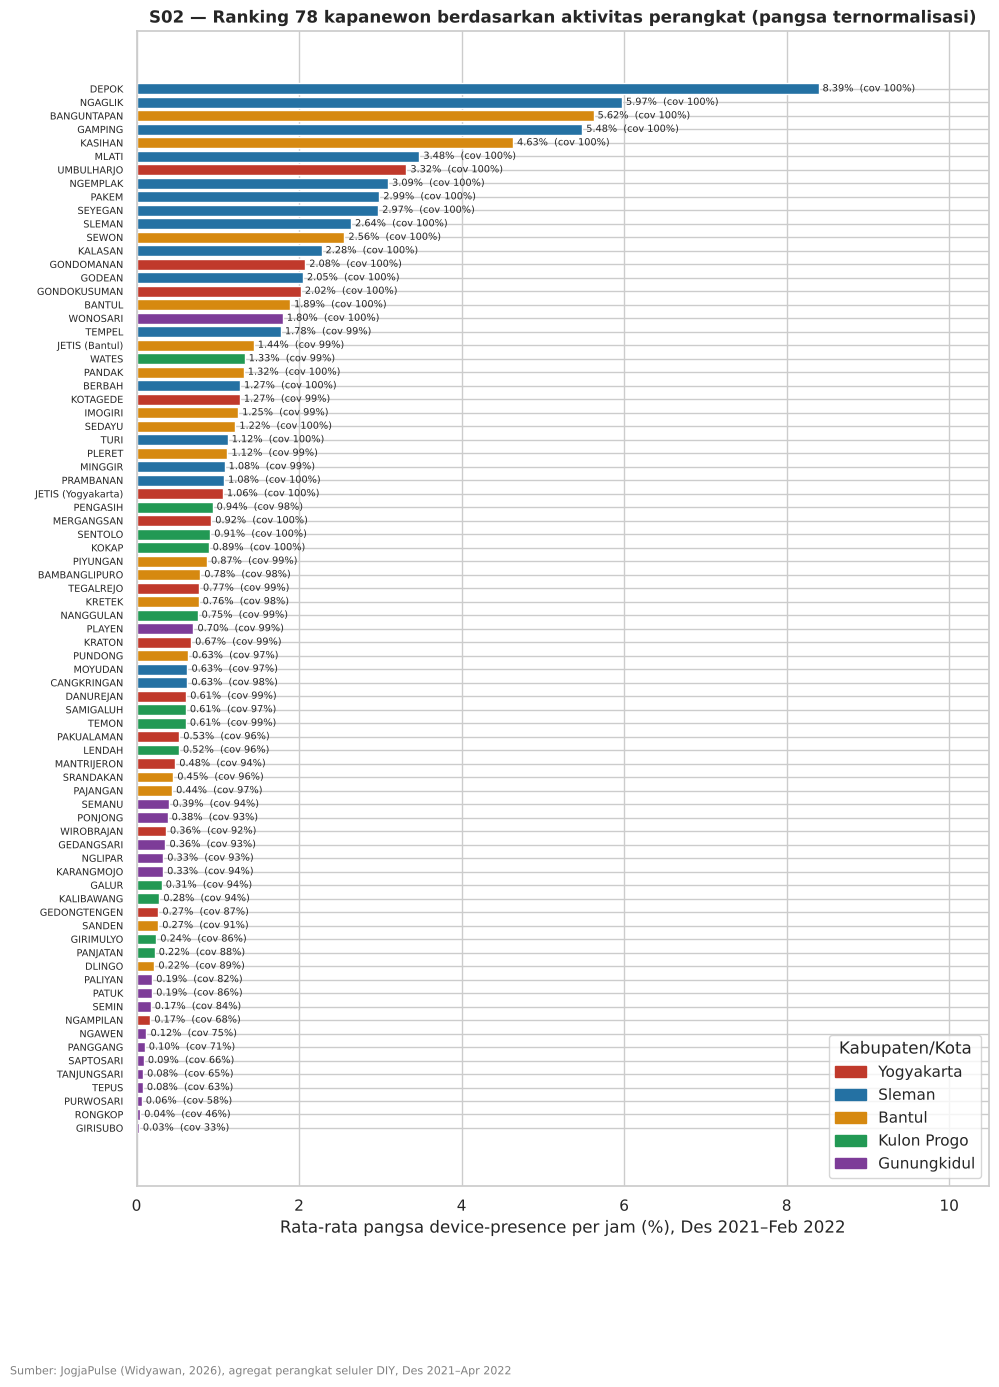

In [27]:
fig, ax = plt.subplots(figsize=(11, 15))
plot_df = ranking.iloc[::-1]
ax.barh(plot_df.label, plot_df.activity_share_pct, color=[KAB_COLORS[k] for k in plot_df.kab_kota])
for y, (val, cov) in enumerate(zip(plot_df.activity_share_pct, plot_df.coverage_pct)):
    ax.text(val + 0.05, y, f"{val:.2f}%  (cov {cov:.0f}%)", va="center", fontsize=7)
ax.set_xlabel("Rata-rata pangsa device-presence per jam (%), Des 2021–Feb 2022")
ax.set_ylabel("")
ax.set_title("S02 — Ranking 78 kapanewon berdasarkan aktivitas perangkat (pangsa ternormalisasi)")
ax.tick_params(axis="y", labelsize=7)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in KAB_COLORS.values()], labels=[k.title() for k in KAB_COLORS],
          title="Kabupaten/Kota", loc="lower right")
ax.set_xlim(0, ranking.activity_share_pct.max() * 1.25)
save_fig(fig, "S02_ranking_kapanewon")
plt.show()

**Cara membaca:** batang menunjukkan porsi rata-rata kapanewon dari total kehadiran perangkat DIY per jam. Angka *cov* adalah persen slot jam yang terpublikasi; kapanewon dengan cov rendah sering berisi < 5 perangkat sehingga pangsanya adalah batas bawah.

In [28]:
s01_top = ranking.set_index("label").activity_share_pct.head(5)
s01_bottom = ranking.set_index("label").activity_share_pct.tail(5).iloc[::-1]
add_insight("S01", "Kapanewon dengan jumlah perangkat teramati tertinggi dan terendah",
            "presence_kapanewon_hourly", "kapanewon_code, date, hour, n_maids",
            "Pangsa kehadiran per jam, rata-rata periode HQ", "mean_t(n_maids_k,t / Σ_k n_maids_k,t)",
            "Fig S02 / V1", "completed",
            f"Tertinggi: {fmt_list(s01_top)} (%). Terendah: {fmt_list(s01_bottom, fmt='{:.3f}')} (%).",
            "Aktivitas perangkat terpusat di kapanewon padat di Sleman (koridor kampus/utara) dan Kota Yogyakarta; terendah di kapanewon perdesaan Gunungkidul.",
            "Pangsa adalah batas bawah untuk kapanewon dengan banyak slot tersuppress; perangkat ≠ penduduk.")
add_insight("S02", "Ranking 78 kapanewon berdasarkan aktivitas perangkat",
            "presence_kapanewon_hourly; presence_cell500m_daily", "n_maids",
            "Ranking pangsa; validasi silang dengan agregasi grid (Spearman)", "rank(activity_share_pct)",
            "Fig S02", "completed",
            f"Tabel 78 kapanewon di outputs/tables/S02_ranking_78_kapanewon_HQ.csv. 5 teratas = {top5_share:.1f}% device-presence. "
            + (f"Spearman hourly vs grid = {rank_consistency['spearman_rho']:.3f}." if rank_consistency else ""),
            "Dua produk data independen memberi peringkat yang hampir sama, sehingga ranking cukup andal.",
            "Grid menghitung device-cell presence (tidak unik); ranking memakai periode HQ saja.")

### S03 — Konsentrasi perangkat: kawasan padat (proxy urban) vs jarang (proxy rural)
Kita membandingkan porsi aktivitas setiap kelas dengan porsi **penduduk** dan **luas**-nya. Jika porsi aktivitas > porsi penduduk, kelas tersebut "menarik" aktivitas lebih dari ukuran penduduknya.

In [29]:
class_summary = kap_hq.groupby("urban_rural").agg(
    n_kapanewon=("label", "size"), activity_share_pct=("activity_share_pct", "sum"),
    population=("pop_actual", "sum"), area_km2=("area_km2", "sum"), home_devices=("n_users", "sum"))
class_summary["population_share_pct"] = class_summary.population / class_summary.population.sum() * 100
class_summary["area_share_pct"] = class_summary.area_km2 / class_summary.area_km2.sum() * 100
class_summary["activity_per_pop_index"] = class_summary.activity_share_pct / class_summary.population_share_pct
class_summary["activity_per_area_index"] = class_summary.activity_share_pct / class_summary.area_share_pct
class_summary = class_summary.loc[URBAN_ORDER]
# Uji beda distribusi pangsa per kapanewon (Mann–Whitney) padat vs jarang
dense = kap_hq.loc[kap_hq.urban_rural == URBAN_ORDER[0], "activity_share_pct"]
sparse = kap_hq.loc[kap_hq.urban_rural == URBAN_ORDER[-1], "activity_share_pct"]
mw = stats.mannwhitneyu(dense, sparse, alternative="two-sided")
print(f"Mann–Whitney {URBAN_ORDER[0]} vs {URBAN_ORDER[-1]}: U = {mw.statistic:.0f}, p = {mw.pvalue:.2e}; "
      f"median {dense.median():.2f}% vs {sparse.median():.2f}%")
save_table(class_summary.reset_index(), "S03_urban_rural_proxy_summary")
class_summary

Mann–Whitney Padat (proxy urban) vs Jarang (proxy rural): U = 600, p = 1.70e-06; median 1.67% vs 0.26%
Tabel disimpan: outputs/tables/S03_urban_rural_proxy_summary.csv


,n_kapanewon,activity_share_pct,population,area_km2,home_devices,population_share_pct,area_share_pct,activity_per_pop_index,activity_per_area_index
urban_rural,,,,,,,,,
Padat (proxy urban),26,59.5981,"1,510,370.0000",382.0033,306178,40.9561,12.0566,1.4552,4.9432
Transisi,26,29.5325,"1,233,240.0000",914.6543,149511,33.4413,28.8678,0.8831,1.0230
Jarang (proxy rural),26,10.8694,"944,170.0000","1,871.7666",55730,25.6027,59.0756,0.4245,0.1840


In [30]:
add_insight("S03", "Perbandingan konsentrasi perangkat kawasan perkotaan dan perdesaan",
            "presence_kapanewon_hourly; home_maids_vs_population; batas kapanewon", "share_lb, pop_actual, area",
            f"Agregasi per kelas ({URBAN_SOURCE}); indeks aktivitas/penduduk & aktivitas/luas; Mann–Whitney",
            "activity_share_kelas / population_share_kelas", "V1 (peta) & tabel S03", "completed",
            "; ".join(f"{c}: aktivitas {r.activity_share_pct:.1f}% vs penduduk {r.population_share_pct:.1f}% vs luas {r.area_share_pct:.1f}%"
                      for c, r in class_summary.iterrows()) + f". Mann–Whitney p = {mw.pvalue:.1e}.",
            "Kawasan padat menampung porsi aktivitas jauh di atas porsi penduduknya; kawasan jarang jauh di bawah.",
            "Urban/rural adalah proxy kepadatan, bukan klasifikasi BPS; kawasan jarang lebih banyak tersuppress.")

### S04 — Apakah aktivitas terkumpul di pusat kota atau tersebar merata?
Tiga ukuran konsentrasi pada level **grid 500 m** (periode HQ):
1. **Koefisien Gini** dan **kurva Lorenz** — 0 berarti merata, 1 berarti semua aktivitas di satu sel.
2. **Porsi aktivitas di 1%, 5%, 10% sel teratas.**
3. **Profil jarak dari pusat Kota Yogyakarta** (centroid gabungan 14 kemantren): berapa porsi aktivitas yang berada dalam radius 5, 10, 20 km, dibandingkan porsi luas wilayah DIY dalam radius yang sama.

Metrik per sel: `cell_share_lb` = rata-rata harian pangsa sel terhadap total grid hari itu (hari tersuppress = 0).

> **Catatan artefak:** hasil utama mengeluarkan 25 sel yang memuat titik kisi koordinat 0,1° (lihat Section 3.9), karena aktivitasnya didominasi catatan lokasi berpresisi rendah. Nilai "semua sel" ditampilkan sebagai pembanding.

In [31]:
n_hq_days = cells_daily[cells_daily.hq].date.nunique()
cell_stats = cells_daily[cells_daily.hq].groupby("cell_id").agg(share_sum=("share", "sum"), days_published=("date", "size"),
                                                                 mean_maids_pub=("n_maids", "mean"))
cell_stats["cell_share_lb"] = cell_stats.share_sum / n_hq_days
cell_stats["days_published_pct"] = cell_stats.days_published / n_hq_days * 100
cell_stats = cells.set_index("cell_id").join(cell_stats, how="left").fillna({"cell_share_lb": 0, "days_published": 0, "days_published_pct": 0})
cell_stats_all = cell_stats.copy()                                   # semua sel (pembanding)
cell_stats = cell_stats[~cell_stats.lattice_0_1deg].copy()           # hasil utama: tanpa sel artefak kisi 0,1°
cell_stats["cx"], cell_stats["cy"] = cell_stats.x_min_utm + 250, cell_stats.y_min_utm + 250

cell_gini = gini(cell_stats.cell_share_lb)
cell_gini_all = gini(cell_stats_all.cell_share_lb)
sorted_share = np.sort(cell_stats.cell_share_lb.values)[::-1]
top_pct_share = {p: sorted_share[: max(1, int(len(sorted_share) * p / 100))].sum() / sorted_share.sum() * 100 for p in (1, 5, 10)}
print(f"Gini antar-sel tanpa sel kisi (n = {len(cell_stats):,}): {cell_gini:.3f} | semua sel (n = {len(cell_stats_all):,}): {cell_gini_all:.3f}")
print("Porsi aktivitas di sel teratas:", {f"top {k}%": f"{v:.1f}%" for k, v in top_pct_share.items()})
print("Gini antar-kapanewon:", round(gini(kap_hq.activity_share_pct), 3))

Gini antar-sel tanpa sel kisi (n = 5,690): 0.860 | semua sel (n = 5,715): 0.867
Porsi aktivitas di sel teratas: {'top 1%': '30.7%', 'top 5%': '63.4%', 'top 10%': '78.0%'}
Gini antar-kapanewon: 0.55


In [32]:
def union_geometry(gdf):
    return gdf.union_all() if hasattr(gdf, "union_all") else gdf.unary_union


if HAS_BOUNDARY:
    city_center = union_geometry(gdf_kap_utm[gdf_kap_utm.kab_kota == "YOGYAKARTA"]).centroid
    diy_polygon = union_geometry(gdf_kap_utm)
    cell_stats["dist_center_km"] = np.hypot(cell_stats.cx - city_center.x, cell_stats.cy - city_center.y) / 1000
    kap_hq["dist_center_km"] = np.hypot(kap_hq.cx_utm - city_center.x, kap_hq.cy_utm - city_center.y) / 1000
    rings = [2.5, 5, 10, 15, 20, 30, 40, 60]
    ring_rows = []
    for r in rings:
        area_share = diy_polygon.intersection(city_center.buffer(r * 1000)).area / diy_polygon.area * 100
        act_share = cell_stats.loc[cell_stats.dist_center_km <= r, "cell_share_lb"].sum() / cell_stats.cell_share_lb.sum() * 100
        pop_share = kap_hq.loc[kap_hq.dist_center_km <= r, "pop_actual"].sum() / kap_hq.pop_actual.sum() * 100
        ring_rows.append({"radius_km": r, "activity_share_pct": act_share, "area_share_pct": area_share,
                          "population_share_pct_(centroid_kapanewon)": pop_share, "concentration_ratio": act_share / area_share})
    ring_table = pd.DataFrame(ring_rows)
    dist_corr = corr_report(cell_stats.dist_center_km, np.log10(cell_stats.cell_share_lb.replace(0, np.nan)), "jarak vs log share sel")
    print(f"Spearman jarak ke pusat vs log pangsa sel: rho = {dist_corr['spearman_rho']:.3f} (n = {dist_corr['n']:,})")
    save_table(ring_table, "S04_distance_rings")
    display(ring_table)

Spearman jarak ke pusat vs log pangsa sel: rho = -0.493 (n = 5,673)
Tabel disimpan: outputs/tables/S04_distance_rings.csv


,radius_km,activity_share_pct,area_share_pct,population_share_pct_(centroid_kapanewon),concentration_ratio
0,2.5000,12.9102,0.6187,7.0159,20.8662
1,5.0000,31.6904,2.4748,13.3015,12.8050
2,10.0000,60.4138,9.8994,33.2371,6.1028
3,15.0000,78.8005,22.1738,55.5760,3.5538
4,20.0000,88.3442,36.7203,67.3720,2.4059
5,30.0000,96.0908,66.1461,83.8298,1.4527
6,40.0000,99.4198,83.6263,94.6190,1.1889
7,60.0000,99.9887,99.0348,100.0000,1.0096


Gambar disimpan: outputs/figures/S04_concentration.png


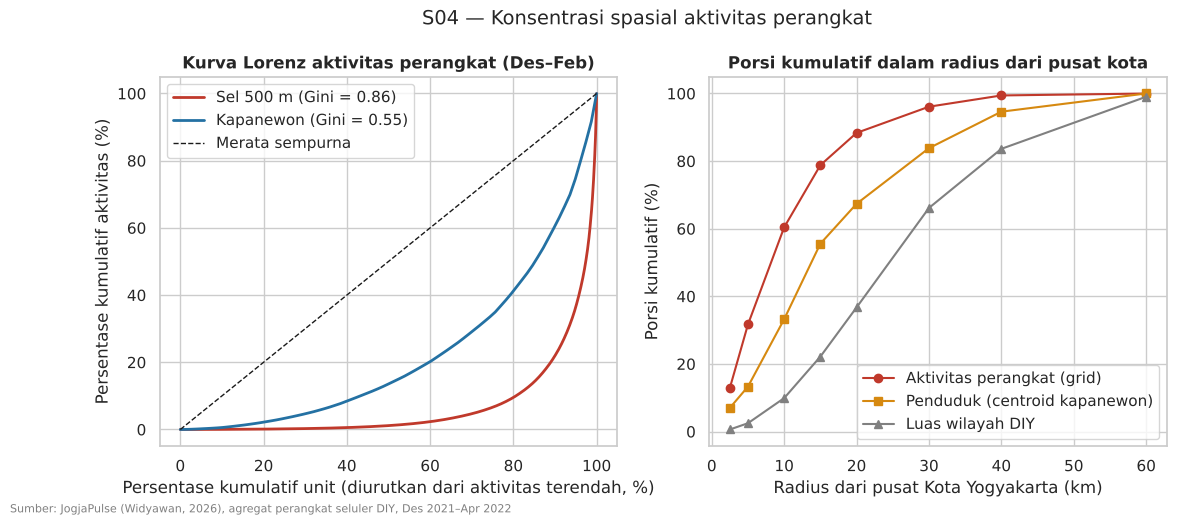

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
lorenz_y = np.concatenate([[0], np.cumsum(np.sort(cell_stats.cell_share_lb.values)) / cell_stats.cell_share_lb.sum()])
lorenz_x = np.linspace(0, 1, len(lorenz_y))
axes[0].plot(lorenz_x * 100, lorenz_y * 100, color="#c0392b", lw=2, label=f"Sel 500 m (Gini = {cell_gini:.2f})")
k_sorted = np.sort(kap_hq.activity_share_pct.values)
axes[0].plot(np.linspace(0, 100, len(k_sorted) + 1), np.concatenate([[0], np.cumsum(k_sorted) / k_sorted.sum() * 100]),
             color="#2471a3", lw=2, label=f"Kapanewon (Gini = {gini(k_sorted):.2f})")
axes[0].plot([0, 100], [0, 100], "k--", lw=1, label="Merata sempurna")
axes[0].set(xlabel="Persentase kumulatif unit (diurutkan dari aktivitas terendah, %)", ylabel="Persentase kumulatif aktivitas (%)",
            title="Kurva Lorenz aktivitas perangkat (Des–Feb)")
axes[0].legend()
if HAS_BOUNDARY:
    axes[1].plot(ring_table.radius_km, ring_table.activity_share_pct, "o-", color="#c0392b", label="Aktivitas perangkat (grid)")
    axes[1].plot(ring_table.radius_km, ring_table["population_share_pct_(centroid_kapanewon)"], "s-", color="#d68910", label="Penduduk (centroid kapanewon)")
    axes[1].plot(ring_table.radius_km, ring_table.area_share_pct, "^-", color="gray", label="Luas wilayah DIY")
    axes[1].set(xlabel="Radius dari pusat Kota Yogyakarta (km)", ylabel="Porsi kumulatif (%)",
                title="Porsi kumulatif dalam radius dari pusat kota")
    axes[1].legend()
fig.suptitle("S04 — Konsentrasi spasial aktivitas perangkat", y=1.02)
save_fig(fig, "S04_concentration")
plt.show()

In [34]:
s04_text = (f"Gini sel = {cell_gini:.2f}; top 1% sel = {top_pct_share[1]:.1f}%, top 10% sel = {top_pct_share[10]:.1f}% aktivitas. ")
if HAS_BOUNDARY:
    r10 = ring_table.set_index("radius_km").loc[10]
    s04_text += (f"Radius 10 km dari pusat kota: {r10.activity_share_pct:.1f}% aktivitas, {r10['population_share_pct_(centroid_kapanewon)']:.1f}% penduduk, "
                 f"hanya {r10.area_share_pct:.1f}% luas. Spearman jarak vs log pangsa sel = {dist_corr['spearman_rho']:.2f}.")
add_insight("S04", "Apakah konsentrasi perangkat terkumpul di pusat kota atau tersebar merata?",
            "presence_cell500m_daily; batas kapanewon", "cell_id, date, n_maids, x/y_min_utm",
            "Gini, kurva Lorenz, porsi top-k% sel, profil radius dari pusat kota", "Gini; Σshare(dist≤r)/Σshare",
            "Fig S04, V1", "completed", s04_text,
            "Aktivitas sangat terkonsentrasi di aglomerasi pusat kota dan menurun tajam dengan jarak; jauh lebih terkonsentrasi daripada luas wilayah, bahkan lebih terkonsentrasi daripada penduduk.",
            "Sel yang tidak pernah terpublikasi tidak masuk perhitungan (Gini cenderung lebih rendah dari aslinya); pusat kota = centroid geometris Kota Yogyakarta.")

### S05 — Hotspot grid 500 m (Getis-Ord Gi*)
**Apa itu Getis-Ord Gi\*?** Statistik yang menilai apakah sebuah sel **dan tetangganya** bersama-sama memiliki nilai tinggi (hotspot) atau rendah (coldspot) dibanding rata-rata seluruh wilayah.

**Mengapa dipakai?** Sel bernilai tinggi yang terisolasi bisa kebetulan; Gi\* mencari *klaster* nilai tinggi yang signifikan secara statistik.

**Cara kerja sederhana:** untuk setiap sel, jumlahkan nilai sel itu + 8 tetangganya (jendela 3×3), lalu bandingkan dengan jumlah yang diharapkan jika nilai tersebar acak. Hasilnya skor-z: z > 1,96 → hotspot (tingkat kepercayaan 95%), z > 2,58 → hotspot (99%).

$$G_i^* = \frac{\sum_j w_{ij}x_j - \bar{X}\sum_j w_{ij}}{S\sqrt{\frac{n\sum_j w_{ij}^2 - (\sum_j w_{ij})^2}{n-1}}}$$

**Keterbatasan:** banyak uji sekaligus (ribuan sel) memperbesar peluang positif palsu; sel yang tidak pernah terpublikasi dianggap di luar wilayah studi.

In [35]:
def getis_ord_gi_star(df, value_col, i_col="gi", j_col="gj"):
    """Gi* dengan bobot biner jendela 3×3 (queen contiguity + sel itu sendiri)."""
    x = df[value_col].to_numpy(dtype=float)
    n = len(x)
    lookup = pd.Series(np.arange(n), index=pd.MultiIndex.from_arrays([df[i_col], df[j_col]]))
    neighbor_sum = np.zeros(n)
    neighbor_count = np.zeros(n)
    for di in (-1, 0, 1):
        for dj in (-1, 0, 1):
            keys = pd.MultiIndex.from_arrays([df[i_col] + di, df[j_col] + dj])
            idx = lookup.reindex(keys).to_numpy()
            ok = ~np.isnan(idx)
            neighbor_sum[ok] += x[idx[ok].astype(int)]
            neighbor_count[ok] += 1
    x_bar = x.mean()
    s = np.sqrt((x ** 2).mean() - x_bar ** 2)
    w_sum = neighbor_count                    # bobot biner -> Σw = jumlah tetangga, Σw² = Σw
    denominator = s * np.sqrt((n * w_sum - w_sum ** 2) / (n - 1))
    return (neighbor_sum - x_bar * w_sum) / denominator


cell_stats["gi_z"] = getis_ord_gi_star(cell_stats.reset_index(), "cell_share_lb")
cell_stats["hotspot_class"] = pd.cut(cell_stats.gi_z, [-np.inf, -2.576, -1.96, 1.96, 2.576, np.inf],
                                     labels=["Coldspot 99%", "Coldspot 95%", "Tidak signifikan", "Hotspot 95%", "Hotspot 99%"]).astype(str)
print(cell_stats.hotspot_class.value_counts().to_string())
hot_cells = cell_stats[cell_stats.hotspot_class == "Hotspot 99%"]
# Pembanding: Gi* jika sel artefak kisi 0,1° TIDAK dikeluarkan
gi_all = pd.Series(getis_ord_gi_star(cell_stats_all.reset_index(), "cell_share_lb"), index=cell_stats_all.index)
hot_all = gi_all[gi_all > 2.576]
print(f"Pembanding (semua sel): {len(hot_all)} sel hotspot 99%, {int(cell_stats_all.loc[hot_all.index, 'lattice_0_1deg'].sum())} di antaranya sel kisi; "
      f"overlap dengan hasil utama: {len(set(hot_all.index) & set(hot_cells.index))} sel")
print(f"Sel hotspot 99%: {len(hot_cells)} ({len(hot_cells) / len(cell_stats):.1%} sel) memuat "
      f"{hot_cells.cell_share_lb.sum() / cell_stats.cell_share_lb.sum():.1%} aktivitas grid")
if HAS_BOUNDARY:
    hot_by_kap = (hot_cells.groupby("kapanewon_code").size().rename("hotspot_cells").to_frame()
                  .join(LABEL).join(KAB_OF).sort_values("hotspot_cells", ascending=False))
    display(hot_by_kap.head(15))
top_cells = (cell_stats.sort_values("cell_share_lb", ascending=False).head(15)
             [["kapanewon_code", "centroid_lat", "centroid_lon", "cell_share_lb", "mean_maids_pub", "days_published_pct", "gi_z"]])
top_cells["kapanewon"] = top_cells.kapanewon_code.map(LABEL)
top_cells["cell_share_lb_pct"] = top_cells.cell_share_lb * 100
save_table(cell_stats.reset_index()[["cell_id", "kapanewon_code", "centroid_lat", "centroid_lon", "cell_share_lb", "days_published_pct",
                                     "mean_maids_pub", "gi_z", "hotspot_class"]], "S05_cell_hotspots_HQ")
top_cells

hotspot_class
Tidak signifikan    5261
Hotspot 99%          317
Hotspot 95%          112
Pembanding (semua sel): 286 sel hotspot 99%, 6 di antaranya sel kisi; overlap dengan hasil utama: 253 sel
Sel hotspot 99%: 317 (5.6% sel) memuat 44.4% aktivitas grid


,hotspot_cells,label,kab_kota
kapanewon_code,,,
34.04.07,63,DEPOK,SLEMAN
34.04.12,37,NGAGLIK,SLEMAN
34.02.12,26,BANGUNTAPAN,BANTUL
34.02.16,22,KASIHAN,BANTUL
34.71.13,20,UMBULHARJO,YOGYAKARTA
34.04.06,16,MLATI,SLEMAN
34.71.03,16,GONDOKUSUMAN,YOGYAKARTA
34.04.01,11,GAMPING,SLEMAN
34.04.13,11,SLEMAN,SLEMAN


Tabel disimpan: outputs/tables/S05_cell_hotspots_HQ.csv


,kapanewon_code,centroid_lat,centroid_lon,cell_share_lb,mean_maids_pub,days_published_pct,gi_z,kapanewon,cell_share_lb_pct
cell_id,,,,,,,,,
E859_N18274,34.71.10,-7.8046,110.3628,0.0190,"1,032.7222",100.0000,15.4226,GONDOMANAN,1.8972
E865_N18299,34.04.12,-7.6916,110.3902,0.0093,873.0964,92.2222,4.8969,NGAGLIK,0.9344
E857_N18294,34.04.13,-7.7141,110.3539,0.0087,532.4889,100.0000,6.7725,SLEMAN,0.8675
E865_N18288,34.04.12,-7.7413,110.3901,0.0077,717.2000,100.0000,5.7179,NGAGLIK,0.7672
E865_N18274,34.71.13,-7.8046,110.3900,0.0073,636.4000,100.0000,9.1998,UMBULHARJO,0.7256
E870_N18274,34.02.12,-7.8047,110.4127,0.0068,631.1444,100.0000,5.4347,BANGUNTAPAN,0.6778
E876_N18284,34.04.07,-7.7595,110.4400,0.0065,611.9556,100.0000,4.5027,DEPOK,0.6528
E866_N18269,34.71.14,-7.8273,110.3945,0.0065,598.5444,100.0000,8.8765,KOTAGEDE,0.6474
E865_N18292,34.04.12,-7.7232,110.3902,0.0062,580.3000,100.0000,3.6011,NGAGLIK,0.6181


In [36]:
hot_kap_text = fmt_list(hot_by_kap.set_index("label").hotspot_cells, n=6, fmt="{:.0f}") if HAS_BOUNDARY else "n/a"
add_insight("S05", "Grid 500 meter yang menjadi hotspot aktivitas",
            "presence_cell500m_daily", "cell_id, n_maids, x/y_min_utm",
            "Getis-Ord Gi* (jendela 3×3) pada rata-rata pangsa harian sel (HQ)", "Gi* z-score; hotspot z>2,576",
            "V1 (layer hotspot)", "completed",
            f"{len(hot_cells)} sel hotspot 99% ({hot_cells.cell_share_lb.sum() / cell_stats.cell_share_lb.sum():.1%} aktivitas grid). "
            f"Kapanewon dengan sel hotspot terbanyak: {hot_kap_text}. Sel tunggal tertinggi berada di {top_cells.kapanewon.iloc[0]} "
            f"({top_cells.cell_share_lb_pct.iloc[0]:.2f}% aktivitas grid harian).",
            "Hotspot membentuk satu klaster besar yang menyatu dari inti kota ke utara sepanjang koridor Depok–Ngaglik–Sleman–Tempel serta ke tenggara (Banguntapan, Kotagede) dan barat daya (Kasihan); pola aktivitas DIY bersifat monosentris dengan koridor utara yang kuat. Sel tunggal terkuat berada di Gondomanan (kawasan Malioboro–Titik Nol).",
            "Uji berganda (ribuan sel) tanpa koreksi; 25 sel artefak kisi 0,1° dikeluarkan (jika tidak dikeluarkan, 6 sel artefak ikut menjadi hotspot); nilai sel adalah device-presence harian.")

### S06 — Apakah pusat aktivitas berbeda dengan pusat permukiman?
Kita tidak punya data permukiman per bangunan, sehingga "pusat permukiman" diwakili oleh tiga indikator yang tersedia: **penduduk resmi** (`pop_actual`), **perangkat berumah** (`n_users`), dan **kehadiran malam** (pangsa 00.00–04.59). "Pusat aktivitas" diwakili **kehadiran siang hari kerja** (08.00–17.59).

1. **Pusat berbobot (weighted centroid)**: rata-rata koordinat centroid kapanewon yang dibobot oleh masing-masing indikator. Pergeseran jarak antar-pusat menunjukkan apakah aktivitas siang "tertarik" ke arah tertentu.
2. **Rasio siang/malam** per kapanewon: > 1 berarti kapanewon lebih ramai (relatif terhadap DIY) pada siang hari dibanding malam hari.

In [37]:
if HAS_BOUNDARY:
    weights = {
        "Aktivitas siang hari kerja (08–17)": kap_hq.day_share_pct,
        "Kehadiran malam (00–04)": kap_hq.night_share_pct,
        "Penduduk resmi": kap_hq.pop_actual,
        "Perangkat berumah (n_users)": kap_hq.n_users,
        "Luas wilayah (pusat geometris)": kap_hq.area_km2,
    }
    centers = pd.DataFrame({name: {"x": np.average(kap_hq.cx_utm, weights=w), "y": np.average(kap_hq.cy_utm, weights=w)}
                            for name, w in weights.items()}).T
    ref = centers.loc["Penduduk resmi"]
    centers["jarak_ke_pusat_penduduk_km"] = np.hypot(centers.x - ref.x, centers.y - ref.y) / 1000
    centers["jarak_ke_pusat_kota_km"] = np.hypot(centers.x - city_center.x, centers.y - city_center.y) / 1000
    dx, dy = centers.loc["Aktivitas siang hari kerja (08–17)", ["x", "y"]] - centers.loc["Kehadiran malam (00–04)", ["x", "y"]]
    bearing = (np.degrees(np.arctan2(dx, dy)) + 360) % 360
    print(f"Pusat siang bergeser {np.hypot(dx, dy) / 1000:.2f} km dari pusat malam, arah {bearing:.0f}° (0° = utara)")
    display(centers.round(2))

kap_hq["day_night_ratio"] = kap_hq.day_share_pct / kap_hq.night_share_pct
kap_hq["night_coverage_pct"] = panel_hq[panel_hq.hour.between(0, 4)].groupby("kapanewon_code").published.mean() * 100
# Hanya kapanewon dengan cakupan malam ≥ 90% yang dinilai, karena pangsa malam yang tersuppress adalah batas bawah
# (rasio siang/malam kapanewon dengan banyak slot malam kosong akan terlalu tinggi secara artifisial)
RELIABLE_NIGHT = kap_hq.night_coverage_pct >= 90
day_night = (kap_hq[RELIABLE_NIGHT].sort_values("day_night_ratio", ascending=False)
             [["label", "kab_kota", "urban_rural", "day_share_pct", "night_share_pct", "day_night_ratio", "night_coverage_pct"]])
print(f"Kapanewon dengan cakupan malam ≥ 90%: {RELIABLE_NIGHT.sum()} dari 78 (yang lain dikeluarkan dari ranking rasio)")
display(day_night.head(8))
display(day_night.tail(8))

Pusat siang bergeser 0.89 km dari pusat malam, arah 173° (0° = utara)


,x,y,jarak_ke_pusat_penduduk_km,jarak_ke_pusat_kota_km
Aktivitas siang hari kerja (08–17),"430,376.1800","9,137,930.9600",5.6200,0.8400
Kehadiran malam (00–04),"430,274.7800","9,138,816.6700",6.4400,1.6000
Penduduk resmi,"433,213.0600","9,133,081.9200",0.0000,4.8400
Perangkat berumah (n_users),"430,508.3200","9,138,352.1300",5.9200,1.0800
Luas wilayah (pusat geometris),"438,797.5100","9,127,362.9000",7.9900,12.6900


Kapanewon dengan cakupan malam ≥ 90%: 47 dari 78 (yang lain dikeluarkan dari ranking rasio)


,label,kab_kota,urban_rural,day_share_pct,night_share_pct,day_night_ratio,night_coverage_pct
kapanewon_code,,,,,,,
34.03.03,PLAYEN,GUNUNGKIDUL,Jarang (proxy rural),0.7917,0.4876,1.6238,92.8889
34.03.01,WONOSARI,GUNUNGKIDUL,Transisi,2.0128,1.4694,1.3698,98.2222
34.01.10,NANGGULAN,KULON PROGO,Jarang (proxy rural),0.7563,0.5676,1.3324,96.6667
34.01.01,TEMON,KULON PROGO,Jarang (proxy rural),0.6380,0.4850,1.3155,94.4444
34.01.02,WATES,KULON PROGO,Transisi,1.5010,1.1572,1.2971,94.4444
34.01.08,KOKAP,KULON PROGO,Jarang (proxy rural),0.8909,0.6965,1.2792,98.0000
34.02.06,PANDAK,BANTUL,Transisi,1.3237,1.0473,1.2640,100.0000
34.04.09,PRAMBANAN,SLEMAN,Transisi,1.1189,0.8892,1.2583,98.6667


,label,kab_kota,urban_rural,day_share_pct,night_share_pct,day_night_ratio,night_coverage_pct
kapanewon_code,,,,,,,
34.04.12,NGAGLIK,SLEMAN,Padat (proxy urban),5.8665,6.3695,0.9210,100.0000
34.71.01,TEGALREJO,YOGYAKARTA,Padat (proxy urban),0.7695,0.8441,0.9116,96.8889
34.71.13,UMBULHARJO,YOGYAKARTA,Padat (proxy urban),3.2406,3.6165,0.8960,100.0000
34.04.11,NGEMPLAK,SLEMAN,Transisi,2.9846,3.3998,0.8779,99.7778
34.71.09,KRATON,YOGYAKARTA,Padat (proxy urban),0.6575,0.7498,0.8770,96.2222
34.04.07,DEPOK,SLEMAN,Padat (proxy urban),8.1090,9.6724,0.8384,100.0000
34.04.13,SLEMAN,SLEMAN,Transisi,2.3602,3.3404,0.7066,100.0000
34.71.10,GONDOMANAN,YOGYAKARTA,Padat (proxy urban),1.4195,4.1497,0.3421,100.0000


In [38]:
s06_text = ""
if HAS_BOUNDARY:
    s06_text = (f"Pusat berbobot aktivitas siang berjarak {centers.loc['Aktivitas siang hari kerja (08–17)', 'jarak_ke_pusat_penduduk_km']:.1f} km dari pusat penduduk "
                f"dan {np.hypot(dx, dy) / 1000:.1f} km dari pusat kehadiran malam (arah {bearing:.0f}°). ")
s06_text += (f"Rasio siang/malam tertinggi: {fmt_list(day_night.set_index('label').day_night_ratio, 4)}; "
             f"terendah: {fmt_list(day_night.set_index('label').day_night_ratio.iloc[::-1], 4)}.")
add_insight("S06", "Apakah pusat aktivitas perangkat berbeda dengan pusat permukiman?",
            "presence_kapanewon_hourly; home_maids_vs_population; batas kapanewon", "share_lb (siang/malam), pop_actual, n_users",
            "Weighted centroid; rasio pangsa siang/malam", "Σw·xy/Σw; day_share/night_share",
            "V1, V2", "completed", s06_text,
            "Ya, berbeda: pusat aktivitas perangkat (siang maupun malam) berada ±1 km dari pusat Kota Yogyakarta, sedangkan pusat penduduk resmi ±5–6 km ke arah tenggara (tertarik oleh Bantul & Gunungkidul). Perbedaan siang vs malam kecil (<1 km). Secara relatif, aktivitas siang lebih menyebar ke ibu kota kabupaten pinggiran (Wonosari, Wates, Playen), sedangkan kehadiran malam lebih terkonsentrasi di inti kota & koridor kampus (Depok, Ngaglik, Gondomanan).",
            "Tidak ada data permukiman per bangunan; rasio siang/malam hanya untuk 47 kapanewon dengan cakupan malam ≥ 90%; sampel perangkat malam cenderung lebih urban (perilaku penggunaan aplikasi), sehingga rasio < 1 tidak otomatis berarti kawasan permukiman.")

### S07 — Lokasi wisata vs nonwisata
Pertanyaan ini membutuhkan **koordinat lokasi wisata** (lihat Section 0.3). Jika `tourism_poi_diy.csv` tersedia, sel grid yang berjarak ≤ 500 m dari POI wisata diberi label "wisata" dan dibandingkan dengan sel lain menggunakan uji Mann–Whitney.

In [39]:
TOURISM_BUFFER_M = 500
if HAS_TOURISM:
    poi = pd.read_csv(TOURISM_POI_FILE)
    required = {"name", "category", "lat", "lon"}
    if not required.issubset(poi.columns):
        raise ValueError(f"tourism_poi_diy.csv harus punya kolom {required}")
    gdf_poi = gpd.GeoDataFrame(poi, geometry=gpd.points_from_xy(poi.lon, poi.lat), crs=CRS_WGS84).to_crs(CRS_UTM)
    cell_points = gpd.GeoDataFrame(cell_stats[["cx", "cy"]], geometry=gpd.points_from_xy(cell_stats.cx, cell_stats.cy), crs=CRS_UTM)
    near = gpd.sjoin_nearest(cell_points, gdf_poi[["geometry"]], how="left", distance_col="dist_poi_m")
    cell_stats["dist_poi_m"] = near[~near.index.duplicated()].dist_poi_m
    cell_stats["is_tourism_cell"] = cell_stats.dist_poi_m <= TOURISM_BUFFER_M
    tour_cmp = cell_stats.groupby("is_tourism_cell").cell_share_lb.describe()
    mw_tour = stats.mannwhitneyu(cell_stats.loc[cell_stats.is_tourism_cell, "cell_share_lb"],
                                 cell_stats.loc[~cell_stats.is_tourism_cell, "cell_share_lb"], alternative="greater")
    display(tour_cmp)
    add_insight("S07", "Apakah lokasi wisata mempunyai konsentrasi perangkat lebih tinggi dibandingkan nonwisata?",
                "presence_cell500m_daily; tourism_poi_diy.csv", "cell_share_lb, POI", "Buffer 500 m + Mann–Whitney (one-sided)",
                "median share wisata vs nonwisata", "V1", "completed",
                f"{int(cell_stats.is_tourism_cell.sum())} sel wisata; median {tour_cmp.loc[True, '50%']:.2e} vs {tour_cmp.loc[False, '50%']:.2e}; p = {mw_tour.pvalue:.1e}",
                "Lihat hasil uji di atas.", "Hasil bergantung kelengkapan daftar POI dan radius buffer.")
else:
    print("Data POI wisata belum tersedia -> S07 ditandai 'requires external data'.")
    add_insight("S07", "Apakah lokasi wisata mempunyai konsentrasi perangkat lebih tinggi dibandingkan nonwisata?",
                "presence_cell500m_daily + (butuh) tourism_poi_diy.csv", "cell_id, n_maids, koordinat POI",
                "Buffer 500 m sekitar POI + Mann–Whitney", "median cell_share wisata vs nonwisata", "V1",
                "requires external data", "Belum dihitung: koordinat lokasi wisata tidak tersedia di dataset.",
                "Kode sudah siap; tambahkan data/external/tourism_poi_diy.csv (OSM/Dinas Pariwisata DIY) lalu jalankan ulang.",
                "Tidak boleh memakai koordinat wisata karangan.")

Data POI wisata belum tersedia -> S07 ditandai 'requires external data'.


### S08 & S09 — Aktivitas tinggi vs penduduk rendah, dan sebaliknya
**Indeks aktivitas–penduduk (Activity-to-Population Index, API):**

$$API_k = \frac{\text{pangsa aktivitas siang hari kerja}_k}{\text{pangsa penduduk}_k}$$

API = 1 berarti porsi aktivitas siang sama dengan porsi penduduk. API > 1 → wilayah "menarik" aktivitas (pusat kegiatan); API < 1 → aktivitas lebih rendah dari ukuran penduduknya (wilayah tinggal, atau sampel perangkat kurang mencakup wilayah tersebut).

In [40]:
kap_hq["pop_share_pct"] = kap_hq.pop_actual / kap_hq.pop_actual.sum() * 100
kap_hq["api"] = kap_hq.day_share_pct / kap_hq.pop_share_pct
pop_median = kap_hq.pop_actual.median()
s08 = kap_hq[kap_hq.pop_actual < pop_median].sort_values("api", ascending=False)
s09 = kap_hq[kap_hq.pop_actual >= pop_median].sort_values("api")
cols = ["label", "kab_kota", "urban_rural", "pop_actual", "pop_share_pct", "day_share_pct", "api", "coverage_pct"]
print(f"Median penduduk kapanewon: {pop_median:,.0f} jiwa")
print("S08 — penduduk di bawah median, API tertinggi:")
display(s08[cols].head(8))
print("S09 — penduduk di atas median, API terendah:")
display(s09[cols].head(8))
save_table(kap_hq.reset_index()[["kapanewon_code"] + cols], "S08_S09_activity_population_index")

Median penduduk kapanewon: 37,975 jiwa
S08 — penduduk di bawah median, API tertinggi:


,label,kab_kota,urban_rural,pop_actual,pop_share_pct,day_share_pct,api,coverage_pct
kapanewon_code,,,,,,,,
34.71.10,GONDOMANAN,YOGYAKARTA,Padat (proxy urban),"12,850.0000",0.3484,1.4195,4.0739,100.0000
34.04.16,PAKEM,SLEMAN,Jarang (proxy rural),"37,580.0000",1.0190,2.9503,2.8952,99.9537
34.71.11,PAKUALAMAN,YOGYAKARTA,Padat (proxy urban),"9,190.0000",0.2492,0.5702,2.2881,96.0185
34.71.03,GONDOKUSUMAN,YOGYAKARTA,Padat (proxy urban),"37,070.0000",1.0052,2.1814,2.1701,100.0000
34.71.02,JETIS (Yogyakarta),YOGYAKARTA,Padat (proxy urban),"23,480.0000",0.6367,1.1580,1.8187,99.9537
34.71.14,KOTAGEDE,YOGYAKARTA,Padat (proxy urban),"33,460.0000",0.9073,1.2799,1.4107,99.1204
34.71.09,KRATON,YOGYAKARTA,Padat (proxy urban),"18,020.0000",0.4886,0.6575,1.3457,99.1204
34.71.04,DANUREJAN,YOGYAKARTA,Padat (proxy urban),"18,780.0000",0.5092,0.6387,1.2543,98.7037


S09 — penduduk di atas median, API terendah:


,label,kab_kota,urban_rural,pop_actual,pop_share_pct,day_share_pct,api,coverage_pct
kapanewon_code,,,,,,,,
34.03.15,SAPTOSARI,GUNUNGKIDUL,Jarang (proxy rural),"38,370.0000",1.0405,0.1175,0.1129,66.3889
34.03.12,SEMIN,GUNUNGKIDUL,Jarang (proxy rural),"55,450.0000",1.5036,0.2067,0.1375,84.4907
34.02.11,DLINGO,BANTUL,Jarang (proxy rural),"39,130.0000",1.0611,0.2257,0.2127,88.8889
34.01.03,PANJATAN,KULON PROGO,Transisi,"38,390.0000",1.0410,0.2321,0.2229,88.2407
34.03.09,KARANGMOJO,GUNUNGKIDUL,Jarang (proxy rural),"55,580.0000",1.5071,0.3532,0.2344,94.3056
34.03.08,SEMANU,GUNUNGKIDUL,Jarang (proxy rural),"58,320.0000",1.5814,0.4298,0.2718,94.1204
34.03.10,PONJONG,GUNUNGKIDUL,Jarang (proxy rural),"54,570.0000",1.4798,0.4235,0.2862,93.0093
34.03.14,GEDANGSARI,GUNUNGKIDUL,Jarang (proxy rural),"38,440.0000",1.0424,0.3581,0.3436,93.1481


Tabel disimpan: outputs/tables/S08_S09_activity_population_index.csv


In [41]:
add_insight("S08", "Wilayah dengan aktivitas tinggi tetapi jumlah penduduk relatif rendah",
            "presence_kapanewon_hourly; home_maids_vs_population", "share_lb siang, pop_actual",
            "Activity-to-Population Index pada kapanewon berpenduduk < median", "day_share / pop_share", "V1, V4", "completed",
            f"API tertinggi: {fmt_list(s08.set_index('label').api, 5)}.",
            "Kemantren inti Kota Yogyakarta (Gondomanan, Pakualaman, Gondokusuman, Jetis) menampung aktivitas siang 2–4× porsi penduduknya, konsisten dengan fungsi pusat perdagangan, jasa, pendidikan, dan wisata. Pakem (Sleman) juga tinggi, tetapi ±48% aktivitas grid Pakem berasal dari sel artefak kisi 0,1°, sehingga nilainya terdongkrak.",
            "API dipengaruhi cakupan sampel (perangkat ≠ penduduk); penduduk = data BPS tahun tidak disebutkan.")
add_insight("S09", "Wilayah dengan aktivitas rendah meskipun jumlah penduduk tinggi",
            "presence_kapanewon_hourly; home_maids_vs_population", "share_lb siang, pop_actual",
            "Activity-to-Population Index pada kapanewon berpenduduk ≥ median", "day_share / pop_share", "V1, V4", "completed",
            f"API terendah: {fmt_list(s09.set_index('label').api, 5)}.",
            "Kapanewon berpenduduk besar di Gunungkidul (Saptosari, Semin, Karangmojo, Semanu, Ponjong), Dlingo (Bantul), dan Panjatan (Kulon Progo) hanya memiliki 10–35% aktivitas yang 'seharusnya' menurut porsi penduduknya.",
            "API rendah bisa berarti sedikit aktivitas ATAU sampel perangkat kurang mencakup wilayah tersebut (lihat Section 6).")

### S10 — Persebaran aktivitas perangkat di seluruh DIY (Visualisasi Utama 1)
Visualisasi utama pertama menggabungkan beberapa pertanyaan (S01, S03–S06, S08–S10, P04): versi statis enam panel untuk laporan, dan versi **interaktif Folium** dengan layer yang dapat dinyalakan/dimatikan.

Gambar disimpan: outputs/figures/V1_spatial_activity_map_static.png


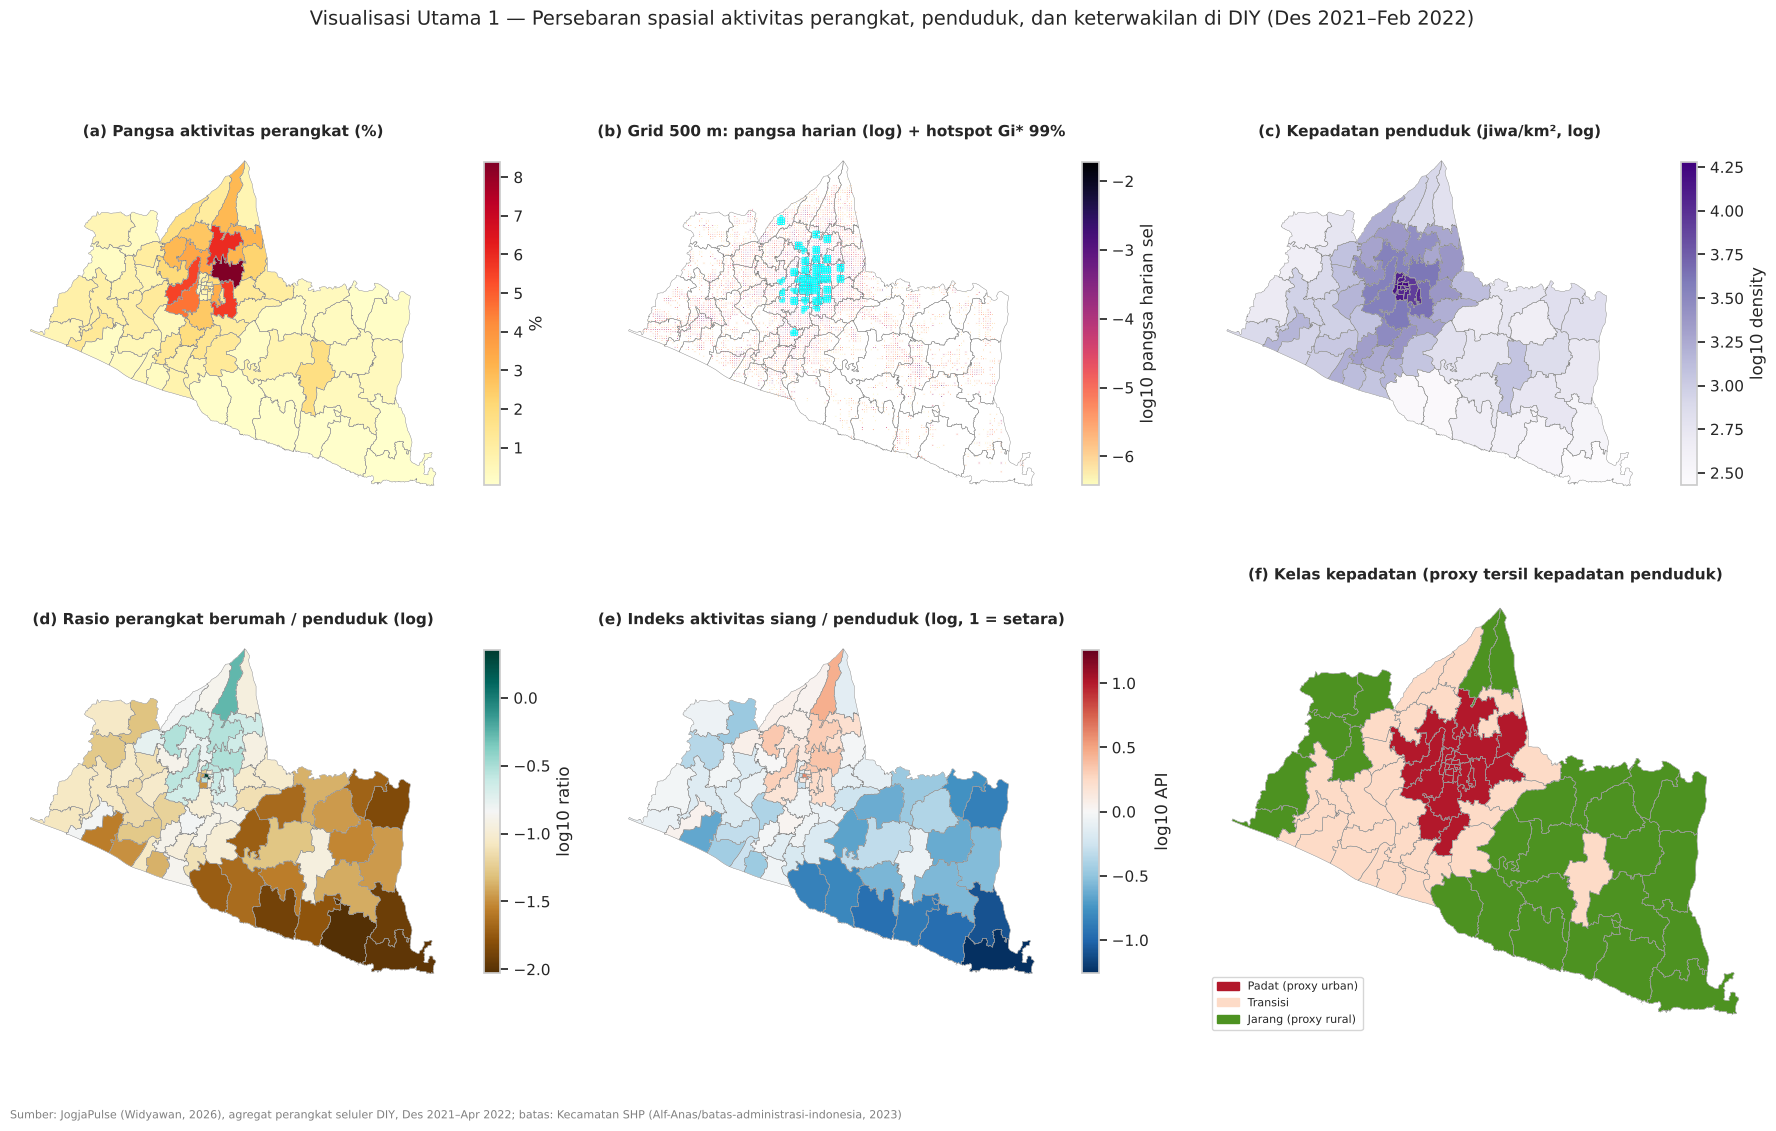

In [42]:
if HAS_BOUNDARY:
    gmap = gdf_kap_simple[["kapanewon_code", "geometry"]].merge(
        kap_hq[["label", "kab_kota", "urban_rural", "activity_share_pct", "day_night_ratio", "api", "density", "ratio",
                "pop_actual", "n_users"]].reset_index(), on="kapanewon_code")
    gcells = gdf_cells.merge(cell_stats[["cell_share_lb", "hotspot_class"]].reset_index(), on="cell_id").to_crs(CRS_WGS84)
    fig, axes = plt.subplots(2, 3, figsize=(18, 11))
    panels = [
        ("activity_share_pct", "YlOrRd", "(a) Pangsa aktivitas perangkat (%)", None),
        (None, None, "(b) Grid 500 m: pangsa harian (log) + hotspot Gi* 99%", None),
        ("density", "Purples", "(c) Kepadatan penduduk (jiwa/km², log)", "log"),
        ("ratio", "BrBG", "(d) Rasio perangkat berumah / penduduk (log)", "log"),
        ("api", "RdBu_r", "(e) Indeks aktivitas siang / penduduk (log, 1 = setara)", "lognorm1"),
        ("urban_rural", None, f"(f) Kelas kepadatan ({URBAN_SOURCE})", "cat"),
    ]
    for ax, (col, cmap, title, mode) in zip(axes.flat, panels):
        gdf_kap_simple.boundary.plot(ax=ax, color="gray", lw=0.3)
        if col is None:
            nonzero = gcells[gcells.cell_share_lb > 0]
            nonzero.plot(ax=ax, column=np.log10(nonzero.cell_share_lb), cmap="magma_r", markersize=0, legend=True,
                         legend_kwds={"label": "log10 pangsa harian sel", "shrink": 0.6})
            gcells[gcells.hotspot_class == "Hotspot 99%"].boundary.plot(ax=ax, color="cyan", lw=0.6)
        elif mode == "cat":
            palette = dict(zip(URBAN_ORDER, ["#b2182b", "#fddbc7", "#4d9221", "#b2182b", "#4d9221"]))
            gmap.plot(ax=ax, color=gmap.urban_rural.map(palette), edgecolor="white", lw=0.3)
            ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=palette[c]) for c in URBAN_ORDER], labels=URBAN_ORDER, loc="lower left", fontsize=8)
        else:
            if mode == "lognorm1":
                vmax = np.abs(np.log10(gmap[col])).max()
                gmap.plot(ax=ax, column=np.log10(gmap[col]), cmap=cmap, vmin=-vmax, vmax=vmax, legend=True, edgecolor="white", lw=0.3,
                          legend_kwds={"label": "log10 API", "shrink": 0.6})
            elif mode == "log":
                gmap.plot(ax=ax, column=np.log10(gmap[col]), cmap=cmap, legend=True, edgecolor="white", lw=0.3,
                          legend_kwds={"label": f"log10 {col}", "shrink": 0.6})
            else:
                gmap.plot(ax=ax, column=col, cmap=cmap, legend=True, edgecolor="white", lw=0.3, legend_kwds={"label": "%", "shrink": 0.6})
        ax.set_title(title, fontsize=11)
        ax.set_axis_off()
    fig.suptitle("Visualisasi Utama 1 — Persebaran spasial aktivitas perangkat, penduduk, dan keterwakilan di DIY (Des 2021–Feb 2022)", y=0.99)
    fig.tight_layout()
    save_fig(fig, "V1_spatial_activity_map_static", DATA_SOURCE_NOTE + "; batas: Kecamatan SHP (Alf-Anas/batas-administrasi-indonesia, 2023)")
    plt.show()

**Interpretasi singkat V1:** panel (a) dan (b) memperlihatkan aktivitas yang memusat di aglomerasi Kota Yogyakarta–Sleman–Bantul utara; panel (b) menunjukkan klaster hotspot (garis cyan) yang menyatu di inti kota. Panel (c)–(e) memperlihatkan bahwa kepadatan penduduk menjelaskan sebagian pola ini, tetapi indeks aktivitas/penduduk (e) tetap jauh di atas 1 di inti kota dan jauh di bawah 1 di Gunungkidul dan Kulon Progo.

In [43]:
def build_folium_map():
    """Peta interaktif dengan layer: aktivitas, penduduk, rasio perangkat/penduduk, API, kelas kepadatan, grid & hotspot, POI wisata."""
    import branca.colormap as bcm
    fmap = folium.Map(location=[-7.87, 110.42], zoom_start=10, tiles="OpenStreetMap", control_scale=True)
    data = gmap.copy()
    data["api_log"] = np.log10(data.api)
    data["ratio_log"] = np.log10(data.ratio)
    tooltip_fields = ["label", "kab_kota", "activity_share_pct", "pop_actual", "n_users", "ratio", "api", "urban_rural"]
    tooltip_alias = ["Kapanewon", "Kab/Kota", "Pangsa aktivitas (%)", "Penduduk", "Perangkat berumah", "Rasio perangkat/penduduk",
                     "Indeks aktivitas/penduduk", "Kelas kepadatan"]
    layers = [
        ("Pangsa aktivitas perangkat (%)", "activity_share_pct", bcm.linear.YlOrRd_09, True),
        ("Penduduk (jiwa)", "pop_actual", bcm.linear.Purples_09, False),
        ("Rasio perangkat berumah/penduduk (log10)", "ratio_log", bcm.linear.BrBG_11, False),
        ("Indeks aktivitas siang/penduduk (log10)", "api_log", bcm.linear.RdBu_11, False),
    ]
    for name, col, base_cmap, show in layers:
        cmap = base_cmap.scale(data[col].min(), data[col].max())
        cmap.caption = name
        fg = folium.FeatureGroup(name=name, show=show)
        folium.GeoJson(data[tooltip_fields + ["api_log", "ratio_log", "geometry"]].to_json(),
                       style_function=lambda f, c=col, cm=cmap: {"fillColor": cm(f["properties"][c]), "color": "white", "weight": 0.6, "fillOpacity": 0.75},
                       tooltip=folium.GeoJsonTooltip(fields=tooltip_fields, aliases=tooltip_alias, localize=True)).add_to(fg)
        fg.add_to(fmap)
    class_colors = dict(zip(URBAN_ORDER, ["#b2182b", "#f4a582", "#4d9221", "#b2182b", "#4d9221"]))
    fg = folium.FeatureGroup(name=f"Kelas kepadatan ({URBAN_SOURCE})", show=False)
    folium.GeoJson(data[["label", "urban_rural", "geometry"]].to_json(),
                   style_function=lambda f: {"fillColor": class_colors.get(f["properties"]["urban_rural"], "gray"), "color": "white", "weight": 0.6, "fillOpacity": 0.6},
                   tooltip=folium.GeoJsonTooltip(fields=["label", "urban_rural"])).add_to(fg)
    fg.add_to(fmap)
    # Grid: hanya sel dengan aktivitas > 0, nilai log
    grid = gcells[gcells.cell_share_lb > 0][["cell_id", "cell_share_lb", "hotspot_class", "geometry"]].copy()
    grid["log_share"] = np.log10(grid.cell_share_lb)
    grid["share_pct"] = (grid.cell_share_lb * 100).round(4)
    grid_cmap = bcm.linear.magma.scale(grid.log_share.min(), grid.log_share.max())
    fg = folium.FeatureGroup(name="Grid 500 m: pangsa harian (log)", show=False)
    folium.GeoJson(grid.to_json(), style_function=lambda f: {"fillColor": grid_cmap(f["properties"]["log_share"]), "weight": 0, "fillOpacity": 0.7},
                   tooltip=folium.GeoJsonTooltip(fields=["cell_id", "share_pct", "hotspot_class"], aliases=["Sel", "Pangsa harian (%)", "Gi*"])).add_to(fg)
    fg.add_to(fmap)
    fg = folium.FeatureGroup(name="Hotspot Gi* 99%", show=True)
    folium.GeoJson(grid[grid.hotspot_class == "Hotspot 99%"].to_json(),
                   style_function=lambda f: {"fillColor": "#00bcd4", "color": "#006064", "weight": 0.5, "fillOpacity": 0.45},
                   tooltip=folium.GeoJsonTooltip(fields=["cell_id", "share_pct"], aliases=["Sel", "Pangsa harian (%)"])).add_to(fg)
    fg.add_to(fmap)
    if HAS_TOURISM:
        fg = folium.FeatureGroup(name="Lokasi wisata (POI)", show=True)
        for r in poi.itertuples():
            folium.CircleMarker([r.lat, r.lon], radius=3, color="green", fill=True, tooltip=f"{r.name} ({r.category})").add_to(fg)
        fg.add_to(fmap)
    folium.LayerControl(collapsed=False).add_to(fmap)
    title = ("<div style='position:fixed;bottom:8px;left:8px;z-index:999;background:white;padding:6px;font-size:11px'>"
             "<b>JogjaPulse V1</b> — aktivitas perangkat Des 2021–Feb 2022. " + DATA_SOURCE_NOTE + "</div>")
    fmap.get_root().html.add_child(folium.Element(title))
    return fmap


if HAS_BOUNDARY:
    folium_map = build_folium_map()
    v1_path = MAP_DIR / "V1_interactive_spatial_activity_map.html"
    folium_map.save(str(v1_path))
    print("Peta interaktif disimpan:", v1_path.relative_to(PROJECT_DIR), f"({v1_path.stat().st_size / 1e6:.1f} MB)")
    from IPython.display import IFrame
    display(IFrame(src=str(v1_path.relative_to(PROJECT_DIR)), width="100%", height=550))

Peta interaktif disimpan: outputs/maps/V1_interactive_spatial_activity_map.html (6.3 MB)


In [44]:
by_kab = kap_hq.groupby("kab_kota").agg(activity_share_pct=("activity_share_pct", "sum"), pop=("pop_actual", "sum"), area=("area_km2", "sum"))
by_kab["pop_share_pct"] = by_kab["pop"] / by_kab["pop"].sum() * 100
by_kab["area_share_pct"] = by_kab["area"] / by_kab["area"].sum() * 100
by_kab = by_kab.loc[KAB_ORDER]
display(by_kab)
add_insight("S10", "Persebaran aktivitas perangkat di seluruh DIY",
            "presence_cell500m_daily; presence_kapanewon_hourly; batas kapanewon", "n_maids, share",
            "Choropleth, peta grid, ringkasan per kabupaten", "Σ activity_share per kabupaten", "V1 (statis & interaktif)", "completed",
            "; ".join(f"{k.title()}: aktivitas {r.activity_share_pct:.1f}%, penduduk {r.pop_share_pct:.1f}%, luas {r.area_share_pct:.1f}%" for k, r in by_kab.iterrows()),
            "Sleman dan Kota Yogyakarta menampung mayoritas aktivitas perangkat meski luasnya kecil; Gunungkidul (luas terbesar) menampung porsi sangat kecil.",
            "Aktivitas = device-presence sampel, bukan penduduk; pengaruh cakupan sampel tidak bisa dipisahkan sepenuhnya.")

,activity_share_pct,pop,area,pop_share_pct,area_share_pct
kab_kota,,,,,
YOGYAKARTA,14.5257,"375,280.0000",32.7967,10.1763,1.0351
SLEMAN,46.9332,"1,134,150.0000",573.3572,30.7543,18.0960
BANTUL,25.4752,"991,890.0000",511.3620,26.8967,16.1393
KULON PROGO,7.6057,"438,190.0000",576.8830,11.8822,18.2073
GUNUNGKIDUL,5.4602,"748,270.0000","1,474.0253",20.2905,46.5223


---
## Section 5 — Temporal Activity Analysis (T01–T14)

### 5.0 Metrik temporal
Jumlah perangkat yang teramati di seluruh DIY sendiri naik-turun sepanjang hari (paling sedikit sekitar pukul 03.00). Jika kita langsung membandingkan `n_maids` jam 03.00 dengan jam 12.00, kita hanya melihat ritme umum sampel. Untuk melihat **karakter** tiap kapanewon, kita memakai tiga metrik:

| Metrik | Rumus | Arti |
|---|---|---|
| **Pangsa periode** | rata-rata `share_lb` pada jam-jam dalam periode | Seberapa besar porsi kapanewon dari aktivitas DIY pada periode itu (ukuran absolut, dinormalisasi terhadap ukuran sampel). |
| **Location Quotient (LQ) periode** | pangsa periode ÷ pangsa rata-rata sepanjang hari | > 1 = kapanewon relatif lebih "hidup" pada periode itu dibanding jam lain; < 1 = relatif sepi. Menghilangkan efek ukuran wilayah. |
| **Indeks profil relatif per jam** | pangsa jam *h* ÷ rata-rata pangsa 24 jam | Bentuk ritme harian kapanewon, terlepas dari ukurannya. Dipakai di heatmap V2 dan clustering. |

Agar LQ tidak bias oleh suppression (slot kosong = batas bawah), ranking LQ hanya memakai kapanewon dengan **cakupan ≥ 90% pada periode tersebut**. Seluruh analisis memakai periode HQ (Des 2021 – Feb 2022).

In [45]:
PERIOD_ORDER = list(TIME_PERIODS)
COVERAGE_MIN = 90

period_share = panel_hq.groupby(["kapanewon_code", "period"]).share_lb.mean().unstack()[PERIOD_ORDER] * 100
period_cov = panel_hq.groupby(["kapanewon_code", "period"]).published.mean().unstack()[PERIOD_ORDER] * 100
period_maids = panel_hq.groupby(["kapanewon_code", "period"]).n_maids.mean().unstack()[PERIOD_ORDER]   # atas slot terpublikasi
period_lq = period_share.div(kap_hq.activity_share_pct, axis=0)


def hour_matrix(df, value="share_lb"):
    """Matriks kapanewon × jam (rata-rata nilai)."""
    return df.groupby(["kapanewon_code", "hour"])[value].mean().unstack()


share_by_daytype = {
    "Semua hari": hour_matrix(panel_hq),
    "Hari kerja": hour_matrix(panel_hq[panel_hq.day_type == "Hari kerja"]),
    "Akhir pekan": hour_matrix(panel_hq[panel_hq.day_type == "Akhir pekan"]),
}
rel_profile = {k: m.div(m.mean(axis=1), axis=0) for k, m in share_by_daytype.items()}
print("Cakupan per periode (median antar-kapanewon, %):", period_cov.median().round(1).to_dict())
print("Jumlah kapanewon dengan cakupan ≥ 90%:", (period_cov >= COVERAGE_MIN).sum().to_dict())

Cakupan per periode (median antar-kapanewon, %): {'Dini hari': 94.3, 'Pagi': 99.6, 'Siang': 100.0, 'Sore': 100.0, 'Malam': 99.7}
Jumlah kapanewon dengan cakupan ≥ 90%: {'Dini hari': 47, 'Pagi': 67, 'Siang': 74, 'Sore': 72, 'Malam': 69}


### T01–T05 — Kapanewon paling aktif pada setiap periode waktu
Untuk setiap periode kita tampilkan dua sudut pandang: **absolut** (pangsa terbesar) dan **karakter** (LQ terbesar, hanya kapanewon dengan cakupan ≥ 90%).

In [46]:
period_rows = []
for p in PERIOD_ORDER:
    top_abs = period_share[p].sort_values(ascending=False).head(5)
    eligible = period_lq.loc[period_cov[p] >= COVERAGE_MIN, p].sort_values(ascending=False).head(5)
    period_rows.append({
        "periode": p, "jam": f"{TIME_PERIODS[p][0]:02d}.00–{TIME_PERIODS[p][1]:02d}.59",
        "top5_pangsa_absolut_%": fmt_list(top_abs.rename(index=LABEL)),
        "top5_LQ_(cakupan≥90%)": fmt_list(eligible.rename(index=LABEL)),
        "kapanewon_layak_LQ": int((period_cov[p] >= COVERAGE_MIN).sum()),
    })
period_top = pd.DataFrame(period_rows)
save_table(period_top, "T01_T05_top_by_period")
period_table = (period_share.add_suffix("_share%").join(period_lq.add_suffix("_LQ")).join(period_cov.add_suffix("_cov%"))
                .join(LABEL).join(KAB_OF))
save_table(period_table.reset_index(), "T_period_share_lq_coverage")
with pd.option_context("display.max_colwidth", 200):
    display(period_top)

Tabel disimpan: outputs/tables/T01_T05_top_by_period.csv
Tabel disimpan: outputs/tables/T_period_share_lq_coverage.csv


,periode,jam,top5_pangsa_absolut_%,top5_LQ_(cakupan≥90%),kapanewon_layak_LQ
0,Dini hari,00.00–04.59,"DEPOK (9.67), NGAGLIK (6.37), GAMPING (5.62), BANGUNTAPAN (5.49), KASIHAN (4.95)","GONDOMANAN (2.00), SLEMAN (1.27), DEPOK (1.15), KRATON (1.12), TEGALREJO (1.10)",47
1,Pagi,05.00–10.59,"DEPOK (7.70), GAMPING (5.83), NGAGLIK (5.62), BANGUNTAPAN (5.57), KASIHAN (4.31)","NGLIPAR (1.18), SEMIN (1.17), GEDANGSARI (1.16), SAMIGALUH (1.14), SANDEN (1.13)",67
2,Siang,11.00–14.59,"DEPOK (8.07), NGAGLIK (5.70), BANGUNTAPAN (5.60), GAMPING (5.43), KASIHAN (4.48)","TEPUS (1.54), TANJUNGSARI (1.52), SAPTOSARI (1.50), PALIYAN (1.32), PANGGANG (1.31)",74
3,Sore,15.00–17.59,"DEPOK (8.24), NGAGLIK (6.03), BANGUNTAPAN (5.75), GAMPING (5.39), KASIHAN (4.61)","SAPTOSARI (1.44), PALIYAN (1.20), NGAWEN (1.19), PANGGANG (1.16), GEDONGTENGEN (1.15)",72
4,Malam,18.00–23.59,"DEPOK (8.30), NGAGLIK (6.15), BANGUNTAPAN (5.74), GAMPING (5.10), KASIHAN (4.80)","PLERET (1.11), MOYUDAN (1.10), PUNDONG (1.09), PANJATAN (1.08), SRANDAKAN (1.08)",69


### T06 — Kapanewon dengan aktivitas malam tertinggi
"Malam" di sini digabung menjadi **18.00–04.59** (malam + dini hari). Kita laporkan rata-rata perangkat per jam (absolut, slot terpublikasi) dan LQ malam.

In [47]:
night_mask = panel_hq.hour.isin(list(range(18, 24)) + list(range(0, 5)))
night_stats = pd.DataFrame({
    "mean_maids_night": panel_hq[night_mask].groupby("kapanewon_code").n_maids.mean(),
    "night_share_pct": panel_hq[night_mask].groupby("kapanewon_code").share_lb.mean() * 100,
    "night_cov_pct": panel_hq[night_mask].groupby("kapanewon_code").published.mean() * 100,
}).join(LABEL)
night_stats["night_LQ"] = night_stats.night_share_pct / kap_hq.activity_share_pct
t06_abs = night_stats.sort_values("mean_maids_night", ascending=False).head(8)
t06_lq = night_stats[night_stats.night_cov_pct >= COVERAGE_MIN].sort_values("night_LQ", ascending=False).head(8)
display(t06_abs)
display(t06_lq)

,mean_maids_night,night_share_pct,night_cov_pct,label,night_LQ
kapanewon_code,,,,,
34.04.07,490.2222,8.9261,100.0000,DEPOK,1.0637
34.04.12,363.2990,6.2510,100.0000,NGAGLIK,1.0465
34.02.12,333.8747,5.6255,100.0000,BANGUNTAPAN,1.0003
34.04.01,320.4091,5.3370,100.0000,GAMPING,0.9731
34.02.16,293.2162,4.8678,100.0000,KASIHAN,1.0508
34.04.06,202.7465,3.5001,100.0000,MLATI,1.0056
34.71.13,199.3212,3.4673,100.0000,UMBULHARJO,1.0442
34.04.11,196.2578,3.2902,99.8990,NGEMPLAK,1.0632


,mean_maids_night,night_share_pct,night_cov_pct,label,night_LQ
kapanewon_code,,,,,
34.71.10,100.5444,2.6238,100.0000,GONDOMANAN,1.2639
34.04.13,142.9737,2.8081,100.0000,SLEMAN,1.0639
34.04.07,490.2222,8.9261,100.0000,DEPOK,1.0637
34.04.11,196.2578,3.2902,99.8990,NGEMPLAK,1.0632
34.02.16,293.2162,4.8678,100.0000,KASIHAN,1.0508
34.04.12,363.2990,6.2510,100.0000,NGAGLIK,1.0465
34.71.09,41.7554,0.7015,98.2828,KRATON,1.0443
34.71.13,199.3212,3.4673,100.0000,UMBULHARJO,1.0442


### T07 & T08 — Apakah hari Minggu lebih sepi? Perbandingan hari dalam seminggu
Total device-hours harian turun karena perubahan sampel, sehingga kita membuat **indeks harian terdetrend**:

$$\text{indeks}_d = \frac{\text{device-hours}_d}{\text{rata-rata bergerak terpusat 7 hari}_d}$$

Indeks 1,00 berarti hari itu setara rata-rata minggunya; 0,95 berarti 5% lebih rendah. Hari libur nasional, tanggal di sekitar patahan sampel (1 Jan dan 16 Feb ± 3 hari), serta hari pertama/terakhir periode dikeluarkan.

**Uji statistik:** *Kruskal–Wallis* (apakah ada perbedaan antara 7 hari) dan *Mann–Whitney* (Minggu vs Senin–Jumat). Keduanya uji non-parametrik: membandingkan peringkat nilai, tidak mengasumsikan distribusi normal — cocok untuk sampel kecil (±12 minggu).

In [48]:
BREAK_DATES = [pd.Timestamp("2022-01-01"), pd.Timestamp("2022-02-16")]
ANOMALY_DATES = [pd.Timestamp("2021-12-01"), pd.Timestamp("2022-03-08")]


def near_break(dates, days=3):
    return np.any([np.abs((dates - b).days) <= days for b in BREAK_DATES], axis=0)


daily_index = daily_quality[["device_hours"]].copy()
daily_index["ma7"] = daily_index.device_hours.rolling(7, center=True).mean()
daily_index["index"] = daily_index.device_hours / daily_index.ma7
daily_index["dow"] = daily_index.index.dayofweek
daily_index["dow_name"] = pd.Categorical(daily_index.dow.map(dict(enumerate(DOW_NAMES))), categories=DOW_NAMES, ordered=True)
daily_index["is_holiday"] = daily_index.index.isin(list(ID_HOLIDAYS))
daily_index["exclude"] = (daily_index.is_holiday | near_break(daily_index.index) | daily_index.index.isin(ANOMALY_DATES)
                          | daily_index["index"].isna())
dow_sample = daily_index[(~daily_index.exclude) & (daily_index.index <= HQ_END)]
dow_summary = dow_sample.groupby("dow_name", observed=True)["index"].agg(["mean", "median", "std", "count"])
kw = stats.kruskal(*[g["index"].values for _, g in dow_sample.groupby("dow_name", observed=True)])
sunday = dow_sample.loc[dow_sample.dow == 6, "index"]
workdays = dow_sample.loc[dow_sample.dow <= 4, "index"]
mw_sun = stats.mannwhitneyu(sunday, workdays, alternative="less")
print(f"Kruskal–Wallis antar-hari: H = {kw.statistic:.2f}, p = {kw.pvalue:.2e}")
print(f"Minggu vs Senin–Jumat: median {sunday.median():.3f} vs {workdays.median():.3f}; Mann–Whitney (Minggu lebih rendah) p = {mw_sun.pvalue:.2e}")
dow_summary

Kruskal–Wallis antar-hari: H = 2.40, p = 8.80e-01
Minggu vs Senin–Jumat: median 0.975 vs 1.001; Mann–Whitney (Minggu lebih rendah) p = 1.14e-01


,mean,median,std,count
dow_name,,,,
Senin,0.9890,1.0183,0.1048,10
Selasa,0.9912,0.9655,0.1308,9
Rabu,1.0195,1.0243,0.0797,10
Kamis,1.0149,0.9983,0.1003,10
Jumat,0.9934,0.9873,0.0566,10
Sabtu,0.9917,0.9847,0.0560,10
Minggu,0.9583,0.9751,0.1089,11


In [49]:
# Efek akhir pekan per kapanewon: pangsa akhir pekan / pangsa hari kerja (HQ)
weekend_ratio = (panel_hq[panel_hq.day_type == "Akhir pekan"].groupby("kapanewon_code").share_lb.mean()
                 / panel_hq[panel_hq.day_type == "Hari kerja"].groupby("kapanewon_code").share_lb.mean())
kap_hq["weekend_ratio"] = weekend_ratio
wk = kap_hq[kap_hq.coverage_pct >= COVERAGE_MIN].sort_values("weekend_ratio", ascending=False)[["label", "kab_kota", "weekend_ratio", "coverage_pct"]]
print("Pangsa naik saat akhir pekan (rasio > 1):")
display(wk.head(8))
print("Pangsa turun saat akhir pekan:")
display(wk.tail(8))

Pangsa naik saat akhir pekan (rasio > 1):


,label,kab_kota,weekend_ratio,coverage_pct
kapanewon_code,,,,
34.02.10,IMOGIRI,BANTUL,1.2511,99.0741
34.03.14,GEDANGSARI,GUNUNGKIDUL,1.2069,93.1481
34.01.12,KALIBAWANG,KULON PROGO,1.1860,93.7037
34.71.10,GONDOMANAN,YOGYAKARTA,1.1723,100.0000
34.01.11,SAMIGALUH,KULON PROGO,1.1235,96.9907
34.02.01,SRANDAKAN,BANTUL,1.1185,95.6944
34.02.04,PUNDONG,BANTUL,1.1157,96.6204
34.04.13,SLEMAN,SLEMAN,1.1032,100.0000


Pangsa turun saat akhir pekan:


,label,kab_kota,weekend_ratio,coverage_pct
kapanewon_code,,,,
34.71.09,KRATON,YOGYAKARTA,0.9381,99.1204
34.03.01,WONOSARI,GUNUNGKIDUL,0.9295,99.6296
34.71.03,GONDOKUSUMAN,YOGYAKARTA,0.9290,100.0000
34.71.11,PAKUALAMAN,YOGYAKARTA,0.9275,96.0185
34.71.14,KOTAGEDE,YOGYAKARTA,0.9230,99.1204
34.71.02,JETIS (Yogyakarta),YOGYAKARTA,0.9147,99.9537
34.02.16,KASIHAN,BANTUL,0.9126,100.0000
34.01.02,WATES,KULON PROGO,0.8884,98.7037


### T09 — Jam puncak aktivitas hari kerja vs akhir pekan
Untuk tingkat DIY, setiap jam dinormalisasi terhadap rata-rata jam pada hari yang sama (sehingga hari dengan sampel besar tidak mendominasi). Untuk tingkat kapanewon, jam puncak = jam dengan rata-rata pangsa × total sampel tertinggi — praktisnya, jam dengan rata-rata `n_maids` (batas bawah) tertinggi.

In [50]:
hourly_totals = panel_hq.groupby(["date", "hour"]).n_maids.sum().rename("device_presence").reset_index()
hourly_totals["norm"] = hourly_totals.device_presence / hourly_totals.groupby("date").device_presence.transform("mean")
hourly_totals["day_type"] = np.select([hourly_totals.date.isin(list(ID_HOLIDAYS)), hourly_totals.date.dt.dayofweek >= 5],
                                      ["Libur nasional", "Akhir pekan"], "Hari kerja")
diy_profile = hourly_totals.groupby(["day_type", "hour"]).norm.mean().unstack(0)
peak_diy = diy_profile.idxmax()
print("Jam puncak DIY (indeks ternormalisasi):", peak_diy.to_dict())
print("Jam minimum DIY:", diy_profile.idxmin().to_dict())

maids_lb = {dt: panel_hq[panel_hq.day_type == dt].groupby(["kapanewon_code", "hour"]).n_maids.sum().unstack()
            / panel_hq[panel_hq.day_type == dt].groupby(["kapanewon_code", "hour"]).size().unstack()
            for dt in ["Hari kerja", "Akhir pekan"]}
peak_hours = pd.DataFrame({dt: m.idxmax(axis=1) for dt, m in maids_lb.items()})
peak_hours["shift_hours"] = peak_hours["Akhir pekan"] - peak_hours["Hari kerja"]
print("Distribusi jam puncak kapanewon (hari kerja):", peak_hours["Hari kerja"].value_counts().sort_index().to_dict())
print("Distribusi jam puncak kapanewon (akhir pekan):", peak_hours["Akhir pekan"].value_counts().sort_index().to_dict())
wilcoxon_peak = stats.wilcoxon(peak_hours["Hari kerja"], peak_hours["Akhir pekan"])
print(f"Wilcoxon jam puncak hari kerja vs akhir pekan: p = {wilcoxon_peak.pvalue:.3f}; median selisih = {peak_hours.shift_hours.median():.1f} jam")

Jam puncak DIY (indeks ternormalisasi): {'Akhir pekan': 19, 'Hari kerja': 12, 'Libur nasional': 20}
Jam minimum DIY: {'Akhir pekan': 3, 'Hari kerja': 3, 'Libur nasional': 3}


Distribusi jam puncak kapanewon (hari kerja): {1: 1, 11: 3, 12: 24, 13: 8, 14: 6, 16: 3, 17: 3, 18: 4, 19: 23, 20: 3}
Distribusi jam puncak kapanewon (akhir pekan): {1: 1, 11: 5, 12: 7, 13: 14, 14: 2, 16: 2, 17: 1, 18: 16, 19: 19, 20: 10, 21: 1}
Wilcoxon jam puncak hari kerja vs akhir pekan: p = 0.013; median selisih = 0.0 jam


Gambar disimpan: outputs/figures/T07_T09_weekly_rhythm.png


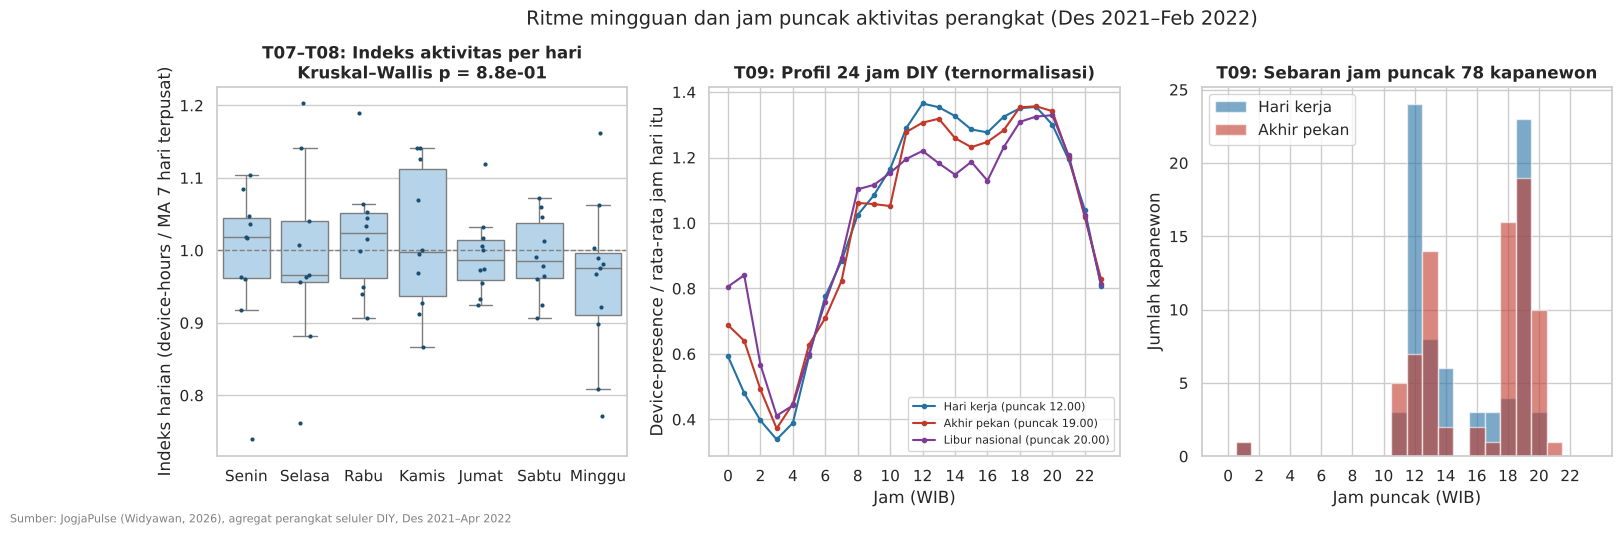

In [51]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
ax = axes[0]
sns.boxplot(data=dow_sample, x="dow_name", y="index", ax=ax, color="#aed6f1", showfliers=False)
sns.stripplot(data=dow_sample, x="dow_name", y="index", ax=ax, color="#1b4f72", size=3)
ax.axhline(1, color="gray", ls="--", lw=1)
ax.set(xlabel="", ylabel="Indeks harian (device-hours / MA 7 hari terpusat)",
       title=f"T07–T08: Indeks aktivitas per hari\nKruskal–Wallis p = {kw.pvalue:.1e}")
ax = axes[1]
for dt, color in zip(["Hari kerja", "Akhir pekan", "Libur nasional"], ["#2471a3", "#c0392b", "#7d3c98"]):
    if dt in diy_profile:
        ax.plot(diy_profile.index, diy_profile[dt], marker="o", ms=3, color=color, label=f"{dt} (puncak {peak_diy[dt]:02d}.00)")
ax.set(xlabel="Jam (WIB)", ylabel="Device-presence / rata-rata jam hari itu", title="T09: Profil 24 jam DIY (ternormalisasi)", xticks=range(0, 24, 2))
ax.legend(fontsize=8)
ax = axes[2]
bins = np.arange(-0.5, 24.5, 1)
ax.hist(peak_hours["Hari kerja"], bins=bins, alpha=0.6, label="Hari kerja", color="#2471a3")
ax.hist(peak_hours["Akhir pekan"], bins=bins, alpha=0.6, label="Akhir pekan", color="#c0392b")
ax.set(xlabel="Jam puncak (WIB)", ylabel="Jumlah kapanewon", title="T09: Sebaran jam puncak 78 kapanewon", xticks=range(0, 24, 2))
ax.legend()
fig.suptitle("Ritme mingguan dan jam puncak aktivitas perangkat (Des 2021–Feb 2022)", y=1.04)
save_fig(fig, "T07_T09_weekly_rhythm")
plt.show()

### T10 & T11 — Perubahan paling drastis pagi→malam dan pola paling stabil
- **T10:** $\log_2(LQ_{malam}/LQ_{pagi})$. Nilai +1 berarti porsi malam dua kali porsi pagi (relatif terhadap rata-rata kapanewon itu); −1 berarti separuhnya.
- **T11:** *Coefficient of variation* (CV = simpangan baku ÷ rata-rata) dari profil 24 jam `n_maids` (batas bawah). CV kecil = jumlah perangkat relatif konstan sepanjang hari. Karena seluruh DIY punya siklus harian, CV kapanewon dibandingkan dengan CV DIY.

Hanya kapanewon dengan cakupan ≥ 90% di semua periode yang dinilai.

In [52]:
full_cov = (period_cov >= COVERAGE_MIN).all(axis=1)
pm = pd.DataFrame({"LQ_pagi": period_lq["Pagi"], "LQ_malam": period_lq["Malam"]})
pm["log2_malam_vs_pagi"] = np.log2(pm.LQ_malam / pm.LQ_pagi)
pm = pm[full_cov].join(LABEL).join(KAB_OF)
t10 = pm.reindex(pm.log2_malam_vs_pagi.abs().sort_values(ascending=False).index)
print(f"Kapanewon layak (cakupan ≥90% semua periode): {full_cov.sum()}")
display(t10.head(10))

profile_lb_all = panel_hq.groupby(["kapanewon_code", "hour"]).n_maids.sum().unstack() / panel_hq.groupby(["kapanewon_code", "hour"]).size().unstack()
cv_profile = (profile_lb_all.std(axis=1) / profile_lb_all.mean(axis=1)).rename("cv_24h")
diy_cv = (panel_hq.groupby("hour").n_maids.sum().std() / panel_hq.groupby("hour").n_maids.sum().mean())
t11 = cv_profile[full_cov].to_frame().join(LABEL).join(KAB_OF).sort_values("cv_24h")
print(f"CV profil 24 jam DIY: {diy_cv:.3f}")
display(t11.head(8))
display(t11.tail(5))

Kapanewon layak (cakupan ≥90% semua periode): 47


,LQ_pagi,LQ_malam,log2_malam_vs_pagi,label,kab_kota
kapanewon_code,,,,,
34.71.10,0.8788,0.6514,-0.4320,GONDOMANAN,YOGYAKARTA
34.04.05,1.0970,0.8756,-0.3252,SEYEGAN,SLEMAN
34.04.16,1.0772,0.9299,-0.2120,PAKEM,SLEMAN
34.02.13,0.9649,1.1089,0.2008,PLERET,BANTUL
34.04.01,1.0637,0.9307,-0.1928,GAMPING,SLEMAN
34.01.01,1.1124,0.9826,-0.1791,TEMON,KULON PROGO
34.04.13,1.0097,0.8958,-0.1726,SLEMAN,SLEMAN
34.04.11,0.9198,1.0336,0.1683,NGEMPLAK,SLEMAN
34.02.16,0.9309,1.0359,0.1543,KASIHAN,BANTUL


CV profil 24 jam DIY: 0.353


,cv_24h,label,kab_kota
kapanewon_code,,,
34.04.13,0.2938,SLEMAN,SLEMAN
34.71.09,0.3029,KRATON,YOGYAKARTA
34.04.07,0.3103,DEPOK,SLEMAN
34.71.13,0.3115,UMBULHARJO,YOGYAKARTA
34.71.10,0.3176,GONDOMANAN,YOGYAKARTA
34.71.01,0.3258,TEGALREJO,YOGYAKARTA
34.02.08,0.3363,BANTUL,BANTUL
34.71.12,0.3364,MERGANGSAN,YOGYAKARTA


,cv_24h,label,kab_kota
kapanewon_code,,,
34.04.09,0.4065,PRAMBANAN,SLEMAN
34.03.01,0.4114,WONOSARI,GUNUNGKIDUL
34.01.10,0.4121,NANGGULAN,KULON PROGO
34.01.08,0.4168,KOKAP,KULON PROGO
34.03.03,0.4347,PLAYEN,GUNUNGKIDUL


### T12 — Perubahan aktivitas antarbulan
Angka mentah (rata-rata `n_maids` per jam) dan angka ternormalisasi (pangsa bulanan) ditampilkan berdampingan. Perubahan dinilai dengan **pangsa**, karena angka mentah turun di semua wilayah akibat penurunan sampel.

In [53]:
monthly_share = panel.groupby(["kapanewon_code", "month"]).share_lb.mean().unstack() * 100
monthly_raw = panel.groupby(["kapanewon_code", "month"]).n_maids.mean().unstack()
monthly_change = pd.DataFrame({
    "share_dec": monthly_share["2021-12"], "share_feb": monthly_share["2022-02"], "share_apr": monthly_share["2022-04"],
    "chg_feb_vs_dec_pp": monthly_share["2022-02"] - monthly_share["2021-12"],
    "rel_chg_feb_vs_dec_%": (monthly_share["2022-02"] / monthly_share["2021-12"] - 1) * 100,
    "raw_dec": monthly_raw["2021-12"], "raw_feb": monthly_raw["2022-02"], "raw_apr": monthly_raw["2022-04"],
}).join(LABEL).join(kap_hq[["lattice_share_of_grid_pct"]] if "lattice_share_of_grid_pct" in kap_hq else pd.DataFrame(index=kap_hq.index))
save_table(monthly_change.reset_index(), "T12_monthly_change")
print("Rata-rata n_maids per jam DIY per bulan (mentah, semua kapanewon):", monthly_raw.mean().round(1).to_dict())
print("Kenaikan pangsa terbesar Des→Feb (pp):")
display(monthly_change.sort_values("chg_feb_vs_dec_pp", ascending=False).head(6))
print("Penurunan pangsa terbesar Des→Feb (pp):")
display(monthly_change.sort_values("chg_feb_vs_dec_pp").head(6))
month_rank_corr = monthly_share.corr(method="spearman")
print("Korelasi Spearman pangsa antarbulan:")
month_rank_corr.round(3)

Tabel disimpan: outputs/tables/T12_monthly_change.csv
Rata-rata n_maids per jam DIY per bulan (mentah, semua kapanewon): {'2021-12': 111.8, '2022-01': 77.2, '2022-02': 78.9, '2022-03': 19.3, '2022-04': 15.6}
Kenaikan pangsa terbesar Des→Feb (pp):


,share_dec,share_feb,share_apr,chg_feb_vs_dec_pp,rel_chg_feb_vs_dec_%,raw_dec,raw_feb,raw_apr,label,lattice_share_of_grid_pct
kapanewon_code,,,,,,,,,,
34.04.07,6.6379,9.7329,7.1865,3.0950,46.6262,545.2849,593.6071,69.9000,DEPOK,0.0000
34.71.10,1.5009,3.2142,10.1147,1.7133,114.1464,101.4073,118.8646,89.5069,GONDOMANAN,0.0000
34.04.06,2.7027,4.3800,4.1089,1.6773,62.0605,234.1935,271.1458,39.8257,MLATI,0.0000
34.71.03,1.5623,2.5568,2.3869,0.9945,63.6585,130.1922,157.2024,23.0574,GONDOKUSUMAN,0.0000
34.71.02,0.6054,1.5955,1.9641,0.9902,163.5564,51.7030,97.2563,18.1053,JETIS (Yogyakarta),0.0000
34.71.13,2.7596,3.7186,3.9092,0.9590,34.7499,231.6022,231.4018,37.7841,UMBULHARJO,0.0000


Penurunan pangsa terbesar Des→Feb (pp):


,share_dec,share_feb,share_apr,chg_feb_vs_dec_pp,rel_chg_feb_vs_dec_%,raw_dec,raw_feb,raw_apr,label,lattice_share_of_grid_pct
kapanewon_code,,,,,,,,,,
34.04.05,5.2440,1.0981,2.0721,-4.1459,-79.0592,465.0161,58.6949,20.7432,SEYEGAN,64.8562
34.04.01,7.3536,4.3702,3.0811,-2.9834,-40.5702,651.6492,257.8884,30.4553,GAMPING,35.3442
34.04.16,4.3018,2.5889,3.2475,-1.7130,-39.8195,380.8548,176.2638,32.1949,PAKEM,48.2256
34.04.14,1.9399,1.1270,0.4917,-0.8129,-41.9027,167.9946,84.3134,8.0445,TEMPEL,0.0000
34.04.11,3.2339,2.4643,1.9448,-0.7696,-23.7985,275.0296,167.7079,18.9099,NGEMPLAK,0.0000
34.02.10,1.4674,0.8438,0.5836,-0.6236,-42.4960,128.9530,58.4809,8.1587,IMOGIRI,6.4434


Korelasi Spearman pangsa antarbulan:


month,2021-12,2022-01,2022-02,2022-03,2022-04
month,,,,,
2021-12,1.0000,0.9720,0.9070,0.8300,0.7670
2022-01,0.9720,1.0000,0.9470,0.8420,0.8270
2022-02,0.9070,0.9470,1.0000,0.9340,0.8840
2022-03,0.8300,0.8420,0.9340,1.0000,0.8350
2022-04,0.7670,0.8270,0.8840,0.8350,1.0000


### T13 — Kawasan wisata vs nonwisata (pola temporal)
Membutuhkan klasifikasi kapanewon/sel wisata (lihat Section 0.3). Sebagai pendekatan **sementara yang berbasis data**, rasio akhir pekan/hari kerja (T08) menunjukkan kapanewon mana yang pangsanya naik saat akhir pekan — karakteristik yang lazim pada kawasan rekreasi — tanpa menyimpulkan bahwa kapanewon tersebut adalah kawasan wisata.

In [54]:
if HAS_TOURISM and HAS_BOUNDARY:
    tourism_kap = cell_stats[cell_stats.is_tourism_cell].groupby("kapanewon_code").size()
    kap_hq["has_tourism_cell"] = kap_hq.index.isin(tourism_kap.index)
    t13 = rel_profile["Semua hari"].groupby(kap_hq.has_tourism_cell).mean()
    display(t13.round(3))
    display(kap_hq.groupby("has_tourism_cell").weekend_ratio.describe())
else:
    print("POI wisata belum tersedia -> T13 menggunakan pendekatan sementara (weekend_ratio) dan ditandai 'requires external data'.")

POI wisata belum tersedia -> T13 menggunakan pendekatan sementara (weekend_ratio) dan ditandai 'requires external data'.


### T14 — Aktif malam tetapi relatif sepi siang
Kriteria: LQ malam (18.00–23.59) > 1 **dan** LQ siang (11.00–14.59) < 1, hanya kapanewon dengan cakupan ≥ 90% di kedua periode.

In [55]:
t14_mask = (period_lq["Malam"] > 1) & (period_lq["Siang"] < 1) & (period_cov["Malam"] >= COVERAGE_MIN) & (period_cov["Siang"] >= COVERAGE_MIN)
t14 = period_lq.loc[t14_mask, ["Siang", "Malam", "Dini hari"]].join(LABEL).join(KAB_OF)
t14["malam_minus_siang"] = t14.Malam - t14.Siang
t14 = t14.sort_values("malam_minus_siang", ascending=False)
print(f"{len(t14)} kapanewon memenuhi kriteria")
display(t14)

13 kapanewon memenuhi kriteria


,Siang,Malam,Dini hari,label,kab_kota,malam_minus_siang
kapanewon_code,,,,,,
34.04.04,0.9586,1.0801,0.9131,MINGGIR,SLEMAN,0.1215
34.02.14,0.9607,1.0794,0.9615,PIYUNGAN,BANTUL,0.1187
34.04.14,0.9430,1.0491,0.9534,TEMPEL,SLEMAN,0.1061
34.04.11,0.9447,1.0336,1.0986,NGEMPLAK,SLEMAN,0.0889
34.04.12,0.9551,1.0300,1.0663,NGAGLIK,SLEMAN,0.0749
34.04.02,0.9900,1.0637,0.9693,GODEAN,SLEMAN,0.0737
34.02.16,0.9681,1.0359,1.0686,KASIHAN,BANTUL,0.0678
34.04.08,0.9772,1.0356,0.9851,BERBAH,SLEMAN,0.0584
34.71.13,0.9574,1.0067,1.0891,UMBULHARJO,YOGYAKARTA,0.0493


### Visualisasi Utama 2 — 24-Hour Activity Rhythm Heatmap (interaktif)
Heatmap kiri: indeks profil relatif per jam (78 kapanewon × 24 jam). Warna merah = jam ketika kapanewon lebih aktif daripada rata-ratanya sendiri; biru = lebih sepi. Heatmap kanan: LQ lima periode waktu. Tombol di atas memilih hari kerja / akhir pekan / semua hari. Baris diurutkan menurut kabupaten lalu LQ malam.

In [56]:
def build_rhythm_heatmap():
    order = (kap_hq.assign(lq_malam=period_lq["Malam"]).sort_values(["kab_kota", "lq_malam"], ascending=[True, False]).index)
    labels = [f"{LABEL[c]} · {KAB_OF[c].title()[:3]}" for c in order]
    fig = make_subplots(rows=1, cols=2, column_widths=[0.78, 0.22], horizontal_spacing=0.03, shared_yaxes=True,
                        subplot_titles=("Indeks profil relatif per jam (1 = rata-rata kapanewon itu)", "LQ periode waktu"))
    daytypes = ["Hari kerja", "Akhir pekan", "Semua hari"]
    for i, dt in enumerate(daytypes):
        z = rel_profile[dt].loc[order]
        sub = panel_hq if dt == "Semua hari" else panel_hq[panel_hq.day_type == dt]
        lq = (sub.groupby(["kapanewon_code", "period"]).share_lb.mean().unstack()[PERIOD_ORDER] * 100).div(
            sub.groupby("kapanewon_code").share_lb.mean() * 100, axis=0).loc[order]
        fig.add_trace(go.Heatmap(z=z.values, x=[f"{h:02d}" for h in range(24)], y=labels, colorscale="RdBu_r", zmid=1, zmin=0, zmax=2,
                                 colorbar=dict(title="Indeks", x=0.76, len=0.9), visible=(i == 0),
                                 hovertemplate="%{y}<br>Jam %{x}.00<br>Indeks %{z:.2f}<extra>" + dt + "</extra>"), row=1, col=1)
        fig.add_trace(go.Heatmap(z=lq.values, x=PERIOD_ORDER, y=labels, colorscale="PuOr_r", zmid=1, zmin=0.3, zmax=1.7,
                                 colorbar=dict(title="LQ", x=1.0, len=0.9), visible=(i == 0),
                                 hovertemplate="%{y}<br>%{x}<br>LQ %{z:.2f}<extra>" + dt + "</extra>"), row=1, col=2)
    buttons = [dict(label=dt, method="update", args=[{"visible": [j // 2 == i for j in range(6)]},
                                                      {"title": f"V2 — Ritme aktivitas 24 jam per kapanewon: {dt} (Des 2021–Feb 2022)"}])
               for i, dt in enumerate(daytypes)]
    fig.update_layout(updatemenus=[dict(type="buttons", direction="right", buttons=buttons, x=0.0, y=1.06, xanchor="left")],
                      title="V2 — Ritme aktivitas 24 jam per kapanewon: Hari kerja (Des 2021–Feb 2022)", height=1500, width=1100,
                      margin=dict(t=110, l=200, b=80),
                      annotations=list(fig.layout.annotations) + [dict(text=DATA_SOURCE_NOTE + ". Indeks = pangsa jam h / rata-rata pangsa 24 jam.",
                                                                       x=0, y=-0.03, xref="paper", yref="paper", showarrow=False, font=dict(size=10, color="gray"))])
    fig.update_yaxes(autorange="reversed", tickfont=dict(size=8))
    fig.update_xaxes(title_text="Jam (WIB)", row=1, col=1)
    return fig


v2_fig = build_rhythm_heatmap()
v2_fig.write_html(MAP_DIR / "V2_24h_activity_rhythm_heatmap.html", include_plotlyjs="cdn")
print("Disimpan:", (MAP_DIR / "V2_24h_activity_rhythm_heatmap.html").relative_to(PROJECT_DIR))
v2_fig.show()

Disimpan: outputs/maps/V2_24h_activity_rhythm_heatmap.html


Gambar disimpan: outputs/figures/V2_24h_activity_rhythm_heatmap_static.png


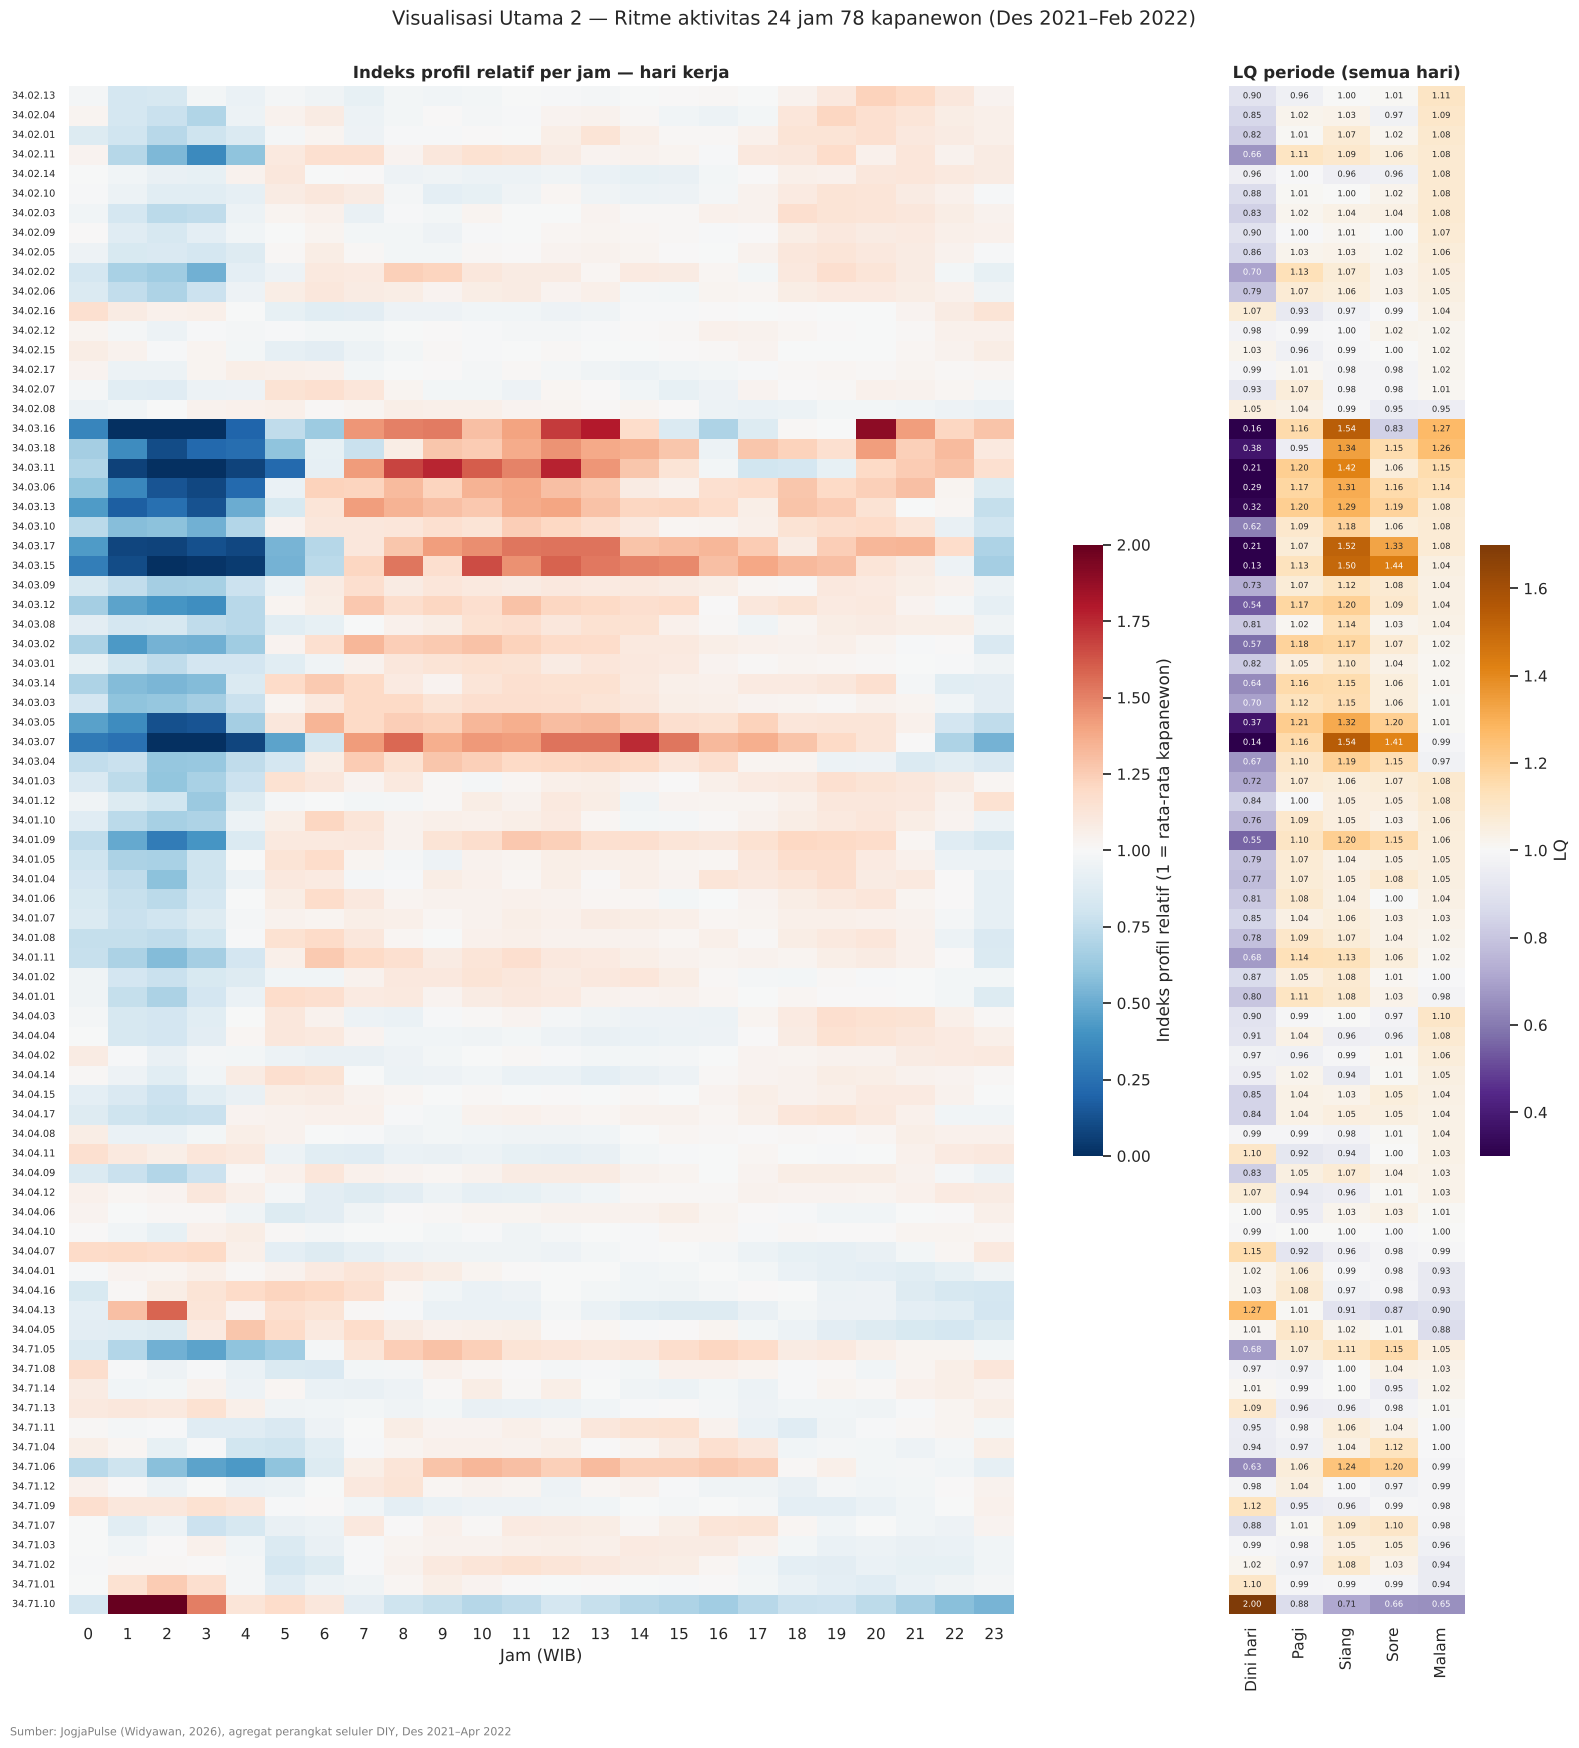

In [57]:
# Versi statis V2 untuk laporan (hari kerja)
order_static = kap_hq.assign(lq_malam=period_lq["Malam"]).sort_values(["kab_kota", "lq_malam"], ascending=[True, False]).index
fig, axes = plt.subplots(1, 2, figsize=(16, 17), gridspec_kw={"width_ratios": [4, 1]}, sharey=True)
sns.heatmap(rel_profile["Hari kerja"].loc[order_static], ax=axes[0], cmap="RdBu_r", center=1, vmin=0, vmax=2,
            cbar_kws={"label": "Indeks profil relatif (1 = rata-rata kapanewon)", "shrink": 0.4},
            yticklabels=[f"{LABEL[c]} · {KAB_OF[c].title()[:3]}" for c in order_static])
axes[0].set(xlabel="Jam (WIB)", ylabel="", title="Indeks profil relatif per jam — hari kerja")
sns.heatmap(period_lq.loc[order_static], ax=axes[1], cmap="PuOr_r", center=1, vmin=0.3, vmax=1.7, annot=True, fmt=".2f",
            annot_kws={"size": 6}, cbar_kws={"label": "LQ", "shrink": 0.4})
axes[1].set(xlabel="", ylabel="", title="LQ periode (semua hari)")
axes[0].tick_params(axis="y", labelsize=7)
fig.suptitle("Visualisasi Utama 2 — Ritme aktivitas 24 jam 78 kapanewon (Des 2021–Feb 2022)", y=1.0)
fig.tight_layout()
save_fig(fig, "V2_24h_activity_rhythm_heatmap_static")
plt.show()

### 5.x Interpretasi Section 5 (berdasarkan output di atas)

**Ritme umum.** Aktivitas DIY minimum sekitar pukul 03.00 dan puncak (ternormalisasi) pukul 12.00 pada hari kerja, tetapi bergeser ke 19.00 pada akhir pekan. Jam puncak 78 kapanewon bersifat **bimodal**: sebagian besar memuncak pukul 12–13 atau 18–20; pada akhir pekan, jumlah kapanewon yang memuncak di malam hari bertambah (Wilcoxon p ≈ 0,01).

**T01–T05.** Secara absolut, lima kapanewon yang sama (Depok, Ngaglik, Banguntapan, Gamping, Kasihan) mendominasi semua periode — ini efek ukuran. LQ memberi gambaran karakter yang lebih tajam:
- *Dini hari:* Gondomanan (LQ 2,0) jauh di atas yang lain, diikuti Sleman, Depok, Kraton, Tegalrejo (inti kota & koridor kampus). Nilai Gondomanan perlu dibaca hati-hati — lihat catatan anomali di bawah.
- *Pagi:* kapanewon perdesaan (Nglipar, Semin, Gedangsari, Samigaluh, Sanden) — ritme yang dimulai lebih awal.
- *Siang & sore:* kapanewon pesisir selatan Gunungkidul (Tepus, Tanjungsari, Saptosari, Paliyan, Panggang) memiliki LQ siang ±1,3–1,5: wilayah yang sepi di malam hari tetapi ramai di siang hari. Kawasan ini dikenal memiliki pantai wisata (konteks eksternal, belum diuji dengan data POI).
- *Malam:* kapanewon pinggiran Bantul/Sleman (Pleret, Moyudan, Pundong, Panjatan, Srandakan) — kawasan tempat tinggal.

**T07–T08.** Setelah detrending, hari Minggu ±2,5% lebih rendah daripada hari kerja (median 0,975 vs 1,001), tetapi perbedaan ini **tidak signifikan** secara statistik (Mann–Whitney p ≈ 0,11; Kruskal–Wallis antar-7 hari p ≈ 0,88) dengan ±11 minggu data. Artinya, total aktivitas sampel nyaris sama setiap hari; yang berubah adalah **di mana** aktivitas terjadi: pangsa kemantren Kota Yogyakarta, Wates, dan Wonosari (pusat kantor/sekolah) turun 6–11% saat akhir pekan, sedangkan Imogiri, Gedangsari, Kalibawang, Samigaluh, Srandakan, dan Pundong naik 10–25%.

**T10–T11.** Pergeseran pagi→malam umumnya kecil (|log2| < 0,45). Pergeseran terbesar (Gondomanan, Seyegan, Pakem, Gamping) justru terjadi di kapanewon yang terdampak artefak data, sehingga bukan cerminan perilaku. Kapanewon paling stabil sepanjang hari adalah kawasan urban padat (Sleman, Kraton, Depok, Umbulharjo, Gondomanan; CV ±0,29–0,32 vs CV DIY 0,35), sedangkan yang paling fluktuatif adalah kapanewon perdesaan/ibu kota kabupaten di pinggiran (Playen, Kokap, Nanggulan, Wonosari, Prambanan).

**T12.** Peringkat antarbulan sangat stabil dalam periode HQ (Spearman Des–Jan 0,97; Des–Feb 0,91), tetapi melemah terhadap April (0,77). Perubahan pangsa terbesar Des→Feb terjadi di kapanewon yang terkait **artefak** (Seyegan −79%, Gamping −41%, Pakem −40% — semuanya memuat sel kisi 0,1° yang menghilang pada akhir Januari; Gondomanan +114%). Perubahan yang tidak terkait artefak antara lain kenaikan Depok (+3,1 pp), Mlati, Gondokusuman, Jetis, Umbulharjo dan penurunan Tempel, Ngemplak, Imogiri. Data ini tidak cukup untuk menyimpulkan penyebabnya.

**T14.** 13 kapanewon "aktif malam, relatif sepi siang" seluruhnya berada di cincin pinggiran Sleman dan Bantul (Minggir, Piyungan, Tempel, Ngemplak, Ngaglik, Godean, Kasihan, Berbah, Sewon, Banguntapan, dll.) — pola khas **kawasan permukiman komuter**.

> **Catatan anomali Gondomanan.** Sel grid terbesar di Gondomanan memiliki ±900–2.000 perangkat/hari sepanjang periode, sementara total sampel DIY turun ±92%. Akibatnya pangsa Gondomanan naik dari 1,5% (Des) menjadi 10% (Apr) dan pada Maret mencapai ±39% kehadiran DIY pukul 03.00. Perilaku "tetap konstan saat sampel menyusut" lebih konsisten dengan **titik lokasi default** (mis. geokode tingkat kota) daripada dengan pengunjung nyata — meskipun README menduga penyebabnya wisata. Data agregat tidak dapat memastikan mana yang benar; indikator Gondomanan diperlakukan dengan hati-hati di seluruh notebook. Pola serupa terlihat pada satu sel di Kapanewon Sleman (Section 7, D06).

In [58]:
def lq_text(p, n=5):
    s = period_lq.loc[period_cov[p] >= COVERAGE_MIN, p].sort_values(ascending=False).head(n).rename(index=LABEL)
    a = period_share[p].sort_values(ascending=False).head(3).rename(index=LABEL)
    return f"Absolut (pangsa %): {fmt_list(a, 3)}. Karakter (LQ, cakupan≥90%): {fmt_list(s, n)}."


common_ds, common_cols = "presence_kapanewon_hourly", "kapanewon_code, date, hour, n_maids"
common_lim = "LQ dibatasi kapanewon cakupan ≥90%; pangsa adalah batas bawah; perangkat ≠ penduduk."
for tid, p, interp in [
    ("T01", "Dini hari", "Inti kota & koridor kampus paling 'hidup' dini hari; Gondomanan ekstrem (dicurigai artefak titik default)."),
    ("T02", "Pagi", "Kapanewon perdesaan (Gunungkidul utara, Kulon Progo, Bantul selatan) relatif paling aktif pagi hari."),
    ("T03", "Siang", "Kapanewon pesisir selatan Gunungkidul paling 'siang-sentris' (LQ ±1,5): ramai siang, sepi malam."),
    ("T04", "Sore", "Pola sore mirip siang: Gunungkidul selatan dan Gedongtengen relatif tinggi."),
    ("T05", "Malam", "Kawasan permukiman pinggiran Bantul & Sleman relatif paling aktif 18.00–23.59."),
]:
    add_insight(tid, f"Kapanewon paling aktif pada {p.lower()} ({TIME_PERIODS[p][0]:02d}.00–{TIME_PERIODS[p][1]:02d}.59)",
                common_ds, common_cols, "Pangsa periode & Location Quotient", "mean share_lb periode; LQ = share periode / share harian",
                "V2", "completed", lq_text(p), interp, common_lim)

add_insight("T06", "Kapanewon dengan aktivitas malam tertinggi (18.00–04.59)", common_ds, common_cols,
            "Rata-rata n_maids per jam (absolut) & LQ malam", "mean n_maids; share_malam / share_harian", "V2", "completed",
            f"Absolut: {fmt_list(t06_abs.set_index('label').mean_maids_night, 4, '{:.0f}')} perangkat/jam. "
            f"LQ: {fmt_list(t06_lq.set_index('label').night_LQ, 5)}.",
            "Depok punya kehadiran malam terbesar secara absolut; secara karakter, Gondomanan, Sleman, Depok, Ngemplak, dan Kasihan paling 'malam'.",
            "Gondomanan dicurigai artefak; malam di kapanewon rural sering tersuppress sehingga tidak dinilai.")
add_insight("T07", "Apakah aktivitas hari Minggu lebih rendah dibandingkan hari kerja?", common_ds, "date, n_maids",
            "Indeks harian terdetrend (MA 7 hari terpusat) + Mann–Whitney", "device_hours_d / MA7_d", "Fig T07–T09; V3", "completed",
            f"Median indeks Minggu {sunday.median():.3f} vs Senin–Jumat {workdays.median():.3f}; Mann–Whitney p = {mw_sun.pvalue:.2f}.",
            "Minggu sedikit lebih rendah (±2,5%) sejalan dengan README, tetapi tidak signifikan secara statistik pada periode HQ.",
            "Hanya ±11 minggu; patahan sampel & libur dikeluarkan; device-hours bukan perangkat unik.")
add_insight("T08", "Perbandingan aktivitas setiap hari dalam seminggu", common_ds, "date, n_maids",
            "Indeks harian per hari + Kruskal–Wallis; rasio pangsa akhir pekan/hari kerja per kapanewon",
            "mean index per DOW; share_weekend/share_weekday", "Fig T07–T09; V3", "completed",
            f"Kruskal–Wallis p = {kw.pvalue:.2f}; indeks rata-rata {', '.join(f'{d} {v:.3f}' for d, v in dow_summary['mean'].items())}. "
            f"Rasio akhir pekan tertinggi: {fmt_list(wk.set_index('label').weekend_ratio, 4)}; terendah: {fmt_list(wk.set_index('label').weekend_ratio.iloc[::-1], 4)}.",
            "Total aktivitas hampir sama setiap hari; yang bergeser adalah lokasinya: dari pusat kantor/sekolah (kemantren kota, Wates, Wonosari) ke kapanewon pinggiran/rekreasi saat akhir pekan.",
            "Rasio akhir pekan bisa dipengaruhi komposisi sampel per hari.")
add_insight("T09", "Perbedaan jam puncak aktivitas weekday dan weekend", common_ds, "hour, n_maids",
            "Profil 24 jam ternormalisasi per hari; jam puncak per kapanewon; Wilcoxon", "argmax_h mean(norm_h)", "Fig T07–T09; V2", "completed",
            f"Puncak DIY: hari kerja {peak_diy['Hari kerja']:02d}.00, akhir pekan {peak_diy['Akhir pekan']:02d}.00; minimum {diy_profile.idxmin()['Hari kerja']:02d}.00. "
            f"Wilcoxon jam puncak kapanewon p = {wilcoxon_peak.pvalue:.3f}.",
            "Hari kerja memuncak siang (aktivitas kerja/sekolah), akhir pekan memuncak malam (aktivitas sosial/rekreasi).",
            "Puncak kapanewon bimodal (12–13 vs 18–20) sehingga perbedaan kecil di level DIY bisa mengubah argmax.")
add_insight("T10", "Kapanewon dengan perubahan aktivitas paling drastis dari pagi ke malam", common_ds, common_cols,
            "log2(LQ malam / LQ pagi)", "log2(LQ_malam/LQ_pagi)", "V2", "completed",
            f"Terbesar (|log2|): {fmt_list(t10.set_index('label').log2_malam_vs_pagi, 6)}.",
            "Perubahan umumnya kecil; perubahan terbesar ada di kapanewon yang terdampak artefak data (Gondomanan, Seyegan, Pakem, Gamping). Di luar itu, Pleret, Ngemplak, Kasihan lebih aktif malam; Temon, Sleman, Playen lebih aktif pagi.",
            "Hanya 47 kapanewon dengan cakupan ≥90% di semua periode.")
add_insight("T11", "Kapanewon dengan pola aktivitas paling stabil sepanjang hari", common_ds, common_cols,
            "Coefficient of variation profil 24 jam (n_maids batas bawah)", "CV = std/mean", "V2", "completed",
            f"Paling stabil: {fmt_list(t11.set_index('label').cv_24h, 5, '{:.3f}')}; CV DIY = {diy_cv:.3f}. Paling fluktuatif: {fmt_list(t11.set_index('label').cv_24h.iloc[::-1], 4, '{:.3f}')}.",
            "Kawasan urban padat memiliki aktivitas yang lebih merata sepanjang hari (24 jam hidup); kapanewon perdesaan memiliki siklus harian lebih tajam.",
            "CV dipengaruhi ukuran sampel (sedikit perangkat → noise lebih besar).")
add_insight("T12", "Perubahan aktivitas antarbulan", common_ds, "month, n_maids",
            "Pangsa bulanan vs angka mentah; Spearman antarbulan", "mean share_lb per bulan; Δpp", "V3", "completed",
            f"Rata-rata n_maids/jam DIY: {', '.join(f'{m} {v:.1f}' for m, v in monthly_raw.mean().items())}. "
            f"Spearman pangsa Des–Feb = {month_rank_corr.loc['2021-12', '2022-02']:.2f}, Des–Apr = {month_rank_corr.loc['2021-12', '2022-04']:.2f}. "
            f"Kenaikan terbesar Des→Feb: {fmt_list(monthly_change.set_index('label').chg_feb_vs_dec_pp.sort_values(ascending=False), 3)} pp; "
            f"penurunan: {fmt_list(monthly_change.set_index('label').chg_feb_vs_dec_pp.sort_values(), 3)} pp.",
            "Angka mentah turun di semua wilayah (efek sampel). Pangsa relatif stabil di periode HQ; perubahan besar didominasi artefak (sel kisi & Gondomanan).",
            "Perubahan pangsa tidak boleh dibaca sebagai perubahan mobilitas penduduk.")
add_insight("T13", "Perbedaan pola aktivitas kawasan wisata dan nonwisata", common_ds + " + (butuh) POI wisata", "hour, share_lb",
            "Profil relatif kapanewon berlabel wisata vs nonwisata", "mean rel_profile per kelompok", "V2",
            "completed" if HAS_TOURISM else "requires external data",
            "Belum dihitung (tidak ada POI). Proxy berbasis data: kapanewon dengan pangsa naik saat akhir pekan: "
            + fmt_list(wk.set_index("label").weekend_ratio, 6) + "; LQ siang tertinggi: Gunungkidul pesisir selatan.",
            "Pola akhir pekan & siang mengisyaratkan kawasan rekreasi, tetapi label wisata tidak boleh dikarang.",
            "Butuh data/external/tourism_poi_diy.csv.")
add_insight("T14", "Kapanewon yang aktif pada malam hari tetapi relatif sepi pada siang hari", common_ds, common_cols,
            "LQ malam > 1 dan LQ siang < 1 (cakupan ≥90%)", "LQ_malam>1 ∧ LQ_siang<1", "V2", "completed",
            f"{len(t14)} kapanewon: {', '.join(t14.label)}.",
            "Seluruhnya kapanewon cincin pinggiran Sleman & Bantul — kawasan permukiman komuter yang ditinggalkan siang hari.",
            "Selisih LQ kecil (0,02–0,12); kapanewon rural tidak dinilai karena cakupan malam rendah.")
print("Insight tercatat:", len(INSIGHTS))

Insight tercatat: 24


---
## Section 6 — Population Representativeness (P01–P10)

**Pertanyaan inti:** seberapa baik sampel perangkat mencerminkan sebaran penduduk?

Indikator yang tersedia:
- `n_users` — perangkat yang lokasi malam tersering (rumah) berada di kapanewon, periode penuh.
- `night_presence` — rata-rata perangkat per jam pada pukul 00–05 (file validasi, dua periode).
- `n_homed_maids` — perangkat dengan rumah bulanan di kapanewon (file OD, per bulan).
- `pop_actual` — penduduk resmi (README: BPS; tahun referensi tidak disebutkan).

**Representativeness ratio** = `n_users / pop_actual`. Ini adalah **ukuran keterwakilan sampel** (berapa perangkat sampel per penduduk), **bukan** estimasi persentase penduduk yang memiliki ponsel. Rasio DIY ±14 perangkat per 100 penduduk hanya berarti sampel agregator mencakup sebanyak itu.

**Teknik yang dipakai:**
- *Korelasi Pearson* mengukur hubungan **linear** (sensitif terhadap pencilan dan nilai ekstrem); *Spearman* mengukur hubungan **monoton berbasis peringkat** (tahan pencilan). Keduanya bernilai −1 s.d. 1.
- *Transformasi log* dipakai karena penduduk dan perangkat sangat menceng (beberapa kapanewon jauh lebih besar). Pada skala log, kemiringan regresi (*elastisitas*) = 1 berarti perangkat naik sebanding penduduk; > 1 berarti kapanewon besar "lebih terwakili".
- *Regresi OLS* (statsmodels): mencari garis lurus terbaik; R² = porsi variasi yang dijelaskan. Keterbatasan: n = 78, residual bisa tidak normal, hubungan bukan kausal.

In [59]:
rep = kap_hq[["label", "kab_kota", "urban_rural", "pop_actual", "n_users", "ratio", "density", "activity_share_pct", "day_share_pct"]].copy()
for period_name, suffix in [("Dec 2021 - Apr 2022", "full"), ("Dec 2021 - Jan 2022", "decjan")]:
    v = validation[validation.period == period_name].set_index("kapanewon_code")
    rep[f"night_presence_{suffix}"] = v.night_presence
    rep[f"night_slots_pct_{suffix}"] = v.slots_published_pct
rep["log_pop"], rep["log_users"] = np.log10(rep.pop_actual), np.log10(rep.n_users)
diy_ratio = rep.n_users.sum() / rep.pop_actual.sum()
print(f"Rasio keterwakilan DIY: {diy_ratio:.4f} ({diy_ratio * 100:.1f} perangkat berumah per 100 penduduk)")
print(f"Median rasio kapanewon: {rep.ratio.median():.4f}; min {rep.ratio.min():.4f} ({rep.ratio.idxmin()}), maks {rep.ratio.max():.4f}")
GONDOMANAN = kapanewon_master.loc[kapanewon_master.kapanewon == "GONDOMANAN", "kapanewon_code"].iloc[0]

Rasio keterwakilan DIY: 0.1387 (13.9 perangkat berumah per 100 penduduk)
Median rasio kapanewon: 0.0899; min 0.0094 (34.03.07), maks 2.2470


### P01–P03 — Klasifikasi empat kuadran
Batas "tinggi/rendah" = **median** penduduk dan median `n_users` antar-kapanewon.

In [60]:
pop_med, users_med = rep.pop_actual.median(), rep.n_users.median()
rep["quadrant"] = np.select(
    [(rep.pop_actual >= pop_med) & (rep.n_users >= users_med), (rep.pop_actual >= pop_med) & (rep.n_users < users_med),
     (rep.pop_actual < pop_med) & (rep.n_users >= users_med)],
    ["Q1 Penduduk tinggi, perangkat tinggi", "Q2 Penduduk tinggi, perangkat rendah", "Q3 Penduduk rendah, perangkat tinggi"],
    "Q4 Penduduk rendah, perangkat rendah")
quad_summary = rep.groupby("quadrant").agg(jumlah=("label", "size"), contoh=("label", lambda s: ", ".join(s.head(12))))
print(pd.crosstab(rep.quadrant, rep.kab_kota))
print(pd.crosstab(rep.quadrant, rep.urban_rural))
with pd.option_context("display.max_colwidth", 250):
    display(quad_summary)
save_table(rep.reset_index(), "P_representativeness_table")

kab_kota                              BANTUL  GUNUNGKIDUL  KULON PROGO  SLEMAN  YOGYAKARTA
quadrant                                                                                  
Q1 Penduduk tinggi, perangkat tinggi      11            1            3      12           1
Q2 Penduduk tinggi, perangkat rendah       2            7            2       0           0
Q3 Penduduk rendah, perangkat tinggi       1            0            0       4           6
Q4 Penduduk rendah, perangkat rendah       3           10            7       1           7
urban_rural                           Jarang (proxy rural)  Padat (proxy urban)  Transisi
quadrant                                                                                 
Q1 Penduduk tinggi, perangkat tinggi                     0                   13        15
Q2 Penduduk tinggi, perangkat rendah                     8                    0         3
Q3 Penduduk rendah, perangkat tinggi                     2                    6         3
Q4 P

,jumlah,contoh
quadrant,,
"Q1 Penduduk tinggi, perangkat tinggi",28,"WATES, SENTOLO, PENGASIH, BAMBANGLIPURO, PANDAK, BANTUL, JETIS (Bantul), IMOGIRI, BANGUNTAPAN, PLERET, PIYUNGAN, SEWON"
"Q2 Penduduk tinggi, perangkat rendah",11,"PANJATAN, LENDAH, PAJANGAN, DLINGO, PLAYEN, SEMANU, KARANGMOJO, PONJONG, SEMIN, GEDANGSARI, SAPTOSARI"
"Q3 Penduduk rendah, perangkat tinggi",11,"KRETEK, MINGGIR, TURI, PAKEM, CANGKRINGAN, TEGALREJO, JETIS (Yogyakarta), GONDOKUSUMAN, KRATON, GONDOMANAN, KOTAGEDE"
"Q4 Penduduk rendah, perangkat rendah",28,"TEMON, GALUR, KOKAP, GIRIMULYO, NANGGULAN, SAMIGALUH, KALIBAWANG, SRANDAKAN, SANDEN, PUNDONG, NGLIPAR, PATUK"


Tabel disimpan: outputs/tables/P_representativeness_table.csv


### P04 — Rasio perangkat terhadap populasi tertinggi dan terendah

In [61]:
ratio_rank = rep.sort_values("ratio", ascending=False)[["label", "kab_kota", "urban_rural", "pop_actual", "n_users", "ratio"]]
display(ratio_rank.head(8))
display(ratio_rank.tail(8))
print(f"Rentang rasio: {ratio_rank.ratio.max() / ratio_rank.ratio.min():.0f}× antara tertinggi dan terendah; "
      f"tanpa Gondomanan: {ratio_rank.ratio.iloc[1] / ratio_rank.ratio.min():.0f}×")

,label,kab_kota,urban_rural,pop_actual,n_users,ratio
kapanewon_code,,,,,,
34.71.10,GONDOMANAN,YOGYAKARTA,Padat (proxy urban),"12,850.0000",28874,2.2470
34.04.16,PAKEM,SLEMAN,Jarang (proxy rural),"37,580.0000",20241,0.5386
34.04.07,DEPOK,SLEMAN,Padat (proxy urban),"130,980.0000",39609,0.3024
34.04.05,SEYEGAN,SLEMAN,Transisi,"51,860.0000",15469,0.2983
34.71.02,JETIS (Yogyakarta),YOGYAKARTA,Padat (proxy urban),"23,480.0000",6922,0.2948
34.04.12,NGAGLIK,SLEMAN,Padat (proxy urban),"105,960.0000",31038,0.2929
34.71.09,KRATON,YOGYAKARTA,Padat (proxy urban),"18,020.0000",4910,0.2725
34.04.01,GAMPING,SLEMAN,Padat (proxy urban),"103,810.0000",28146,0.2711


,label,kab_kota,urban_rural,pop_actual,n_users,ratio
kapanewon_code,,,,,,
34.02.11,DLINGO,BANTUL,Jarang (proxy rural),"39,130.0000",756,0.0193
34.03.18,PURWOSARI,GUNUNGKIDUL,Jarang (proxy rural),"20,700.0000",385,0.0186
34.03.17,TANJUNGSARI,GUNUNGKIDUL,Jarang (proxy rural),"28,220.0000",476,0.0169
34.03.12,SEMIN,GUNUNGKIDUL,Jarang (proxy rural),"55,450.0000",811,0.0146
34.03.15,SAPTOSARI,GUNUNGKIDUL,Jarang (proxy rural),"38,370.0000",488,0.0127
34.03.11,RONGKOP,GUNUNGKIDUL,Jarang (proxy rural),"28,640.0000",341,0.0119
34.03.16,GIRISUBO,GUNUNGKIDUL,Jarang (proxy rural),"24,520.0000",256,0.0104
34.03.07,TEPUS,GUNUNGKIDUL,Jarang (proxy rural),"35,260.0000",330,0.0094


Rentang rasio: 240× antara tertinggi dan terendah; tanpa Gondomanan: 58×


### P05–P07 — Hubungan penduduk dengan perangkat berumah dan kehadiran malam
Korelasi dihitung dengan dan tanpa Gondomanan (pencilan ekstrem: lebih banyak perangkat berumah daripada penduduk; lihat catatan anomali Section 5).

In [62]:
corr_rows = []
for subset_name, data in [("Semua (n=78)", rep), ("Tanpa Gondomanan (n=77)", rep.drop(index=GONDOMANAN))]:
    for ycol, yname in [("n_users", "Perangkat berumah"), ("night_presence_full", "Night presence Des–Apr"),
                        ("night_presence_decjan", "Night presence Des–Jan")]:
        lin = corr_report(data.pop_actual, data[ycol], "linear")
        lg = corr_report(np.log10(data.pop_actual), np.log10(data[ycol]), "log")
        corr_rows.append({"subset": subset_name, "variabel": yname, "pearson_linear": lin["pearson_r"], "spearman": lin["spearman_rho"],
                          "pearson_loglog": lg["pearson_r"], "p_pearson_loglog": lg["pearson_p"]})
corr_table = pd.DataFrame(corr_rows)
corr_table["pearson_linear_vs_users"] = np.nan
# Night presence vs perangkat berumah (konsistensi dua ukuran 'rumah')
for period in ["full", "decjan"]:
    sub = rep.drop(index=GONDOMANAN)
    print(f"log-log r night_presence_{period} vs n_users (tanpa Gondomanan): {corr_report(np.log10(sub.n_users), np.log10(sub[f'night_presence_{period}']))['pearson_r']:.3f}")
save_table(corr_table, "P05_P07_correlations")
display(corr_table.drop(columns="pearson_linear_vs_users").round(3))

log-log r night_presence_full vs n_users (tanpa Gondomanan): 0.977
log-log r night_presence_decjan vs n_users (tanpa Gondomanan): 0.975
Tabel disimpan: outputs/tables/P05_P07_correlations.csv


,subset,variabel,pearson_linear,spearman,pearson_loglog,p_pearson_loglog
0,Semua (n=78),Perangkat berumah,0.7230,0.6140,0.6000,0.0000
1,Semua (n=78),Night presence Des–Apr,0.7070,0.6010,0.5960,0.0000
2,Semua (n=78),Night presence Des–Jan,0.7970,0.6340,0.6520,0.0000
3,Tanpa Gondomanan (n=77),Perangkat berumah,0.8200,0.6720,0.6880,0.0000
4,Tanpa Gondomanan (n=77),Night presence Des–Apr,0.8250,0.6610,0.7020,0.0000
5,Tanpa Gondomanan (n=77),Night presence Des–Jan,0.8240,0.6790,0.7180,0.0000


In [63]:
# Regresi log-log (tanpa Gondomanan): elastisitas perangkat terhadap penduduk
reg_data = rep.drop(index=GONDOMANAN)
ols_users = smf.ols("log_users ~ log_pop", data=reg_data).fit()
ols_night = smf.ols("np.log10(night_presence_full) ~ log_pop", data=reg_data).fit()
for name, model in [("log10(n_users)", ols_users), ("log10(night_presence)", ols_night)]:
    ci = model.conf_int().loc["log_pop"]
    print(f"{name} = {model.params['Intercept']:.2f} + {model.params['log_pop']:.2f}·log10(pop)  "
          f"[95% CI slope {ci[0]:.2f}–{ci[1]:.2f}], R² = {model.rsquared:.3f}, n = {int(model.nobs)}")
# Konsistensi dua periode validasi
p07 = corr_report(rep.night_presence_full, rep.night_presence_decjan, "full vs decjan")
p07_log = corr_report(np.log10(rep.night_presence_full), np.log10(rep.night_presence_decjan))
rep["np_rank_full"], rep["np_rank_decjan"] = rep.night_presence_full.rank(ascending=False), rep.night_presence_decjan.rank(ascending=False)
rep["np_rank_change"] = rep.np_rank_full - rep.np_rank_decjan
print(f"Night presence Des–Apr vs Des–Jan: Pearson {p07['pearson_r']:.3f}, Spearman {p07['spearman_rho']:.3f}, log-log {p07_log['pearson_r']:.3f}")
display(rep.reindex(rep.np_rank_change.abs().sort_values(ascending=False).index)[["label", "night_presence_decjan", "night_presence_full",
                                                                                   "np_rank_decjan", "np_rank_full", "night_slots_pct_full"]].head(6))

log10(n_users) = -3.97 + 1.62·log10(pop)  [95% CI slope 1.23–2.01], R² = 0.473, n = 77
log10(night_presence) = -4.21 + 1.20·log10(pop)  [95% CI slope 0.92–1.48], R² = 0.492, n = 77
Night presence Des–Apr vs Des–Jan: Pearson 0.950, Spearman 0.990, log-log 0.987


,label,night_presence_decjan,night_presence_full,np_rank_decjan,np_rank_full,night_slots_pct_full
kapanewon_code,,,,,,
34.71.01,TEGALREJO,20.5294,26.4811,42.0000,30.0000,90.6181
34.71.02,JETIS (Yogyakarta),24.3011,27.9327,38.0000,27.0000,96.7991
34.71.10,GONDOMANAN,82.8199,153.6490,12.0000,2.0000,100.0000
34.04.05,SEYEGAN,119.5914,72.2090,6.0000,12.0000,88.7417
34.01.08,KOKAP,25.9864,21.2644,34.0000,40.0000,70.9713
34.01.11,SAMIGALUH,16.4322,13.7835,48.0000,53.0000,68.3223


### P08 — Wilayah dengan cakupan pengamatan malam rendah

In [64]:
low_night = rep.sort_values("night_slots_pct_full")[["label", "kab_kota", "urban_rural", "pop_actual", "density", "night_slots_pct_decjan", "night_slots_pct_full"]]
print(f"Kapanewon dengan < 50% slot malam terpublikasi (Des–Apr): {(rep.night_slots_pct_full < 50).sum()}; "
      f"< 50% (Des–Jan): {(rep.night_slots_pct_decjan < 50).sum()}")
cov_density = corr_report(np.log10(rep.density), rep.night_slots_pct_full, "log density vs night coverage")
print(f"Spearman log kepadatan vs cakupan malam: {cov_density['spearman_rho']:.3f}")
display(low_night.head(10))
print(rep.groupby("kab_kota").night_slots_pct_full.median().round(1).to_dict())

Kapanewon dengan < 50% slot malam terpublikasi (Des–Apr): 18; < 50% (Des–Jan): 12
Spearman log kepadatan vs cakupan malam: 0.638


,label,kab_kota,urban_rural,pop_actual,density,night_slots_pct_decjan,night_slots_pct_full
kapanewon_code,,,,,,,
34.03.16,GIRISUBO,GUNUNGKIDUL,Jarang (proxy rural),"24,520.0000",268.9663,5.1075,3.2009
34.03.11,RONGKOP,GUNUNGKIDUL,Jarang (proxy rural),"28,640.0000",352.6481,7.7957,4.7461
34.03.15,SAPTOSARI,GUNUNGKIDUL,Jarang (proxy rural),"38,370.0000",442.7457,11.0215,6.6225
34.03.07,TEPUS,GUNUNGKIDUL,Jarang (proxy rural),"35,260.0000",337.1760,13.9785,7.1744
34.03.17,TANJUNGSARI,GUNUNGKIDUL,Jarang (proxy rural),"28,220.0000",401.0267,12.6344,9.3819
34.03.18,PURWOSARI,GUNUNGKIDUL,Jarang (proxy rural),"20,700.0000",298.9528,16.6667,10.9272
34.03.06,PANGGANG,GUNUNGKIDUL,Jarang (proxy rural),"29,000.0000",297.5327,27.6882,17.7704
34.03.13,NGAWEN,GUNUNGKIDUL,Jarang (proxy rural),"33,970.0000",678.0287,26.8817,18.4327
34.03.05,PALIYAN,GUNUNGKIDUL,Jarang (proxy rural),"32,060.0000",532.2231,45.6989,26.9316


{'BANTUL': 74.5, 'GUNUNGKIDUL': 32.2, 'KULON PROGO': 67.4, 'SLEMAN': 91.8, 'YOGYAKARTA': 78.8}


### P09 — Keterwakilan urban vs rural

In [65]:
class_rep = rep.groupby("urban_rural").agg(n=("label", "size"), users=("n_users", "sum"), pop=("pop_actual", "sum"),
                                            median_ratio=("ratio", "median"))
class_rep["pooled_ratio"] = class_rep.users / class_rep["pop"]
class_rep["pooled_ratio_vs_diy"] = class_rep.pooled_ratio / diy_ratio
class_rep = class_rep.loc[URBAN_ORDER]
kw_rep = stats.kruskal(*[g.ratio.values for _, g in rep.groupby("urban_rural")])
rho_density = corr_report(np.log10(rep.density), np.log10(rep.ratio))
print(f"Kruskal–Wallis rasio antar-kelas: p = {kw_rep.pvalue:.2e}; Spearman log kepadatan vs log rasio: {rho_density['spearman_rho']:.3f}")
class_rep

Kruskal–Wallis rasio antar-kelas: p = 7.64e-08; Spearman log kepadatan vs log rasio: 0.666


,n,users,pop,median_ratio,pooled_ratio,pooled_ratio_vs_diy
urban_rural,,,,,,
Padat (proxy urban),26,306178,"1,510,370.0000",0.1526,0.2027,1.4618
Transisi,26,149511,"1,233,240.0000",0.0976,0.1212,0.8742
Jarang (proxy rural),26,55730,"944,170.0000",0.0321,0.0590,0.4256


### P10 — Stabilitas keterwakilan dari bulan ke bulan
Memakai `n_homed_maids` (rumah bulanan) dari file OD. Karena ukuran sampel berubah, kita menormalisasi rasio setiap kapanewon terhadap rasio DIY bulan yang sama:

$$\text{rasio relatif}_{k,m} = \frac{n\_homed_{k,m} / pop_k}{\sum_k n\_homed_{k,m} / \sum_k pop_k}$$

Nilai 1 = kapanewon terwakili setara rata-rata DIY bulan itu. Stabilitas diukur dengan korelasi Spearman antarbulan dan CV rasio relatif per kapanewon.

In [66]:
homed = origin_homes.pivot(index="origin_code", columns="month", values="n_homed_maids")
pop_vec = kapanewon_master.set_index("kapanewon_code").pop_actual.reindex(homed.index)
monthly_ratio = homed.div(pop_vec, axis=0)
relative_ratio = monthly_ratio / (homed.sum() / pop_vec.sum())
p10_rank = relative_ratio.corr(method="spearman")
monthly_pop_corr = pd.DataFrame({
    m: {"pearson_linear_tanpa_Gondomanan": stats.pearsonr(pop_vec.drop(GONDOMANAN), homed[m].drop(GONDOMANAN))[0],
        "pearson_loglog_tanpa_Gondomanan": stats.pearsonr(np.log10(pop_vec.drop(GONDOMANAN)), np.log10(homed[m].drop(GONDOMANAN)))[0],
        "total_homed_devices": homed[m].sum(), "rasio_DIY": homed[m].sum() / pop_vec.sum()} for m in homed.columns}).T
rel_cv = (relative_ratio.std(axis=1) / relative_ratio.mean(axis=1)).rename("cv_relative_ratio")
rel_cv_hq = (relative_ratio[["2021-12", "2022-01", "2022-02"]].std(axis=1) / relative_ratio[["2021-12", "2022-01", "2022-02"]].mean(axis=1)).rename("cv_hq")
stab = rel_cv.to_frame().join(rel_cv_hq).join(LABEL).join(KAB_OF).sort_values("cv_relative_ratio", ascending=False)
display(monthly_pop_corr.round(3))
print("Spearman rasio relatif antarbulan:")
display(p10_rank.round(3))
print("Paling tidak stabil (CV rasio relatif Des–Apr):")
display(stab.head(8))
print(f"Median CV: Des–Apr {rel_cv.median():.3f}, Des–Feb {rel_cv_hq.median():.3f}")

,pearson_linear_tanpa_Gondomanan,pearson_loglog_tanpa_Gondomanan,total_homed_devices,rasio_DIY
2021-12,0.8220,0.7380,"122,182.0000",0.0330
2022-01,0.8680,0.7390,"86,013.0000",0.0230
2022-02,0.8350,0.6840,"77,723.0000",0.0210
2022-03,0.5100,0.5710,"23,185.0000",0.0060
2022-04,0.6890,0.5700,"14,272.0000",0.0040


Spearman rasio relatif antarbulan:


month,2021-12,2022-01,2022-02,2022-03,2022-04
month,,,,,
2021-12,1.0000,0.9740,0.9200,0.6650,0.6410
2022-01,0.9740,1.0000,0.9570,0.6810,0.6890
2022-02,0.9200,0.9570,1.0000,0.7600,0.7770
2022-03,0.6650,0.6810,0.7600,1.0000,0.7670
2022-04,0.6410,0.6890,0.7770,0.7670,1.0000


Paling tidak stabil (CV rasio relatif Des–Apr):


,cv_relative_ratio,cv_hq,label,kab_kota
origin_code,,,,
34.71.10,1.2899,0.5765,GONDOMANAN,YOGYAKARTA
34.71.06,1.0603,0.7270,NGAMPILAN,YOGYAKARTA
34.03.06,0.9881,0.2409,PANGGANG,GUNUNGKIDUL
34.04.13,0.7585,0.1001,SLEMAN,SLEMAN
34.03.14,0.7398,0.2446,GEDANGSARI,GUNUNGKIDUL
34.71.01,0.6693,0.2505,TEGALREJO,YOGYAKARTA
34.04.14,0.6611,0.1693,TEMPEL,SLEMAN
34.71.02,0.6512,0.6170,JETIS (Yogyakarta),YOGYAKARTA


Median CV: Des–Apr 0.386, Des–Feb 0.173


### Visualisasi Utama 4 — Population vs Device Representativeness

Gambar disimpan: outputs/figures/V4_population_representativeness.png


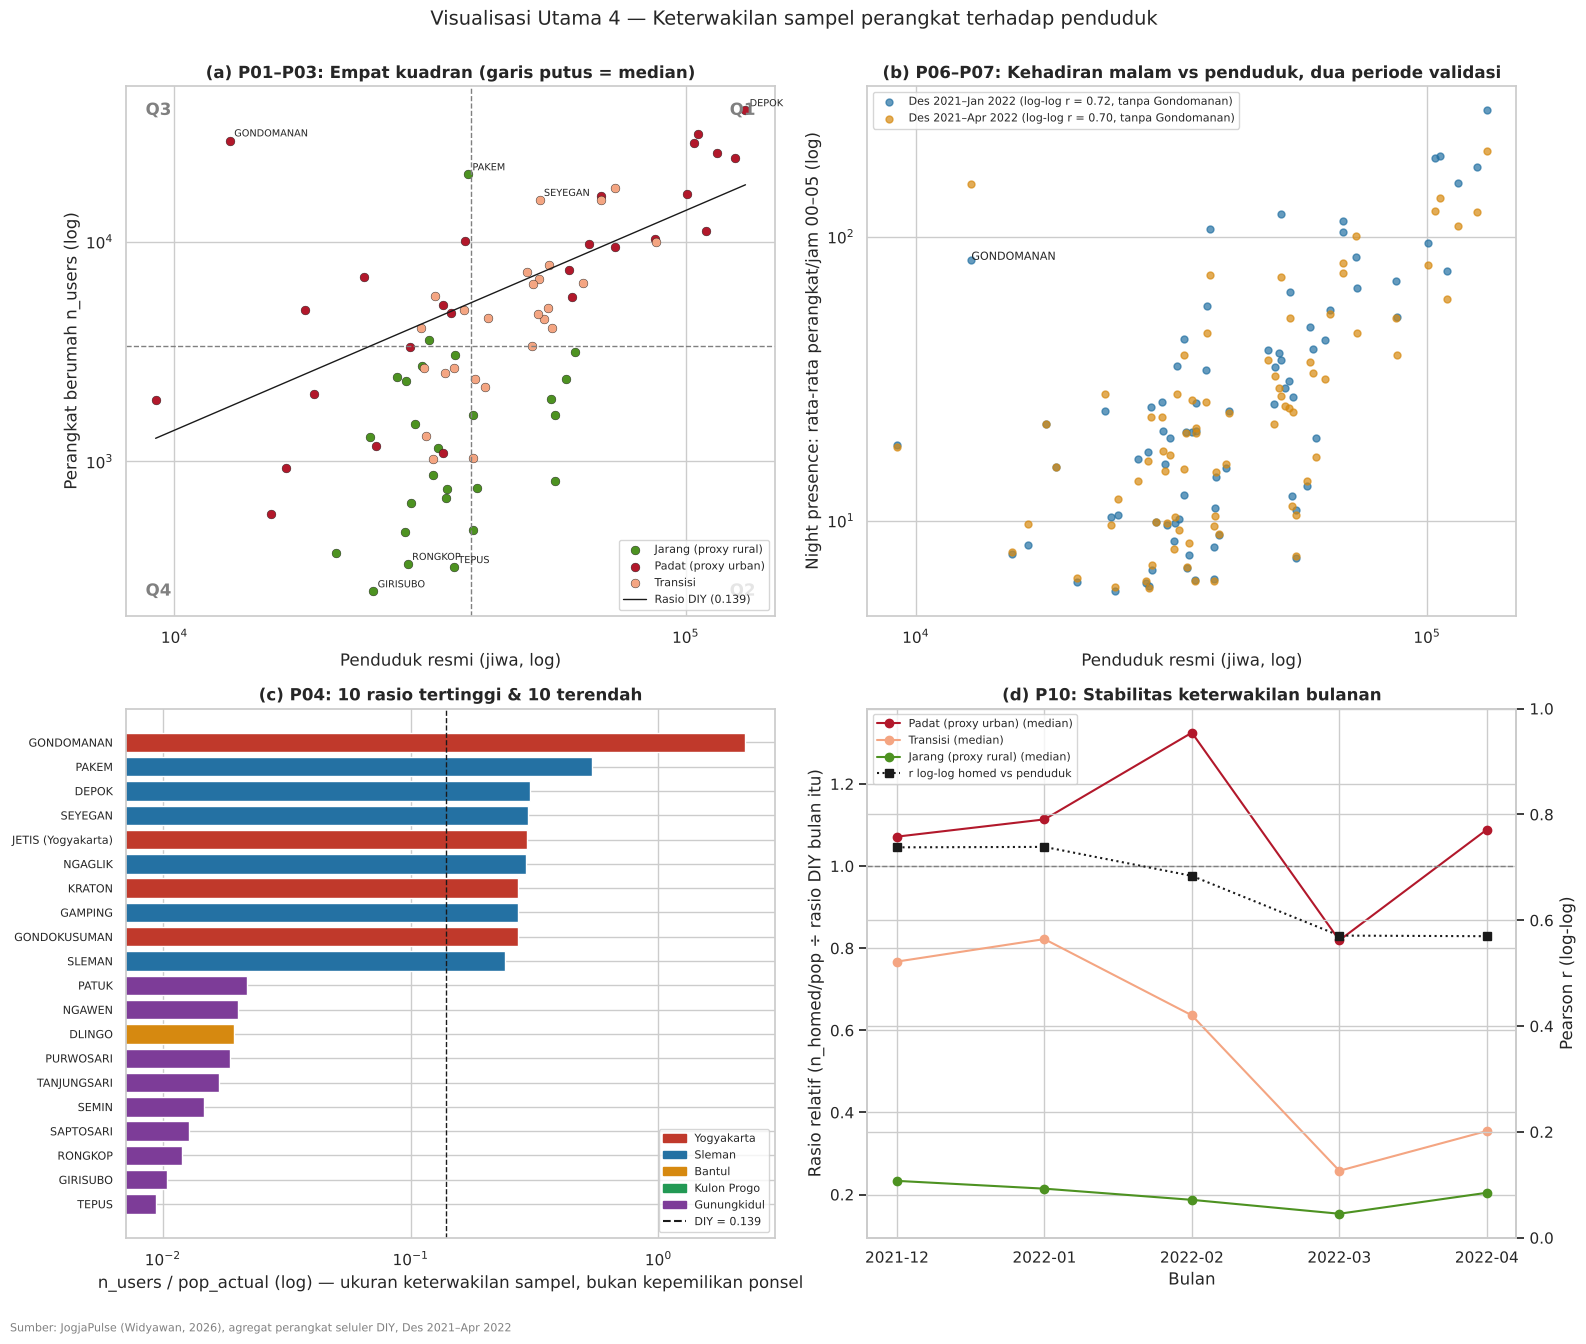

In [67]:
fig, axes = plt.subplots(2, 2, figsize=(16, 13))
class_palette = dict(zip(URBAN_ORDER, ["#b2182b", "#f4a582", "#4d9221", "#b2182b", "#4d9221"]))
# (a) kuadran
ax = axes[0, 0]
for cls, g in rep.groupby("urban_rural"):
    ax.scatter(g.pop_actual, g.n_users, s=40, color=class_palette.get(cls, "gray"), label=cls, edgecolor="k", lw=0.3)
ax.axvline(pop_med, color="gray", ls="--", lw=1)
ax.axhline(users_med, color="gray", ls="--", lw=1)
xs = np.logspace(np.log10(rep.pop_actual.min()), np.log10(rep.pop_actual.max()), 50)
ax.plot(xs, xs * diy_ratio, color="k", lw=1, label=f"Rasio DIY ({diy_ratio:.3f})")
for code in list(ratio_rank.index[:4]) + list(ratio_rank.index[-3:]):
    ax.annotate(LABEL[code], (rep.loc[code, "pop_actual"], rep.loc[code, "n_users"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set(xscale="log", yscale="log", xlabel="Penduduk resmi (jiwa, log)", ylabel="Perangkat berumah n_users (log)",
       title="(a) P01–P03: Empat kuadran (garis putus = median)")
for txt, x, y in [("Q1", 0.97, 0.97), ("Q2", 0.97, 0.03), ("Q3", 0.03, 0.97), ("Q4", 0.03, 0.03)]:
    ax.text(x, y, txt, transform=ax.transAxes, ha="right" if x > 0.5 else "left", va="top" if y > 0.5 else "bottom", fontsize=12, color="gray", weight="bold")
ax.legend(fontsize=8, loc="lower right")
# (b) night presence
ax = axes[0, 1]
for col, color, name in [("night_presence_decjan", "#2471a3", "Des 2021–Jan 2022"), ("night_presence_full", "#d68910", "Des 2021–Apr 2022")]:
    sub = rep.drop(index=GONDOMANAN)
    r = stats.pearsonr(np.log10(sub.pop_actual), np.log10(sub[col]))[0]
    ax.scatter(rep.pop_actual, rep[col], s=25, color=color, alpha=0.7, label=f"{name} (log-log r = {r:.2f}, tanpa Gondomanan)")
ax.annotate("GONDOMANAN", (rep.loc[GONDOMANAN, "pop_actual"], rep.loc[GONDOMANAN, "night_presence_decjan"]), fontsize=8)
ax.set(xscale="log", yscale="log", xlabel="Penduduk resmi (jiwa, log)", ylabel="Night presence: rata-rata perangkat/jam 00–05 (log)",
       title="(b) P06–P07: Kehadiran malam vs penduduk, dua periode validasi")
ax.legend(fontsize=8)
# (c) ranking rasio
ax = axes[1, 0]
sel = pd.concat([ratio_rank.head(10), ratio_rank.tail(10)])
ax.barh(sel.label[::-1], sel.ratio[::-1], color=[KAB_COLORS[k] for k in sel.kab_kota[::-1]])
ax.axvline(diy_ratio, color="k", ls="--", lw=1, label=f"DIY = {diy_ratio:.3f}")
ax.set(xscale="log", xlabel="n_users / pop_actual (log) — ukuran keterwakilan sampel, bukan kepemilikan ponsel",
       title="(c) P04: 10 rasio tertinggi & 10 terendah")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in KAB_COLORS.values()] + [plt.Line2D([], [], color="k", ls="--")],
          labels=[k.title() for k in KAB_COLORS] + [f"DIY = {diy_ratio:.3f}"], fontsize=8, loc="lower right")
ax.tick_params(axis="y", labelsize=8)
# (d) stabilitas bulanan
ax = axes[1, 1]
for cls in URBAN_ORDER:
    codes = rep.index[rep.urban_rural == cls]
    ax.plot(relative_ratio.columns, relative_ratio.loc[codes].median(), marker="o", color=class_palette[cls], label=f"{cls} (median)")
ax.axhline(1, color="gray", ls="--", lw=1)
ax2 = ax.twinx()
ax2.plot(monthly_pop_corr.index, monthly_pop_corr.pearson_loglog_tanpa_Gondomanan, "k:", marker="s", label="r log-log homed vs penduduk")
ax2.set_ylabel("Pearson r (log-log)")
ax2.set_ylim(0, 1)
ax.set(xlabel="Bulan", ylabel="Rasio relatif (n_homed/pop ÷ rasio DIY bulan itu)", title="(d) P10: Stabilitas keterwakilan bulanan")
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, fontsize=8, loc="upper left")
fig.suptitle("Visualisasi Utama 4 — Keterwakilan sampel perangkat terhadap penduduk", y=1.0)
fig.tight_layout()
save_fig(fig, "V4_population_representativeness")
plt.show()

### 6.x Interpretasi Section 6

- **Replikasi validasi README berhasil.** Tanpa Gondomanan, night presence vs penduduk: Pearson linear ≈ 0,82 dan log-log ≈ 0,70 (README: 0,83 dan 0,70); dengan Gondomanan log-log turun ke ≈ 0,60 (README: 0,60). Night presence vs perangkat berumah log-log ≈ 0,98 (README: 0,98). Ini menegaskan bahwa pemrosesan data di notebook konsisten dengan pembuat dataset.
- **Elastisitas > 1.** Kemiringan log-log `n_users` terhadap penduduk ≈ 1,6 (CI 95% ±1,2–2,0): kapanewon berpenduduk besar (yang juga padat dan urban) **lebih terwakili** secara tidak proporsional. Jadi sampel perangkat bias ke kawasan urban.
- **Kuadran.** Q1 (penduduk & perangkat tinggi) didominasi Bantul dan Sleman; Q2 (penduduk tinggi, perangkat rendah) didominasi Gunungkidul (7 dari 11); Q3 (penduduk rendah, perangkat tinggi) adalah kemantren Kota Yogyakarta dan Sleman utara (Pakem, Turi, Cangkringan); Q4 didominasi Gunungkidul dan Kulon Progo.
- **Rasio keterwakilan** berkisar 240× (Gondomanan 2,25 vs Tepus 0,009); tanpa Gondomanan masih 58×. Rasio tinggi Pakem (0,54), Seyegan (0,30), dan Gamping (0,27) kemungkinan ikut terdongkrak artefak sel kisi 0,1° (lokasi malam berpresisi rendah ikut dihitung sebagai "rumah"), dan Gondomanan oleh anomali titik konstan.
- **Urban vs rural.** Kelas padat memiliki rasio gabungan ≈ 1,46× rasio DIY, kelas jarang ≈ 0,43× (Kruskal–Wallis p < 0,001; Spearman kepadatan vs rasio ≈ 0,67).
- **Cakupan malam rendah** terkonsentrasi di Gunungkidul (median 32% slot malam terpublikasi), terburuk Girisubo (3,2%) dan Rongkop (4,7%). Ngampilan adalah satu-satunya kemantren kota dengan cakupan rendah (33%) — wilayahnya sangat kecil (< 1 km²).
- **Stabilitas bulanan.** Rasio relatif antarbulan sangat stabil dalam Des–Feb (Spearman 0,92–0,97; median CV 0,17) tetapi melemah tajam ketika Maret–April dimasukkan (Spearman 0,64–0,78; median CV 0,39), sejalan dengan README.

In [68]:
p_ds = "home_maids_vs_population; validation_night_presence; od_origin_homes_monthly"
add_insight("P01", "Wilayah dengan penduduk tinggi dan perangkat tinggi", p_ds, "pop_actual, n_users",
            "Quadrant analysis (median)", "pop ≥ median ∧ n_users ≥ median", "V4(a)", "completed",
            f"{(rep.quadrant.str.startswith('Q1')).sum()} kapanewon, mis. {', '.join(rep[rep.quadrant.str.startswith('Q1')].sort_values('n_users', ascending=False).label.head(8))}.",
            "Kapanewon besar di koridor aglomerasi Sleman–Bantul menjadi tulang punggung sampel.",
            "Batas median bersifat relatif; perangkat = rumah periode penuh.")
add_insight("P02", "Wilayah dengan penduduk tinggi tetapi perangkat rendah", p_ds, "pop_actual, n_users",
            "Quadrant analysis (median)", "pop ≥ median ∧ n_users < median", "V4(a)", "completed",
            f"{(rep.quadrant.str.startswith('Q2')).sum()} kapanewon: {', '.join(rep[rep.quadrant.str.startswith('Q2')].label)}.",
            "Gunungkidul dan pinggiran selatan-barat kurang terwakili; analisis di wilayah ini paling rentan bias.",
            "Penyebab (kepemilikan ponsel, penggunaan aplikasi, sinyal) tidak dapat dipisahkan.")
add_insight("P03", "Wilayah dengan penduduk rendah tetapi perangkat tinggi", p_ds, "pop_actual, n_users",
            "Quadrant analysis (median)", "pop < median ∧ n_users ≥ median", "V4(a)", "completed",
            f"{(rep.quadrant.str.startswith('Q3')).sum()} kapanewon: {', '.join(rep[rep.quadrant.str.startswith('Q3')].label)}.",
            "Kemantren inti kota dan Sleman utara: kemungkinan penghuni tidak tercatat (mahasiswa, pekerja kos), pengunjung menginap, dan/atau artefak lokasi.",
            "Gondomanan & Pakem dicurigai terdampak artefak data.")
add_insight("P04", "Rasio perangkat terhadap populasi tertinggi dan terendah", p_ds, "n_users, pop_actual, ratio",
            "Representativeness ratio", "n_users / pop_actual", "V4(c)", "completed",
            f"Tertinggi: {fmt_list(ratio_rank.set_index('label').ratio, 5, '{:.3f}')}. Terendah: {fmt_list(ratio_rank.set_index('label').ratio.iloc[::-1], 5, '{:.4f}')}. DIY = {diy_ratio:.3f}.",
            "Keterwakilan sampel sangat timpang (58× tanpa Gondomanan); hasil per kapanewon perlu dibaca sebagai indikator sampel, bukan penduduk.",
            "Rasio adalah keterwakilan sampel, bukan persentase penduduk pemilik ponsel.")
add_insight("P05", "Hubungan jumlah penduduk dan jumlah perangkat", p_ds, "pop_actual, n_users",
            "Pearson, Spearman, OLS log-log", "r; log10(n_users) = a + b·log10(pop)", "V4(a)", "completed",
            f"Tanpa Gondomanan: Pearson {corr_table.iloc[3].pearson_linear:.2f}, Spearman {corr_table.iloc[3].spearman:.2f}, log-log {corr_table.iloc[3].pearson_loglog:.2f}; "
            f"elastisitas {ols_users.params['log_pop']:.2f} (R² {ols_users.rsquared:.2f}).",
            "Hubungan positif kuat, tetapi elastisitas > 1: kapanewon besar/urban lebih terwakili.",
            "n = 77; tahun data penduduk tidak diketahui; hubungan bukan kausal.")
add_insight("P06", "Hubungan jumlah penduduk dengan night presence", p_ds, "night_presence, pop_actual",
            "Pearson/Spearman, OLS log-log", "r(night_presence, pop)", "V4(b)", "completed",
            f"Des–Apr tanpa Gondomanan: Pearson {corr_table.iloc[4].pearson_linear:.2f}, log-log {corr_table.iloc[4].pearson_loglog:.2f}; dengan Gondomanan log-log {corr_table.iloc[1].pearson_loglog:.2f}. "
            f"Night presence vs n_users log-log ≈ 0,98.",
            "Mereplikasi validasi README: produk hourly menangkap sebaran penduduk malam dengan baik secara peringkat.",
            "Night presence rural dihitung dari sedikit slot.")
add_insight("P07", "Konsistensi hubungan populasi dan night presence pada dua periode validasi", p_ds, "night_presence (2 periode)",
            "Perbandingan korelasi antarperiode; korelasi antarperiode", "r_DesJan vs r_DesApr", "V4(b)", "completed",
            f"Log-log r vs penduduk (tanpa Gondomanan): Des–Jan {corr_table.iloc[5].pearson_loglog:.2f}, Des–Apr {corr_table.iloc[4].pearson_loglog:.2f}. "
            f"Antarperiode: Spearman {p07['spearman_rho']:.2f}. Pergeseran peringkat terbesar: Gondomanan (12→2), Seyegan (6→12), Tegalrejo (42→30).",
            "Hubungan konsisten; perubahan peringkat terbesar terjadi di kapanewon yang terdampak anomali/artefak.",
            "Periode Des–Apr memuat Des–Jan (tidak independen).")
add_insight("P08", "Wilayah dengan cakupan pengamatan malam rendah", "validation_night_presence", "slots_published_pct",
            "Ranking cakupan slot malam; korelasi dengan kepadatan", "% slot 00–05 terpublikasi", "V4, V8", "completed",
            f"{(rep.night_slots_pct_full < 50).sum()} kapanewon < 50% (Des–Apr). Terendah: {fmt_list(low_night.set_index('label').night_slots_pct_full, 5, '{:.1f}')} (%). "
            f"Spearman kepadatan vs cakupan = {cov_density['spearman_rho']:.2f}.",
            "Gunungkidul hampir 'buta' pada malam hari dalam data publik; analisis malam di sana tidak andal.",
            "Cakupan memburuk pada Mar–Apr.")
add_insight("P09", "Perbedaan keterwakilan perangkat antara urban dan rural", p_ds, "ratio, density",
            f"Rasio gabungan per kelas ({URBAN_SOURCE}); Kruskal–Wallis", "Σn_users/Σpop per kelas ÷ rasio DIY", "V4(a)", "completed",
            "; ".join(f"{c}: {r.pooled_ratio:.3f} ({r.pooled_ratio_vs_diy:.2f}× DIY)" for c, r in class_rep.iterrows()) + f"; Kruskal–Wallis p = {kw_rep.pvalue:.1e}.",
            "Sampel ±3,4× lebih padat (per penduduk) di kawasan padat dibanding kawasan jarang.",
            "Klasifikasi adalah proxy kepadatan.")
add_insight("P10", "Stabilitas keterwakilan perangkat dari bulan ke bulan", "od_origin_homes_monthly; home_maids_vs_population", "n_homed_maids, pop_actual",
            "Rasio relatif bulanan; Spearman antarbulan; CV", "(n_homed/pop) ÷ rasio DIY bulan itu", "V4(d)", "completed",
            f"Spearman Des–Jan {p10_rank.loc['2021-12', '2022-01']:.2f}, Des–Feb {p10_rank.loc['2021-12', '2022-02']:.2f}, Des–Apr {p10_rank.loc['2021-12', '2022-04']:.2f}; "
            f"r linear homed vs penduduk: {', '.join(f'{m} {v:.2f}' for m, v in monthly_pop_corr.pearson_linear_tanpa_Gondomanan.items())}.",
            "Keterwakilan stabil dalam Des–Feb dan memburuk di Mar–Apr, mendukung pembatasan analisis kuantitatif ke periode HQ.",
            "Definisi rumah bulanan berbeda dari n_users.")

---
## Section 7 — Daily & Monthly Dynamics (D01–D08)

Prinsip: **angka mentah dan angka ternormalisasi ditampilkan berdampingan**, dan penurunan jumlah perangkat **tidak** ditafsirkan sebagai penurunan mobilitas penduduk.

Metrik harian per kapanewon: `daily_share` = rata-rata `share_lb` 24 jam pada hari itu (porsi kapanewon dari aktivitas DIY hari itu).

In [69]:
daily_share = panel.groupby(["date", "kapanewon_code"]).share_lb.mean().unstack() * 100      # tanggal × kapanewon, %
daily_raw = (panel.groupby(["date", "kapanewon_code"]).n_maids.sum().unstack())               # device-hours mentah
print("Bentuk matriks harian:", daily_share.shape, "| jumlah pangsa per hari ≈", round(daily_share.sum(axis=1).mean(), 1), "%")

Bentuk matriks harian: (151, 78) | jumlah pangsa per hari ≈ 100.0 %


### D01 — Hari dengan aktivitas tertinggi dan terendah
Tiga sudut pandang: (1) device-hours mentah, (2) indeks terdetrend (device-hours ÷ rata-rata bergerak 7 hari terpusat, dihitung di Section 5), (3) hanya periode HQ.

In [70]:
d01 = pd.DataFrame({
    "device_hours": daily_quality.device_hours, "index_detrended": daily_index["index"],
    "day_type": np.select([daily_quality.index.isin(list(ID_HOLIDAYS)), daily_quality.index.dayofweek >= 5], ["Libur nasional", "Akhir pekan"], "Hari kerja"),
    "dow": daily_quality.index.dayofweek.map(dict(enumerate(DOW_NAMES))),
})
print("Device-hours mentah tertinggi:")
display(d01.sort_values("device_hours", ascending=False).head(5))
print("Device-hours mentah terendah:")
display(d01.sort_values("device_hours").head(5))
print("Indeks terdetrend tertinggi (relatif terhadap minggunya):")
display(d01.dropna().sort_values("index_detrended", ascending=False).head(6))
print("Indeks terdetrend terendah:")
display(d01.dropna().sort_values("index_detrended").head(6))

Device-hours mentah tertinggi:


,device_hours,index_detrended,day_type,dow
date,,,,
2022-02-06,"273,473.0000",1.1619,Akhir pekan,Minggu
2021-12-07,"267,119.0000",1.2027,Hari kerja,Selasa
2022-02-07,"254,114.0000",1.1035,Hari kerja,Senin
2021-12-06,"242,574.0000",1.0848,Hari kerja,Senin
2021-12-30,"240,158.0000",1.2503,Hari kerja,Kamis


Device-hours mentah terendah:


,device_hours,index_detrended,day_type,dow
date,,,,
2022-04-03,"15,572.0000",0.7604,Akhir pekan,Minggu
2022-03-08,"15,706.0000",0.5235,Hari kerja,Selasa
2022-04-19,"17,254.0000",0.7115,Hari kerja,Selasa
2022-04-06,"17,734.0000",0.9443,Hari kerja,Rabu
2022-04-07,"18,711.0000",0.9654,Hari kerja,Kamis


Indeks terdetrend tertinggi (relatif terhadap minggunya):


,device_hours,index_detrended,day_type,dow
date,,,,
2022-03-18,"45,540.0000",1.3731,Hari kerja,Jumat
2022-02-19,"112,307.0000",1.3549,Akhir pekan,Sabtu
2022-02-15,"205,599.0000",1.3415,Hari kerja,Selasa
2021-12-30,"240,158.0000",1.2503,Hari kerja,Kamis
2022-03-10,"33,426.0000",1.2028,Hari kerja,Kamis
2021-12-07,"267,119.0000",1.2027,Hari kerja,Selasa


Indeks terdetrend terendah:


,device_hours,index_detrended,day_type,dow
date,,,,
2022-03-08,"15,706.0000",0.5235,Hari kerja,Selasa
2022-02-16,"82,879.0000",0.5819,Hari kerja,Rabu
2022-04-19,"17,254.0000",0.7115,Hari kerja,Selasa
2022-01-02,"116,516.0000",0.7358,Akhir pekan,Minggu
2022-02-21,"52,155.0000",0.7390,Hari kerja,Senin
2022-01-01,"126,943.0000",0.7484,Libur nasional,Sabtu


### D02 — Perubahan konsentrasi perangkat selama lima bulan
Konsentrasi harian diukur dengan **Gini antar-kapanewon**, **Gini antar-sel grid (tanpa sel kisi)**, dan **porsi 10 kapanewon teratas**. Karena ini berbasis pangsa, ukuran tidak terpengaruh langsung oleh besar-kecilnya sampel.

In [71]:
conc = pd.DataFrame({
    "gini_kapanewon": daily_share.apply(gini, axis=1),
    "top10_share_pct": daily_share.apply(lambda r: r.sort_values(ascending=False).head(10).sum(), axis=1),
    "gini_cells_clean": cells_daily[~cells_daily.lattice_0_1deg].groupby("date").n_maids.apply(
        lambda s: gini(np.concatenate([s.values, np.zeros(len(cells) - n_lattice - len(s))]))),
    "cells_published": cells_daily.groupby("date").size(),
})
conc["month"] = conc.index.strftime("%Y-%m")
conc_monthly = conc.groupby("month")[["gini_kapanewon", "top10_share_pct", "gini_cells_clean", "cells_published"]].mean()
display(conc_monthly.round(3))
print("Spearman tren Gini kapanewon vs waktu (HQ):",
      round(stats.spearmanr(np.arange(len(conc.loc[:HQ_END])), conc.loc[:HQ_END, "gini_kapanewon"])[0], 3))

,gini_kapanewon,top10_share_pct,gini_cells_clean,cells_published
month,,,,
2021-12,0.5780,49.2170,0.9210,"1,563.8710"
2022-01,0.5570,46.7040,0.8970,"1,771.3870"
2022-02,0.5760,49.8430,0.8850,"1,888.5360"
2022-03,0.5900,50.9450,0.9670,519.8390
2022-04,0.6710,56.6060,0.9780,372.0330


Spearman tren Gini kapanewon vs waktu (HQ): -0.103


### D03 & D04 — Tren aktivitas meningkat dan menurun
**Metode:** untuk setiap kapanewon, regresi linear `daily_share ~ hari ke-t` pada periode HQ (90 hari). Kemiringan dilaporkan dalam **poin persen per 30 hari**. Karena data harian saling berkorelasi (autokorelasi), *standard error* dihitung dengan koreksi **Newey–West (HAC, lag 7)** agar p-value tidak terlalu optimis.

**Keterbatasan:** tren linear dapat dipengaruhi patahan sampel (16 Feb) dan artefak (sel kisi menghilang pada akhir Januari). Kapanewon yang memuat sel kisi ditandai.

In [72]:
def linear_trend(series, hac_lags=7):
    y = series.dropna()
    X = sm.add_constant(np.arange(len(y)))
    model = sm.OLS(y.values, X).fit(cov_type="HAC", cov_kwds={"maxlags": hac_lags})
    return pd.Series({"slope_pp_per_30d": model.params[1] * 30, "p_value": model.pvalues[1], "mean_share": y.mean()})


trend_hq = daily_share.loc[HQ_START:HQ_END].apply(linear_trend).T
trend_hq["rel_slope_pct_per_30d"] = trend_hq.slope_pp_per_30d / trend_hq.mean_share * 100
trend_hq = trend_hq.join(LABEL).join(KAB_OF).join(kap_hq[["lattice_share_of_grid_pct"]] if "lattice_share_of_grid_pct" in kap_hq else pd.DataFrame(index=trend_hq.index))
trend_hq["artefak_kisi"] = trend_hq.get("lattice_share_of_grid_pct", 0) > 10
trend_hq["artefak_kisi"] |= trend_hq.index == GONDOMANAN
sig = trend_hq[trend_hq.p_value < 0.05]
print(f"Tren signifikan (p<0,05, HAC): naik {(sig.slope_pp_per_30d > 0).sum()}, turun {(sig.slope_pp_per_30d < 0).sum()} dari 78")
cols = ["label", "kab_kota", "mean_share", "slope_pp_per_30d", "rel_slope_pct_per_30d", "p_value", "artefak_kisi"]
print("D03 — tren naik terbesar (signifikan):")
display(sig.sort_values("slope_pp_per_30d", ascending=False)[cols].head(8))
print("D04 — tren turun terbesar (signifikan):")
display(sig.sort_values("slope_pp_per_30d")[cols].head(8))
save_table(trend_hq.reset_index(), "D03_D04_trends_HQ")

Tren signifikan (p<0,05, HAC): naik 16, turun 21 dari 78
D03 — tren naik terbesar (signifikan):


,label,kab_kota,mean_share,slope_pp_per_30d,rel_slope_pct_per_30d,p_value,artefak_kisi
kapanewon_code,,,,,,,
34.04.07,DEPOK,SLEMAN,8.3919,1.4738,17.5618,0.0000,False
34.04.06,MLATI,SLEMAN,3.4807,0.7869,22.6083,0.0000,False
34.71.02,JETIS (Yogyakarta),YOGYAKARTA,1.0620,0.4574,43.0642,0.0000,False
34.71.03,GONDOKUSUMAN,YOGYAKARTA,2.0222,0.4556,22.5290,0.0000,False
34.71.13,UMBULHARJO,YOGYAKARTA,3.3207,0.4089,12.3138,0.0006,False
34.71.08,MANTRIJERON,YOGYAKARTA,0.4765,0.3447,72.3467,0.0000,False
34.02.15,SEWON,BANTUL,2.5579,0.3251,12.7092,0.0004,False
34.71.01,TEGALREJO,YOGYAKARTA,0.7683,0.2885,37.5496,0.0000,False


D04 — tren turun terbesar (signifikan):


,label,kab_kota,mean_share,slope_pp_per_30d,rel_slope_pct_per_30d,p_value,artefak_kisi
kapanewon_code,,,,,,,
34.04.05,SEYEGAN,SLEMAN,2.9733,-2.0726,-69.7074,0.0000,True
34.04.01,GAMPING,SLEMAN,5.4844,-1.5384,-28.0504,0.0000,True
34.04.16,PAKEM,SLEMAN,2.9872,-1.0247,-34.3040,0.0044,True
34.04.14,TEMPEL,SLEMAN,1.7766,-0.4180,-23.5295,0.0015,False
34.04.11,NGEMPLAK,SLEMAN,3.0947,-0.3847,-12.4294,0.0203,False
34.02.10,IMOGIRI,BANTUL,1.2497,-0.2945,-23.5640,0.0000,False
34.02.09,JETIS (Bantul),BANTUL,1.4427,-0.2742,-19.0046,0.0001,False
34.03.01,WONOSARI,GUNUNGKIDUL,1.7999,-0.1867,-10.3715,0.0050,False


Tabel disimpan: outputs/tables/D03_D04_trends_HQ.csv


### D05 — Wilayah dengan fluktuasi aktivitas paling tinggi
*Coefficient of variation* (CV) pangsa harian selama periode HQ. CV tinggi = porsi kapanewon naik-turun tajam dari hari ke hari. Dibandingkan pula CV setelah tren dihilangkan (residual terhadap rata-rata bergerak 7 hari) agar tren jangka panjang tidak dihitung sebagai fluktuasi.

In [73]:
hq_share = daily_share.loc[HQ_START:HQ_END]
fluct = pd.DataFrame({
    "cv_daily_share": hq_share.std() / hq_share.mean(),
    "cv_detrended": (hq_share / hq_share.rolling(7, center=True, min_periods=4).mean()).std(),
    "mean_share": hq_share.mean(), "coverage_pct": kap_hq.coverage_pct,
}).join(LABEL).join(KAB_OF)
fluct["artefak"] = trend_hq.artefak_kisi
fluct_rho = corr_report(np.log10(fluct.mean_share), fluct.cv_detrended)
print(f"Spearman log pangsa vs CV terdetrend: {fluct_rho['spearman_rho']:.3f} (kapanewon kecil lebih fluktuatif?)")
display(fluct.sort_values("cv_daily_share", ascending=False).head(10))
print("Paling stabil:")
display(fluct.sort_values("cv_daily_share").head(5))

Spearman log pangsa vs CV terdetrend: -0.631 (kapanewon kecil lebih fluktuatif?)


,cv_daily_share,cv_detrended,mean_share,coverage_pct,label,kab_kota,artefak
kapanewon_code,,,,,,,
34.71.06,0.9300,0.4368,0.1696,67.9167,NGAMPILAN,YOGYAKARTA,False
34.71.10,0.9071,0.2008,2.0759,100.0000,GONDOMANAN,YOGYAKARTA,True
34.71.08,0.7488,0.2402,0.4765,93.8889,MANTRIJERON,YOGYAKARTA,False
34.04.05,0.7334,0.1870,2.9733,99.5370,SEYEGAN,SLEMAN,True
34.03.14,0.7238,0.1775,0.3565,93.1481,GEDANGSARI,GUNUNGKIDUL,True
34.71.05,0.7230,0.2934,0.2696,86.7593,GEDONGTENGEN,YOGYAKARTA,False
34.71.07,0.6927,0.2155,0.3619,92.4074,WIROBRAJAN,YOGYAKARTA,False
34.04.16,0.6801,0.2910,2.9872,99.9537,PAKEM,SLEMAN,True
34.03.16,0.6703,0.5935,0.0286,33.0093,GIRISUBO,GUNUNGKIDUL,False


Paling stabil:


,cv_daily_share,cv_detrended,mean_share,coverage_pct,label,kab_kota,artefak
kapanewon_code,,,,,,,
34.02.12,0.0832,0.0588,5.6237,100.0000,BANGUNTAPAN,BANTUL,True
34.02.17,0.1237,0.0684,1.2159,100.0000,SEDAYU,BANTUL,False
34.02.08,0.1540,0.1063,1.8885,100.0000,BANTUL,BANTUL,False
34.03.09,0.1635,0.1071,0.3274,94.3056,KARANGMOJO,GUNUNGKIDUL,True
34.04.02,0.1700,0.1031,2.0476,99.9537,GODEAN,SLEMAN,False


### D06 — Anomali pada tanggal tertentu (dan sel tertentu)
1. **Anomali harian:** *robust z-score* dari log device-hours terhadap median bergerak 7 hari, memakai MAD (*median absolute deviation*) yang tahan pencilan. |z| > 3,5 ditandai anomali.
2. **Change-point detection:** *binary segmentation* sederhana pada log device-hours — mencari titik yang paling mengurangi galat jika rata-rata sebelum/sesudahnya dibuat berbeda, diulang selama penurunan galat melewati penalti BIC. Ini mendeteksi **patahan level** (perubahan sampel), bukan lonjakan satu hari.
3. **Sel "lengket":** sel yang jumlah perangkatnya tidak ikut turun ketika sampel DIY menyusut (rasio Mar–Apr ÷ Des–Jan jauh di atas rasio DIY).

In [74]:
log_dh = np.log(daily_quality.device_hours)
resid = log_dh - log_dh.rolling(7, center=True, min_periods=4).median()
mad = (resid - resid.median()).abs().median()
robust_z = 0.6745 * (resid - resid.median()) / mad
anomalies = daily_quality.assign(robust_z=robust_z)[robust_z.abs() > 3.5][["device_hours", "dod_change_pct", "robust_z"]]
print("Anomali harian (|robust z| > 3,5):")
display(anomalies)


def binary_segmentation(y, min_size=7, max_cp=6):
    """Deteksi patahan rata-rata secara greedy; berhenti jika BIC tidak membaik."""
    y = np.asarray(y, dtype=float)
    n = len(y)
    cps = []

    def sse(segment):
        return ((segment - segment.mean()) ** 2).sum() if len(segment) else 0.0

    def total_sse(points):
        bounds = [0] + sorted(points) + [n]
        return sum(sse(y[a:b]) for a, b in zip(bounds[:-1], bounds[1:]))

    def bic(points):
        return n * np.log(total_sse(points) / n) + (2 * len(points) + 1) * np.log(n)

    current_bic = bic(cps)
    while len(cps) < max_cp:
        best = None
        for t in range(min_size, n - min_size):
            if any(abs(t - c) < min_size for c in cps):
                continue
            cand = bic(cps + [t])
            if best is None or cand < best[1]:
                best = (t, cand)
        if best is None or best[1] >= current_bic:
            break
        cps.append(best[0])
        current_bic = best[1]
    return sorted(cps)


cp_idx = binary_segmentation(log_dh.values)
change_points = log_dh.index[cp_idx]
segments = pd.DataFrame({"mulai": [log_dh.index[0]] + list(change_points), "selesai": list(change_points - pd.Timedelta(days=1)) + [log_dh.index[-1]]})
segments["rata2_device_hours"] = [daily_quality.device_hours.loc[a:b].mean() for a, b in zip(segments.mulai, segments.selesai)]
print("Change-point (awal segmen baru):", [d.date().isoformat() for d in change_points])
display(segments)

Anomali harian (|robust z| > 3,5):


,device_hours,dod_change_pct,robust_z
date,,,
2021-12-01,"104,064.0000",NaN,-10.9778
2021-12-07,"267,119.0000",10.1186,3.7836
2022-01-05,"158,726.0000",32.0087,3.7482
2022-01-23,"124,568.0000",-9.7954,-4.1317
2022-02-16,"82,879.0000",-59.6890,-6.6391
2022-02-19,"112,307.0000",-8.7224,5.1056
2022-03-08,"15,706.0000",-47.9555,-11.3620
2022-03-18,"45,540.0000",38.4826,5.8954
2022-04-03,"15,572.0000",-33.9974,-4.2436


Change-point (awal segmen baru): ['2022-01-01', '2022-01-24', '2022-02-13', '2022-02-20', '2022-03-06', '2022-03-29']


,mulai,selesai,rata2_device_hours
0,2021-12-01,2021-12-31,"207,905.9032"
1,2022-01-01,2022-01-23,"133,345.6957"
2,2022-01-24,2022-02-12,"198,148.9500"
3,2022-02-13,2022-02-19,"142,436.0000"
4,2022-02-20,2022-03-05,"45,786.9286"
5,2022-03-06,2022-03-28,"30,693.4783"
6,2022-03-29,2022-04-30,"23,409.9394"


In [75]:
early = cells_daily[cells_daily.date <= "2022-01-31"].groupby("cell_id").n_maids.sum() / cells_daily[cells_daily.date <= "2022-01-31"].date.nunique()
late = cells_daily[cells_daily.date >= "2022-03-01"].groupby("cell_id").n_maids.sum() / cells_daily[cells_daily.date >= "2022-03-01"].date.nunique()
diy_late_early = cells_daily[cells_daily.date >= "2022-03-01"].n_maids.sum() / cells_daily[cells_daily.date >= "2022-03-01"].date.nunique() / (
    cells_daily[cells_daily.date <= "2022-01-31"].n_maids.sum() / cells_daily[cells_daily.date <= "2022-01-31"].date.nunique())
sticky = pd.DataFrame({"mean_early": early, "mean_late": late.reindex(early.index).fillna(0)})
sticky["ratio_late_early"] = sticky.mean_late / sticky.mean_early
sticky["relative_to_diy"] = sticky.ratio_late_early / diy_late_early
sticky = sticky[sticky.mean_early >= 200].join(cells.set_index("cell_id")[["centroid_lat", "centroid_lon", "lattice_0_1deg"] + (["kapanewon_code"] if HAS_BOUNDARY else [])])
if HAS_BOUNDARY:
    sticky["kapanewon"] = sticky.kapanewon_code.map(LABEL)
print(f"Rasio rata-rata harian grid DIY (Mar–Apr ÷ Des–Jan): {diy_late_early:.3f}")
print("Sel besar (≥200 perangkat/hari di Des–Jan) yang paling tidak ikut turun:")
sticky_top = sticky.sort_values("relative_to_diy", ascending=False)
display(sticky_top.head(6))
print(f"Median relative_to_diy sel besar: {sticky.relative_to_diy.median():.2f}")

Rasio rata-rata harian grid DIY (Mar–Apr ÷ Des–Jan): 0.108
Sel besar (≥200 perangkat/hari di Des–Jan) yang paling tidak ikut turun:


,mean_early,mean_late,ratio_late_early,relative_to_diy,centroid_lat,centroid_lon,lattice_0_1deg,kapanewon_code,kapanewon
cell_id,,,,,,,,,
E859_N18274,901.1129,"1,606.3607",1.7826,16.4912,-7.8046,110.3628,False,34.71.10,GONDOMANAN
E857_N18294,516.5968,655.4426,1.2688,11.7374,-7.7141,110.3539,False,34.04.13,SLEMAN
E860_N18274,346.0968,100.4918,0.2904,2.6861,-7.8046,110.3674,False,34.71.09,KRATON
E860_N18278,486.4839,118.2459,0.2431,2.2486,-7.7865,110.3674,False,34.71.02,JETIS (Yogyakarta)
E865_N18278,353.4355,80.4590,0.2276,2.1060,-7.7866,110.3901,False,34.71.03,GONDOKUSUMAN
E860_N18283,436.1613,95.1311,0.2181,2.0177,-7.7639,110.3674,False,34.04.06,MLATI


Median relative_to_diy sel besar: 0.27


### D07 — Apakah penurunan sampel terjadi merata di semua wilayah?
Rasio per kapanewon = device-hours harian rata-rata (slot tersuppress = 0) Mar–Apr ÷ Des–Jan, dibandingkan rasio DIY. Jika penurunan merata, semua kapanewon akan memiliki rasio mendekati rasio DIY.

In [76]:
dh_early = daily_raw.loc[:"2022-01-31"].fillna(0).mean()
dh_late = daily_raw.loc["2022-03-01":].fillna(0).mean()
decline = pd.DataFrame({"dh_early": dh_early, "dh_late": dh_late})
decline["retention_ratio"] = decline.dh_late / decline.dh_early
diy_retention = dh_late.sum() / dh_early.sum()
decline["relative_retention"] = decline.retention_ratio / diy_retention
decline = decline.join(kap_hq[["label", "kab_kota", "urban_rural", "density"]])
print(f"Retensi DIY (Mar–Apr ÷ Des–Jan): {diy_retention:.3f}")
print(f"Retensi kapanewon: min {decline.retention_ratio.min():.3f}, median {decline.retention_ratio.median():.3f}, maks {decline.retention_ratio.max():.3f}; "
      f"CV {decline.retention_ratio.std() / decline.retention_ratio.mean():.2f}")
display(decline.groupby("urban_rural").retention_ratio.describe().loc[URBAN_ORDER][["count", "mean", "50%", "min", "max"]])
display(decline.groupby("kab_kota").retention_ratio.median().loc[KAB_ORDER].to_frame("median_retention"))
kw_decline = stats.kruskal(*[g.retention_ratio.values for _, g in decline.groupby("urban_rural")])
rho_decline = corr_report(np.log10(decline.density), decline.retention_ratio)
print(f"Kruskal–Wallis antar-kelas p = {kw_decline.pvalue:.2e}; Spearman log kepadatan vs retensi = {rho_decline['spearman_rho']:.3f}")
display(decline.sort_values("retention_ratio", ascending=False)[["label", "kab_kota", "retention_ratio", "relative_retention"]].head(6))
display(decline.sort_values("retention_ratio")[["label", "kab_kota", "retention_ratio", "relative_retention"]].head(6))

Retensi DIY (Mar–Apr ÷ Des–Jan): 0.156
Retensi kapanewon: min 0.006, median 0.131, maks 1.238; CV 0.97


,count,mean,50%,min,max
urban_rural,,,,,
Padat (proxy urban),26.0000,0.2680,0.1799,0.0497,1.2382
Transisi,26.0000,0.1179,0.0939,0.0444,0.5339
Jarang (proxy rural),26.0000,0.1610,0.1405,0.0057,0.3983


,median_retention
kab_kota,
YOGYAKARTA,0.2978
SLEMAN,0.1204
BANTUL,0.1205
KULON PROGO,0.1266
GUNUNGKIDUL,0.1301


Kruskal–Wallis antar-kelas p = 4.69e-04; Spearman log kepadatan vs retensi = 0.225


,label,kab_kota,retention_ratio,relative_retention
kapanewon_code,,,,
34.71.10,GONDOMANAN,YOGYAKARTA,1.2382,7.9297
34.71.06,NGAMPILAN,YOGYAKARTA,0.8484,5.4335
34.04.13,SLEMAN,SLEMAN,0.5339,3.4195
34.71.08,MANTRIJERON,YOGYAKARTA,0.4619,2.9581
34.71.07,WIROBRAJAN,YOGYAKARTA,0.4452,2.8512
34.71.05,GEDONGTENGEN,YOGYAKARTA,0.4328,2.7716


,label,kab_kota,retention_ratio,relative_retention
kapanewon_code,,,,
34.03.11,RONGKOP,GUNUNGKIDUL,0.0057,0.0365
34.03.18,PURWOSARI,GUNUNGKIDUL,0.0271,0.1739
34.04.14,TEMPEL,SLEMAN,0.0444,0.2841
34.02.04,PUNDONG,BANTUL,0.0469,0.3002
34.71.11,PAKUALAMAN,YOGYAKARTA,0.0497,0.3182
34.04.03,MOYUDAN,SLEMAN,0.0549,0.3517


### D08 — Perubahan aktivitas akhir pekan dan periode liburan
Tanpa label lokasi wisata, kita mengukur **kapanewon dan sel mana yang pangsanya naik** pada (a) akhir pekan dan (b) periode libur Natal–Tahun Baru (24 Des 2021 – 2 Jan 2022), dibanding hari kerja biasa Des 2021–Jan 2022 di luar periode libur. Uplift > 1 berarti porsinya naik.

In [77]:
HOLIDAY_WINDOW = (pd.Timestamp("2021-12-24"), pd.Timestamp("2022-01-02"))
dj = daily_share.loc["2021-12-01":"2022-01-31"]
in_window = (dj.index >= HOLIDAY_WINDOW[0]) & (dj.index <= HOLIDAY_WINDOW[1])
regular = dj[(~in_window) & (dj.index.dayofweek < 5) & (~dj.index.isin(list(ID_HOLIDAYS)))]
weekend_days = dj[(~in_window) & (dj.index.dayofweek >= 5)]
uplift = pd.DataFrame({
    "holiday_uplift": dj[in_window].mean() / regular.mean(),
    "weekend_uplift": weekend_days.mean() / regular.mean(),
    "regular_share": regular.mean(),
}).join(kap_hq[["label", "kab_kota", "coverage_pct"]])
uplift = uplift[uplift.coverage_pct >= COVERAGE_MIN]
print("Uplift libur Natal–Tahun Baru tertinggi:")
display(uplift.sort_values("holiday_uplift", ascending=False).head(8))
print("Uplift libur terendah:")
display(uplift.sort_values("holiday_uplift").head(6))
uplift_corr = corr_report(uplift.holiday_uplift, uplift.weekend_uplift)
print(f"Spearman uplift libur vs uplift akhir pekan: {uplift_corr['spearman_rho']:.3f}")

Uplift libur Natal–Tahun Baru tertinggi:


,holiday_uplift,weekend_uplift,regular_share,label,kab_kota,coverage_pct
kapanewon_code,,,,,,
34.04.12,1.5870,1.1546,5.1404,NGAGLIK,SLEMAN,100.0000
34.01.11,1.3242,1.0602,0.5029,SAMIGALUH,KULON PROGO,96.9907
34.01.08,1.3006,1.0590,0.8571,KOKAP,KULON PROGO,99.5370
34.04.15,1.2576,1.0408,1.0916,TURI,SLEMAN,99.8148
34.04.05,1.2507,1.0531,3.6298,SEYEGAN,SLEMAN,99.5370
34.01.10,1.2003,1.0519,0.7112,NANGGULAN,KULON PROGO,99.3056
34.02.04,1.1906,1.1610,0.6732,PUNDONG,BANTUL,96.6204
34.03.10,1.1869,1.0572,0.4112,PONJONG,GUNUNGKIDUL,93.0093


Uplift libur terendah:


,holiday_uplift,weekend_uplift,regular_share,label,kab_kota,coverage_pct
kapanewon_code,,,,,,
34.71.08,0.5408,1.0112,0.3185,MANTRIJERON,YOGYAKARTA,93.8889
34.71.07,0.5647,0.9073,0.2626,WIROBRAJAN,YOGYAKARTA,92.4074
34.71.10,0.5870,0.8530,1.7351,GONDOMANAN,YOGYAKARTA,100.0000
34.71.04,0.6571,1.0152,0.5249,DANUREJAN,YOGYAKARTA,98.7037
34.71.02,0.6733,0.9033,0.8872,JETIS (Yogyakarta),YOGYAKARTA,99.9537
34.04.06,0.7927,0.9297,3.2341,MLATI,SLEMAN,100.0000


Spearman uplift libur vs uplift akhir pekan: 0.409


In [78]:
# Sel grid dengan uplift libur tertinggi (sel cukup besar: ≥ 20 perangkat/hari rata-rata pada hari biasa, terpublikasi ≥ 80% hari biasa)
cd = cells_daily[(cells_daily.date >= "2021-12-01") & (cells_daily.date <= "2022-01-31") & ~cells_daily.lattice_0_1deg].copy()
cd["window"] = cd.date.between(*HOLIDAY_WINDOW)
cd["regular"] = (~cd.window) & (cd.date.dt.dayofweek < 5) & (~cd.is_holiday)
n_regular_days = cd.loc[cd.regular, "date"].nunique()
n_window_days = cd.loc[cd.window, "date"].nunique()
cell_reg = cd[cd.regular].groupby("cell_id").agg(share_reg=("share", "sum"), days_reg=("date", "size"), maids_reg=("n_maids", "mean"))
cell_reg["share_reg"] /= n_regular_days
cell_hol = (cd[cd.window].groupby("cell_id").share.sum() / n_window_days).rename("share_hol")
cell_uplift = cell_reg.join(cell_hol).fillna({"share_hol": 0})
cell_uplift = cell_uplift[(cell_uplift.maids_reg >= 20) & (cell_uplift.days_reg >= 0.8 * n_regular_days)]
cell_uplift["holiday_uplift"] = cell_uplift.share_hol / cell_uplift.share_reg
cell_uplift = cell_uplift.join(cells.set_index("cell_id")[["centroid_lat", "centroid_lon"] + (["kapanewon_code"] if HAS_BOUNDARY else [])])
if HAS_BOUNDARY:
    cell_uplift["kapanewon"] = cell_uplift.kapanewon_code.map(LABEL)
top_uplift_cells = cell_uplift.sort_values("holiday_uplift", ascending=False).head(12)
save_table(cell_uplift.reset_index(), "D08_cell_holiday_uplift")
print(f"Sel yang dinilai: {len(cell_uplift):,}")
display(top_uplift_cells)
if HAS_BOUNDARY:
    print("Kapanewon asal sel ber-uplift tertinggi (top 50 sel):", cell_uplift.sort_values("holiday_uplift", ascending=False).head(50).kapanewon.value_counts().head(8).to_dict())

Tabel disimpan: outputs/tables/D08_cell_holiday_uplift.csv
Sel yang dinilai: 675


,share_reg,days_reg,maids_reg,share_hol,holiday_uplift,centroid_lat,centroid_lon,kapanewon_code,kapanewon
cell_id,,,,,,,,,
E865_N18299,0.0023,35,253.3714,0.0315,13.7906,-7.6916,110.3902,34.04.12,NGAGLIK
E869_N18266,0.0008,32,106.7188,0.0024,2.9341,-7.8409,110.4081,34.02.12,BANGUNTAPAN
E880_N18302,0.0002,32,26.3750,0.0006,2.6717,-7.6781,110.4582,34.04.17,CANGKRINGAN
E850_N18305,0.0014,34,142.9412,0.0035,2.4796,-7.6643,110.3222,34.04.14,TEMPEL
E863_N18308,0.0004,38,37.4211,0.0008,2.0874,-7.6509,110.3812,34.04.15,TURI
E856_N18268,0.0020,37,180.2162,0.0039,1.9812,-7.8317,110.3492,34.02.16,KASIHAN
E865_N18237,0.0002,33,27.3030,0.0005,1.9585,-7.9720,110.3898,34.02.10,IMOGIRI
E853_N18247,0.0004,36,42.5833,0.0008,1.8002,-7.9267,110.3354,34.02.05,BAMBANGLIPURO
E854_N18255,0.0008,38,71.0263,0.0013,1.7852,-7.8905,110.3400,34.02.08,BANTUL


Kapanewon asal sel ber-uplift tertinggi (top 50 sel): {'IMOGIRI': 7, 'NGAGLIK': 5, 'TEMPEL': 4, 'TURI': 3, 'BAMBANGLIPURO': 3, 'GALUR': 3, 'BANGUNTAPAN': 2, 'CANGKRINGAN': 2}


### Visualisasi Utama 3 — Weekly & Monthly Activity Dynamics

Gambar disimpan: outputs/figures/V3_weekly_monthly_dynamics.png


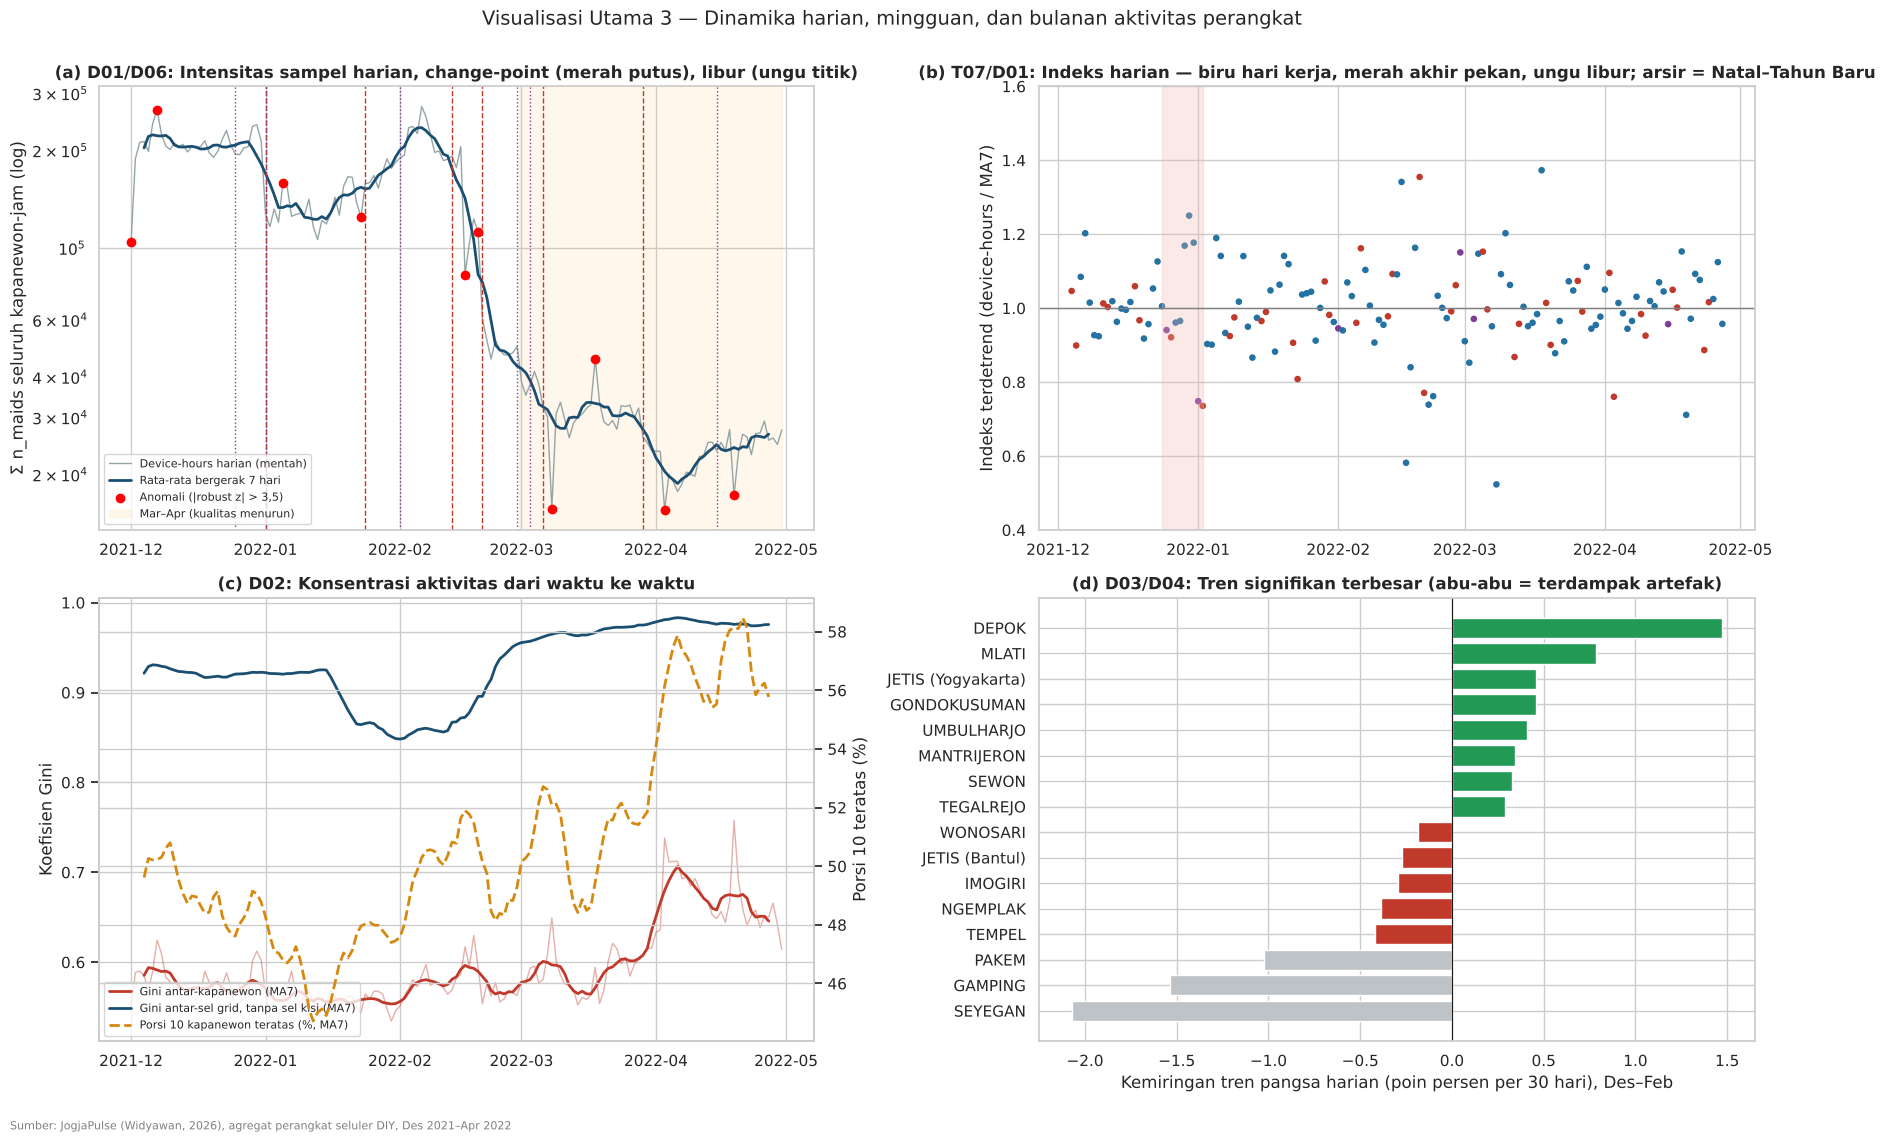

In [79]:
fig, axes = plt.subplots(2, 2, figsize=(18, 11))
ax = axes[0, 0]
ax.plot(daily_quality.index, daily_quality.device_hours, color="#95a5a6", lw=1, label="Device-hours harian (mentah)")
ax.plot(daily_quality.index, daily_quality.device_hours.rolling(7, center=True).mean(), color="#1b4f72", lw=2, label="Rata-rata bergerak 7 hari")
ax.scatter(anomalies.index, anomalies.device_hours, color="red", zorder=5, label="Anomali (|robust z| > 3,5)")
for cp in change_points:
    ax.axvline(cp, color="#c0392b", ls="--", lw=1)
for d in ID_HOLIDAYS:
    ax.axvline(d, color="#7d3c98", ls=":", lw=1)
ax.axvspan(pd.Timestamp(HQ_END) + pd.Timedelta(hours=12), daily_quality.index[-1], color="orange", alpha=0.08, label="Mar–Apr (kualitas menurun)")
ax.set(yscale="log", ylabel="Σ n_maids seluruh kapanewon-jam (log)", title="(a) D01/D06: Intensitas sampel harian, change-point (merah putus), libur (ungu titik)")
ax.legend(fontsize=8, loc="lower left")
ax = axes[0, 1]
colors = d01.day_type.map({"Hari kerja": "#2471a3", "Akhir pekan": "#c0392b", "Libur nasional": "#7d3c98"})
ax.scatter(d01.index, d01.index_detrended, c=colors, s=14)
ax.axhline(1, color="gray", lw=1)
ax.axvspan(*HOLIDAY_WINDOW, color="#f5b7b1", alpha=0.3)
ax.set(ylabel="Indeks terdetrend (device-hours / MA7)", title="(b) T07/D01: Indeks harian — biru hari kerja, merah akhir pekan, ungu libur; arsir = Natal–Tahun Baru")
ax.set_ylim(0.4, 1.6)
ax = axes[1, 0]
ax.plot(conc.index, conc.gini_kapanewon, color="#c0392b", alpha=0.4, lw=1)
ax.plot(conc.index, conc.gini_kapanewon.rolling(7, center=True).mean(), color="#c0392b", lw=2, label="Gini antar-kapanewon (MA7)")
ax.plot(conc.index, conc.gini_cells_clean.rolling(7, center=True).mean(), color="#1b4f72", lw=2, label="Gini antar-sel grid, tanpa sel kisi (MA7)")
ax3 = ax.twinx()
ax3.plot(conc.index, conc.top10_share_pct.rolling(7, center=True).mean(), color="#d68910", lw=2, ls="--", label="Porsi 10 kapanewon teratas (%, MA7)")
ax3.set_ylabel("Porsi 10 teratas (%)")
ax.set(ylabel="Koefisien Gini", title="(c) D02: Konsentrasi aktivitas dari waktu ke waktu")
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax3.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, fontsize=8, loc="lower left")
ax = axes[1, 1]
movers = pd.concat([sig.sort_values("slope_pp_per_30d", ascending=False).head(8), sig.sort_values("slope_pp_per_30d").head(8)]).drop_duplicates()
movers = movers.sort_values("slope_pp_per_30d")
bar_colors = np.where(movers.artefak_kisi, "#bdc3c7", np.where(movers.slope_pp_per_30d > 0, "#229954", "#c0392b"))
ax.barh(movers.label, movers.slope_pp_per_30d, color=bar_colors)
ax.axvline(0, color="k", lw=0.8)
ax.set(xlabel="Kemiringan tren pangsa harian (poin persen per 30 hari), Des–Feb", title="(d) D03/D04: Tren signifikan terbesar (abu-abu = terdampak artefak)")
fig.suptitle("Visualisasi Utama 3 — Dinamika harian, mingguan, dan bulanan aktivitas perangkat", y=1.0)
fig.tight_layout()
save_fig(fig, "V3_weekly_monthly_dynamics")
plt.show()

### 7.x Interpretasi Section 7

- **D01.** Hari dengan device-hours mentah tertinggi adalah 6 Februari dan 7 Desember; terendah adalah awal–pertengahan April dan **8 Maret** (anomali README). Angka mentah ini terutama mencerminkan ukuran sampel. Setelah detrending, hari yang menonjol tinggi relatif terhadap minggunya antara lain 30 Desember (menjelang Tahun Baru), 15 dan 19 Februari, sedangkan yang rendah adalah 8 Maret, 16 Februari (hari patahan), 1–2 Januari, dan 19 April.
- **D02.** Konsentrasi antar-kapanewon relatif stabil selama periode HQ (Gini ±0,56–0,58; 10 kapanewon teratas ±47–50%), lalu naik tajam pada April (Gini 0,67; top-10 57%). Kenaikan April **bukan** tanda pemusatan aktivitas nyata: sampel menyusut, banyak slot pinggiran tersuppress, dan sel "lengket" di Gondomanan/Sleman menjadi dominan.
- **D03–D04.** Dalam periode HQ, 16 kapanewon memiliki tren pangsa naik signifikan dan 21 turun. Tren turun terkuat (Seyegan, Gamping, Pakem) adalah **artefak sel kisi** yang menghilang akhir Januari. Di luar artefak, tren naik terkuat terjadi di Depok, Mlati, dan kemantren kota (Jetis, Gondokusuman, Umbulharjo, Mantrijeron, Tegalrejo) serta Sewon, sedangkan tren turun di Tempel, Ngemplak, Imogiri, Jetis (Bantul), dan Wonosari. Dengan data ini kita tidak dapat memastikan apakah pergeseran ke inti kota mencerminkan perubahan perilaku (mis. kalender akademik) atau perubahan komposisi sampel.
- **D05.** Fluktuasi harian tertinggi terjadi di kapanewon kecil atau terdampak artefak (Ngampilan, Gondomanan, Mantrijeron, Seyegan, Gedangsari, Pakem; kapanewon dengan pangsa kecil lebih fluktuatif, Spearman −0,63). Paling stabil: Banguntapan, Sedayu, Bantul, Godean.
- **D06.** Anomali harian terdeteksi pada 1 Des (hari pertama, data kemungkinan belum lengkap), 16 Feb (patahan), **8 Mar** (anomali README), 18 Mar, 3 dan 19 Apr, dll. *Change-point detection* menemukan patahan level pada **1 Jan, 24 Jan, 13 Feb, 20 Feb, 6 Mar, dan 29 Mar** — mengonfirmasi patahan 1 Jan dan pertengahan Feb di README dan menunjukkan bahwa penurunan "bertahap" setelah Februari sebenarnya terdiri dari beberapa tangga. Di level sel, dua sel (Gondomanan dan Kapanewon Sleman) justru **naik** ketika sampel DIY turun ±89% — anomali "sel lengket" yang dibahas di Section 5.
- **D07.** Penurunan sampel **tidak merata**: retensi (Mar–Apr ÷ Des–Jan) berkisar 0,006 (Rongkop) hingga 1,24 (Gondomanan); median kelas padat 0,18 vs transisi 0,09 (Kruskal–Wallis p < 0,001). Kemantren Kota Yogyakarta mempertahankan sampel paling baik (median 0,30). Konsekuensinya, pangsa kapanewon pada Mar–Apr bergeser ke inti kota karena sampel, bukan karena perilaku.
- **D08.** Pada libur Natal–Tahun Baru, pangsa kemantren kota (Mantrijeron, Wirobrajan, Gondomanan, Danurejan, Jetis) **turun** 33–46%, sedangkan kapanewon pinggiran/perbukitan (Samigaluh, Kokap, Turi, Nanggulan, Pundong, Ponjong) naik 19–32%. Uplift tertinggi Ngaglik (1,59) didorong oleh satu sel (E865_N18299) yang melonjak hingga ±11 ribu perangkat/hari pada 17–20 dan 29–31 Desember (episodik; bisa acara massal atau artefak, tidak dapat dipastikan). Di level sel, uplift libur banyak berada di Imogiri, Ngaglik, Tempel, Turi, Bambanglipuro, Galur. Atribusi ke "wisata" membutuhkan data POI.

In [80]:
d_ds = "presence_kapanewon_hourly; presence_cell500m_daily"
add_insight("D01", "Hari dengan aktivitas perangkat tertinggi dan terendah", d_ds, "date, n_maids",
            "Device-hours mentah & indeks terdetrend", "Σn_maids per hari; device_hours/MA7", "V3(a,b)", "completed",
            f"Mentah tertinggi: {', '.join(d.date().isoformat() for d in d01.device_hours.nlargest(3).index)}; terendah: {', '.join(d.date().isoformat() for d in d01.device_hours.nsmallest(3).index)}. "
            f"Indeks relatif tertinggi: {', '.join(d.date().isoformat() for d in d01.index_detrended.nlargest(4).index)}; terendah: {', '.join(d.date().isoformat() for d in d01.index_detrended.nsmallest(4).index)}.",
            "Angka mentah didominasi ukuran sampel; setelah detrending, hari menjelang Tahun Baru tinggi dan hari patahan/anomali rendah.",
            "Device-hours ≠ perangkat unik; indeks terdetrend bias di sekitar patahan.")
add_insight("D02", "Perubahan konsentrasi perangkat selama lima bulan", d_ds, "share_lb, n_maids (sel)",
            "Gini harian antar-kapanewon & antar-sel; porsi top-10", "Gini(daily_share); Σ top-10", "V3(c)", "completed",
            "Gini kapanewon per bulan: " + ", ".join(f"{m} {v:.2f}" for m, v in conc_monthly.gini_kapanewon.items())
            + "; top-10: " + ", ".join(f"{m} {v:.0f}%" for m, v in conc_monthly.top10_share_pct.items()) + ".",
            "Stabil dalam periode HQ; kenaikan konsentrasi April adalah efek penyusutan sampel dan sel 'lengket', bukan pemusatan nyata.",
            "Gini sel bergantung jumlah sel terpublikasi yang berubah drastis.")
add_insight("D03", "Wilayah dengan tren aktivitas meningkat", d_ds, "daily_share",
            "OLS tren linear + SE Newey–West (HAC)", "slope pp/30 hari", "V3(d)", "completed",
            f"{(sig.slope_pp_per_30d > 0).sum()} kapanewon naik signifikan; terbesar: {fmt_list(sig.sort_values('slope_pp_per_30d', ascending=False).set_index('label').slope_pp_per_30d, 6)} pp/30 hari.",
            "Pangsa bergeser ke Depok, Mlati, dan kemantren kota selama Des–Feb.",
            "Tren linear pada 90 hari; dipengaruhi patahan sampel dan hilangnya sel artefak di kapanewon lain (pangsa adalah zero-sum).")
add_insight("D04", "Wilayah dengan tren aktivitas menurun", d_ds, "daily_share",
            "OLS tren linear + SE Newey–West (HAC)", "slope pp/30 hari", "V3(d)", "completed",
            f"{(sig.slope_pp_per_30d < 0).sum()} kapanewon turun signifikan; terbesar: {fmt_list(sig.sort_values('slope_pp_per_30d').set_index('label').slope_pp_per_30d, 6)} pp/30 hari.",
            "Tiga teratas (Seyegan, Gamping, Pakem) adalah artefak sel kisi; penurunan non-artefak: Tempel, Ngemplak, Imogiri, Jetis (Bantul), Wonosari.",
            "Pangsa bersifat zero-sum; penurunan relatif ≠ penurunan absolut aktivitas.")
add_insight("D05", "Wilayah dengan fluktuasi aktivitas paling tinggi", d_ds, "daily_share",
            "Coefficient of variation pangsa harian (mentah & terdetrend)", "std/mean", "V3", "completed",
            f"CV tertinggi: {fmt_list(fluct.sort_values('cv_daily_share', ascending=False).set_index('label').cv_daily_share, 6)}. Paling stabil: {fmt_list(fluct.sort_values('cv_daily_share').set_index('label').cv_daily_share, 3)}.",
            "Fluktuasi tinggi terutama pada kapanewon kecil (noise sampel) atau terdampak artefak.",
            "CV sensitif terhadap ukuran sampel & suppression.")
add_insight("D06", "Anomali pada tanggal tertentu", d_ds, "date, n_maids, cell_id",
            "Robust z-score (MAD); binary segmentation + BIC; deteksi sel 'lengket'", "|z|>3,5; ΔBIC", "V3(a), V8", "completed",
            f"Anomali: {', '.join(d.date().isoformat() for d in anomalies.index)}. Change-point: {', '.join(d.date().isoformat() for d in change_points)}. "
            f"Sel lengket: {', '.join(f'{r.kapanewon} ({r.relative_to_diy:.0f}× relatif DIY)' for r in sticky_top.head(2).itertuples())}.",
            "Mengonfirmasi 8 Mar (README) dan patahan 1 Jan & pertengahan Feb; menemukan anomali tambahan 1 Des dan patahan bertingkat pada Mar.",
            "Penyebab anomali (pengiriman data, perubahan sumber) tidak dapat diverifikasi dari data agregat.")
add_insight("D07", "Apakah penurunan sampel terjadi merata di semua wilayah?", d_ds, "n_maids",
            "Rasio retensi Mar–Apr ÷ Des–Jan; Kruskal–Wallis", "mean device-hours late / early", "V3, V8", "completed",
            f"Retensi DIY {diy_retention:.3f}; kapanewon {decline.retention_ratio.min():.3f}–{decline.retention_ratio.max():.2f} (CV {decline.retention_ratio.std() / decline.retention_ratio.mean():.2f}); "
            f"median Kota Yogyakarta {decline.groupby('kab_kota').retention_ratio.median()['YOGYAKARTA']:.2f} vs kabupaten lain ±0,12–0,13; Kruskal–Wallis antar-kelas p = {kw_decline.pvalue:.1e}.",
            "Tidak merata: inti kota mempertahankan sampel jauh lebih baik, sehingga perbandingan Mar–Apr vs Des–Feb bias ke kota.",
            "Suppression lebih berat di Mar–Apr menurunkan retensi kapanewon kecil (batas bawah).")
add_insight("D08", "Perubahan aktivitas wisata pada akhir pekan dan periode liburan", d_ds + " + (butuh) POI wisata", "daily_share, share sel",
            "Uplift pangsa libur Natal–Tahun Baru & akhir pekan vs hari kerja biasa", "share_libur / share_hari_kerja",
            "V3(b)", "requires external data",
            f"Proxy tanpa label wisata — uplift libur tertinggi: {fmt_list(uplift.sort_values('holiday_uplift', ascending=False).set_index('label').holiday_uplift, 6)}; "
            f"terendah: {fmt_list(uplift.sort_values('holiday_uplift').set_index('label').holiday_uplift, 5)}. Korelasi uplift libur vs akhir pekan ρ = {uplift_corr['spearman_rho']:.2f}.",
            "Saat libur, aktivitas berpindah dari inti kota ke kapanewon pinggiran/perbukitan; uplift Ngaglik didorong lonjakan satu sel. Perlu POI untuk menyatakan 'kawasan wisata'.",
            "Butuh data/external/tourism_poi_diy.csv; satu periode libur saja.")

---
## Section 8 — Origin–Destination Mobility Analysis (M01–M15)

### 8.0 Memahami struktur data OD sebelum menghitung
- Satu baris = (bulan, asal *i*, tujuan *j*): **jumlah perangkat berbeda** berumah di *i* yang teramati di *j* pada siang hari (08.00–17.59) **setidaknya sekali** dalam bulan itu. **Bukan jumlah perjalanan.**
- Setiap perangkat hanya punya **satu rumah per bulan**. Akibatnya:
  - **Jumlah ke bawah kolom (Σ asal → satu tujuan *j*) = perangkat unik** yang mengunjungi *j* dari luar (selain yang tersuppress). ✔ aditif.
  - **Jumlah sepanjang baris (Σ tujuan dari satu asal *i*) ≠ perangkat unik**, karena satu perangkat bisa mengunjungi banyak tujuan. Jumlah ini dibagi `n_homed_maids_daytime` menjadi **rata-rata jumlah kapanewon lain yang dikunjungi per perangkat** (ukuran intensitas kunjungan, batas bawah).
- Antarbulan **tidak aditif** (perangkat yang sama muncul di beberapa bulan). Ringkasan periode HQ = **rata-rata bulanan** Des–Feb.
- Denominator `n_homed_maids_daytime` sudah diperiksa di Section 3: tidak ada nilai kosong, dan tidak ada `n_maids` > denominator. Jadi rasio `n_maids / n_homed_maids_daytime` valid sebagai **visit share** (proporsi perangkat asal yang teramati di tujuan).
- Untuk membandingkan antarbulan, aliran dinormalisasi **per 1.000 perangkat siang sampel** pada bulan tersebut.

In [81]:
HQ_MONTHS = ["2021-12", "2022-01", "2022-02"]
ALL_MONTHS = sorted(od.month.unique())
inter = od[~od.is_self].copy()
month_daytime_total = origin_homes.groupby("month").n_homed_maids_daytime.sum()
inter["flow_per_1000"] = inter.n_maids / inter.month.map(month_daytime_total) * 1000

# --- Metrik per asal per bulan ---
origin_month = origin_homes.set_index(["month", "origin_code"])[["n_homed_maids", "n_homed_maids_daytime"]].copy()
origin_month["self_visits"] = od[od.is_self].set_index(["month", "origin_code"]).n_maids
origin_month["out_pairs"] = inter.groupby(["month", "origin_code"]).n_maids.sum()
origin_month["out_degree"] = inter.groupby(["month", "origin_code"]).size()
origin_month = origin_month.fillna({"out_pairs": 0, "out_degree": 0})
origin_month["self_share"] = origin_month.self_visits / origin_month.n_homed_maids_daytime
origin_month["ext_intensity"] = origin_month.out_pairs / origin_month.n_homed_maids_daytime
origin_month["daytime_obs_rate"] = origin_month.n_homed_maids_daytime / origin_month.n_homed_maids

# --- Metrik per tujuan per bulan ---
dest_month = pd.DataFrame({
    "inflow": inter.groupby(["month", "dest_code"]).n_maids.sum(),
    "in_degree": inter.groupby(["month", "dest_code"]).size(),
}).reindex(pd.MultiIndex.from_product([ALL_MONTHS, kapanewon_master.kapanewon_code], names=["month", "dest_code"])).fillna(0)
dest_month["inflow_per_1000"] = dest_month.inflow / dest_month.index.get_level_values("month").map(month_daytime_total).to_numpy() * 1000


def hq_mean(frame, months=HQ_MONTHS, level="month"):
    """Rata-rata bulanan atas bulan-bulan HQ."""
    return frame[frame.index.get_level_values(level).isin(months)].groupby(level=1).mean()


origin_hq = hq_mean(origin_month).join(LABEL).join(KAB_OF)
dest_hq = hq_mean(dest_month).join(LABEL).join(KAB_OF)
print("Rata-rata kapanewon lain yang dikunjungi per perangkat (DIY, HQ):",
      round((origin_month.loc[HQ_MONTHS].out_pairs.groupby(level=0).sum() / origin_month.loc[HQ_MONTHS].n_homed_maids_daytime.groupby(level=0).sum()).mean(), 3))
print("Tingkat teramati siang (n_homed_daytime / n_homed) per bulan:",
      (origin_month.n_homed_maids_daytime.groupby(level=0).sum() / origin_month.n_homed_maids.groupby(level=0).sum()).round(3).to_dict())

Rata-rata kapanewon lain yang dikunjungi per perangkat (DIY, HQ): 1.425
Tingkat teramati siang (n_homed_daytime / n_homed) per bulan: {'2021-12': 0.921, '2022-01': 0.899, '2022-02': 0.827, '2022-03': 0.531, '2022-04': 0.814}


### M01–M03 — Perangkat asal: jumlah, proporsi berkunjung ke luar, dan yang jarang keluar
- **M01:** jumlah perangkat asal yang teramati siang hari (`n_homed_maids_daytime`, rata-rata bulanan HQ).
- **M02:** **intensitas kunjungan eksternal** = Σ_{j≠i} n_ij ÷ n_homed_maids_daytime = rata-rata jumlah kapanewon *lain* yang dikunjungi per perangkat dalam sebulan. Nilai 0,8 berarti rata-rata perangkat teramati di 0,8 kapanewon lain.
- **M03:** intensitas eksternal terendah dan **self-share** (proporsi perangkat yang teramati di kapanewon rumahnya sendiri pada siang hari) tertinggi.

In [82]:
m_cols = ["label", "kab_kota", "n_homed_maids_daytime", "self_share", "ext_intensity", "out_degree"]
print("M01 — perangkat asal teramati siang terbanyak:")
display(origin_hq.sort_values("n_homed_maids_daytime", ascending=False)[m_cols].head(8))
print("M02 — intensitas kunjungan eksternal tertinggi:")
display(origin_hq.sort_values("ext_intensity", ascending=False)[m_cols].head(8))
print("M03 — intensitas eksternal terendah:")
display(origin_hq.sort_values("ext_intensity")[m_cols].head(8))
ext_vs_size = corr_report(np.log10(origin_hq.n_homed_maids_daytime), origin_hq.ext_intensity)
ext_vs_dist = corr_report(kap_hq.dist_center_km.reindex(origin_hq.index), origin_hq.ext_intensity) if HAS_BOUNDARY else None
print(f"Spearman log ukuran asal vs intensitas eksternal: {ext_vs_size['spearman_rho']:.3f}"
      + (f" | jarak ke pusat kota vs intensitas: {ext_vs_dist['spearman_rho']:.3f}" if ext_vs_dist else ""))
save_table(origin_hq.reset_index(), "M01_M03_origin_metrics_HQ")

M01 — perangkat asal teramati siang terbanyak:


,label,kab_kota,n_homed_maids_daytime,self_share,ext_intensity,out_degree
origin_code,,,,,,
34.04.07,DEPOK,SLEMAN,"7,203.0000",0.9203,1.4326,70.3333
34.04.12,NGAGLIK,SLEMAN,"5,596.3333",0.9385,1.3716,65.3333
34.04.01,GAMPING,SLEMAN,"5,165.6667",0.9265,1.6438,67.0000
34.02.16,KASIHAN,BANTUL,"4,827.0000",0.9351,1.3082,67.0000
34.02.12,BANGUNTAPAN,BANTUL,"4,823.0000",0.9242,1.7715,68.0000
34.04.11,NGEMPLAK,SLEMAN,"3,264.3333",0.9221,1.3285,52.0000
34.04.06,MLATI,SLEMAN,"2,854.6667",0.9080,1.6717,56.6667
34.71.13,UMBULHARJO,YOGYAKARTA,"2,835.3333",0.8749,1.9729,52.0000


M02 — intensitas kunjungan eksternal tertinggi:


,label,kab_kota,n_homed_maids_daytime,self_share,ext_intensity,out_degree
origin_code,,,,,,
34.71.08,MANTRIJERON,YOGYAKARTA,154.0000,0.8857,3.9169,28.0000
34.71.07,WIROBRAJAN,YOGYAKARTA,122.3333,0.9124,3.5100,26.3333
34.71.05,GEDONGTENGEN,YOGYAKARTA,86.3333,0.8558,3.4738,26.6667
34.71.01,TEGALREJO,YOGYAKARTA,290.6667,0.8717,3.1256,37.0000
34.71.12,MERGANGSAN,YOGYAKARTA,383.6667,0.8776,3.1220,37.0000
34.71.04,DANUREJAN,YOGYAKARTA,187.3333,0.8384,3.0940,25.6667
34.71.11,PAKUALAMAN,YOGYAKARTA,350.0000,0.8032,2.2358,22.6667
34.71.06,NGAMPILAN,YOGYAKARTA,49.6667,0.8880,2.2021,13.0000


M03 — intensitas eksternal terendah:


,label,kab_kota,n_homed_maids_daytime,self_share,ext_intensity,out_degree
origin_code,,,,,,
34.03.13,NGAWEN,GUNUNGKIDUL,85.3333,0.9431,0.4578,5.0000
34.03.11,RONGKOP,GUNUNGKIDUL,63.0000,0.9123,0.5202,3.0000
34.04.14,TEMPEL,SLEMAN,"1,890.6667",0.9772,0.5639,39.0000
34.03.14,GEDANGSARI,GUNUNGKIDUL,255.0000,0.9829,0.5725,13.0000
34.03.10,PONJONG,GUNUNGKIDUL,349.6667,0.9598,0.6810,16.3333
34.03.12,SEMIN,GUNUNGKIDUL,134.6667,0.9553,0.7609,10.6667
34.03.18,PURWOSARI,GUNUNGKIDUL,77.0000,0.9331,0.7817,7.6667
34.04.04,MINGGIR,SLEMAN,"1,023.0000",0.9583,0.7987,35.0000


Spearman log ukuran asal vs intensitas eksternal: 0.175 | jarak ke pusat kota vs intensitas: -0.704
Tabel disimpan: outputs/tables/M01_M03_origin_metrics_HQ.csv


### M04–M06 — Pengunjung masuk: tertinggi, terendah, dan asal pengunjung
- **M04/M05:** inflow = perangkat unik dari kapanewon lain yang teramati di tujuan (per 1.000 perangkat siang sampel, rata-rata HQ).
- **M06:** untuk setiap tujuan, tiga asal terbesar dan porsinya terhadap inflow. Tabel lengkap 78 tujuan disimpan ke CSV.

In [83]:
d_cols = ["label", "kab_kota", "inflow", "inflow_per_1000", "in_degree"]
print("M04 — inflow tertinggi:")
display(dest_hq.sort_values("inflow_per_1000", ascending=False)[d_cols].head(8))
print("M05 — inflow terendah:")
display(dest_hq.sort_values("inflow_per_1000")[d_cols].head(8))

inter_hq = inter[inter.month.isin(HQ_MONTHS)]
pair_hq = (inter_hq.groupby(["origin_code", "dest_code"]).agg(n_mean=("n_maids", lambda s: s.sum() / len(HQ_MONTHS)),
                                                            months_published=("n_maids", "size"),
                                                            visit_share_mean=("visit_share", lambda s: s.sum() / len(HQ_MONTHS)),
                                                            flow_per_1000=("flow_per_1000", lambda s: s.sum() / len(HQ_MONTHS)))
           .reset_index())
if HAS_BOUNDARY:
    pair_hq["distance_km"] = [DIST_KM.at[o, d] for o, d in zip(pair_hq.origin_code, pair_hq.dest_code)]
    pair_hq["adjacent"] = [ADJ.at[o, d] for o, d in zip(pair_hq.origin_code, pair_hq.dest_code)]
pair_hq["origin"], pair_hq["dest"] = pair_hq.origin_code.map(LABEL), pair_hq.dest_code.map(LABEL)
pair_hq["share_of_dest_inflow"] = pair_hq.n_mean / pair_hq.groupby("dest_code").n_mean.transform("sum")
m06 = (pair_hq.sort_values(["dest_code", "n_mean"], ascending=[True, False]).groupby("dest_code").head(3)
       .groupby("dest_code").apply(lambda g: "; ".join(f"{o} {s:.0%}" for o, s in zip(g.origin, g.share_of_dest_inflow)))
       .rename("top3_asal_(porsi_inflow)").to_frame().join(LABEL).join(KAB_OF))
m06["porsi_asal_terbesar"] = pair_hq.groupby("dest_code").share_of_dest_inflow.max()
m06["asal_sekabupaten_%"] = pair_hq.assign(same_kab=pair_hq.origin_code.str[:5] == pair_hq.dest_code.str[:5]).groupby("dest_code").apply(
    lambda g: g.loc[g.same_kab, "n_mean"].sum() / g.n_mean.sum() * 100)
save_table(m06.reset_index(), "M06_origin_of_visitors_by_destination")
save_table(pair_hq, "M_pairs_HQ")
with pd.option_context("display.max_colwidth", 120):
    display(m06.loc[dest_hq.sort_values("inflow_per_1000", ascending=False).index[:10]])
print(f"Median porsi asal terbesar: {m06.porsi_asal_terbesar.median():.0%}; median porsi asal dari kabupaten yang sama: {m06['asal_sekabupaten_%'].median():.0f}%")

M04 — inflow tertinggi:


,label,kab_kota,inflow,inflow_per_1000,in_degree
dest_code,,,,,
34.04.07,DEPOK,SLEMAN,"9,176.3333",111.1592,70.6667
34.02.12,BANGUNTAPAN,BANTUL,"6,102.0000",72.5654,66.6667
34.04.12,NGAGLIK,SLEMAN,"5,937.6667",69.6923,61.6667
34.04.01,GAMPING,SLEMAN,"5,479.0000",63.0558,60.6667
34.71.03,GONDOKUSUMAN,YOGYAKARTA,"4,933.6667",61.3962,57.0000
34.04.06,MLATI,SLEMAN,"4,902.3333",60.1564,57.6667
34.71.13,UMBULHARJO,YOGYAKARTA,"4,935.6667",59.7555,57.6667
34.02.16,KASIHAN,BANTUL,"4,646.3333",55.2089,65.0000


M05 — inflow terendah:


,label,kab_kota,inflow,inflow_per_1000,in_degree
dest_code,,,,,
34.03.16,GIRISUBO,GUNUNGKIDUL,16.6667,0.1794,2.0000
34.03.11,RONGKOP,GUNUNGKIDUL,26.3333,0.2836,3.0000
34.03.18,PURWOSARI,GUNUNGKIDUL,37.6667,0.4735,4.0000
34.03.12,SEMIN,GUNUNGKIDUL,50.0000,0.5813,6.3333
34.03.07,TEPUS,GUNUNGKIDUL,51.6667,0.6262,6.0000
34.03.06,PANGGANG,GUNUNGKIDUL,91.6667,1.1093,11.6667
34.03.13,NGAWEN,GUNUNGKIDUL,102.6667,1.1855,9.3333
34.03.17,TANJUNGSARI,GUNUNGKIDUL,113.0000,1.3298,11.0000


Tabel disimpan: outputs/tables/M06_origin_of_visitors_by_destination.csv
Tabel disimpan: outputs/tables/M_pairs_HQ.csv


,top3_asal_(porsi_inflow),label,kab_kota,porsi_asal_terbesar,asal_sekabupaten_%
dest_code,,,,,
34.04.07,NGAGLIK 12%; NGEMPLAK 11%; BANGUNTAPAN 10%,DEPOK,SLEMAN,0.1221,56.7583
34.02.12,DEPOK 14%; KOTAGEDE 10%; UMBULHARJO 8%,BANGUNTAPAN,BANTUL,0.1407,20.0645
34.04.12,NGEMPLAK 16%; DEPOK 14%; PAKEM 10%,NGAGLIK,SLEMAN,0.1607,70.4093
34.04.01,KASIHAN 12%; SEYEGAN 10%; MLATI 7%,GAMPING,SLEMAN,0.1195,46.6143
34.71.03,DEPOK 17%; UMBULHARJO 16%; BANGUNTAPAN 8%,GONDOKUSUMAN,YOGYAKARTA,0.1697,29.7210
34.04.06,DEPOK 16%; GAMPING 13%; NGAGLIK 12%,MLATI,SLEMAN,0.1566,72.0065
34.71.13,BANGUNTAPAN 22%; KOTAGEDE 12%; DEPOK 9%,UMBULHARJO,YOGYAKARTA,0.2214,30.4788
34.02.16,GAMPING 18%; SEWON 8%; DEPOK 7%,KASIHAN,BANTUL,0.1783,25.5614
34.04.16,NGAGLIK 26%; SEYEGAN 10%; DEPOK 8%,PAKEM,SLEMAN,0.2628,72.8961


Median porsi asal terbesar: 18%; median porsi asal dari kabupaten yang sama: 54%


### M07 — Apakah perangkat dari pinggiran lebih banyak mengunjungi pusat kota?
"Pusat kota" = 14 kemantren Kota Yogyakarta. Untuk setiap asal di luar kota:
- **city intensity** = Σ_{j ∈ Kota} n_ij ÷ n_homed_maids_daytime_i (rata-rata kemantren kota yang dikunjungi per perangkat),
- **porsi kunjungan eksternal ke kota** = Σ_{j ∈ Kota} n_ij ÷ Σ_{j≠i} n_ij.

Kita lalu melihat hubungannya dengan jarak dari pusat kota (Spearman).

In [84]:
city_codes = set(kapanewon_master.loc[kapanewon_master.kab_kota == "YOGYAKARTA", "kapanewon_code"])
inter_hq_c = inter_hq.assign(to_city=inter_hq.dest_code.isin(city_codes))
city_visits = (inter_hq_c[inter_hq_c.to_city].groupby(["month", "origin_code"]).n_maids.sum()
               .reindex(origin_month.loc[HQ_MONTHS].index).fillna(0))
m07 = pd.DataFrame({
    "city_intensity": (city_visits / origin_month.loc[HQ_MONTHS].n_homed_maids_daytime).groupby(level=1).mean(),
    "city_share_of_external": (city_visits / origin_month.loc[HQ_MONTHS].out_pairs).groupby(level=1).mean(),
}).join(origin_hq[["label", "kab_kota", "ext_intensity"]])
m07 = m07[~m07.index.isin(city_codes)]
if HAS_BOUNDARY:
    m07["dist_center_km"] = kap_hq.dist_center_km
    m07_corr = corr_report(m07.dist_center_km, m07.city_intensity, "jarak vs city intensity")
    m07_corr_share = corr_report(m07.dist_center_km, m07.city_share_of_external, "jarak vs porsi ke kota")
    print(f"Spearman jarak ke pusat vs city intensity: {m07_corr['spearman_rho']:.3f} (p = {m07_corr['spearman_p']:.1e}); "
          f"vs porsi kunjungan eksternal ke kota: {m07_corr_share['spearman_rho']:.3f}")
display(m07.groupby("kab_kota")[["city_intensity", "city_share_of_external", "ext_intensity"]].median().round(3))
display(m07.sort_values("city_intensity", ascending=False).head(8).round(3))

Spearman jarak ke pusat vs city intensity: -0.776 (p = 5.0e-14); vs porsi kunjungan eksternal ke kota: -0.788


,city_intensity,city_share_of_external,ext_intensity
kab_kota,,,
BANTUL,0.1450,0.1390,1.1720
GUNUNGKIDUL,0.0320,0.0310,0.9580
KULON PROGO,0.1090,0.1060,1.2280
SLEMAN,0.2180,0.1520,1.2870


,city_intensity,city_share_of_external,label,kab_kota,ext_intensity,dist_center_km
origin_code,,,,,,
34.02.12,0.6810,0.3820,BANGUNTAPAN,BANTUL,1.7710,5.1560
34.02.15,0.6250,0.3810,SEWON,BANTUL,1.6130,6.2970
34.02.16,0.4750,0.3550,KASIHAN,BANTUL,1.3080,4.7230
34.04.01,0.4570,0.2720,GAMPING,SLEMAN,1.6440,5.0710
34.04.08,0.4520,0.2380,BERBAH,SLEMAN,1.8640,8.2600
34.04.06,0.4380,0.2550,MLATI,SLEMAN,1.6720,8.8240
34.04.07,0.4210,0.2880,DEPOK,SLEMAN,1.4330,5.6940
34.04.13,0.3100,0.2480,SLEMAN,SLEMAN,1.2110,12.4020


### M08–M10 — Pasangan terbesar, terjauh, dan pengaruh jarak
**Distance decay** = makin jauh jarak, makin sedikit kunjungan. Kita mengukurnya dengan (1) porsi kunjungan per pita jarak, (2) porsi kunjungan ke kapanewon **bertetangga** (berbatasan langsung) dibanding porsi pasangan bertetangga di antara seluruh pasangan yang mungkin, dan (3) regresi log-log `visit_share ~ distance`. Kemiringan regresi (−γ) menunjukkan seberapa cepat kunjungan menurun dengan jarak.

In [85]:
print("M08 — pasangan dengan perangkat pengunjung terbanyak (rata-rata bulanan HQ):")
display(pair_hq.sort_values("n_mean", ascending=False)[["origin", "dest", "n_mean", "visit_share_mean", "flow_per_1000"] + (["distance_km"] if HAS_BOUNDARY else [])].head(10))
print("M08b — pasangan dengan visit share tertinggi (porsi perangkat asal yang berkunjung):")
display(pair_hq[pair_hq.months_published == 3].sort_values("visit_share_mean", ascending=False)[["origin", "dest", "n_mean", "visit_share_mean"] + (["distance_km"] if HAS_BOUNDARY else [])].head(8))

if HAS_BOUNDARY:
    print("M09 — pasangan terpublikasi dengan jarak centroid terjauh (HQ):")
    display(pair_hq.sort_values("distance_km", ascending=False)[["origin", "dest", "distance_km", "n_mean", "months_published"]].head(8))
    bands = [0, 5, 10, 15, 20, 30, 50, 100]
    pair_hq["dist_band"] = pd.cut(pair_hq.distance_km, bands, right=False)
    all_pairs = pd.DataFrame([(o, d, DIST_KM.at[o, d], ADJ.at[o, d]) for o in DIST_KM.index for d in DIST_KM.columns if o != d],
                             columns=["origin_code", "dest_code", "distance_km", "adjacent"])
    all_pairs["dist_band"] = pd.cut(all_pairs.distance_km, bands, right=False)
    decay = pd.DataFrame({
        "pasangan_mungkin": all_pairs.groupby("dist_band", observed=False).size(),
        "pasangan_terpublikasi": pair_hq.groupby("dist_band", observed=False).size(),
        "porsi_kunjungan_%": pair_hq.groupby("dist_band", observed=False).n_mean.sum() / pair_hq.n_mean.sum() * 100,
        "median_visit_share": pair_hq.groupby("dist_band", observed=False).visit_share_mean.median(),
    })
    decay["porsi_pasangan_mungkin_%"] = decay.pasangan_mungkin / decay.pasangan_mungkin.sum() * 100
    display(decay.round(4))
    adj_visit_share = pair_hq.loc[pair_hq.adjacent, "n_mean"].sum() / pair_hq.n_mean.sum() * 100
    adj_pair_share = all_pairs.adjacent.mean() * 100
    within10 = pair_hq.loc[pair_hq.distance_km < 10, "n_mean"].sum() / pair_hq.n_mean.sum() * 100
    print(f"Kunjungan ke kapanewon bertetangga: {adj_visit_share:.1f}% kunjungan, padahal hanya {adj_pair_share:.1f}% dari semua pasangan")
    decay_fit = smf.ols("np.log10(visit_share) ~ np.log10(distance_km)", data=inter[inter.month.isin(HQ_MONTHS)]).fit()
    print(f"Regresi log-log visit_share ~ jarak (HQ, baris bulanan): kemiringan {decay_fit.params.iloc[1]:.2f}, R² {decay_fit.rsquared:.3f}")
    decay_by_month = {m: smf.ols("np.log10(visit_share) ~ np.log10(distance_km)", data=inter[inter.month == m]).fit() for m in ALL_MONTHS}
    print("Kemiringan per bulan:", {m: round(f.params.iloc[1], 2) for m, f in decay_by_month.items()})

M08 — pasangan dengan perangkat pengunjung terbanyak (rata-rata bulanan HQ):


,origin,dest,n_mean,visit_share_mean,flow_per_1000,distance_km
2351,NGAGLIK,DEPOK,"1,120.3333",0.2133,13.5520,5.8893
2359,NGAGLIK,PAKEM,"1,118.0000",0.1613,11.1121,10.2625
987,BANGUNTAPAN,UMBULHARJO,"1,092.6667",0.2258,12.8755,3.3732
2355,NGAGLIK,NGEMPLAK,"1,016.3333",0.1873,11.9409,5.2652
2279,NGEMPLAK,DEPOK,988.3333,0.2971,11.5256,7.5129
2283,NGEMPLAK,NGAGLIK,954.0000,0.2860,11.0558,5.2652
964,BANGUNTAPAN,DEPOK,908.0000,0.1957,11.1096,6.2971
2062,DEPOK,NGEMPLAK,887.3333,0.1218,10.5629,7.5129
2031,DEPOK,BANGUNTAPAN,858.3333,0.1188,10.3519,6.2971
2063,DEPOK,NGAGLIK,842.0000,0.1180,10.3581,5.8893


M08b — pasangan dengan visit share tertinggi (porsi perangkat asal yang berkunjung):


,origin,dest,n_mean,visit_share_mean,distance_km
3194,KOTAGEDE,BANGUNTAPAN,638.6667,0.6604,2.1511
3227,KOTAGEDE,UMBULHARJO,596.3333,0.6173,1.2229
129,GALUR,LENDAH,121.3333,0.5053,5.2381
3066,PAKUALAMAN,DANUREJAN,174.0000,0.4948,0.9179
3071,PAKUALAMAN,MERGANGSAN,159.3333,0.4513,1.5594
3025,GONDOMANAN,SLEMAN,497.3333,0.4331,12.0372
1642,TANJUNGSARI,WONOSARI,29.3333,0.4285,12.4536
255,PENGASIH,WATES,338.6667,0.4137,6.4298


M09 — pasangan terpublikasi dengan jarak centroid terjauh (HQ):


,origin,dest,distance_km,n_mean,months_published
1572,SEMIN,WATES,66.5845,11.3333,3
66,WATES,SEMIN,66.5845,6.3333,3
65,WATES,PONJONG,66.3548,9.3333,3
1538,PONJONG,WATES,66.3548,10.0000,3
18,TEMON,SEMANU,65.6322,6.0000,2
1539,PONJONG,PANJATAN,64.6213,3.0000,1
1640,GIRISUBO,NGAGLIK,61.8498,3.3333,1
1480,TEPUS,PAKEM,60.9800,1.6667,1


,pasangan_mungkin,pasangan_terpublikasi,porsi_kunjungan_%,median_visit_share,porsi_pasangan_mungkin_%
dist_band,,,,,
"[0, 5)",264,262,21.6916,0.0841,4.3956
"[5, 10)",520,510,37.9678,0.0456,8.6580
"[10, 15)",760,668,18.8180,0.0159,12.6540
"[15, 20)",806,529,8.4802,0.0105,13.4199
"[20, 30)",1510,717,7.8796,0.0076,25.1415
"[30, 50)",1612,484,4.8576,0.0069,26.8398
"[50, 100)",534,58,0.3053,0.0057,8.8911


Kunjungan ke kapanewon bertetangga: 43.0% kunjungan, padahal hanya 6.7% dari semua pasangan


Regresi log-log visit_share ~ jarak (HQ, baris bulanan): kemiringan -0.85, R² 0.270


Kemiringan per bulan: {'2021-12': np.float64(-0.72), '2022-01': np.float64(-0.9), '2022-02': np.float64(-0.9), '2022-03': np.float64(-0.43), '2022-04': np.float64(-0.25)}


### M11–M13 — Neraca kunjungan, jumlah asal, dan jumlah tujuan
- **M11:** rasio inflow/outflow = Σ kunjungan masuk ÷ Σ kunjungan keluar (keduanya dihitung sebagai jumlah pasangan perangkat–tujuan dari matriks yang sama). > 1 = lebih banyak menerima daripada mengirim.
- **M12:** in-degree = jumlah kapanewon asal berbeda yang tercatat mengirim pengunjung (rata-rata bulanan HQ; dibatasi suppression).
- **M13:** out-degree = jumlah kapanewon tujuan berbeda.

In [86]:
balance = dest_hq[["label", "kab_kota", "inflow", "in_degree"]].join(origin_hq[["out_pairs", "out_degree", "n_homed_maids_daytime"]])
balance["in_out_ratio"] = balance.inflow / balance.out_pairs
balance["net_per_1000_daytime"] = (balance.inflow - balance.out_pairs) / balance.n_homed_maids_daytime * 1000
print("M11 — lebih banyak menerima daripada mengirim:")
display(balance.sort_values("in_out_ratio", ascending=False).head(8))
print("M11 — lebih banyak mengirim daripada menerima:")
display(balance.sort_values("in_out_ratio").head(6))
print("M12 — in-degree tertinggi:")
display(balance.sort_values("in_degree", ascending=False)[["label", "kab_kota", "in_degree", "inflow"]].head(8))
print("M13 — out-degree tertinggi:")
display(balance.sort_values("out_degree", ascending=False)[["label", "kab_kota", "out_degree", "out_pairs", "n_homed_maids_daytime"]].head(8))
deg_size = corr_report(np.log10(balance.n_homed_maids_daytime), balance.out_degree)
print(f"Spearman log ukuran asal vs out-degree: {deg_size['spearman_rho']:.3f} (out-degree sangat dipengaruhi ukuran sampel karena suppression)")
save_table(balance.reset_index(), "M11_M13_balance_degree_HQ")

M11 — lebih banyak menerima daripada mengirim:


,label,kab_kota,inflow,in_degree,out_pairs,out_degree,n_homed_maids_daytime,in_out_ratio,net_per_1000_daytime
dest_code,,,,,,,,,
34.71.06,NGAMPILAN,YOGYAKARTA,726.0000,32.0000,141.6667,13.0000,49.6667,5.1247,"11,765.1007"
34.71.04,DANUREJAN,YOGYAKARTA,"1,944.6667",40.6667,617.3333,25.6667,187.3333,3.1501,"7,085.4093"
34.71.05,GEDONGTENGEN,YOGYAKARTA,"1,016.3333",34.6667,336.3333,26.6667,86.3333,3.0218,"7,876.4479"
34.03.08,SEMANU,GUNUNGKIDUL,610.0000,30.6667,252.0000,17.0000,292.3333,2.4206,"1,224.6294"
34.03.13,NGAWEN,GUNUNGKIDUL,102.6667,9.3333,42.6667,5.0000,85.3333,2.4063,703.1250
34.71.03,GONDOKUSUMAN,YOGYAKARTA,"4,933.6667",57.0000,"2,253.3333",47.0000,"1,173.0000",2.1895,"2,285.0242"
34.71.01,TEGALREJO,YOGYAKARTA,"1,882.3333",48.0000,878.3333,37.0000,290.6667,2.1431,"3,454.1284"
34.71.07,WIROBRAJAN,YOGYAKARTA,962.0000,34.6667,459.3333,26.3333,122.3333,2.0943,"4,108.9918"


M11 — lebih banyak mengirim daripada menerima:


,label,kab_kota,inflow,in_degree,out_pairs,out_degree,n_homed_maids_daytime,in_out_ratio,net_per_1000_daytime
dest_code,,,,,,,,,
34.03.16,GIRISUBO,GUNUNGKIDUL,16.6667,2.0000,35.3333,4.3333,40.3333,0.4717,-462.8099
34.03.12,SEMIN,GUNUNGKIDUL,50.0000,6.3333,105.3333,10.6667,134.6667,0.4747,-410.8911
34.04.14,TEMPEL,SLEMAN,541.0000,24.6667,"1,013.3333",39.0000,"1,890.6667",0.5339,-249.8237
34.03.10,PONJONG,GUNUNGKIDUL,147.0000,12.6667,264.3333,16.3333,349.6667,0.5561,-335.5577
34.01.09,GIRIMULYO,KULON PROGO,122.6667,13.0000,194.0000,12.6667,211.3333,0.6323,-337.5394
34.03.18,PURWOSARI,GUNUNGKIDUL,37.6667,4.0000,59.3333,7.6667,77.0000,0.6348,-281.3853


M12 — in-degree tertinggi:


,label,kab_kota,in_degree,inflow
dest_code,,,,
34.04.07,DEPOK,SLEMAN,70.6667,"9,176.3333"
34.02.12,BANGUNTAPAN,BANTUL,66.6667,"6,102.0000"
34.02.16,KASIHAN,BANTUL,65.0000,"4,646.3333"
34.04.12,NGAGLIK,SLEMAN,61.6667,"5,937.6667"
34.04.01,GAMPING,SLEMAN,60.6667,"5,479.0000"
34.04.13,SLEMAN,SLEMAN,59.6667,"2,813.3333"
34.71.10,GONDOMANAN,YOGYAKARTA,59.3333,"2,684.6667"
34.04.06,MLATI,SLEMAN,57.6667,"4,902.3333"


M13 — out-degree tertinggi:


,label,kab_kota,out_degree,out_pairs,n_homed_maids_daytime
dest_code,,,,,
34.04.07,DEPOK,SLEMAN,70.3333,"10,115.6667","7,203.0000"
34.02.12,BANGUNTAPAN,BANTUL,68.0000,"8,290.6667","4,823.0000"
34.02.16,KASIHAN,BANTUL,67.0000,"6,161.0000","4,827.0000"
34.04.01,GAMPING,SLEMAN,67.0000,"8,166.0000","5,165.6667"
34.04.12,NGAGLIK,SLEMAN,65.3333,"7,423.6667","5,596.3333"
34.02.15,SEWON,BANTUL,57.0000,"3,599.0000","2,271.0000"
34.04.06,MLATI,SLEMAN,56.6667,"4,725.0000","2,854.6667"
34.04.05,SEYEGAN,SLEMAN,54.3333,"3,941.0000","2,653.3333"


Spearman log ukuran asal vs out-degree: 0.939 (out-degree sangat dipengaruhi ukuran sampel karena suppression)
Tabel disimpan: outputs/tables/M11_M13_balance_degree_HQ.csv


### M14 — Dua arah atau satu arah? (reciprocity)
Untuk setiap pasangan tak berarah {i, j}, kita lihat:
1. Apakah kedua arah terpublikasi (≥ 5 perangkat ke dua arah)?
2. Korelasi log n_ij vs log n_ji (README: r = 0,79–0,82 untuk Des–Feb).
3. **Indeks asimetri ternormalisasi** = (s_ij − s_ji) / (s_ij + s_ji), dengan s = visit share (dibagi ukuran asal agar kapanewon besar tidak otomatis "dominan"). 0 = seimbang; ±1 = satu arah saja.

In [87]:
recip_rows = []
for m in ALL_MONTHS:
    sub = inter[inter.month == m].set_index(["origin_code", "dest_code"])
    keys = set(sub.index)
    both = [(o, d) for o, d in keys if (d, o) in keys and o < d]
    one = [(o, d) for o, d in keys if (d, o) not in keys]
    x = np.log10([sub.loc[(o, d), "n_maids"] for o, d in both])
    y = np.log10([sub.loc[(d, o), "n_maids"] for o, d in both])
    recip_rows.append({"month": m, "pasangan_dua_arah": len(both), "arah_tanpa_balasan": len(one),
                       "porsi_arah_berbalas_%": 2 * len(both) / len(keys) * 100, "r_log_flows": stats.pearsonr(x, y)[0]})
recip_table = pd.DataFrame(recip_rows).set_index("month")
display(recip_table.round(3))

sym = pair_hq.merge(pair_hq[["origin_code", "dest_code", "visit_share_mean", "n_mean"]], left_on=["origin_code", "dest_code"],
                    right_on=["dest_code", "origin_code"], how="left", suffixes=("", "_rev"))
sym = sym.fillna({"visit_share_mean_rev": 0, "n_mean_rev": 0})
sym["asymmetry"] = (sym.visit_share_mean - sym.visit_share_mean_rev) / (sym.visit_share_mean + sym.visit_share_mean_rev)
sym_pairs = sym[sym.origin_code < sym.dest_code]
print(f"Median |asimetri| (pasangan dengan kedua arah > 0): {sym_pairs[(sym_pairs.n_mean > 0) & (sym_pairs.n_mean_rev > 0)].asymmetry.abs().median():.3f}")
print("Pasangan besar paling asimetris (n_mean ≥ 100 di salah satu arah):")
big = sym[(sym.n_mean >= 100) | (sym.n_mean_rev >= 100)].reindex(columns=["origin", "dest", "n_mean", "n_mean_rev", "visit_share_mean", "visit_share_mean_rev", "asymmetry"])
display(big.sort_values("asymmetry", ascending=False).head(8))

,pasangan_dua_arah,arah_tanpa_balasan,porsi_arah_berbalas_%,r_log_flows
month,,,,
2021-12,1015,487,80.6520,0.8120
2022-01,1049,448,82.4040,0.8210
2022-02,1037,501,80.5440,0.7880
2022-03,411,302,73.1320,0.6940
2022-04,265,212,71.4290,0.7370


Median |asimetri| (pasangan dengan kedua arah > 0): 0.509
Pasangan besar paling asimetris (n_mean ≥ 100 di salah satu arah):


,origin,dest,n_mean,n_mean_rev,visit_share_mean,visit_share_mean_rev,asymmetry
2826,GEDONGTENGEN,DEPOK,23.3333,109.0000,0.2548,0.0167,0.8772
2610,CANGKRINGAN,NGEMPLAK,169.3333,87.3333,0.3022,0.0270,0.8357
2916,MANTRIJERON,KASIHAN,55.0000,162.0000,0.3659,0.0356,0.8225
3028,GONDOMANAN,PAKEM,208.0000,35.3333,0.1468,0.0146,0.8189
2789,DANUREJAN,DEPOK,48.0000,185.0000,0.2522,0.0275,0.8033
3102,MERGANGSAN,DEPOK,57.3333,122.0000,0.1508,0.0182,0.7849
2649,TEGALREJO,DEPOK,70.6667,210.0000,0.2478,0.0300,0.7842
382,NANGGULAN,GAMPING,94.0000,111.6667,0.1566,0.0198,0.7751


### M15 — Konsistensi hubungan OD setiap bulan
- **Jaccard** pasangan terpublikasi antara dua bulan = irisan ÷ gabungan (1 = pasangan sama persis).
- **Spearman** log flow per 1.000 untuk pasangan yang terpublikasi di kedua bulan.
- **Overlap 20 pasangan teratas.**

In [88]:
cons_rows = []
for a, b in zip(ALL_MONTHS[:-1], ALL_MONTHS[1:]):
    A = inter[inter.month == a].set_index(["origin_code", "dest_code"]).flow_per_1000
    B = inter[inter.month == b].set_index(["origin_code", "dest_code"]).flow_per_1000
    common = A.index.intersection(B.index)
    cons_rows.append({"pasangan_bulan": f"{a} → {b}", "jaccard": len(common) / len(A.index.union(B.index)),
                      "spearman_flow": stats.spearmanr(A[common], B[common])[0], "n_common": len(common),
                      "overlap_top20": len(set(A.nlargest(20).index) & set(B.nlargest(20).index))})
cons_table = pd.DataFrame(cons_rows)
dec, feb = (inter[inter.month == m].set_index(["origin_code", "dest_code"]).flow_per_1000 for m in ["2021-12", "2022-02"])
common = dec.index.intersection(feb.index)
print(f"Des → Feb: Jaccard {len(common) / len(dec.index.union(feb.index)):.3f}, Spearman {stats.spearmanr(dec[common], feb[common])[0]:.3f}")
cons_table.round(3)

Des → Feb: Jaccard 0.651, Spearman 0.697


,pasangan_bulan,jaccard,spearman_flow,n_common,overlap_top20
0,2021-12 → 2022-01,0.6970,0.7860,2080,11
1,2022-01 → 2022-02,0.7510,0.8720,2197,16
2,2022-02 → 2022-03,0.4200,0.7190,1094,14
3,2022-03 → 2022-04,0.5500,0.7510,662,15


### Visualisasi Utama 5 — Origin–Destination Flow Map
Versi interaktif (Plotly) dengan pilihan bulan menampilkan 150 aliran antarwilayah terbesar per bulan (garis lebih tebal = lebih banyak perangkat pengunjung), lingkaran = inflow. Versi statis menggabungkan peta aliran HQ, distance decay, dan tujuan teratas.

In [89]:
def build_od_flow_map(top_n=150):
    if not HAS_BOUNDARY:
        print("Butuh batas wilayah untuk centroid.")
        return None
    xy = kapanewon_master.set_index("kapanewon_code")[["lon", "lat"]]
    # Plotly ≥ 5.24 memakai Scattermap (MapLibre, tanpa token); versi lama memakai Scattermapbox
    use_maplibre = hasattr(go, "Scattermap")
    scatter_cls = go.Scattermap if use_maplibre else go.Scattermapbox
    fig = go.Figure()
    width_bins = [(0.0, 0.5, 1), (0.5, 0.8, 2.5), (0.8, 0.95, 4.5), (0.95, 1.01, 7)]
    trace_month = []
    for m in ALL_MONTHS:
        flows = inter[inter.month == m].nlargest(top_n, "n_maids").copy()
        flows["q"] = flows.n_maids.rank(pct=True)
        for lo, hi, width in width_bins:
            sel = flows[(flows.q > lo) & (flows.q <= hi)]
            lons, lats = [], []
            for r in sel.itertuples():
                lons += [xy.at[r.origin_code, "lon"], xy.at[r.dest_code, "lon"], None]
                lats += [xy.at[r.origin_code, "lat"], xy.at[r.dest_code, "lat"], None]
            fig.add_trace(scatter_cls(lon=lons, lat=lats, mode="lines", line=dict(width=width, color="rgba(192,57,43,0.55)"),
                                      hoverinfo="skip", name=f"Aliran persentil {int(lo * 100)}–{int(min(hi, 1) * 100)}",
                                      visible=(m == ALL_MONTHS[0]), showlegend=(m == ALL_MONTHS[0])))
            trace_month.append(m)
        dm = dest_month.loc[m].join(LABEL).join(xy)
        hover = [f"{lab}<br>Inflow: {inf:,.0f} perangkat<br>In-degree: {deg:.0f}" for lab, inf, deg in zip(dm.label, dm.inflow, dm.in_degree)]
        fig.add_trace(scatter_cls(lon=dm.lon, lat=dm.lat, mode="markers",
                                  marker=dict(size=np.clip(np.sqrt(dm.inflow) / 3, 4, 40), color="#1b4f72", opacity=0.6),
                                  text=hover, hoverinfo="text", name="Inflow (ukuran)", visible=(m == ALL_MONTHS[0]), showlegend=(m == ALL_MONTHS[0])))
        trace_month.append(m)
    buttons = [dict(label=m + (" (reduced quality)" if m not in HQ_MONTHS else ""), method="update",
                    args=[{"visible": [tm == m for tm in trace_month]}, {"title": f"V5 — {top_n} aliran OD terbesar, {m}"}]) for m in ALL_MONTHS]
    map_key = "map" if use_maplibre else "mapbox"
    fig.update_layout(**{map_key: dict(style="open-street-map", center=dict(lat=-7.85, lon=110.4), zoom=9)},
                      updatemenus=[dict(buttons=buttons, direction="down", x=0.01, y=0.99, xanchor="left", yanchor="top")],
                      title=f"V5 — {top_n} aliran OD terbesar, {ALL_MONTHS[0]}", height=700, margin=dict(t=50, l=10, r=10, b=40),
                      legend=dict(x=0.99, y=0.99, xanchor="right", bgcolor="rgba(255,255,255,0.7)"),
                      annotations=[dict(text=DATA_SOURCE_NOTE + ". Garis = perangkat berumah di asal yang teramati di tujuan (bukan perjalanan); jarak garis lurus antar-centroid.",
                                        x=0, y=-0.04, xref="paper", yref="paper", showarrow=False, font=dict(size=10, color="gray"))])
    return fig


v5_fig = build_od_flow_map()
if v5_fig is not None:
    v5_fig.write_html(MAP_DIR / "V5_od_flow_map.html", include_plotlyjs="cdn")
    print("Disimpan:", (MAP_DIR / "V5_od_flow_map.html").relative_to(PROJECT_DIR))
    v5_fig.show()

Disimpan: outputs/maps/V5_od_flow_map.html


Gambar disimpan: outputs/figures/V5_od_flow_static.png


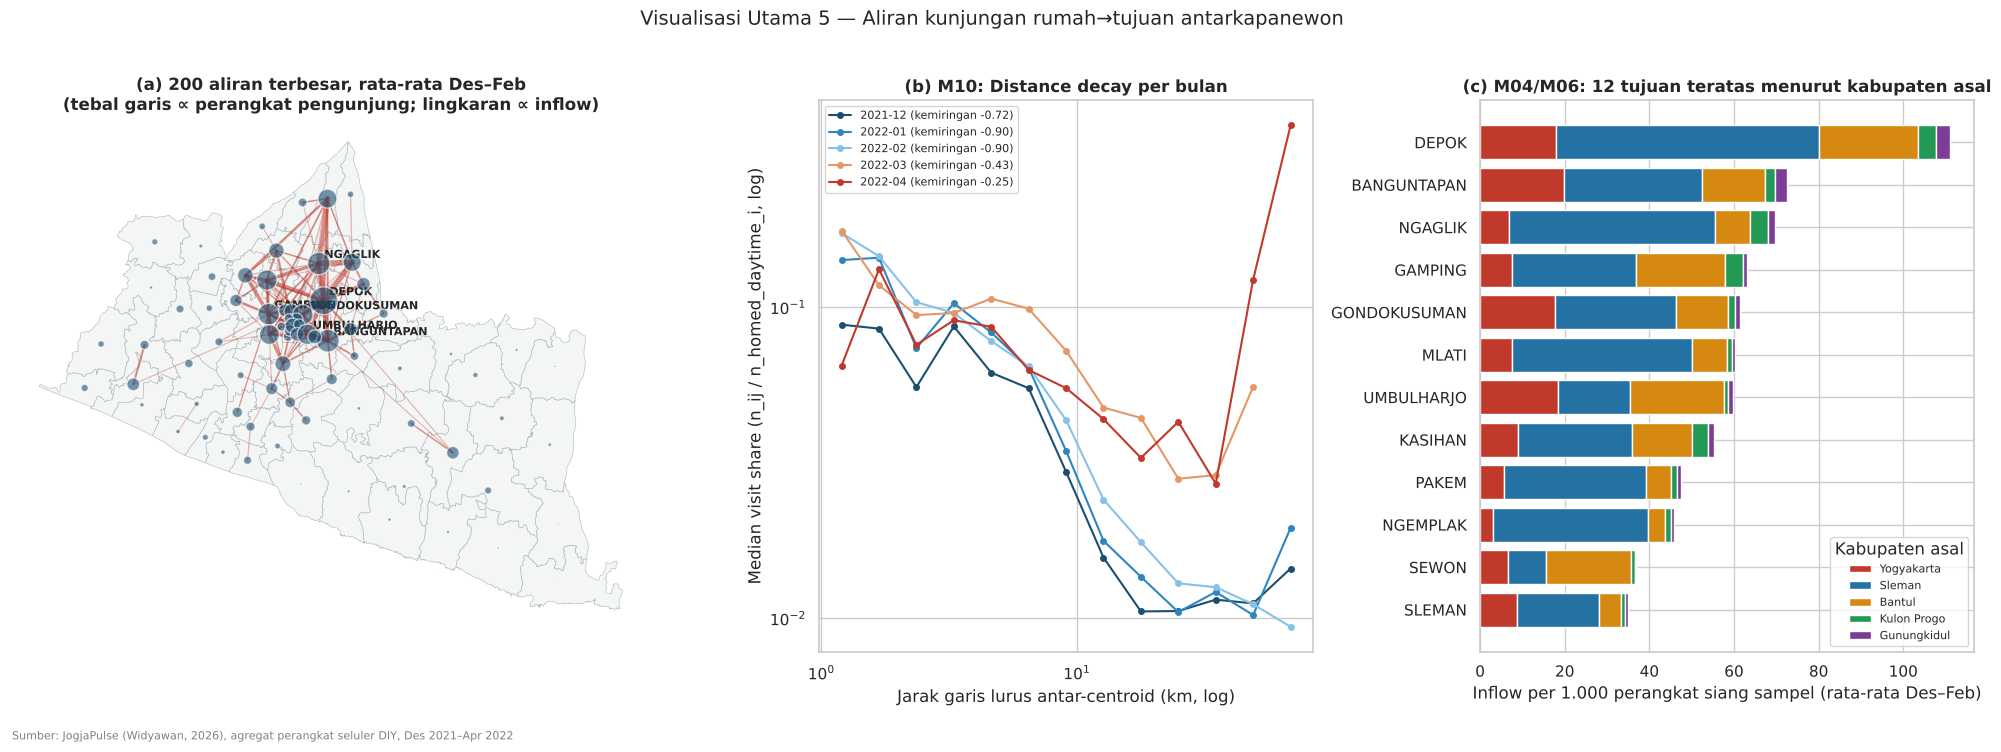

In [90]:
if HAS_BOUNDARY:
    fig, axes = plt.subplots(1, 3, figsize=(20, 7), gridspec_kw={"width_ratios": [1.3, 1, 1]})
    ax = axes[0]
    gdf_kap_simple.plot(ax=ax, color="#f4f6f6", edgecolor="#aab7b8", lw=0.4)
    xy = kapanewon_master.set_index("kapanewon_code")[["lon", "lat"]]
    top_flows = pair_hq.nlargest(200, "n_mean")
    max_n = top_flows.n_mean.max()
    for r in top_flows.itertuples():
        ax.plot([xy.at[r.origin_code, "lon"], xy.at[r.dest_code, "lon"]], [xy.at[r.origin_code, "lat"], xy.at[r.dest_code, "lat"]],
                color="#c0392b", alpha=0.35, lw=0.3 + 4 * r.n_mean / max_n)
    sizes = dest_hq.reindex(xy.index).inflow
    ax.scatter(xy.lon, xy.lat, s=sizes / sizes.max() * 400, color="#1b4f72", alpha=0.6, edgecolor="white", zorder=5)
    for code in dest_hq.inflow.nlargest(6).index:
        ax.annotate(LABEL[code], (xy.at[code, "lon"], xy.at[code, "lat"]), fontsize=8, weight="bold", xytext=(4, 4), textcoords="offset points")
    ax.set_axis_off()
    ax.set_title("(a) 200 aliran terbesar, rata-rata Des–Feb\n(tebal garis ∝ perangkat pengunjung; lingkaran ∝ inflow)")
    ax = axes[1]
    for m, color in zip(ALL_MONTHS, ["#1b4f72", "#2e86c1", "#85c1e9", "#e59866", "#c0392b"]):
        sub = inter[inter.month == m]
        binned = sub.groupby(pd.cut(sub.distance_km, np.logspace(np.log10(1), np.log10(80), 14)), observed=True).visit_share.median()
        centers = [iv.mid for iv in binned.index]
        ax.plot(centers, binned.values, marker="o", ms=4, color=color, label=f"{m} (kemiringan {decay_by_month[m].params.iloc[1]:.2f})")
    ax.set(xscale="log", yscale="log", xlabel="Jarak garis lurus antar-centroid (km, log)", ylabel="Median visit share (n_ij / n_homed_daytime_i, log)",
           title="(b) M10: Distance decay per bulan")
    ax.legend(fontsize=8)
    ax = axes[2]
    top_dest = dest_hq.inflow_per_1000.nlargest(12).index
    stack = (pair_hq[pair_hq.dest_code.isin(top_dest)].assign(origin_kab=lambda d: d.origin_code.map(KAB_OF))
             .groupby(["dest_code", "origin_kab"]).flow_per_1000.sum().unstack(fill_value=0).reindex(top_dest[::-1]))
    left = np.zeros(len(stack))
    for kab in KAB_ORDER:
        if kab in stack:
            ax.barh([LABEL[c] for c in stack.index], stack[kab], left=left, color=KAB_COLORS[kab], label=kab.title())
            left += stack[kab].values
    ax.set(xlabel="Inflow per 1.000 perangkat siang sampel (rata-rata Des–Feb)", title="(c) M04/M06: 12 tujuan teratas menurut kabupaten asal")
    ax.legend(fontsize=8, title="Kabupaten asal")
    fig.suptitle("Visualisasi Utama 5 — Aliran kunjungan rumah→tujuan antarkapanewon", y=1.02)
    fig.tight_layout()
    save_fig(fig, "V5_od_flow_static")
    plt.show()

### 8.x Interpretasi Section 8

- **Skala.** Pada periode HQ, rata-rata perangkat teramati di ±1,4 kapanewon *lain* per bulan (selain kapanewon rumahnya), dan ±90% perangkat teramati di kapanewon rumahnya sendiri pada siang hari. Pada Maret, hanya 53% perangkat berumah yang teramati siang hari — penanda lain penurunan kualitas.
- **M01–M03.** Asal terbesar adalah Depok, Ngaglik, Gamping, Kasihan, Banguntapan (mengikuti ukuran sampel). Intensitas kunjungan eksternal tertinggi justru dimiliki **kemantren Kota Yogyakarta** (Mantrijeron, Wirobrajan, Gedongtengen, Tegalrejo, Mergangsan: ±3–4 kapanewon lain per perangkat per bulan) — wilayahnya kecil sehingga aktivitas harian mudah melintasi batas. Terendah: Gunungkidul (Ngawen, Rongkop, Gedangsari, Ponjong, Semin, Purwosari) serta Tempel dan Minggir di Sleman barat-laut. Intensitas eksternal sangat terkait jarak ke pusat kota (Spearman −0,70) dan hampir tidak terkait ukuran asal (0,18).
- **M04–M06.** Tujuan dengan inflow terbesar: Depok, Banguntapan, Ngaglik, Gamping, Gondokusuman, Mlati, Umbulharjo, Kasihan. Inflow terendah seluruhnya di Gunungkidul selatan/timur (Girisubo, Rongkop, Purwosari, Semin, Tepus). Pengunjung sebuah tujuan umumnya berasal dari banyak asal (median porsi asal terbesar hanya 18%), dan separuhnya berasal dari kabupaten yang sama.
- **M07.** Ya — tetapi **pinggiran dekat**, bukan pinggiran jauh. Intensitas kunjungan ke kota menurun tajam dengan jarak (Spearman −0,78): Banguntapan, Sewon, Kasihan, Gamping, Berbah, Mlati, Depok paling banyak mengunjungi kota (38% kunjungan eksternal Banguntapan dan Sewon menuju kota), sedangkan Gunungkidul hanya ±3%.
- **M08–M10.** Pasangan terbesar berada di koridor utara (Ngaglik↔Depok, Ngaglik→Pakem, Ngaglik↔Ngemplak, Ngemplak→Depok) dan tenggara (Banguntapan→Umbulharjo/Depok). **Distance decay kuat:** 60% kunjungan antarwilayah terjadi pada jarak < 10 km (padahal hanya 13% pasangan), dan 43% menuju kapanewon **bertetangga** (hanya 6,7% pasangan). Kemiringan log-log −0,72 s.d. −0,90 pada Des–Feb, melemah menjadi −0,43 dan −0,25 pada Mar–Apr. Pasangan terjauh yang terpublikasi (±66 km: Wates↔Semin, Wates↔Ponjong) menghubungkan dua ibu kota/kawasan kabupaten di ujung barat dan timur DIY, dengan jumlah kecil (6–11 perangkat).
- **Anomali di data OD.** Pasangan Gondomanan→Sleman memiliki visit share 43% pada jarak 12 km — jauh di luar pola distance decay. Kedua kapanewon inilah yang memuat dua "sel lengket" (Section 7, D06). Ini mendukung dugaan bahwa sebagian perangkat "berpindah" antara dua titik lokasi default, bukan melakukan perjalanan nyata.
- **M11–M13.** Penerima bersih terbesar adalah kemantren kota (Ngampilan, Danurejan, Gedongtengen, Gondokusuman, Tegalrejo, Wirobrajan: inflow 2–5× outflow), sedangkan pengirim bersih adalah Gunungkidul (Girisubo, Semin, Ponjong, Purwosari), Tempel, dan Girimulyo. In-degree dan out-degree sangat ditentukan ukuran sampel (Spearman ukuran vs out-degree 0,94) karena aliran kecil tersuppress.
- **M14.** Hubungan umumnya **dua arah**: ±81% arah aliran terpublikasi memiliki balasan, dan korelasi log n_ij vs n_ji = 0,79–0,82 pada Des–Feb (sama dengan README). Namun setelah dinormalisasi dengan ukuran asal, median |asimetri| ≈ 0,5: kemantren kota kecil mengirim porsi perangkat yang jauh lebih besar ke Depok/Kasihan daripada sebaliknya.
- **M15.** Hubungan OD cukup konsisten dalam periode HQ (Jaccard 0,70–0,75; Spearman 0,79–0,87; 11–16 dari 20 pasangan teratas sama), tetapi set pasangan menyusut tajam pada Maret (Jaccard Feb→Mar 0,42).

In [91]:
m_ds = "od_home_visits_kapanewon_monthly; od_origin_homes_monthly"
m_lim = "Pengunjung ≠ perjalanan; suppression menghapus aliran kecil (lower bound); rata-rata bulanan Des–Feb."
add_insight("M01", "Kapanewon dengan jumlah perangkat asal yang melakukan kunjungan tertinggi", m_ds, "n_homed_maids_daytime",
            "Rata-rata bulanan HQ", "mean n_homed_maids_daytime", "V5", "completed",
            f"{fmt_list(origin_hq.set_index('label').n_homed_maids_daytime.sort_values(ascending=False), 5, '{:,.0f}')} perangkat/bulan.",
            "Mengikuti ukuran sampel: kapanewon padat Sleman & Bantul.", m_lim)
add_insight("M02", "Kapanewon dengan proporsi perangkat yang mengunjungi wilayah lain tertinggi", m_ds, "n_maids, n_homed_maids_daytime",
            "Intensitas kunjungan eksternal", "Σ_{j≠i} n_ij / n_homed_maids_daytime_i", "V5", "completed",
            f"{fmt_list(origin_hq.set_index('label').ext_intensity.sort_values(ascending=False), 6)} kapanewon lain per perangkat; Spearman vs jarak ke pusat = {ext_vs_dist['spearman_rho']:.2f}.",
            "Kemantren kota yang kecil paling sering 'melintas batas'; intensitas turun dengan jarak dari pusat kota.",
            m_lim + " Proporsi unik tidak dapat dihitung (non-aditif); dipakai rata-rata jumlah tujuan per perangkat.")
add_insight("M03", "Kapanewon yang perangkat asalnya relatif jarang teramati di luar wilayah asal", m_ds, "n_maids, n_homed_maids_daytime",
            "Intensitas eksternal terendah & self-share", "Σ_{j≠i} n_ij / N_i; n_ii / N_i", "V5", "completed",
            f"{fmt_list(origin_hq.set_index('label').ext_intensity.sort_values(), 6)}.",
            "Gunungkidul dan Sleman barat-laut (Tempel, Minggir) paling 'mandiri'/jarang keluar.",
            m_lim + " Asal kecil terdampak suppression lebih berat (nilai lebih rendah).")
add_insight("M04", "Kapanewon dengan jumlah perangkat pengunjung masuk tertinggi", m_ds, "n_maids (i≠j)",
            "Inflow = Σ asal (unik per tujuan)", "Σ_{i≠j} n_ij; per 1.000 perangkat siang", "V5(a,c)", "completed",
            f"{fmt_list(dest_hq.set_index('label').inflow_per_1000.sort_values(ascending=False), 6, '{:.1f}')} per 1.000 perangkat sampel.",
            "Depok adalah magnet kunjungan terbesar DIY, diikuti Banguntapan, Ngaglik, Gamping, dan Gondokusuman.", m_lim)
add_insight("M05", "Kapanewon yang paling jarang menerima pengunjung dari luar", m_ds, "n_maids (i≠j)",
            "Inflow terendah", "Σ_{i≠j} n_ij per 1.000", "V5", "completed",
            f"{fmt_list(dest_hq.set_index('label').inflow_per_1000.sort_values(), 6, '{:.2f}')} per 1.000.",
            "Gunungkidul selatan-timur hampir tidak menerima pengunjung yang terekam (juga karena sampel kecil dan suppression).", m_lim)
add_insight("M06", "Asal pengunjung dari setiap kapanewon tujuan", m_ds, "origin_code, dest_code, n_maids",
            "Tiga asal terbesar per tujuan & porsi kabupaten sendiri", "n_ij / Σ_i n_ij", "V5(c); tabel M06", "completed",
            f"Tabel lengkap: outputs/tables/M06_origin_of_visitors_by_destination.csv. Median porsi asal terbesar {m06.porsi_asal_terbesar.median():.0%}; "
            f"median porsi dari kabupaten yang sama {m06['asal_sekabupaten_%'].median():.0f}%. Contoh: Depok ← Ngaglik 12%, Ngemplak 11%, Banguntapan 10%.",
            "Tujuan utama memiliki daerah tangkapan yang luas dan beragam; tetangga langsung mendominasi.", m_lim)
add_insight("M07", "Apakah perangkat dari pinggiran lebih banyak mengunjungi pusat kota?", m_ds + "; batas kapanewon", "n_maids, distance",
            "City intensity vs jarak (Spearman)", "Σ_{j∈Kota} n_ij / N_i", "V5", "completed",
            f"Spearman jarak vs city intensity = {m07_corr['spearman_rho']:.2f}; median city intensity: " +
            ", ".join(f"{k.title()} {v:.3f}" for k, v in m07.groupby('kab_kota').city_intensity.median().items()) + ".",
            "Pinggiran dekat (Banguntapan, Sewon, Kasihan, Gamping) sangat terhubung ke kota; pinggiran jauh (Gunungkidul) jarang.", m_lim)
add_insight("M08", "Pasangan origin-destination dengan jumlah perangkat pengunjung tertinggi", m_ds, "n_maids",
            "Ranking pasangan (rata-rata bulanan HQ)", "mean n_ij", "V5(a)", "completed",
            "; ".join(f"{r.origin}→{r.dest} {r.n_mean:,.0f}" for r in pair_hq.nlargest(6, 'n_mean').itertuples()) + ".",
            "Aliran terbesar berada di koridor utara Sleman (Ngaglik–Depok–Ngemplak–Pakem) dan tenggara (Banguntapan–Umbulharjo).", m_lim)
add_insight("M09", "Pasangan origin-destination dengan jarak centroid terjauh", m_ds + "; batas kapanewon", "distance_km",
            "Jarak Euclidean antar-titik representatif (UTM)", "√(Δx²+Δy²)", "V5", "completed",
            "; ".join(f"{r.origin}→{r.dest} {r.distance_km:.1f} km ({r.n_mean:.0f} perangkat)" for r in pair_hq.nlargest(4, 'distance_km').itertuples()) + ".",
            "Hubungan jarak jauh ada tetapi kecil; menghubungkan pusat-pusat kabupaten di ujung DIY.",
            "Jarak garis lurus, bukan jarak jalan; aliran kecil rentan suppression.")
add_insight("M10", "Apakah kunjungan lebih banyak menuju wilayah berdekatan?", m_ds + "; batas kapanewon", "n_maids, distance_km, adjacency",
            "Distance band, adjacency share, regresi log-log", "share per pita; slope log(visit_share)~log(d)", "V5(b)", "completed",
            f"Kunjungan < 10 km = {within10:.0f}% (pasangan {decay.loc[decay.index[:2], 'porsi_pasangan_mungkin_%'].sum():.0f}%); ke tetangga = {adj_visit_share:.0f}% (pasangan {adj_pair_share:.1f}%). "
            f"Kemiringan: {', '.join(f'{m} {f.params.iloc[1]:.2f}' for m, f in decay_by_month.items())}.",
            "Ya, sangat kuat; distance decay melemah di Mar–Apr karena kualitas data menurun.",
            "Centroid kapanewon besar menyederhanakan jarak; kunjungan intra-kapanewon tidak dihitung.")
add_insight("M11", "Wilayah yang lebih banyak menerima pengunjung dibandingkan mengirim", m_ds, "n_maids",
            "Rasio inflow/outflow (pasangan perangkat-tujuan)", "Σ_i n_ij / Σ_j n_ij", "V6", "completed",
            f"Penerima bersih: {fmt_list(balance.set_index('label').in_out_ratio.sort_values(ascending=False), 6)}. Pengirim bersih: {fmt_list(balance.set_index('label').in_out_ratio.sort_values(), 4)}.",
            "Kemantren kota berfungsi sebagai pusat tujuan; Gunungkidul pinggiran dan Sleman barat-laut sebagai pengirim.", m_lim)
add_insight("M12", "Wilayah yang menerima pengunjung dari banyak kapanewon berbeda", m_ds, "origin_code, dest_code",
            "In-degree (rata-rata bulanan HQ)", "#asal terpublikasi", "V6", "completed",
            f"{fmt_list(balance.set_index('label').in_degree.sort_values(ascending=False), 6, '{:.0f}')} dari 77 asal.",
            "Depok, Banguntapan, Kasihan, Ngaglik, Gamping menerima pengunjung dari hampir semua kapanewon.",
            "Degree dibatasi suppression (asal kecil hilang).")
add_insight("M13", "Wilayah yang memiliki jumlah tujuan kunjungan terbanyak", m_ds, "origin_code, dest_code",
            "Out-degree (rata-rata bulanan HQ)", "#tujuan terpublikasi", "V6", "completed",
            f"{fmt_list(balance.set_index('label').out_degree.sort_values(ascending=False), 6, '{:.0f}')}; Spearman ukuran asal vs out-degree = {deg_size['spearman_rho']:.2f}.",
            "Out-degree terutama mencerminkan besar sampel asal; normalisasi (M02) lebih informatif.",
            "Sangat bergantung ukuran sampel karena suppression k = 5.")
add_insight("M14", "Apakah hubungan antarkawasan bersifat dua arah atau didominasi satu arah?", m_ds, "n_maids, visit_share",
            "Reciprocity: porsi arah berbalas, korelasi log n_ij vs n_ji, indeks asimetri ternormalisasi",
            "(s_ij − s_ji)/(s_ij + s_ji)", "V6", "completed",
            "; ".join(f"{m}: {r['porsi_arah_berbalas_%']:.0f}% berbalas, r = {r.r_log_flows:.2f}" for m, r in recip_table.iterrows()) + ".",
            "Secara jumlah mayoritas dua arah; secara proporsi, kemantren kota kecil 'mengirim' porsi jauh lebih besar ke pusat-pusat Sleman/Bantul daripada sebaliknya.",
            m_lim)
add_insight("M15", "Konsistensi hubungan origin-destination setiap bulan", m_ds, "month, origin_code, dest_code, n_maids",
            "Jaccard, Spearman, overlap top-20 antarbulan", "|A∩B|/|A∪B|; ρ", "V5 (filter bulan)", "completed",
            "; ".join(f"{r.pasangan_bulan}: Jaccard {r.jaccard:.2f}, ρ {r.spearman_flow:.2f}, top-20 sama {r.overlap_top20}" for r in cons_table.itertuples()) + ".",
            "Konsisten dalam Des–Feb; struktur menipis di Mar–Apr karena sampel menyusut.", m_lim)

---
## Section 9 — Regional Attractiveness & Mobility Network (R01–R09)

### 9.1 Metrik daya tarik wilayah
| Metrik | Rumus | Arti |
|---|---|---|
| **Inflow per 1.000** | Σ_{i≠j} n_ij ÷ total perangkat siang sampel × 1.000 | Daya tarik absolut (berapa porsi sampel DIY yang datang). |
| **Rasio pengunjung/penghuni** | inflow_j ÷ n_homed_maids_daytime_j | Berapa pengunjung dari luar per perangkat penghuni. Tidak bergantung pada tingkat keterwakilan wilayah, karena pembilang & penyebut berasal dari sampel yang sama. |
| **Keragaman asal** | exp(entropi Shannon porsi asal) | "Jumlah efektif" kapanewon asal. Nilai 10 berarti pengunjung seolah terbagi rata dari 10 asal. |
| **Porsi dari tetangga** | inflow dari kapanewon berbatasan ÷ inflow | Seberapa "lokal" daerah tangkapan. |
| **Jarak rata-rata pengunjung** | Σ n_ij·d_ij ÷ Σ n_ij | Seberapa jauh asal pengunjung (km). |

In [92]:
attr = dest_hq[["label", "kab_kota", "inflow", "inflow_per_1000", "in_degree"]].join(origin_hq[["n_homed_maids_daytime", "ext_intensity", "out_pairs"]])
attr["visitor_resident_ratio"] = attr.inflow / attr.n_homed_maids_daytime


def shannon_effective(shares):
    p = shares[shares > 0] / shares[shares > 0].sum()
    return float(np.exp(-(p * np.log(p)).sum()))


attr["effective_origins"] = pair_hq.groupby("dest_code").n_mean.apply(shannon_effective)
if HAS_BOUNDARY:
    attr["adjacent_share"] = pair_hq.groupby("dest_code").apply(lambda g: g.loc[g.adjacent, "n_mean"].sum() / g.n_mean.sum())
    attr["mean_visitor_distance_km"] = pair_hq.groupby("dest_code").apply(lambda g: np.average(g.distance_km, weights=g.n_mean))
attr = attr.join(kap_hq[["urban_rural", "day_share_pct", "pop_actual"]])
save_table(attr.reset_index(), "R_attractiveness_metrics_HQ")
MIN_INFLOW = 100   # tujuan dengan inflow sangat kecil diabaikan untuk metrik berbasis proporsi
attr_ok = attr[attr.inflow >= MIN_INFLOW]
print(f"Tujuan dengan inflow ≥ {MIN_INFLOW} perangkat/bulan: {len(attr_ok)} dari 78")

Tabel disimpan: outputs/tables/R_attractiveness_metrics_HQ.csv
Tujuan dengan inflow ≥ 100 perangkat/bulan: 72 dari 78


### R01–R04 — Daya tarik, keragaman, dan jangkauan daerah tangkapan

In [93]:
r_cols = ["label", "kab_kota", "inflow_per_1000", "visitor_resident_ratio", "effective_origins", "adjacent_share", "mean_visitor_distance_km"]
print("R01 — daya tarik absolut (inflow per 1.000):")
display(attr.sort_values("inflow_per_1000", ascending=False)[r_cols].head(6))
print("R01b — rasio pengunjung/penghuni tertinggi:")
display(attr_ok.sort_values("visitor_resident_ratio", ascending=False)[r_cols].head(8))
print("R02 — keragaman asal tertinggi:")
display(attr_ok.sort_values("effective_origins", ascending=False)[r_cols].head(8))
print("R03 — pengunjung terutama dari tetangga:")
display(attr_ok.sort_values("adjacent_share", ascending=False)[r_cols].head(8))
print("R04 — pengunjung dari jarak relatif jauh:")
display(attr_ok.sort_values("mean_visitor_distance_km", ascending=False)[r_cols].head(8))

R01 — daya tarik absolut (inflow per 1.000):


,label,kab_kota,inflow_per_1000,visitor_resident_ratio,effective_origins,adjacent_share,mean_visitor_distance_km
dest_code,,,,,,,
34.04.07,DEPOK,SLEMAN,111.1592,1.2740,27.8332,0.5751,10.2601
34.02.12,BANGUNTAPAN,BANTUL,72.5654,1.2652,28.5626,0.5103,9.6061
34.04.12,NGAGLIK,SLEMAN,69.6923,1.0610,23.7305,0.5466,11.4477
34.04.01,GAMPING,SLEMAN,63.0558,1.0607,30.3367,0.3066,9.8305
34.71.03,GONDOKUSUMAN,YOGYAKARTA,61.3962,4.2060,24.2321,0.3837,7.3512
34.04.06,MLATI,SLEMAN,60.1564,1.7173,22.1173,0.6406,9.3323


R01b — rasio pengunjung/penghuni tertinggi:


,label,kab_kota,inflow_per_1000,visitor_resident_ratio,effective_origins,adjacent_share,mean_visitor_distance_km
dest_code,,,,,,,
34.71.06,NGAMPILAN,YOGYAKARTA,10.0765,14.6174,26.5758,0.1455,6.0355
34.71.05,GEDONGTENGEN,YOGYAKARTA,13.9018,11.7722,25.0997,0.1391,6.5252
34.71.04,DANUREJAN,YOGYAKARTA,25.2367,10.3808,22.1085,0.1921,5.4961
34.71.07,WIROBRAJAN,YOGYAKARTA,12.9924,7.8638,20.7893,0.3039,5.8103
34.71.08,MANTRIJERON,YOGYAKARTA,14.5154,7.0974,21.9158,0.4013,6.2071
34.71.01,TEGALREJO,YOGYAKARTA,23.8715,6.4759,28.3312,0.3182,8.8021
34.71.12,MERGANGSAN,YOGYAKARTA,27.5600,5.8245,19.6323,0.4453,5.3655
34.71.11,PAKUALAMAN,YOGYAKARTA,18.9415,4.3876,12.7598,0.5813,3.9728


R02 — keragaman asal tertinggi:


,label,kab_kota,inflow_per_1000,visitor_resident_ratio,effective_origins,adjacent_share,mean_visitor_distance_km
dest_code,,,,,,,
34.03.01,WONOSARI,GUNUNGKIDUL,22.1832,1.2596,34.9243,0.2128,27.8328
34.02.16,KASIHAN,BANTUL,55.2089,0.9626,34.2471,0.3308,10.1641
34.71.10,GONDOMANAN,YOGYAKARTA,34.5365,2.2193,33.3373,0.0972,8.3856
34.02.10,IMOGIRI,BANTUL,12.3738,0.8426,31.8119,0.2685,14.3293
34.04.01,GAMPING,SLEMAN,63.0558,1.0607,30.3367,0.3066,9.8305
34.01.06,SENTOLO,KULON PROGO,10.5872,1.2928,29.4450,0.2535,14.8046
34.02.06,PANDAK,BANTUL,15.0572,1.3043,29.1123,0.3152,13.4168
34.02.13,PLERET,BANTUL,16.4771,1.5712,29.1076,0.3689,13.0337


R03 — pengunjung terutama dari tetangga:


,label,kab_kota,inflow_per_1000,visitor_resident_ratio,effective_origins,adjacent_share,mean_visitor_distance_km
dest_code,,,,,,,
34.02.11,DLINGO,BANTUL,1.6808,0.8434,4.7619,0.6881,11.1841
34.02.04,PUNDONG,BANTUL,4.9094,0.6816,10.6451,0.6800,8.5251
34.01.05,LENDAH,KULON PROGO,4.0230,0.7250,11.0423,0.6751,9.5639
34.04.11,NGEMPLAK,SLEMAN,45.7603,1.1857,14.1048,0.6746,10.3272
34.04.08,BERBAH,SLEMAN,24.5492,2.0815,15.8635,0.6502,8.2153
34.04.06,MLATI,SLEMAN,60.1564,1.7173,22.1173,0.6406,9.3323
34.02.07,PAJANGAN,BANTUL,7.0893,1.6154,15.2074,0.6340,8.8753
34.04.03,MOYUDAN,SLEMAN,6.1270,0.8828,13.9085,0.6009,8.4495


R04 — pengunjung dari jarak relatif jauh:


,label,kab_kota,inflow_per_1000,visitor_resident_ratio,effective_origins,adjacent_share,mean_visitor_distance_km
dest_code,,,,,,,
34.03.08,SEMANU,GUNUNGKIDUL,6.8714,2.0867,26.5964,0.2563,32.0895
34.03.17,TANJUNGSARI,GUNUNGKIDUL,1.3298,1.5339,13.6193,0.4454,28.5157
34.03.01,WONOSARI,GUNUNGKIDUL,22.1832,1.2596,34.9243,0.2128,27.8328
34.03.10,PONJONG,GUNUNGKIDUL,1.6491,0.4204,13.9469,0.3424,26.5915
34.01.01,TEMON,KULON PROGO,7.6470,1.4198,23.0459,0.2952,26.2040
34.03.13,NGAWEN,GUNUNGKIDUL,1.1855,1.2031,10.8579,0.3669,25.2693
34.03.15,SAPTOSARI,GUNUNGKIDUL,1.4116,1.7056,15.6190,0.2548,24.3554
34.01.02,WATES,KULON PROGO,22.6827,1.7748,28.6295,0.2370,22.9239


### R05–R06 — Inflow vs outflow (ternormalisasi)
Kuadran berdasarkan median **rasio pengunjung/penghuni** (inflow ternormalisasi) dan **intensitas kunjungan eksternal** (outflow ternormalisasi, M02):
- R05 = inflow tinggi & outflow rendah → **"magnet"** (banyak didatangi, penghuninya jarang keluar).
- R06 = inflow rendah & outflow tinggi → **"pengirim"** (jarang didatangi, penghuninya sering keluar).

In [94]:
vr_med, ext_med = attr.visitor_resident_ratio.median(), attr.ext_intensity.median()
attr["flow_quadrant"] = np.select(
    [(attr.visitor_resident_ratio >= vr_med) & (attr.ext_intensity < ext_med),
     (attr.visitor_resident_ratio < vr_med) & (attr.ext_intensity >= ext_med),
     (attr.visitor_resident_ratio >= vr_med) & (attr.ext_intensity >= ext_med)],
    ["Magnet (inflow tinggi, outflow rendah)", "Pengirim (inflow rendah, outflow tinggi)", "Hub dua arah (keduanya tinggi)"],
    "Lokal/mandiri (keduanya rendah)")
print(attr.flow_quadrant.value_counts().to_string())
r05 = attr[attr.flow_quadrant.str.startswith("Magnet")].sort_values("visitor_resident_ratio", ascending=False)
r06 = attr[attr.flow_quadrant.str.startswith("Pengirim")].sort_values("ext_intensity", ascending=False)
display(r05[["label", "kab_kota", "visitor_resident_ratio", "ext_intensity", "inflow"]])
display(r06[["label", "kab_kota", "visitor_resident_ratio", "ext_intensity", "inflow"]])
print(pd.crosstab(attr.flow_quadrant, attr.kab_kota))

flow_quadrant
Hub dua arah (keduanya tinggi)              27
Lokal/mandiri (keduanya rendah)             27
Magnet (inflow tinggi, outflow rendah)      12
Pengirim (inflow rendah, outflow tinggi)    12


,label,kab_kota,visitor_resident_ratio,ext_intensity,inflow
dest_code,,,,,
34.03.08,SEMANU,GUNUNGKIDUL,2.0867,0.8018,610.0000
34.03.15,SAPTOSARI,GUNUNGKIDUL,1.7056,1.0133,121.6667
34.02.13,PLERET,BANTUL,1.5712,1.1868,"1,445.0000"
34.04.16,PAKEM,SLEMAN,1.5703,1.1756,"4,254.0000"
34.03.17,TANJUNGSARI,GUNUNGKIDUL,1.5339,0.9027,113.0000
34.02.05,BAMBANGLIPURO,BANTUL,1.4865,1.1720,988.0000
34.04.13,SLEMAN,SLEMAN,1.4386,1.2109,"2,813.3333"
34.01.10,NANGGULAN,KULON PROGO,1.3767,1.1548,757.6667
34.01.03,PANJATAN,KULON PROGO,1.3722,1.1737,227.3333


,label,kab_kota,visitor_resident_ratio,ext_intensity,inflow
dest_code,,,,,
34.02.14,PIYUNGAN,BANTUL,1.1673,1.6810,900.0000
34.04.01,GAMPING,SLEMAN,1.0607,1.6438,"5,479.0000"
34.01.07,PENGASIH,KULON PROGO,1.2007,1.5405,993.0000
34.01.04,GALUR,KULON PROGO,0.9369,1.5254,232.6667
34.04.05,SEYEGAN,SLEMAN,1.0955,1.4612,"2,906.6667"
34.04.09,PRAMBANAN,SLEMAN,1.0834,1.4431,"1,000.6667"
34.02.02,SANDEN,BANTUL,1.1011,1.4006,236.0000
34.04.12,NGAGLIK,SLEMAN,1.0610,1.3716,"5,937.6667"
34.04.11,NGEMPLAK,SLEMAN,1.1857,1.3285,"3,870.6667"


kab_kota                                  BANTUL  GUNUNGKIDUL  KULON PROGO  SLEMAN  YOGYAKARTA
flow_quadrant                                                                                 
Hub dua arah (keduanya tinggi)                 3            4            3       3          14
Lokal/mandiri (keduanya rendah)                8            9            4       6           0
Magnet (inflow tinggi, outflow rendah)         3            5            2       2           0
Pengirim (inflow rendah, outflow tinggi)       3            0            3       6           0


### R07–R08 — Aktivitas lokal vs daya tarik, dan pusat aktivitas vs pusat permukiman

In [95]:
r07_abs = corr_report(np.log10(attr.day_share_pct), np.log10(attr.inflow_per_1000.replace(0, np.nan)), "log aktivitas siang vs log inflow")
r07_norm = corr_report(kap_hq.api.reindex(attr.index), attr.visitor_resident_ratio, "API vs rasio pengunjung/penghuni")
print(f"Spearman log pangsa aktivitas siang vs log inflow: {r07_abs['spearman_rho']:.3f}")
print(f"Spearman indeks aktivitas/penduduk (API) vs rasio pengunjung/penghuni: {r07_norm['spearman_rho']:.3f} (p = {r07_norm['spearman_p']:.1e})")
r07_fit = smf.ols("np.log10(inflow_per_1000) ~ np.log10(day_share_pct)", data=attr[attr.inflow > 0]).fit()
attr["inflow_residual"] = np.log10(attr.inflow_per_1000.replace(0, np.nan)) - r07_fit.predict(attr)
print(f"log10 inflow = {r07_fit.params.iloc[0]:.2f} + {r07_fit.params.iloc[1]:.2f}·log10 aktivitas siang; R² = {r07_fit.rsquared:.3f}")
print("Inflow lebih tinggi dari yang diperkirakan aktivitas lokalnya (residual positif):")
display(attr.sort_values("inflow_residual", ascending=False)[["label", "kab_kota", "day_share_pct", "inflow_per_1000", "inflow_residual"]].head(6))
print("Inflow lebih rendah dari perkiraan:")
display(attr.sort_values("inflow_residual")[["label", "kab_kota", "day_share_pct", "inflow_per_1000", "inflow_residual"]].head(6))

if HAS_BOUNDARY:
    xyk = kapanewon_master.set_index("kapanewon_code")[["cx_utm", "cy_utm"]]
    def wcenter(w):
        w = w.reindex(xyk.index).fillna(0)
        return np.average(xyk.cx_utm, weights=w), np.average(xyk.cy_utm, weights=w)
    centers_od = pd.DataFrame({
        "Inflow pengunjung (OD)": wcenter(attr.inflow), "Perangkat berumah bulanan (OD)": wcenter(origin_hq.n_homed_maids_daytime),
        "Aktivitas siang (hourly)": wcenter(kap_hq.day_share_pct), "Penduduk resmi": wcenter(kap_hq.pop_actual)}, index=["x", "y"]).T
    ref = centers_od.loc["Perangkat berumah bulanan (OD)"]
    centers_od["jarak_ke_pusat_permukiman_OD_km"] = np.hypot(centers_od.x - ref.x, centers_od.y - ref.y) / 1000
    centers_od["jarak_ke_pusat_kota_km"] = np.hypot(centers_od.x - city_center.x, centers_od.y - city_center.y) / 1000
    display(centers_od.round(2))

Spearman log pangsa aktivitas siang vs log inflow: 0.898
Spearman indeks aktivitas/penduduk (API) vs rasio pengunjung/penghuni: 0.281 (p = 1.3e-02)
log10 inflow = 1.10 + 1.14·log10 aktivitas siang; R² = 0.844
Inflow lebih tinggi dari yang diperkirakan aktivitas lokalnya (residual positif):


,label,kab_kota,day_share_pct,inflow_per_1000,inflow_residual
dest_code,,,,,
34.71.06,NGAMPILAN,YOGYAKARTA,0.2067,10.0765,0.6769
34.71.05,GEDONGTENGEN,YOGYAKARTA,0.3015,13.9018,0.6304
34.71.04,DANUREJAN,YOGYAKARTA,0.6387,25.2367,0.5189
34.71.07,WIROBRAJAN,YOGYAKARTA,0.3775,12.9924,0.4901
34.71.11,PAKUALAMAN,YOGYAKARTA,0.5702,18.9415,0.4503
34.71.08,MANTRIJERON,YOGYAKARTA,0.4725,14.5154,0.4274


Inflow lebih rendah dari perkiraan:


,label,kab_kota,day_share_pct,inflow_per_1000,inflow_residual
dest_code,,,,,
34.03.12,SEMIN,GUNUNGKIDUL,0.2067,0.5813,-0.5618
34.04.14,TEMPEL,SLEMAN,1.7007,6.9169,-0.5266
34.03.10,PONJONG,GUNUNGKIDUL,0.4235,1.6491,-0.4630
34.03.14,GEDANGSARI,GUNUNGKIDUL,0.3581,1.8435,-0.3319
34.01.09,GIRIMULYO,KULON PROGO,0.2875,1.4843,-0.3177
34.01.08,KOKAP,KULON PROGO,0.8909,5.7368,-0.2887


,x,y,jarak_ke_pusat_permukiman_OD_km,jarak_ke_pusat_kota_km
Inflow pengunjung (OD),"430,621.0900","9,138,190.7900",0.3200,0.8900
Perangkat berumah bulanan (OD),"430,327.4000","9,138,310.7300",0.0000,1.1500
Aktivitas siang (hourly),"430,376.1800","9,137,930.9600",0.3800,0.8400
Penduduk resmi,"433,213.0600","9,133,081.9200",5.9700,4.8400


### R09 — Karakter kunjungan kawasan wisata vs nonwisata
Membutuhkan label lokasi wisata (Section 0.3).

In [96]:
if HAS_TOURISM and HAS_BOUNDARY:
    attr["has_tourism_cell"] = attr.index.isin(cell_stats[cell_stats.is_tourism_cell].kapanewon_code.unique())
    display(attr.groupby("has_tourism_cell")[["visitor_resident_ratio", "effective_origins", "mean_visitor_distance_km", "adjacent_share"]].median())
else:
    print("POI wisata belum tersedia -> R09 ditandai 'requires external data'.")

POI wisata belum tersedia -> R09 ditandai 'requires external data'.


### 9.2 Jaringan mobilitas (NetworkX)
**Apa itu analisis jaringan?** Wilayah diperlakukan sebagai **node** dan hubungan kunjungan sebagai **edge** berarah (asal → tujuan) dengan **bobot** = perangkat pengunjung (per 1.000 perangkat siang sampel agar antarbulan sebanding).

| Metrik | Arti sederhana |
|---|---|
| **In-degree / out-degree** | Jumlah kapanewon berbeda yang mengirim ke / dikunjungi dari node ini. |
| **In-strength / out-strength** | Jumlah bobot edge masuk / keluar (besarnya kunjungan, bukan sekadar jumlah hubungan). |
| **Betweenness centrality** | Seberapa sering node berada di jalur "terpendek" antara pasangan node lain dalam jaringan. Panjang edge = 1/bobot, sehingga hubungan kuat = "dekat". **Ini metrik topologi jaringan kunjungan, bukan jalur fisik yang dilalui perangkat** — data OD tidak memuat rute. |
| **Reciprocity** | Porsi edge yang memiliki edge balasan (i→j dan j→i). |
| **Density** | Edge yang ada ÷ edge yang mungkin (78 × 77). |

Jaringan dibuat per bulan (5 jaringan) dan satu jaringan gabungan periode HQ (bobot = rata-rata bulanan Des–Feb).

In [97]:
def build_graph(edges, weight_col):
    G = nx.DiGraph()
    G.add_nodes_from(kapanewon_master.kapanewon_code)
    for r in edges.itertuples():
        w = getattr(r, weight_col)
        if w > 0:
            G.add_edge(r.origin_code, r.dest_code, weight=w, distance=1.0 / w)
    return G


def network_metrics(G):
    betweenness = nx.betweenness_centrality(G, weight="distance", normalized=True)
    return pd.DataFrame({
        "in_degree": dict(G.in_degree()), "out_degree": dict(G.out_degree()),
        "in_strength": dict(G.in_degree(weight="weight")), "out_strength": dict(G.out_degree(weight="weight")),
        "betweenness": betweenness, "node_reciprocity": nx.reciprocity(G, G.nodes()),
    })


graphs = {m: build_graph(inter[inter.month == m], "flow_per_1000") for m in ALL_MONTHS}
graphs["HQ (Des–Feb)"] = build_graph(pair_hq, "flow_per_1000")
net_summary = pd.DataFrame({name: {"nodes_with_edges": sum(1 for n in G if G.degree(n) > 0), "edges": G.number_of_edges(),
                                   "density": nx.density(G), "reciprocity": nx.reciprocity(G),
                                   "weakly_connected_components": nx.number_weakly_connected_components(G)}
                            for name, G in graphs.items()}).T
display(net_summary.round(3))

net_hq = network_metrics(graphs["HQ (Des–Feb)"]).join(LABEL).join(KAB_OF)
net_hq["strength_ratio_in_out"] = net_hq.in_strength / net_hq.out_strength
monthly_betweenness = pd.DataFrame({m: network_metrics(graphs[m]).betweenness for m in ALL_MONTHS})
bt_stability = monthly_betweenness[HQ_MONTHS].corr(method="spearman")
print("Betweenness tertinggi (jaringan HQ):")
display(net_hq.sort_values("betweenness", ascending=False)[["label", "kab_kota", "betweenness", "in_strength", "out_strength", "in_degree", "out_degree", "node_reciprocity"]].head(10))
print("Spearman betweenness antarbulan HQ:")
display(bt_stability.round(3))
top_bt_month = monthly_betweenness.idxmax().map(LABEL)
print("Node betweenness tertinggi per bulan:", top_bt_month.to_dict())
save_table(net_hq.reset_index(), "R_network_metrics_HQ")

,nodes_with_edges,edges,density,reciprocity,weakly_connected_components
2021-12,78.0000,"2,517.0000",0.4190,0.8070,1.0000
2022-01,78.0000,"2,546.0000",0.4240,0.8240,1.0000
2022-02,78.0000,"2,575.0000",0.4290,0.8050,1.0000
2022-03,77.0000,"1,124.0000",0.1870,0.7310,2.0000
2022-04,72.0000,742.0000,0.1240,0.7140,7.0000
HQ (Des–Feb),78.0000,"3,228.0000",0.5370,0.8550,1.0000


Betweenness tertinggi (jaringan HQ):


,label,kab_kota,betweenness,in_strength,out_strength,in_degree,out_degree,node_reciprocity
34.04.07,DEPOK,SLEMAN,0.5417,111.1592,126.4412,74,75,0.9664
34.03.01,WONOSARI,GUNUNGKIDUL,0.3019,22.1832,18.7877,61,66,0.8976
34.04.01,GAMPING,SLEMAN,0.2997,63.0558,94.5822,69,70,0.9784
34.02.12,BANGUNTAPAN,BANTUL,0.2138,72.5654,100.5003,73,72,0.9793
34.02.16,KASIHAN,BANTUL,0.1700,55.2089,76.2995,72,73,0.9517
34.02.15,SEWON,BANTUL,0.1316,36.9562,45.4839,61,65,0.9524
34.01.02,WATES,KULON PROGO,0.0851,22.6827,16.8358,58,57,0.9043
34.04.05,SEYEGAN,SLEMAN,0.0795,30.1312,40.9810,60,66,0.9365
34.04.06,MLATI,SLEMAN,0.0689,60.1564,59.7029,64,62,0.9365
34.71.13,UMBULHARJO,YOGYAKARTA,0.0678,59.7555,67.5559,65,61,0.9365


Spearman betweenness antarbulan HQ:


,2021-12,2022-01,2022-02
2021-12,1.0000,0.9000,0.7820
2022-01,0.9000,1.0000,0.8380
2022-02,0.7820,0.8380,1.0000


Node betweenness tertinggi per bulan: {'2021-12': 'GAMPING', '2022-01': 'DEPOK', '2022-02': 'DEPOK', '2022-03': 'GONDOMANAN', '2022-04': 'GONDOMANAN'}
Tabel disimpan: outputs/tables/R_network_metrics_HQ.csv


### Visualisasi Utama 6 — Mobility Network Analysis

Gambar disimpan: outputs/figures/V6_mobility_network.png


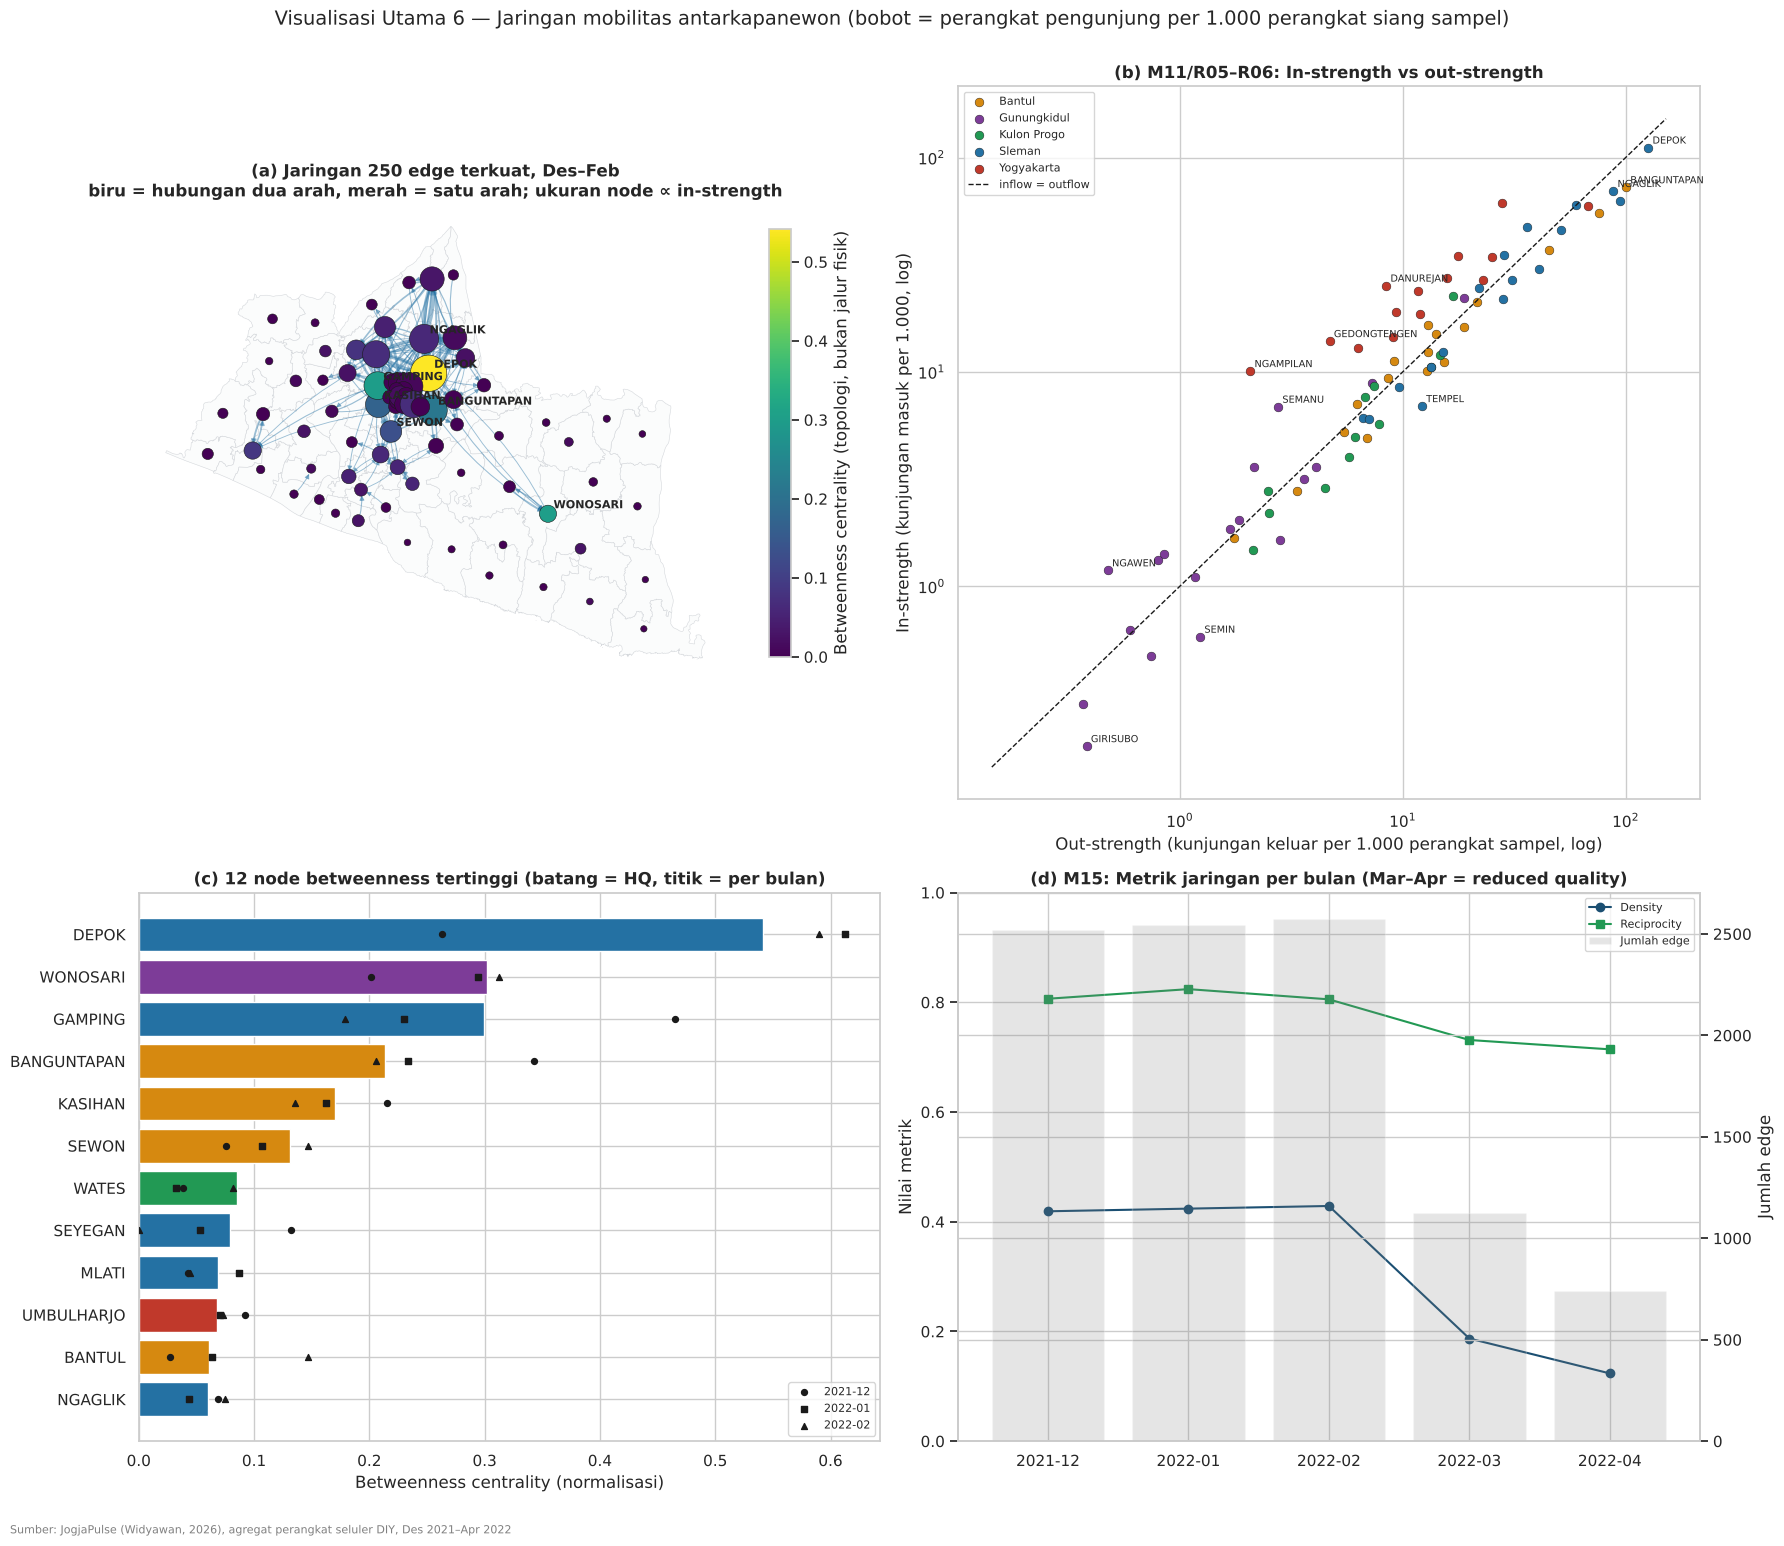

In [98]:
if HAS_BOUNDARY:
    G = graphs["HQ (Des–Feb)"]
    pos = {c: (r.lon, r.lat) for c, r in kapanewon_master.set_index("kapanewon_code")[["lon", "lat"]].iterrows()}
    fig, axes = plt.subplots(2, 2, figsize=(18, 15), gridspec_kw={"height_ratios": [1.3, 1]})
    ax = axes[0, 0]
    gdf_kap_simple.plot(ax=ax, color="#fbfcfc", edgecolor="#d5d8dc", lw=0.4)
    edges = sorted(G.edges(data=True), key=lambda e: e[2]["weight"], reverse=True)[:250]
    max_w = edges[0][2]["weight"]
    for u, v, d in edges:
        reciprocal = G.has_edge(v, u)
        ax.annotate("", xy=pos[v], xytext=pos[u],
                    arrowprops=dict(arrowstyle="-|>", lw=0.3 + 3.5 * d["weight"] / max_w, alpha=0.45,
                                    color="#2471a3" if reciprocal else "#c0392b", shrinkA=4, shrinkB=4, mutation_scale=7,
                                    connectionstyle="arc3,rad=0.12"))
    bt = net_hq.betweenness.reindex(list(pos))
    sc = ax.scatter([pos[c][0] for c in pos], [pos[c][1] for c in pos], s=20 + net_hq.in_strength.reindex(list(pos)) * 6,
                    c=bt, cmap="viridis", edgecolor="k", lw=0.4, zorder=5)
    plt.colorbar(sc, ax=ax, shrink=0.6, label="Betweenness centrality (topologi, bukan jalur fisik)")
    for c in net_hq.betweenness.nlargest(6).index.union(net_hq.in_strength.nlargest(4).index):
        ax.annotate(LABEL[c], pos[c], fontsize=8, weight="bold", xytext=(4, 4), textcoords="offset points", zorder=6)
    ax.set_axis_off()
    ax.set_title("(a) Jaringan 250 edge terkuat, Des–Feb\nbiru = hubungan dua arah, merah = satu arah; ukuran node ∝ in-strength")
    ax = axes[0, 1]
    for kab, g in net_hq.groupby("kab_kota"):
        ax.scatter(g.out_strength, g.in_strength, s=40, color=KAB_COLORS[kab], label=kab.title(), edgecolor="k", lw=0.3)
    lim = [net_hq[["in_strength", "out_strength"]].replace(0, np.nan).min().min() * 0.8, net_hq[["in_strength", "out_strength"]].max().max() * 1.2]
    ax.plot(lim, lim, "k--", lw=1, label="inflow = outflow")
    for c in net_hq.strength_ratio_in_out.replace(np.inf, np.nan).dropna().nlargest(5).index.union(net_hq.strength_ratio_in_out.nsmallest(3).index).union(net_hq.in_strength.nlargest(3).index):
        ax.annotate(LABEL[c], (net_hq.at[c, "out_strength"], net_hq.at[c, "in_strength"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
    ax.set(xscale="log", yscale="log", xlabel="Out-strength (kunjungan keluar per 1.000 perangkat sampel, log)",
           ylabel="In-strength (kunjungan masuk per 1.000, log)", title="(b) M11/R05–R06: In-strength vs out-strength")
    ax.legend(fontsize=8)
    ax = axes[1, 0]
    top_bt = net_hq.betweenness.nlargest(12)
    ax.barh([LABEL[c] for c in top_bt.index[::-1]], top_bt.values[::-1], color=[KAB_COLORS[KAB_OF[c]] for c in top_bt.index[::-1]])
    for m, marker in zip(HQ_MONTHS, ["o", "s", "^"]):
        ax.scatter(monthly_betweenness.loc[top_bt.index[::-1], m], range(len(top_bt)), marker=marker, color="k", s=18, label=f"{m}", zorder=5)
    ax.set(xlabel="Betweenness centrality (normalisasi)", title="(c) 12 node betweenness tertinggi (batang = HQ, titik = per bulan)")
    ax.legend(fontsize=8)
    ax = axes[1, 1]
    ns = net_summary.loc[ALL_MONTHS]
    ax.plot(ns.index, ns.density, marker="o", label="Density", color="#1b4f72")
    ax.plot(ns.index, ns.reciprocity, marker="s", label="Reciprocity", color="#229954")
    ax4 = ax.twinx()
    ax4.bar(ns.index, ns.edges, alpha=0.2, color="gray", label="Jumlah edge")
    ax4.set_ylabel("Jumlah edge")
    ax.set(ylim=(0, 1), ylabel="Nilai metrik", title="(d) M15: Metrik jaringan per bulan (Mar–Apr = reduced quality)")
    h1, l1 = ax.get_legend_handles_labels()
    h2, l2 = ax4.get_legend_handles_labels()
    ax.legend(h1 + h2, l1 + l2, fontsize=8, loc="upper right")
    fig.suptitle("Visualisasi Utama 6 — Jaringan mobilitas antarkapanewon (bobot = perangkat pengunjung per 1.000 perangkat siang sampel)", y=1.0)
    fig.tight_layout()
    save_fig(fig, "V6_mobility_network")
    plt.show()

### 9.x Interpretasi Section 9

- **R01.** Secara absolut, Depok adalah tujuan dengan daya tarik terbesar (±111 per 1.000 perangkat sampel per bulan), diikuti Banguntapan, Ngaglik, Gamping, Gondokusuman, Mlati. Secara relatif terhadap jumlah penghuninya, **kemantren inti kota** paling menarik: Ngampilan, Gedongtengen, Danurejan menerima 10–15 pengunjung luar per perangkat penghuni.
- **R02.** Keragaman asal tertinggi: Wonosari (±35 asal efektif — pusat layanan Gunungkidul), Kasihan, Gondomanan, Imogiri, Gamping.
- **R03.** Daerah tangkapan paling "lokal" (≥ 60% pengunjung dari kapanewon bertetangga): Dlingo, Pundong, Lendah, Ngemplak, Berbah, Mlati, Pajangan.
- **R04.** Pengunjung dari jarak terjauh (rata-rata 23–32 km) menuju Gunungkidul (Semanu, Tanjungsari, Wonosari, Ponjong, Ngawen, Saptosari) dan Kulon Progo (Temon, Wates) — wilayah yang jauh dari pusat sehingga pengunjung luarnya pasti datang dari jauh. Semanu dan Tanjungsari juga termasuk "magnet".
- **R05–R06.** "Magnet" (inflow tinggi relatif, outflow rendah) didominasi kapanewon Gunungkidul (Semanu, Saptosari, Tanjungsari, Paliyan, Wonosari) dan beberapa kapanewon Bantul/Sleman (Pleret, Bambanglipuro, Pandak, Pakem, Sleman). "Pengirim" adalah kapanewon pinggiran aglomerasi (Piyungan, Gamping, Seyegan, Prambanan, Ngaglik, Ngemplak, Kasihan, Kalasan) dan Kulon Progo (Pengasih, Galur). Seluruh 14 kemantren kota masuk "hub dua arah".
- **R07.** Aktivitas lokal sangat menentukan inflow (Spearman 0,90; R² log-log 0,84). Wilayah dengan inflow **di atas** perkiraan adalah kemantren inti kota (Ngampilan, Gedongtengen, Danurejan, Wirobrajan, Pakualaman, Mantrijeron) — pusat tujuan murni. Di **bawah** perkiraan: Semin, Tempel, Ponjong, Gedangsari, Girimulyo, Kokap — aktivitasnya terutama dari penghuni sendiri.
- **R08.** Pusat berbobot inflow, perangkat berumah (OD), dan aktivitas siang berjarak < 0,4 km satu sama lain dan ±1 km dari pusat Kota Yogyakarta, sedangkan pusat penduduk resmi berjarak ±6 km. Artinya perbedaan terbesar bukan antara "pusat aktivitas" dan "pusat permukiman" dalam sampel, tetapi antara **sampel perangkat** (bias urban) dan **penduduk resmi**.
- **Jaringan.** Jaringan bulanan HQ memiliki ±2.500 edge, density ±0,42, reciprocity ±0,81, dan seluruh node terhubung. **Depok** adalah node paling sentral (betweenness 0,54), diikuti **Wonosari** (0,30 — penghubung kapanewon Gunungkidul dengan jaringan aglomerasi), Gamping, Banguntapan, Kasihan, Sewon, dan **Wates** (penghubung Kulon Progo). Peringkat betweenness cukup stabil antarbulan HQ (Spearman 0,78–0,90). Pada Mar–Apr, jaringan terfragmentasi (density 0,12–0,19; hingga 7 komponen) dan Gondomanan menjadi node paling sentral — tanda artefak, bukan perubahan struktural.

In [99]:
r_ds = "od_home_visits_kapanewon_monthly; od_origin_homes_monthly; batas kapanewon"
r_lim = "Rata-rata bulanan Des–Feb; suppression menghapus aliran kecil; pengunjung ≠ perjalanan."
add_insight("R01", "Wilayah dengan daya tarik pengunjung tertinggi", r_ds, "n_maids, n_homed_maids_daytime",
            "Inflow per 1.000 & rasio pengunjung/penghuni", "Σ_i n_ij /1.000; inflow_j / N_j", "V5, V6", "completed",
            f"Absolut: {fmt_list(attr.set_index('label').inflow_per_1000.sort_values(ascending=False), 5, '{:.0f}')}. "
            f"Relatif: {fmt_list(attr_ok.set_index('label').visitor_resident_ratio.sort_values(ascending=False), 5, '{:.1f}')}.",
            "Depok magnet terbesar secara absolut; kemantren inti kota magnet terbesar relatif terhadap penghuninya.", r_lim)
add_insight("R02", "Wilayah yang menerima pengunjung dari banyak kapanewon", r_ds, "origin_code, dest_code, n_maids",
            "In-degree & jumlah asal efektif (exp entropi Shannon)", "exp(−Σp·ln p)", "V6", "completed",
            f"Asal efektif tertinggi: {fmt_list(attr_ok.set_index('label').effective_origins.sort_values(ascending=False), 5, '{:.1f}')}. In-degree: lihat M12.",
            "Wonosari menjadi pusat layanan regional dengan daerah tangkapan paling beragam.", r_lim)
add_insight("R03", "Wilayah yang menerima pengunjung terutama dari daerah sekitar", r_ds, "n_maids, adjacency",
            "Porsi inflow dari kapanewon bertetangga (poligon bersinggungan)", "Σ_{i∈adj(j)} n_ij / Σ_i n_ij", "V5", "completed",
            f"{fmt_list(attr_ok.set_index('label').adjacent_share.sort_values(ascending=False), 6, '{:.0%}')}.",
            "Tujuan berskala lokal: kapanewon perdesaan Bantul/Kulon Progo dan pinggiran Sleman timur.", r_lim)
add_insight("R04", "Wilayah yang menerima pengunjung dari jarak relatif jauh", r_ds, "n_maids, distance_km",
            "Jarak rata-rata tertimbang pengunjung", "Σ n_ij d_ij / Σ n_ij", "V5", "completed",
            f"{fmt_list(attr_ok.set_index('label').mean_visitor_distance_km.sort_values(ascending=False), 6, '{:.1f}')} km.",
            "Gunungkidul dan Kulon Progo barat menarik pengunjung dari jauh (sebagian karena letaknya jauh dari pusat).",
            r_lim + " Jarak garis lurus antar-centroid.")
add_insight("R05", "Wilayah dengan inflow tinggi dan outflow rendah", r_ds, "n_maids, n_homed_maids_daytime",
            "Kuadran median rasio pengunjung/penghuni vs intensitas eksternal", "VR ≥ median ∧ ext < median", "V6(b)", "completed",
            f"{len(r05)} kapanewon: {', '.join(r05.label)}.",
            "'Magnet' di luar aglomerasi, terutama Gunungkidul: penghuninya jarang keluar tetapi tetap menerima pengunjung.", r_lim)
add_insight("R06", "Wilayah dengan inflow rendah dan outflow tinggi", r_ds, "n_maids, n_homed_maids_daytime",
            "Kuadran median rasio pengunjung/penghuni vs intensitas eksternal", "VR < median ∧ ext ≥ median", "V6(b)", "completed",
            f"{len(r06)} kapanewon: {', '.join(r06.label)}.",
            "'Pengirim' adalah kapanewon pinggiran aglomerasi (komuter) dan sebagian Kulon Progo.", r_lim)
add_insight("R07", "Hubungan aktivitas lokal dengan daya tarik pengunjung", r_ds + "; presence_kapanewon_hourly", "day_share_pct, inflow",
            "Spearman & OLS log-log; residual", "log inflow ~ log aktivitas siang", "V6", "completed",
            f"Spearman = {r07_abs['spearman_rho']:.2f}; R² = {r07_fit.rsquared:.2f}; elastisitas {r07_fit.params.iloc[1]:.2f}. "
            f"Residual positif terbesar: {fmt_list(attr.set_index('label').inflow_residual.sort_values(ascending=False), 4)}.",
            "Wilayah ramai juga ramai dikunjungi; kemantren inti kota lebih menarik pengunjung daripada yang diperkirakan dari aktivitasnya.",
            "Aktivitas siang mencakup pengunjung itu sendiri (tidak independen).")
add_insight("R08", "Perbedaan pusat aktivitas dan pusat permukiman", r_ds + "; presence_kapanewon_hourly; home_maids_vs_population", "inflow, n_homed, share, pop",
            "Weighted centroid (lihat juga S06)", "Σw·xy/Σw", "V1, V6", "completed",
            "; ".join(f"{k}: {v:.1f} km dari pusat kota" for k, v in centers_od.jarak_ke_pusat_kota_km.items()) + ".",
            "Dalam sampel, pusat kunjungan, pusat 'rumah' perangkat, dan pusat aktivitas siang hampir berimpit di inti kota; pusat penduduk resmi ±6 km ke tenggara.",
            "Perbedaan mencerminkan bias urban sampel.")
add_insight("R09", "Perbedaan karakter kunjungan kawasan wisata dan nonwisata", r_ds + " + (butuh) POI wisata", "metrik R01–R04",
            "Perbandingan median metrik daya tarik wisata vs nonwisata", "median per kelompok", "V6",
            "completed" if HAS_TOURISM else "requires external data",
            "Belum dihitung (tidak ada label wisata). Indikasi: kapanewon pesisir Gunungkidul (Semanu, Tanjungsari, Saptosari) bersifat 'magnet' dengan pengunjung dari jauh.",
            "Hipotesis kawasan wisata perlu diuji dengan POI.", "Butuh data/external/tourism_poi_diy.csv.")
add_insight("R-NET", "Jaringan mobilitas: degree, strength, betweenness, reciprocity (per bulan & HQ)", r_ds, "n_maids",
            "NetworkX DiGraph; betweenness dengan jarak 1/bobot", "nx.betweenness_centrality; nx.reciprocity", "V6", "completed",
            f"HQ: {int(net_summary.loc['HQ (Des–Feb)', 'edges'])} edge, reciprocity {net_summary.loc['HQ (Des–Feb)', 'reciprocity']:.2f}. "
            f"Betweenness tertinggi: {fmt_list(net_hq.set_index('label').betweenness.sort_values(ascending=False), 5)}. "
            f"Density bulanan: {', '.join(f'{m} {v:.2f}' for m, v in net_summary.loc[ALL_MONTHS, 'density'].items())}.",
            "Depok adalah hub jaringan; Wonosari dan Wates menjadi jembatan bagi kabupaten pinggiran. Betweenness = topologi jaringan kunjungan, bukan jalur fisik.",
            "Edge kecil tersuppress; jaringan Mar–Apr terfragmentasi oleh kualitas data.")

---
## Section 10 — Activity Pattern Clustering (L01–L08)

### 10.1 Karakter dominan berbasis LQ (L01–L05)
Sebelum clustering otomatis, kita menjawab pertanyaan sederhana memakai LQ dari Section 5 (cakupan ≥ 90% per periode):
- **L01–L03:** LQ pagi / siang / malam tertinggi.
- **L04:** aktivitas paling merata = simpangan baku **indeks profil relatif** 24 jam terkecil (bentuk ritme paling datar *relatif terhadap DIY*).
- **L05:** selisih LQ siang − LQ malam terbesar (positif = siang-sentris, negatif = malam-sentris).

In [100]:
def top_lq(period, n=6):
    ok = period_cov[period] >= COVERAGE_MIN
    return period_lq.loc[ok, period].sort_values(ascending=False).head(n).rename(index=LABEL)


l01, l02, l03 = top_lq("Pagi"), top_lq("Siang"), top_lq("Malam")
flatness = rel_profile["Semua hari"].std(axis=1)[full_cov].sort_values()
l04 = flatness.head(6).rename(index=LABEL)
day_minus_night = (period_lq["Siang"] - period_lq["Malam"])[(period_cov["Siang"] >= COVERAGE_MIN) & (period_cov["Malam"] >= COVERAGE_MIN)]
l05 = day_minus_night.reindex(day_minus_night.abs().sort_values(ascending=False).index).head(8).rename(index=LABEL)
print("L01 pagi:", fmt_list(l01, 6)); print("L02 siang:", fmt_list(l02, 6)); print("L03 malam:", fmt_list(l03, 6))
print("L04 paling merata (std indeks relatif):", fmt_list(l04, 6, "{:.3f}")); print("L05 selisih LQ siang − malam:", fmt_list(l05, 8))

L01 pagi: NGLIPAR (1.18), SEMIN (1.17), GEDANGSARI (1.16), SAMIGALUH (1.14), SANDEN (1.13), PLAYEN (1.12)
L02 siang: TEPUS (1.54), TANJUNGSARI (1.52), SAPTOSARI (1.50), PALIYAN (1.32), PANGGANG (1.31), NGAWEN (1.29)
L03 malam: PLERET (1.11), MOYUDAN (1.10), PUNDONG (1.09), PANJATAN (1.08), SRANDAKAN (1.08), DLINGO (1.08)
L04 paling merata (std indeks relatif): KALASAN (0.026), BANGUNTAPAN (0.027), SEDAYU (0.036), BERBAH (0.038), SEWON (0.041), KOTAGEDE (0.044)
L05 selisih LQ siang − malam: PALIYAN (0.31), PATUK (0.22), SEMIN (0.16), NGLIPAR (0.15), SEYEGAN (0.15), GIRIMULYO (0.15), JETIS (Yogyakarta) (0.14), PLAYEN (0.14)


### 10.2 Feature engineering & kelayakan data untuk clustering
**Tujuan:** mengelompokkan kapanewon berdasarkan **bentuk ritme harian**, bukan ukurannya.

Fitur (25 fitur per kapanewon):
1. **24 nilai indeks profil relatif per jam** (pangsa jam *h* ÷ rata-rata pangsa 24 jam, periode HQ). Karena memakai pangsa terhadap DIY pada jam yang sama, siklus harian umum sampel sudah dihilangkan, dan karena dibagi rata-rata kapanewon itu sendiri, ukuran wilayah juga hilang.
2. **log rasio akhir pekan/hari kerja** (karakter mingguan).

**StandardScaler** mengubah setiap fitur menjadi rata-rata 0 dan simpangan baku 1, agar tidak ada fitur yang mendominasi hanya karena skalanya lebih besar.

Fitur mobilitas & populasi (rasio keterwakilan, inflow, intensitas eksternal, kepadatan) **tidak** dimasukkan ke clustering, tetapi dipakai untuk **profil cluster** — agar cluster murni mencerminkan ritme aktivitas dan bisa dibandingkan secara independen dengan karakter mobilitasnya.

**Kelayakan.** Uji awal (sel berikut) menunjukkan bahwa jika seluruh 78 kapanewon dimasukkan, K-means hanya memisahkan kapanewon dengan banyak slot tersuppress (profil malam "kosong") dari yang lain — yang dikelompokkan adalah **kelengkapan data**, bukan ritme. Karena itu clustering utama hanya memakai kapanewon dengan **cakupan ≥ 80% di setiap periode waktu**, dan **Gondomanan** dikeluarkan sebagai anomali yang sudah teridentifikasi (Section 5/7). Kapanewon lain diberi label "Tidak di-cluster (cakupan < 80%)".

In [101]:
features = rel_profile["Semua hari"].copy()
features.columns = [f"h{h:02d}" for h in features.columns]
features["log_weekend_ratio"] = np.log(kap_hq.weekend_ratio.reindex(features.index))
CLUSTER_COVERAGE_MIN = 80
min_period_cov = period_cov.min(axis=1).reindex(features.index)

# Uji awal: semua 78 kapanewon
X_all = StandardScaler().fit_transform(features)
naive_labels = KMeans(n_clusters=2, n_init=50, random_state=RANDOM_STATE).fit_predict(X_all)
print("Uji awal (78 kapanewon, k=2): silhouette", round(silhouette_score(X_all, naive_labels), 3))
print(pd.crosstab(pd.Series(naive_labels, index=features.index, name="cluster_naif"),
                  (min_period_cov >= CLUSTER_COVERAGE_MIN).rename("cakupan≥80%")))

eligible = (min_period_cov >= CLUSTER_COVERAGE_MIN) & (features.index != GONDOMANAN)
features_ok = features[eligible]
X = StandardScaler().fit_transform(features_ok)
print(f"\nKapanewon yang di-cluster: {eligible.sum()} | dikeluarkan: {(~eligible).sum()} "
      f"(cakupan < {CLUSTER_COVERAGE_MIN}%: {((min_period_cov < CLUSTER_COVERAGE_MIN)).sum()}, anomali Gondomanan: 1)")
print("Dikeluarkan per kabupaten:", KAB_OF[~eligible].value_counts().to_dict())

# Profil batas atas (rata-rata pangsa hanya atas slot terpublikasi) untuk uji sensitivitas
upper = panel_hq.groupby(["kapanewon_code", "hour"]).share.mean().unstack()
upper_rel = upper.div(upper.mean(axis=1), axis=0)
upper_rel.columns = [f"h{h:02d}" for h in upper_rel.columns]
upper_rel["log_weekend_ratio"] = features.log_weekend_ratio
X_upper = StandardScaler().fit_transform(upper_rel.loc[features_ok.index])

Uji awal (78 kapanewon, k=2): silhouette 0.465
cakupan≥80%   False  True 
cluster_naif              
0                16      0
1                 8     54

Kapanewon yang di-cluster: 53 | dikeluarkan: 25 (cakupan < 80%: 24, anomali Gondomanan: 1)
Dikeluarkan per kabupaten: {'GUNUNGKIDUL': 15, 'YOGYAKARTA': 5, 'KULON PROGO': 3, 'BANTUL': 2}


### 10.3 Memilih jumlah cluster (K-means + silhouette)
**K-means** membagi data menjadi *k* kelompok dengan meminimalkan jarak setiap titik ke pusat (centroid) kelompoknya. Kelemahannya: *k* harus ditentukan dan hasil bergantung inisialisasi (kita pakai `n_init=50`, `random_state` tetap).

**Silhouette score** (−1 s.d. 1) mengukur seberapa mirip sebuah titik dengan kelompoknya dibanding kelompok terdekat lain. Semakin tinggi, semakin jelas pemisahannya; ±0,25–0,5 = struktur lemah–sedang, > 0,5 = kuat. Kita juga melihat **inertia** (metode *elbow*), membandingkan dengan **hierarchical clustering (Ward)**, dan dengan clustering pada **profil batas atas** sebagai uji stabilitas (*Adjusted Rand Index*, ARI: 1 = pembagian identik, 0 = setara acak).

**Aturan pemilihan k (ditetapkan sebelum melihat hasil):** silhouette K-means tertinggi di antara k = 2–8 yang cluster terkecilnya ≥ 3 kapanewon.

In [102]:
k_range = range(2, 9)
k_eval = []
for k in k_range:
    km = KMeans(n_clusters=k, n_init=50, random_state=RANDOM_STATE).fit(X)
    ward_labels = fcluster(linkage(X, method="ward"), k, criterion="maxclust")
    upper_labels = KMeans(n_clusters=k, n_init=50, random_state=RANDOM_STATE).fit_predict(X_upper)
    k_eval.append({"k": k, "silhouette_kmeans": silhouette_score(X, km.labels_), "inertia": km.inertia_,
                   "silhouette_ward": silhouette_score(X, ward_labels), "ARI_vs_ward": adjusted_rand_score(km.labels_, ward_labels),
                   "ARI_vs_upper_bound": adjusted_rand_score(km.labels_, upper_labels),
                   "cluster_sizes": sorted(np.bincount(km.labels_).tolist(), reverse=True), "min_cluster_size": np.bincount(km.labels_).min()})
k_eval = pd.DataFrame(k_eval).set_index("k")
display(k_eval.round(3))
eligible_k = k_eval[k_eval.min_cluster_size >= 3]
K_BEST = int(eligible_k.silhouette_kmeans.idxmax())
print(f"k terpilih = {K_BEST} (silhouette {k_eval.loc[K_BEST, 'silhouette_kmeans']:.3f}, ARI vs Ward {k_eval.loc[K_BEST, 'ARI_vs_ward']:.2f}, "
      f"ARI vs profil batas atas {k_eval.loc[K_BEST, 'ARI_vs_upper_bound']:.2f})")

,silhouette_kmeans,inertia,silhouette_ward,ARI_vs_ward,ARI_vs_upper_bound,cluster_sizes,min_cluster_size
k,,,,,,,
2,0.2790,900.1390,0.2590,0.5330,0.9250,"[32, 21]",21
3,0.2820,744.8870,0.1910,0.4310,0.3760,"[27, 21, 5]",5
4,0.2230,619.3810,0.2140,0.7250,0.8110,"[18, 17, 13, 5]",5
5,0.2280,532.8990,0.2120,0.7650,0.7690,"[16, 13, 12, 7, 5]",5
6,0.2310,466.3460,0.2220,0.6140,0.6640,"[14, 13, 10, 6, 5, 5]",5
7,0.2470,408.5430,0.2290,0.6420,0.5980,"[14, 14, 10, 5, 5, 4, 1]",1
8,0.2210,369.9340,0.2130,0.6450,0.5970,"[11, 10, 9, 7, 6, 5, 4, 1]",1


k terpilih = 3 (silhouette 0.282, ARI vs Ward 0.43, ARI vs profil batas atas 0.38)


Gambar disimpan: outputs/figures/L06_cluster_selection.png


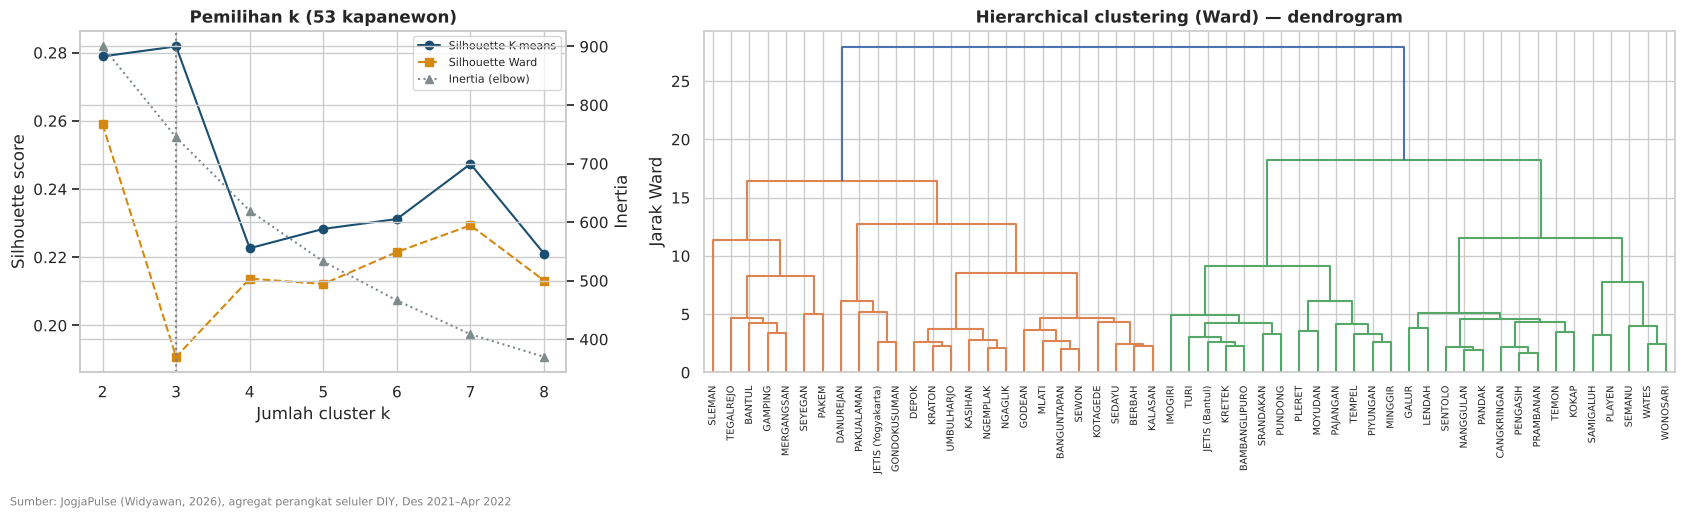

In [103]:
fig, axes = plt.subplots(1, 2, figsize=(17, 5), gridspec_kw={"width_ratios": [1, 2]})
ax = axes[0]
ax.plot(k_eval.index, k_eval.silhouette_kmeans, "o-", label="Silhouette K-means", color="#1b4f72")
ax.plot(k_eval.index, k_eval.silhouette_ward, "s--", label="Silhouette Ward", color="#d68910")
ax.axvline(K_BEST, color="gray", ls=":")
ax2 = ax.twinx()
ax2.plot(k_eval.index, k_eval.inertia, "^:", color="#7f8c8d", label="Inertia (elbow)")
ax2.set_ylabel("Inertia")
ax.set(xlabel="Jumlah cluster k", ylabel="Silhouette score", title=f"Pemilihan k ({eligible.sum()} kapanewon)")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, fontsize=8)
ax = axes[1]
dendrogram(linkage(X, method="ward"), labels=[LABEL[c] for c in features_ok.index], ax=ax, leaf_font_size=7)
ax.set(title="Hierarchical clustering (Ward) — dendrogram", ylabel="Jarak Ward")
fig.tight_layout()
save_fig(fig, "L06_cluster_selection")
plt.show()

### 10.4 Clustering final, PCA, dan profil cluster
**PCA (Principal Component Analysis)** merangkum 25 fitur menjadi beberapa komponen yang menangkap variasi terbesar. Di sini PCA hanya dipakai untuk **visualisasi 2D**; clustering memakai seluruh fitur terstandardisasi. *Loading* menunjukkan jam mana yang paling memengaruhi komponen.

In [104]:
kmeans_final = KMeans(n_clusters=K_BEST, n_init=50, random_state=RANDOM_STATE).fit(X)
raw_labels = kmeans_final.labels_
# Penomoran cluster diurutkan dari jumlah anggota terbanyak agar stabil & mudah dibaca
size_order = pd.Series(raw_labels).value_counts().index
relabel = {old: new for new, old in enumerate(size_order, start=1)}
clusters_ok = pd.Series([relabel[l] for l in raw_labels], index=features_ok.index, name="cluster")
clusters = clusters_ok.reindex(features.index).fillna(0).astype(int).rename("cluster")   # 0 = tidak di-cluster
CLUSTER_NAMES = {0: "Tidak di-cluster"}

pca = PCA(n_components=4, random_state=RANDOM_STATE).fit(X)
pcs = pd.DataFrame(pca.transform(X)[:, :2], index=features_ok.index, columns=["PC1", "PC2"])
print("Variansi dijelaskan PC1–PC4:", np.round(pca.explained_variance_ratio_, 3))
loadings = pd.DataFrame(pca.components_[:2].T, index=features_ok.columns, columns=["PC1", "PC2"])
print("Loading terbesar PC1:", loadings.PC1.abs().nlargest(6).index.tolist(), "| PC2:", loadings.PC2.abs().nlargest(6).index.tolist())

cluster_df = kap_hq[["label", "kab_kota", "urban_rural", "coverage_pct", "activity_share_pct", "weekend_ratio", "api", "ratio", "density"]].join(clusters)
cluster_df = cluster_df.join(period_lq.add_prefix("LQ_")).join(origin_hq[["ext_intensity"]]).join(attr[["visitor_resident_ratio"]])
if "lattice_share_of_grid_pct" in kap_hq:
    cluster_df["lattice_share_of_grid_pct"] = kap_hq.lattice_share_of_grid_pct
cluster_profile = cluster_df.groupby("cluster").agg(
    n=("label", "size"), median_coverage_pct=("coverage_pct", "median"), total_activity_share=("activity_share_pct", "sum"),
    median_density=("density", "median"), median_ratio=("ratio", "median"), median_weekend_ratio=("weekend_ratio", "median"),
    median_ext_intensity=("ext_intensity", "median"), median_visitor_resident=("visitor_resident_ratio", "median"),
    median_lattice_share=("lattice_share_of_grid_pct", "median") if "lattice_share_of_grid_pct" in cluster_df else ("label", "size"),
    **{f"LQ_{p}": (f"LQ_{p}", "median") for p in PERIOD_ORDER})
cluster_mean_profile = rel_profile["Semua hari"].groupby(clusters).mean()
cluster_profile["jam_puncak_relatif"] = cluster_mean_profile.idxmax(axis=1)
cluster_profile["jam_terendah_relatif"] = cluster_mean_profile.idxmin(axis=1)
display(cluster_profile.round(3))
members = cluster_df.groupby("cluster").label.apply(lambda s: ", ".join(s))
for c, m in members.items():
    print(f"Cluster {c} ({(clusters == c).sum()}): {m}")
print(pd.crosstab(cluster_df.cluster, cluster_df.kab_kota))
print(pd.crosstab(cluster_df.cluster, cluster_df.urban_rural))
save_table(cluster_df.reset_index(), "L06_cluster_membership_profile")

Variansi dijelaskan PC1–PC4: [0.45  0.187 0.171 0.052]
Loading terbesar PC1: ['h03', 'h01', 'h02', 'h12', 'h11', 'h13'] | PC2: ['h21', 'h20', 'h19', 'h18', 'h22', 'log_weekend_ratio']


,n,median_coverage_pct,total_activity_share,median_density,median_ratio,median_weekend_ratio,median_ext_intensity,median_visitor_resident,median_lattice_share,LQ_Dini hari,LQ_Pagi,LQ_Siang,LQ_Sore,LQ_Malam,jam_puncak_relatif,jam_terendah_relatif
cluster,,,,,,,,,,,,,,,,
0,25,86.2500,7.1540,563.2830,0.0270,1.0690,1.0240,1.2030,0.0000,0.6170,1.1050,1.1930,1.0900,1.0500,12,3
1,27,99.6760,59.0930,"3,533.5130",0.1450,0.9850,1.6130,1.3400,0.0000,0.9890,0.9830,0.9910,1.0020,1.0190,0,2
2,21,98.5190,17.7810,993.5610,0.0880,1.0540,1.1720,1.1280,6.4430,0.8160,1.0530,1.0570,1.0340,1.0410,6,2
3,5,100.0000,15.9730,"2,331.5580",0.2710,1.0070,1.2110,1.0950,35.3440,1.0250,1.0640,0.9900,0.9840,0.9300,5,23


Cluster 0 (25): PANJATAN, GIRIMULYO, KALIBAWANG, SANDEN, DLINGO, NGLIPAR, PATUK, PALIYAN, PANGGANG, TEPUS, KARANGMOJO, PONJONG, RONGKOP, SEMIN, NGAWEN, GEDANGSARI, SAPTOSARI, GIRISUBO, TANJUNGSARI, PURWOSARI, GEDONGTENGEN, NGAMPILAN, WIROBRAJAN, MANTRIJERON, GONDOMANAN
Cluster 1 (27): PAJANGAN, JETIS (Bantul), BANGUNTAPAN, PLERET, PIYUNGAN, SEWON, KASIHAN, SEDAYU, GODEAN, MOYUDAN, MINGGIR, MLATI, DEPOK, BERBAH, KALASAN, NGEMPLAK, NGAGLIK, TEMPEL, TEGALREJO, JETIS (Yogyakarta), GONDOKUSUMAN, DANUREJAN, KRATON, PAKUALAMAN, MERGANGSAN, UMBULHARJO, KOTAGEDE
Cluster 2 (21): TEMON, WATES, GALUR, LENDAH, SENTOLO, PENGASIH, KOKAP, NANGGULAN, SAMIGALUH, SRANDAKAN, KRETEK, PUNDONG, BAMBANGLIPURO, PANDAK, IMOGIRI, WONOSARI, PLAYEN, SEMANU, PRAMBANAN, TURI, CANGKRINGAN
Cluster 3 (5): BANTUL, GAMPING, SEYEGAN, SLEMAN, PAKEM
kab_kota  BANTUL  GUNUNGKIDUL  KULON PROGO  SLEMAN  YOGYAKARTA
cluster                                                       
0              2           15            3       0 

### 10.5 Uji sensitivitas clustering
- **Profil batas atas:** clustering diulang memakai rata-rata pangsa hanya atas slot terpublikasi.
- **Ward:** metode hierarkis pada fitur yang sama.
- **k = 2:** apakah pemisahan utama tetap ada jika jumlah cluster dikurangi.

In [105]:
labels_upper = KMeans(n_clusters=K_BEST, n_init=50, random_state=RANDOM_STATE).fit_predict(X_upper)
ari_upper = adjusted_rand_score(clusters_ok, labels_upper)
labels_ward = fcluster(linkage(X, method="ward"), K_BEST, criterion="maxclust")
ari_ward = adjusted_rand_score(clusters_ok, labels_ward)
labels_k2 = KMeans(n_clusters=2, n_init=50, random_state=RANDOM_STATE).fit_predict(X)
print(f"ARI vs profil batas atas: {ari_upper:.2f} | ARI vs Ward: {ari_ward:.2f}")
print("Tabel silang cluster utama vs batas atas:")
print(pd.crosstab(clusters_ok.rename("utama"), pd.Series(labels_upper, index=features_ok.index, name="batas_atas")))
print("Tabel silang cluster utama vs k=2:")
print(pd.crosstab(clusters_ok.rename("utama"), pd.Series(labels_k2, index=features_ok.index, name="k2")))

ARI vs profil batas atas: 0.38 | ARI vs Ward: 0.43
Tabel silang cluster utama vs batas atas:
batas_atas   0   1   2
utama                 
1            0  17  10
2           15   0   6
3            0   5   0
Tabel silang cluster utama vs k=2:
k2      0   1
utama        
1       0  27
2      21   0
3       0   5


### Visualisasi Utama 7 — Regional Activity Clustering

Gambar disimpan: outputs/figures/V7_regional_activity_clustering.png


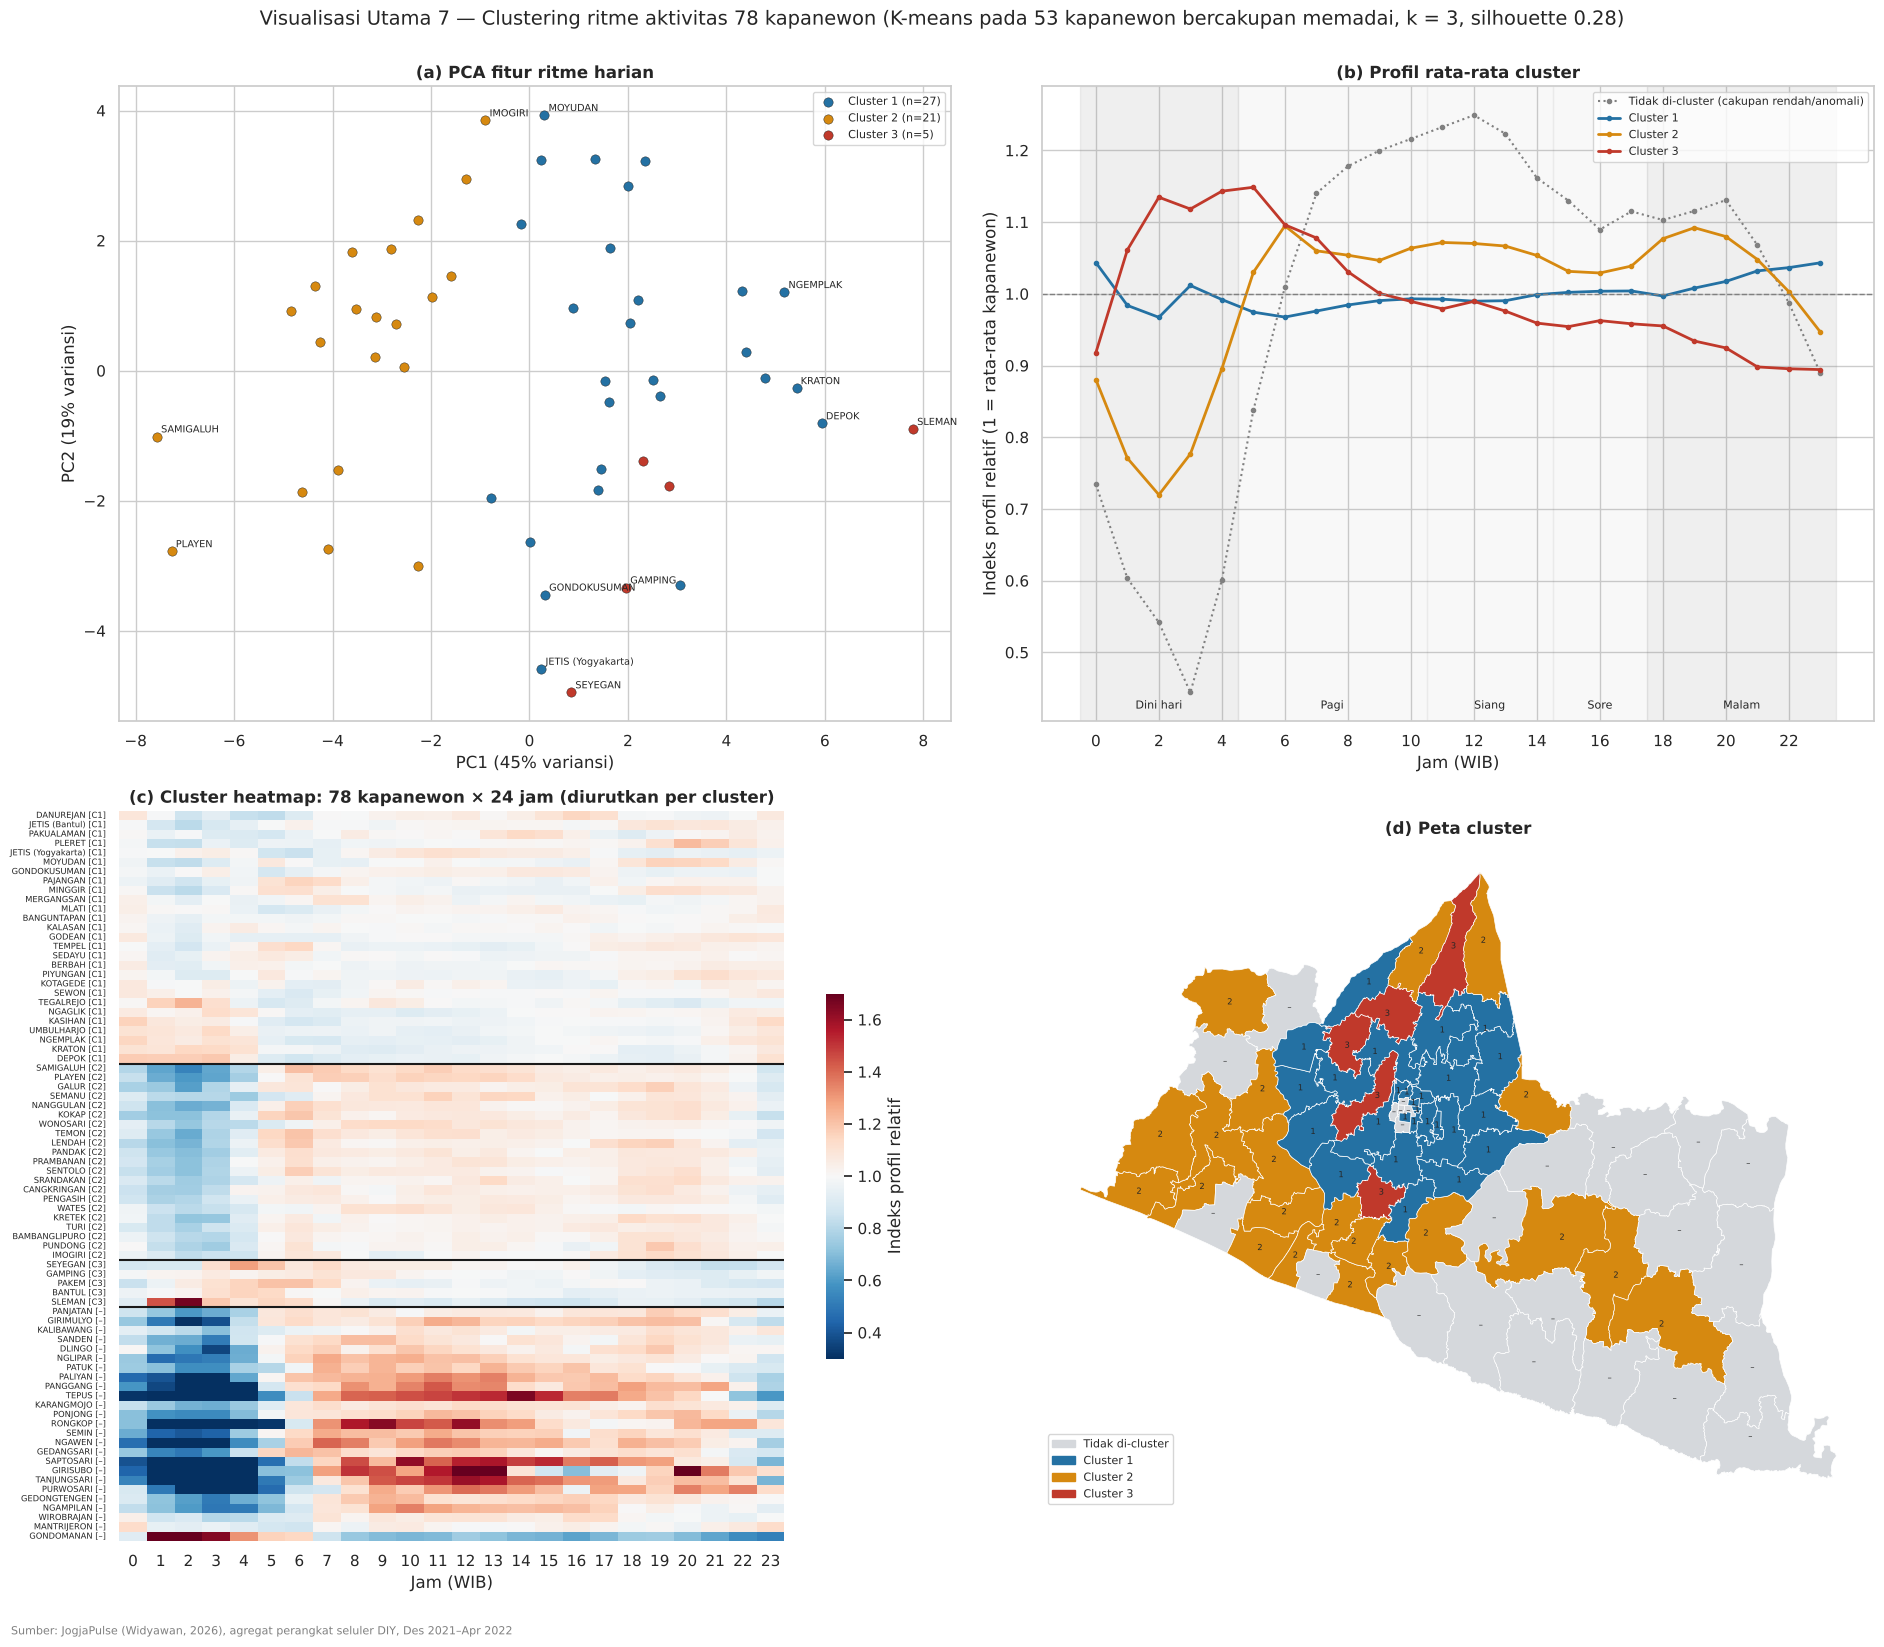

In [106]:
CLUSTER_COLORS = dict(zip(range(1, K_BEST + 1), ["#2471a3", "#d68910", "#c0392b", "#229954", "#7d3c98", "#17a589", "#5d6d7e", "#a04000"]))
CLUSTER_COLORS[0] = "#d5d8dc"
fig = plt.figure(figsize=(19, 16))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.15])
ax = fig.add_subplot(gs[0, 0])
for c in sorted(clusters_ok.unique()):
    idx = clusters_ok.index[clusters_ok == c]
    ax.scatter(pcs.loc[idx, "PC1"], pcs.loc[idx, "PC2"], s=45, color=CLUSTER_COLORS[c], label=f"Cluster {c} (n={len(idx)})", edgecolor="k", lw=0.3)
for code in pcs.PC1.abs().nlargest(6).index.union(pcs.PC2.abs().nlargest(6).index):
    ax.annotate(LABEL[code], pcs.loc[code], fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set(xlabel=f"PC1 ({pca.explained_variance_ratio_[0]:.0%} variansi)", ylabel=f"PC2 ({pca.explained_variance_ratio_[1]:.0%} variansi)",
       title="(a) PCA fitur ritme harian")
ax.legend(fontsize=8)
ax = fig.add_subplot(gs[0, 1])
for c in sorted(clusters.unique()):
    ax.plot(range(24), cluster_mean_profile.loc[c], marker="o", ms=3, lw=2 if c else 1.5, ls="-" if c else ":",
            color=CLUSTER_COLORS[c] if c else "gray", label=f"Cluster {c}" if c else "Tidak di-cluster (cakupan rendah/anomali)")
ax.axhline(1, color="gray", ls="--", lw=1)
for name, (s, e) in TIME_PERIODS.items():
    ax.axvspan(s - 0.5, e + 0.5, color="gray", alpha=0.05 if s % 2 else 0.12)
    ax.text((s + e) / 2, 0.02, name, ha="center", fontsize=8, transform=ax.get_xaxis_transform())
ax.set(xlabel="Jam (WIB)", ylabel="Indeks profil relatif (1 = rata-rata kapanewon)", title="(b) Profil rata-rata cluster", xticks=range(0, 24, 2))
ax.legend(fontsize=8)
ax = fig.add_subplot(gs[1, 0])
order_cl = cluster_df.assign(pc1=pcs.PC1.reindex(cluster_df.index), ck=cluster_df.cluster.replace(0, 99)).sort_values(["ck", "pc1"]).index
heat = rel_profile["Semua hari"].loc[order_cl]
sns.heatmap(heat, ax=ax, cmap="RdBu_r", center=1, vmin=0.3, vmax=1.7, cbar_kws={"label": "Indeks profil relatif", "shrink": 0.5},
            yticklabels=[f"{LABEL[c]} [{'C' + str(clusters[c]) if clusters[c] else '–'}]" for c in order_cl])
bounds = np.cumsum(clusters.loc[order_cl].replace(0, 99).value_counts().reindex(sorted(clusters.replace(0, 99).unique())).values)[:-1]
for b in bounds:
    ax.axhline(b, color="k", lw=1.5)
ax.tick_params(axis="y", labelsize=6)
ax.set(xlabel="Jam (WIB)", ylabel="", title="(c) Cluster heatmap: 78 kapanewon × 24 jam (diurutkan per cluster)")
ax = fig.add_subplot(gs[1, 1])
if HAS_BOUNDARY:
    gm = gdf_kap_simple[["kapanewon_code", "geometry"]].merge(clusters.reset_index(), on="kapanewon_code")
    gm.plot(ax=ax, color=gm.cluster.map(CLUSTER_COLORS), edgecolor="white", lw=0.5)
    for r in kapanewon_master.itertuples():
        ax.text(r.lon, r.lat, str(clusters[r.kapanewon_code]) if clusters[r.kapanewon_code] else "–", fontsize=6, ha="center", va="center")
    ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=CLUSTER_COLORS[c]) for c in sorted(clusters.unique())],
              labels=[f"Cluster {c}" if c else "Tidak di-cluster" for c in sorted(clusters.unique())], loc="lower left", fontsize=8)
    ax.set_axis_off()
ax.set_title("(d) Peta cluster")
fig.suptitle(f"Visualisasi Utama 7 — Clustering ritme aktivitas 78 kapanewon (K-means pada {eligible.sum()} kapanewon bercakupan memadai, k = {K_BEST}, silhouette {k_eval.loc[K_BEST, 'silhouette_kmeans']:.2f})", y=1.0)
fig.tight_layout()
save_fig(fig, "V7_regional_activity_clustering")
plt.show()

### 10.x Interpretasi Section 10

**Pemilihan k.** Di antara 53 kapanewon bercakupan memadai, silhouette tertinggi diperoleh pada k = 3 (0,28), hampir sama dengan k = 2 (0,28). Struktur clusternya **lemah–sedang** — ritme harian kapanewon DIY bervariasi secara bertahap, bukan dalam kelompok yang tegas. Pemisahan utama (Cluster 1 vs Cluster 2) **stabil**: identik dengan hasil k = 2 dan dengan profil batas atas pada k = 2 (ARI 0,93). Batas antara keduanya sebagian sensitif terhadap perlakuan suppression (10 dari 27 anggota Cluster 1 berpindah pada versi batas atas k = 3).

**Karakter cluster (berdasarkan output aktual):**

| Cluster | Anggota | Ritme | Karakter mobilitas | Nama yang diusulkan |
|---|---|---|---|---|
| **1** (27) | Kota Yogyakarta (9 kemantren), Depok, Ngaglik, Mlati, Ngemplak, Kalasan, Berbah, Tempel, Godean, Moyudan, Minggir, Banguntapan, Kasihan, Sewon, Pleret, Piyungan, Jetis (Bantul), Pajangan, Sedayu | Paling datar; relatif lebih tinggi dini hari dan malam (LQ dini hari ±0,99, malam ±1,02); turun saat akhir pekan (rasio ±0,99) | Kepadatan tinggi (median ±3.500 jiwa/km²), keterwakilan tertinggi, intensitas kunjungan eksternal tertinggi (±1,6) | **Aglomerasi urban–suburban "24 jam"** |
| **2** (21) | Kulon Progo (9), Bantul selatan (Srandakan, Kretek, Pundong, Bambanglipuro, Pandak, Imogiri), Wonosari, Playen, Semanu, Prambanan, Turi, Cangkringan | Sepi dini hari (LQ ±0,82), aktif pagi–siang; naik saat akhir pekan (±1,05) | Kepadatan sedang (±1.000/km²), intensitas eksternal lebih rendah (±1,2) | **Pinggiran & perdesaan berorientasi siang** |
| **3** (5) | Bantul, Gamping, Seyegan, Sleman, Pakem | Puncak relatif pukul 05.00, malam relatif rendah | Median ±35% aktivitas grid dari sel artefak kisi 0,1° | **Kelompok terdampak artefak data** — empat anggotanya memuat sel artefak yang sudah teridentifikasi (kisi: Gamping, Seyegan, Pakem; sel "lengket": Sleman); Bantul memiliki profil serupa tetapi belum terverifikasi penyebabnya |
| **–** (25) | 15 Gunungkidul, 5 kemantren kecil Kota (Gedongtengen, Ngampilan, Wirobrajan, Mantrijeron, Gondomanan), 3 Kulon Progo, 2 Bantul | — | Cakupan < 80% di suatu periode (atau anomali) | **Tidak di-cluster** |

**Temuan penting:** clustering otomatis yang dirancang dengan hati-hati **menemukan sendiri** kelompok kapanewon yang terdampak artefak — bukti tambahan bahwa artefak lokasi memengaruhi produk kapanewon × jam, bukan hanya grid.

**L07 (urban vs rural).** Cluster 1 berisi 19 kapanewon padat + 8 transisi dan **tidak ada** kapanewon jarang; Cluster 2 berisi 14 transisi + 7 jarang dan **tidak ada** kapanewon padat. Ritme harian sangat sejalan dengan gradien kepadatan. Kapanewon jarang yang tersisa sebagian besar justru "tidak di-cluster" karena datanya terlalu tipis — ketimpangan data itu sendiri adalah karakter rural dalam dataset ini.

In [107]:
l_ds = "presence_kapanewon_hourly (+ profil OD & populasi)"
add_insight("L01", "Wilayah dengan karakter aktivitas dominan pagi", l_ds, "share_lb per periode", "LQ pagi (cakupan ≥90%)",
            "share_pagi / share_harian", "V2, V7", "completed", f"{fmt_list(l01, 6)}.",
            "Kapanewon perdesaan (Gunungkidul utara, Samigaluh, Sanden, Playen) memulai aktivitas lebih awal.", common_lim)
add_insight("L02", "Wilayah dengan karakter aktivitas dominan siang", l_ds, "share_lb per periode", "LQ siang (cakupan ≥90%)",
            "share_siang / share_harian", "V2, V7", "completed", f"{fmt_list(l02, 6)}.",
            "Gunungkidul selatan (Tepus, Tanjungsari, Saptosari, Paliyan, Panggang) sangat siang-sentris.", common_lim)
add_insight("L03", "Wilayah dengan karakter aktivitas dominan malam", l_ds, "share_lb per periode", "LQ malam (cakupan ≥90%)",
            "share_malam / share_harian", "V2, V7", "completed", f"{fmt_list(l03, 6)}.",
            "Permukiman pinggiran Bantul & Sleman barat relatif paling aktif malam (efek 'pulang ke rumah').", common_lim)
add_insight("L04", "Wilayah dengan aktivitas relatif merata", l_ds, "rel_profile 24 jam", "Std indeks profil relatif (cakupan ≥90% semua periode)",
            "std_h(rel_h)", "V2, V7", "completed", f"{fmt_list(l04, 6, '{:.3f}')}.",
            "Kapanewon suburban timur-selatan (Kalasan, Banguntapan, Sedayu, Berbah, Sewon, Kotagede) ritmenya paling mirip ritme DIY.",
            "Diukur relatif terhadap DIY; lihat T11 untuk kestabilan absolut.")
add_insight("L05", "Wilayah dengan perbedaan aktivitas siang dan malam paling besar", l_ds, "LQ siang & malam",
            "LQ siang − LQ malam (cakupan ≥90% di kedua periode)", "LQ_siang − LQ_malam", "V2, V7", "completed", f"{fmt_list(l05, 8)}.",
            "Semua selisih terbesar bernilai positif (lebih siang-sentris), terutama Gunungkidul (Paliyan, Patuk, Semin, Nglipar).",
            "Kapanewon pesisir Gunungkidul dengan selisih lebih besar tidak dinilai karena cakupan malam < 90%.")
add_insight("L06", "Pengelompokan karakter aktivitas kapanewon secara otomatis", l_ds, "24 indeks profil relatif + log rasio akhir pekan",
            "StandardScaler + K-means (k dipilih via silhouette) + Ward + PCA; uji sensitivitas batas atas", "silhouette; ARI",
            "V7; Fig L06", "completed",
            f"{eligible.sum()} kapanewon di-cluster, k = {K_BEST} (silhouette {k_eval.loc[K_BEST, 'silhouette_kmeans']:.2f}); ukuran {clusters_ok.value_counts().sort_index().to_dict()}; "
            f"ARI vs Ward {ari_ward:.2f}, vs batas atas {ari_upper:.2f}. 25 kapanewon tidak di-cluster (cakupan rendah/anomali).",
            "Dua tipe ritme utama: aglomerasi urban–suburban '24 jam' dan pinggiran/perdesaan berorientasi siang; tipe ketiga adalah kelompok terdampak artefak.",
            "Struktur cluster lemah–sedang; uji awal pada 78 kapanewon hanya memisahkan kelengkapan data.")
add_insight("L07", "Perbandingan cluster urban dan rural", l_ds + "; proxy kepadatan", "cluster, urban_rural",
            "Tabulasi silang cluster × kelas kepadatan", "crosstab", "V7", "completed",
            "; ".join(f"Cluster {c}: " + ", ".join(f"{k} {v}" for k, v in row.items() if v) for c, row in pd.crosstab(cluster_df.cluster, cluster_df.urban_rural).iterrows()) + ".",
            "Cluster ritme hampir sepenuhnya mengikuti gradien kepadatan; kapanewon jarang sebagian besar tidak dapat di-cluster karena data tipis.",
            "Urban/rural = proxy kepadatan.")
add_insight("L08", "Perbandingan karakter kawasan wisata dan nonwisata", l_ds + " + (butuh) POI wisata", "cluster, POI",
            "Tabulasi cluster × label wisata", "crosstab", "V7", "requires external data",
            "Belum dihitung: tidak ada label wisata.", "Kode siap dijalankan bila tourism_poi_diy.csv tersedia (lihat S07).",
            "Butuh data/external/tourism_poi_diy.csv.")
if HAS_TOURISM and HAS_BOUNDARY:
    display(pd.crosstab(cluster_df.cluster, cluster_df.index.isin(cell_stats[cell_stats.is_tourism_cell].kapanewon_code.unique())))

---
## Section 11 — Data Quality & Validation (Q01–Q09)

### Q01–Q02 — Data yang dipublikasikan vs disembunyikan, grid vs kapanewon vs OD

In [108]:
od_sum = raw["od_summary.csv"].iloc[0]
suppression = pd.DataFrame([
    {"produk": "Grid 500 m × hari", "baris_total": tier1.loc["A_cell500m_daily", "rows_total"], "baris_publik": tier1.loc["A_cell500m_daily", "rows_published"],
     "baris_disembunyikan_%": tier1.loc["A_cell500m_daily", "rows_suppressed_pct"], "isi_disembunyikan_%": tier1.loc["A_cell500m_daily", "maid_presence_suppressed_pct"],
     "keterangan_isi": "% total n_maids"},
    {"produk": "Kapanewon × jam", "baris_total": tier1.loc["B_kapanewon_hourly", "rows_total"], "baris_publik": tier1.loc["B_kapanewon_hourly", "rows_published"],
     "baris_disembunyikan_%": tier1.loc["B_kapanewon_hourly", "rows_suppressed_pct"], "isi_disembunyikan_%": tier1.loc["B_kapanewon_hourly", "maid_presence_suppressed_pct"],
     "keterangan_isi": "% total n_maids"},
    {"produk": "OD kapanewon × kapanewon × bulan", "baris_total": od_sum.od_rows_total, "baris_publik": od_sum.od_rows_published,
     "baris_disembunyikan_%": od_sum.od_rows_suppressed_pct, "isi_disembunyikan_%": 100 - od_sum.inter_zonal_flow_kept_pct,
     "keterangan_isi": "% aliran antarwilayah"},
])
suppression["baris_publik_%"] = 100 - suppression["baris_disembunyikan_%"]
# Verifikasi silang: hitung ulang dari file
check_rows = {"Grid 500 m × hari": len(cells_daily), "Kapanewon × jam": len(hourly), "OD kapanewon × kapanewon × bulan": len(od)}
suppression["cek_baris_file"] = suppression.produk.map(check_rows)
save_table(suppression, "Q01_Q02_suppression_summary")
suppression

Tabel disimpan: outputs/tables/Q01_Q02_suppression_summary.csv


,produk,baris_total,baris_publik,baris_disembunyikan_%,isi_disembunyikan_%,keterangan_isi,baris_publik_%,cek_baris_file
0,Grid 500 m × hari,"518,176.0000","183,548.0000",64.6000,6.6000,% total n_maids,35.4000,183548
1,Kapanewon × jam,"273,979.0000","230,418.0000",15.9000,0.7000,% total n_maids,84.1000,230418
2,OD kapanewon × kapanewon × bulan,"19,263.0000","9,894.0000",48.6000,4.7000,% aliran antarwilayah,51.4000,9894


### Q03 — Apakah wilayah rural memiliki suppression lebih tinggi?
- **Kapanewon × jam:** % slot tidak terpublikasi per kapanewon (panel lengkap), per kelas kepadatan dan per periode.
- **Grid:** untuk sel yang pernah terpublikasi, % hari yang terpublikasi (sel yang tidak pernah terpublikasi tidak terlihat sama sekali, sehingga ini batas atas kelengkapan).

In [109]:
supp_kap = panel.assign(unpublished=~panel.published).groupby(["kapanewon_code", "hq"]).unpublished.mean().unstack() * 100
supp_kap.columns = ["Mar–Apr", "Des–Feb (HQ)"]
supp_kap = supp_kap.join(kap_hq[["label", "kab_kota", "urban_rural", "density"]])
q03_class = supp_kap.groupby("urban_rural")[["Des–Feb (HQ)", "Mar–Apr"]].median().loc[URBAN_ORDER]
q03_kab = supp_kap.groupby("kab_kota")[["Des–Feb (HQ)", "Mar–Apr"]].median().loc[KAB_ORDER]
kw_supp = stats.kruskal(*[g["Des–Feb (HQ)"].values for _, g in supp_kap.groupby("urban_rural")])
rho_supp = corr_report(np.log10(supp_kap.density), supp_kap["Des–Feb (HQ)"])
print(f"Kruskal–Wallis slot tersuppress antar-kelas (HQ): p = {kw_supp.pvalue:.1e}; Spearman log kepadatan vs % tersuppress: {rho_supp['spearman_rho']:.3f}")
display(q03_class.round(1))
display(q03_kab.round(1))
if HAS_BOUNDARY:
    cell_cov = cells_daily[cells_daily.hq].groupby("cell_id").size().div(n_hq_days).mul(100).rename("days_published_pct").to_frame()
    cell_cov = cell_cov.join(cells.set_index("cell_id").kapanewon_code).join(kapanewon_master.set_index("kapanewon_code").urban_rural, on="kapanewon_code")
    q03_grid = cell_cov.groupby("urban_rural").agg(sel_terlihat=("days_published_pct", "size"), median_hari_publik_pct=("days_published_pct", "median")).loc[URBAN_ORDER]
    q03_grid["sel_per_km2"] = q03_grid.sel_terlihat / class_summary.area_km2
    display(q03_grid.round(3))

Kruskal–Wallis slot tersuppress antar-kelas (HQ): p = 4.7e-07; Spearman log kepadatan vs % tersuppress: -0.582


,Des–Feb (HQ),Mar–Apr
urban_rural,,
Padat (proxy urban),0.0000,4.4000
Transisi,1.1000,32.5000
Jarang (proxy rural),9.1000,58.4000


,Des–Feb (HQ),Mar–Apr
kab_kota,,
YOGYAKARTA,0.9000,16.2000
SLEMAN,0.0000,6.1000
BANTUL,0.9000,20.9000
KULON PROGO,2.3000,43.2000
GUNUNGKIDUL,16.5000,68.3000


,sel_terlihat,median_hari_publik_pct,sel_per_km2
urban_rural,,,
Padat (proxy urban),1487,54.4440,3.8930
Transisi,2356,12.2220,2.5760
Jarang (proxy rural),1855,4.4440,0.9910


### Q04 — Perubahan kualitas data antarbulan
Satu tabel yang menggabungkan indikator kualitas presence dan OD, termasuk hasil **model gravitasi** (Q09) dan porsi sel artefak.

In [110]:
def fit_gravity(df):
    """log T_ij = a + b·log H_i + c·log P_j − γ·log d_ij  (aliran antarwilayah terpublikasi)."""
    d = df.copy()
    d["P_dest"] = d.dest_code.map(kapanewon_master.set_index("kapanewon_code").pop_actual)
    model = smf.ols("np.log(n_maids) ~ np.log(n_homed_maids) + np.log(P_dest) + np.log(distance_km)", data=d).fit()
    return pd.Series({"R2": model.rsquared, "gamma": -model.params["np.log(distance_km)"], "beta_H": model.params["np.log(n_homed_maids)"],
                      "beta_P": model.params["np.log(P_dest)"], "n_pairs": int(model.nobs)})


if HAS_BOUNDARY:
    gravity = pd.DataFrame({m: fit_gravity(inter[inter.month == m]) for m in ALL_MONTHS}).T
    gravity_no_g = pd.DataFrame({m: fit_gravity(inter[(inter.month == m) & (inter.origin_code != GONDOMANAN) & (inter.dest_code != GONDOMANAN)])
                                 for m in ALL_MONTHS}).T
    print("Model gravitasi per bulan (semua pasangan):")
    display(gravity.round(3))
    print("Tanpa Gondomanan:")
    display(gravity_no_g[["R2", "gamma"]].round(3))

quality_monthly = monthly_quality.copy()
quality_monthly["lattice_cell_share_pct"] = lattice_daily_share.groupby(lattice_daily_share.index.strftime("%Y-%m")).mean()
quality_monthly["gondomanan_share_pct"] = monthly_share.loc[GONDOMANAN]
quality_monthly["homed_daytime_rate"] = origin_homes.groupby("month").n_homed_maids_daytime.sum() / origin_homes.groupby("month").n_homed_maids.sum()
quality_monthly["od_reciprocity_r"] = recip_table.r_log_flows
if HAS_BOUNDARY:
    quality_monthly["gravity_R2"] = gravity.R2
    quality_monthly["gravity_gamma"] = gravity.gamma
quality_monthly["homed_vs_pop_r_linear"] = monthly_pop_corr.pearson_linear_tanpa_Gondomanan
save_table(quality_monthly.reset_index(), "Q04_monthly_quality_full")
quality_monthly.T.round(3)

Model gravitasi per bulan (semua pasangan):


,R2,gamma,beta_H,beta_P,n_pairs
2021-12,0.4470,0.7670,0.4900,0.7550,"2,517.0000"
2022-01,0.5690,0.9280,0.5190,0.6960,"2,546.0000"
2022-02,0.5760,0.8890,0.4770,0.5370,"2,575.0000"
2022-03,0.2810,0.3570,0.2360,0.2470,"1,124.0000"
2022-04,0.2240,0.2360,0.2460,0.1900,742.0000


Tanpa Gondomanan:


,R2,gamma
2021-12,0.4620,0.8030
2022-01,0.5940,0.9680
2022-02,0.6110,0.9390
2022-03,0.3680,0.4510
2022-04,0.3350,0.3690


Tabel disimpan: outputs/tables/Q04_monthly_quality_full.csv


month,2021-12,2022-01,2022-02,2022-03,2022-04
device_hours_per_day,"207,905.9030","142,749.0320","144,689.5000","31,365.4840","23,254.0330"
slots_published_pct,94.5460,92.7640,90.7090,71.2450,58.4530
cells_published_per_day,"1,563.8710","1,771.3870","1,888.5360",519.8390,372.0330
median_pings_per_maid,2.7080,2.2650,2.5320,2.2800,2.1570
od_homed_devices,"122,182.0000","86,013.0000","77,723.0000","23,185.0000","14,272.0000"
od_pairs_published,"2,517.0000","2,546.0000","2,575.0000","1,124.0000",742.0000
device_hours_vs_dec_pct,100.0000,68.6600,69.5940,15.0860,11.1850
lattice_cell_share_pct,14.7940,5.6240,6.5050,13.6740,0.1030
gondomanan_share_pct,1.5010,1.6230,3.2140,11.6790,10.1150
homed_daytime_rate,0.9210,0.8990,0.8270,0.5310,0.8140


### Q05 — Wilayah dengan cakupan pengamatan malam rendah
Lihat P08. Ringkasan per kabupaten dan perubahan antara Des–Jan dan Des–Apr:

In [111]:
q05 = rep[["label", "kab_kota", "night_slots_pct_decjan", "night_slots_pct_full"]].sort_values("night_slots_pct_full")
print("Median cakupan malam per kabupaten (%):")
display(rep.groupby("kab_kota")[["night_slots_pct_decjan", "night_slots_pct_full"]].median().loc[KAB_ORDER].round(1))
print(f"Kapanewon dengan cakupan malam < 50%: Des–Jan {(rep.night_slots_pct_decjan < 50).sum()}, Des–Apr {(rep.night_slots_pct_full < 50).sum()}")
q05.head(10)

Median cakupan malam per kabupaten (%):


,night_slots_pct_decjan,night_slots_pct_full
kab_kota,,
YOGYAKARTA,98.5000,78.8000
SLEMAN,100.0000,91.8000
BANTUL,99.7000,74.5000
KULON PROGO,95.2000,67.4000
GUNUNGKIDUL,47.7000,32.2000


Kapanewon dengan cakupan malam < 50%: Des–Jan 12, Des–Apr 18


,label,kab_kota,night_slots_pct_decjan,night_slots_pct_full
kapanewon_code,,,,
34.03.16,GIRISUBO,GUNUNGKIDUL,5.1075,3.2009
34.03.11,RONGKOP,GUNUNGKIDUL,7.7957,4.7461
34.03.15,SAPTOSARI,GUNUNGKIDUL,11.0215,6.6225
34.03.07,TEPUS,GUNUNGKIDUL,13.9785,7.1744
34.03.17,TANJUNGSARI,GUNUNGKIDUL,12.6344,9.3819
34.03.18,PURWOSARI,GUNUNGKIDUL,16.6667,10.9272
34.03.06,PANGGANG,GUNUNGKIDUL,27.6882,17.7704
34.03.13,NGAWEN,GUNUNGKIDUL,26.8817,18.4327
34.03.05,PALIYAN,GUNUNGKIDUL,45.6989,26.9316


### Q06 — Analisis sensitivitas: bagaimana hasil berubah jika Maret–April dikeluarkan / dimasukkan?
Kita membandingkan hasil utama pada tiga periode: **HQ (Des–Feb)**, **penuh (Des–Apr)**, dan **Mar–Apr saja**.

In [112]:
panel_full = panel
panel_late = panel[~panel.hq]
kap_full, kap_late = kapanewon_metrics(panel_full), kapanewon_metrics(panel_late)


def topk_overlap(a, b, k=10):
    return len(set(a.nlargest(k).index) & set(b.nlargest(k).index))


cells_full = cells_daily.groupby("cell_id").share.sum() / cells_daily.date.nunique()
cs_full = cell_stats_all[["gi", "gj"]].join(cells_full.rename("share_full")).fillna(0)
cs_full = cs_full[~cell_stats_all.lattice_0_1deg]
gi_full = pd.Series(getis_ord_gi_star(cs_full.reset_index(), "share_full"), index=cs_full.index)
hot_full = set(gi_full[gi_full > 2.576].index)
hot_hq = set(hot_cells.index)
night_full_r = stats.pearsonr(np.log10(rep.drop(index=GONDOMANAN).pop_actual), np.log10(rep.drop(index=GONDOMANAN).night_presence_full))[0]
night_decjan_r = stats.pearsonr(np.log10(rep.drop(index=GONDOMANAN).pop_actual), np.log10(rep.drop(index=GONDOMANAN).night_presence_decjan))[0]
sens = pd.DataFrame([
    {"hasil": "Ranking aktivitas kapanewon (Spearman vs HQ)", "HQ": 1.0,
     "Penuh": stats.spearmanr(kap_hq.activity_share_pct, kap_full.activity_share_pct)[0],
     "Mar–Apr": stats.spearmanr(kap_hq.activity_share_pct, kap_late.activity_share_pct)[0]},
    {"hasil": "Overlap 10 kapanewon teratas dengan HQ", "HQ": 10, "Penuh": topk_overlap(kap_hq.activity_share_pct, kap_full.activity_share_pct),
     "Mar–Apr": topk_overlap(kap_hq.activity_share_pct, kap_late.activity_share_pct)},
    {"hasil": "Pangsa Gondomanan (%)", "HQ": kap_hq.activity_share_pct[GONDOMANAN], "Penuh": kap_full.activity_share_pct[GONDOMANAN],
     "Mar–Apr": kap_late.activity_share_pct[GONDOMANAN]},
    {"hasil": "Hotspot Gi* 99% (Jaccard vs HQ)", "HQ": 1.0, "Penuh": len(hot_full & hot_hq) / len(hot_full | hot_hq), "Mar–Apr": np.nan},
    {"hasil": "r log-log night presence vs penduduk (tanpa Gondomanan)", "HQ": night_decjan_r, "Penuh": night_full_r, "Mar–Apr": np.nan},
    {"hasil": "r linear homed vs penduduk (rata-rata bulan)", "HQ": monthly_pop_corr.loc[HQ_MONTHS, "pearson_linear_tanpa_Gondomanan"].mean(),
     "Penuh": monthly_pop_corr.pearson_linear_tanpa_Gondomanan.mean(), "Mar–Apr": monthly_pop_corr.loc[["2022-03", "2022-04"], "pearson_linear_tanpa_Gondomanan"].mean()},
    {"hasil": "Distance-decay slope (rata-rata bulan)", "HQ": np.mean([decay_by_month[m].params.iloc[1] for m in HQ_MONTHS]),
     "Penuh": np.mean([decay_by_month[m].params.iloc[1] for m in ALL_MONTHS]), "Mar–Apr": np.mean([decay_by_month[m].params.iloc[1] for m in ["2022-03", "2022-04"]])},
    {"hasil": "Gravity R² (rata-rata bulan)", "HQ": gravity.loc[HQ_MONTHS, "R2"].mean() if HAS_BOUNDARY else np.nan,
     "Penuh": gravity.R2.mean() if HAS_BOUNDARY else np.nan, "Mar–Apr": gravity.loc[["2022-03", "2022-04"], "R2"].mean() if HAS_BOUNDARY else np.nan},
    {"hasil": "Reciprocity r log flows (rata-rata bulan)", "HQ": recip_table.loc[HQ_MONTHS, "r_log_flows"].mean(),
     "Penuh": recip_table.r_log_flows.mean(), "Mar–Apr": recip_table.loc[["2022-03", "2022-04"], "r_log_flows"].mean()},
    {"hasil": "Jaringan: density (rata-rata bulan)", "HQ": net_summary.loc[HQ_MONTHS, "density"].mean(), "Penuh": net_summary.loc[ALL_MONTHS, "density"].mean(),
     "Mar–Apr": net_summary.loc[["2022-03", "2022-04"], "density"].mean()},
]).set_index("hasil")
save_table(sens.reset_index(), "Q06_sensitivity")
print(f"Hotspot 99%: HQ {len(hot_hq)} sel, periode penuh {len(hot_full)} sel")
sens.round(3)

Tabel disimpan: outputs/tables/Q06_sensitivity.csv
Hotspot 99%: HQ 317 sel, periode penuh 118 sel


,HQ,Penuh,Mar–Apr
hasil,,,
Ranking aktivitas kapanewon (Spearman vs HQ),1.0000,0.9820,0.8910
Overlap 10 kapanewon teratas dengan HQ,10.0000,8.0000,7.0000
Pangsa Gondomanan (%),2.0760,5.6450,10.9100
Hotspot Gi* 99% (Jaccard vs HQ),1.0000,0.3180,NaN
r log-log night presence vs penduduk (tanpa Gondomanan),0.7180,0.7020,NaN
r linear homed vs penduduk (rata-rata bulan),0.8420,0.7450,0.6000
Distance-decay slope (rata-rata bulan),-0.8430,-0.6430,-0.3450
Gravity R² (rata-rata bulan),0.5310,0.4190,0.2520
Reciprocity r log flows (rata-rata bulan),0.8070,0.7710,0.7160


### Q07 — Anomali tanggal dan lokasi (ringkasan)

In [113]:
anomaly_register = pd.concat([
    pd.DataFrame({"jenis": "Tanggal (robust z)", "objek": [d.date().isoformat() for d in anomalies.index],
                  "nilai": [f"z = {z:.1f}; Δ hari ke hari {c:+.0f}%" if pd.notna(c) else f"z = {z:.1f}" for z, c in zip(anomalies.robust_z, anomalies.dod_change_pct)]}),
    pd.DataFrame({"jenis": "Change-point level", "objek": [d.date().isoformat() for d in change_points],
                  "nilai": [f"segmen baru rata-rata {v:,.0f} device-hours/hari" for v in segments.rata2_device_hours.iloc[1:]]}),
    pd.DataFrame({"jenis": "Sel kisi koordinat 0,1°", "objek": [f"{n_lattice} sel"],
                  "nilai": [f"{lattice_hq_share:.1f}% aktivitas grid HQ; porsi harian {lattice_daily_share.min():.1f}–{lattice_daily_share.max():.1f}%"]}),
    pd.DataFrame({"jenis": "Sel 'lengket' (tidak ikut turun)", "objek": [f"{r.Index} ({r.kapanewon})" for r in sticky_top.head(2).itertuples()],
                  "nilai": [f"rasio Mar–Apr/Des–Jan {r.ratio_late_early:.2f} vs DIY {diy_late_early:.2f}" for r in sticky_top.head(2).itertuples()]}),
    pd.DataFrame({"jenis": "Sel lonjakan episodik", "objek": ["E865_N18299 (NGAGLIK)"],
                  "nilai": ["hingga ±11.000 perangkat/hari pada 17–20 & 29–31 Des 2021, median ±30"]}),
], ignore_index=True)
save_table(anomaly_register, "Q07_anomaly_register")
anomaly_register

Tabel disimpan: outputs/tables/Q07_anomaly_register.csv


,jenis,objek,nilai
0,Tanggal (robust z),2021-12-01,z = -11.0
1,Tanggal (robust z),2021-12-07,z = 3.8; Δ hari ke hari +10%
2,Tanggal (robust z),2022-01-05,z = 3.7; Δ hari ke hari +32%
3,Tanggal (robust z),2022-01-23,z = -4.1; Δ hari ke hari -10%
4,Tanggal (robust z),2022-02-16,z = -6.6; Δ hari ke hari -60%
5,Tanggal (robust z),2022-02-19,z = 5.1; Δ hari ke hari -9%
6,Tanggal (robust z),2022-03-08,z = -11.4; Δ hari ke hari -48%
7,Tanggal (robust z),2022-03-18,z = 5.9; Δ hari ke hari +38%
8,Tanggal (robust z),2022-04-03,z = -4.2; Δ hari ke hari -34%
9,Tanggal (robust z),2022-04-19,z = -6.3; Δ hari ke hari -37%


### Visualisasi Utama 8 — Data Reliability & Validation Dashboard

Gambar disimpan: outputs/figures/V8_data_reliability_dashboard.png


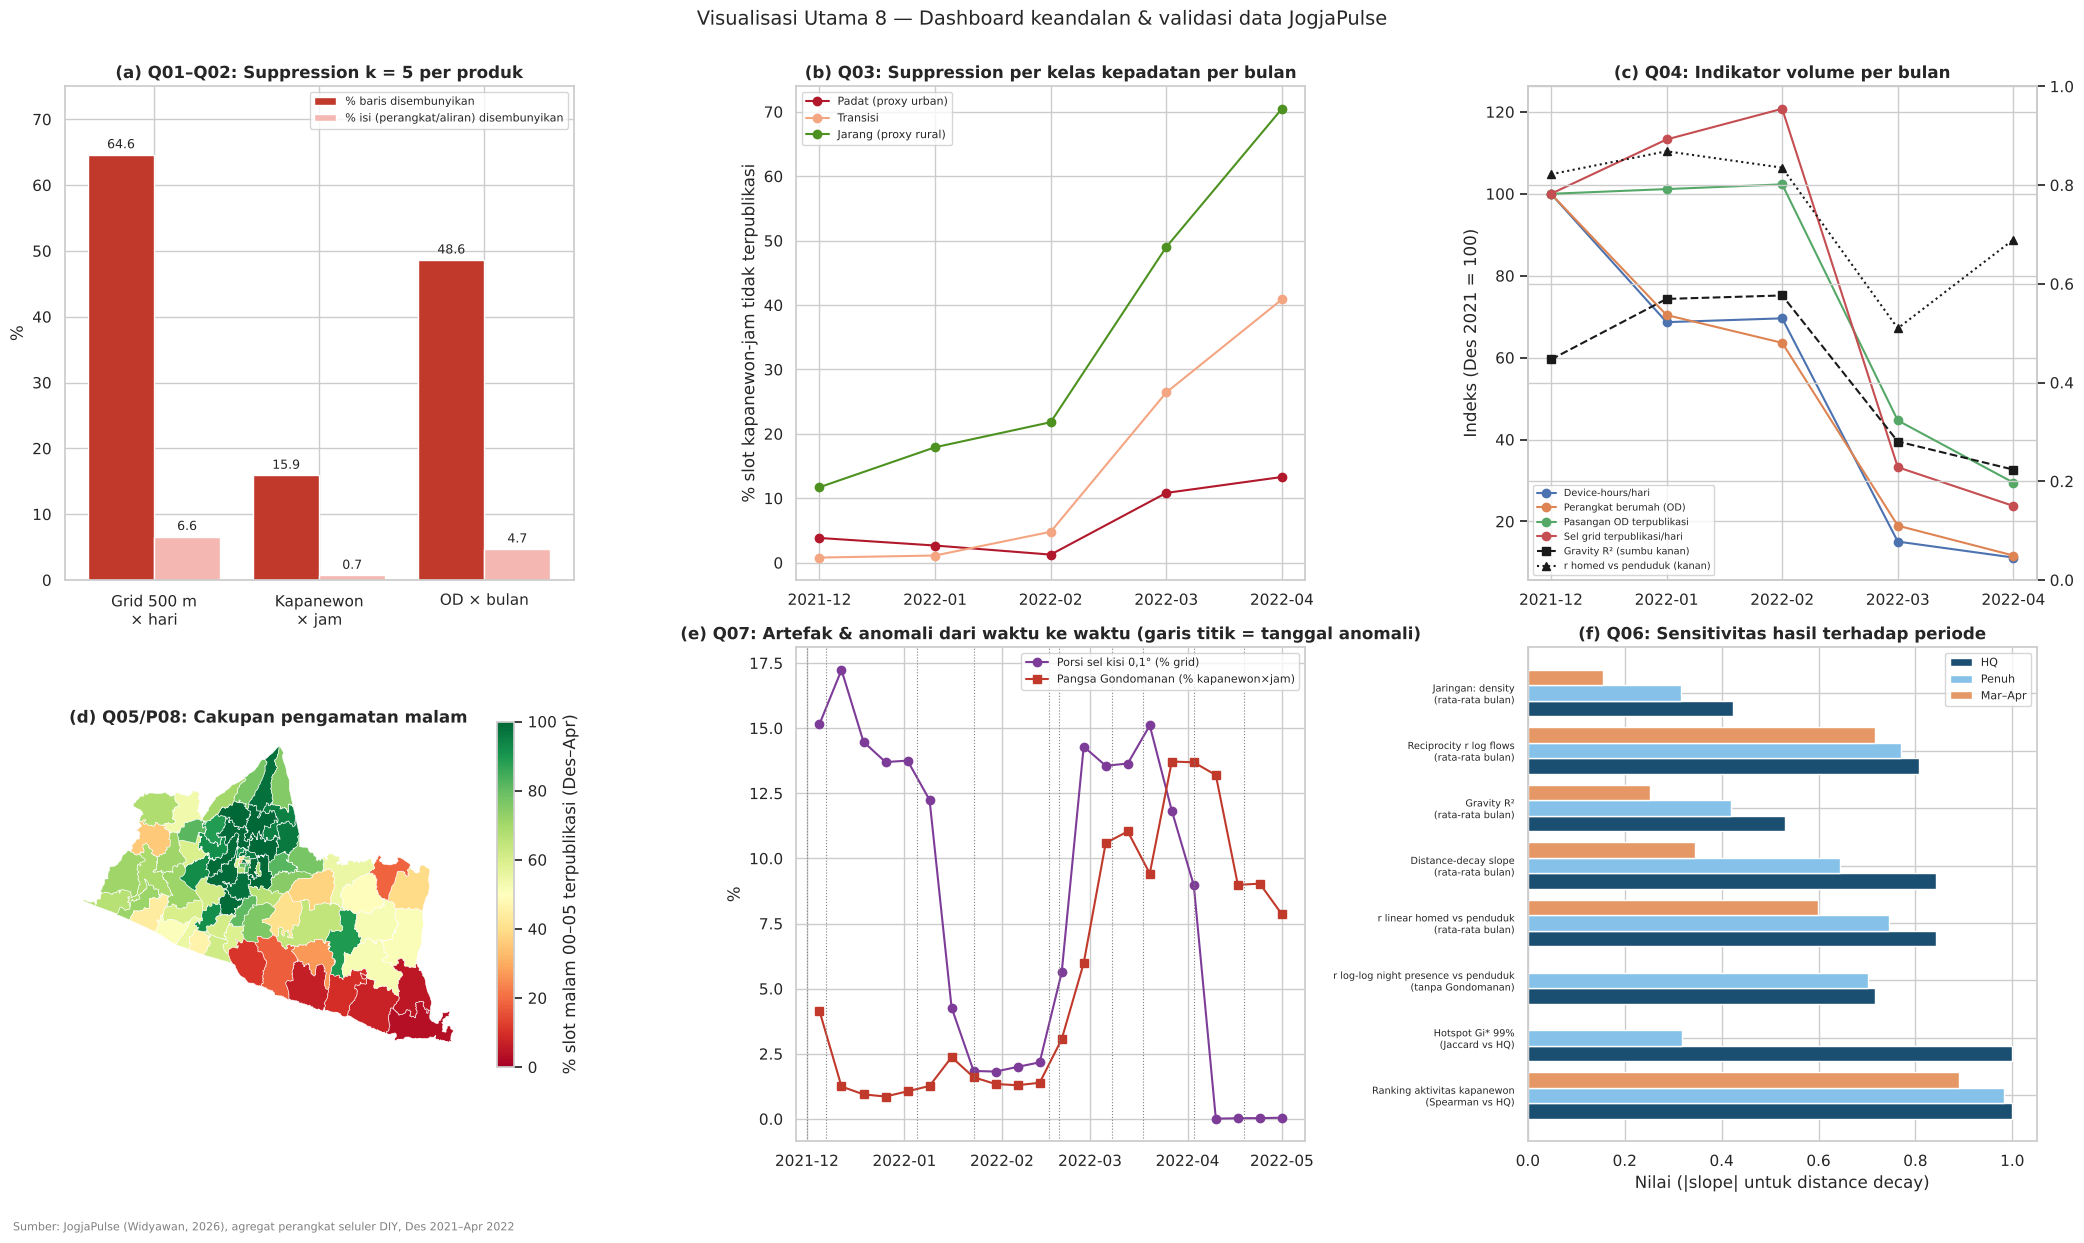

In [114]:
fig, axes = plt.subplots(2, 3, figsize=(21, 12))
ax = axes[0, 0]
xpos = np.arange(len(suppression))
ax.bar(xpos - 0.2, suppression["baris_disembunyikan_%"], 0.4, label="% baris disembunyikan", color="#c0392b")
ax.bar(xpos + 0.2, suppression["isi_disembunyikan_%"], 0.4, label="% isi (perangkat/aliran) disembunyikan", color="#f5b7b1")
for x, a, b in zip(xpos, suppression["baris_disembunyikan_%"], suppression["isi_disembunyikan_%"]):
    ax.text(x - 0.2, a + 1, f"{a:.1f}", ha="center", fontsize=9); ax.text(x + 0.2, b + 1, f"{b:.1f}", ha="center", fontsize=9)
ax.set_xticks(xpos, ["Grid 500 m\n× hari", "Kapanewon\n× jam", "OD × bulan"])
ax.set(ylabel="%", title="(a) Q01–Q02: Suppression k = 5 per produk", ylim=(0, 75))
ax.legend(fontsize=8)
ax = axes[0, 1]
monthly_unpub = panel.assign(unpub=~panel.published).groupby(["urban_rural", "month"]).unpub.mean().unstack(0) * 100
for cls in URBAN_ORDER:
    ax.plot(monthly_unpub.index, monthly_unpub[cls], marker="o", color=class_palette[cls], label=cls)
ax.set(ylabel="% slot kapanewon-jam tidak terpublikasi", title="(b) Q03: Suppression per kelas kepadatan per bulan")
ax.legend(fontsize=8)
ax = axes[0, 2]
qm = quality_monthly
norm_cols = {"device_hours_per_day": "Device-hours/hari", "od_homed_devices": "Perangkat berumah (OD)", "od_pairs_published": "Pasangan OD terpublikasi",
             "cells_published_per_day": "Sel grid terpublikasi/hari"}
for col, name in norm_cols.items():
    ax.plot(qm.index, qm[col] / qm[col].iloc[0] * 100, marker="o", label=name)
ax.set(ylabel="Indeks (Des 2021 = 100)", title="(c) Q04: Indikator volume per bulan")
ax5 = ax.twinx()
if HAS_BOUNDARY:
    ax5.plot(qm.index, qm.gravity_R2, "k--", marker="s", label="Gravity R² (sumbu kanan)")
ax5.plot(qm.index, qm.homed_vs_pop_r_linear, "k:", marker="^", label="r homed vs penduduk (kanan)")
ax5.set_ylim(0, 1)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax5.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, fontsize=7, loc="lower left")
ax = axes[1, 0]
if HAS_BOUNDARY:
    gq = gdf_kap_simple[["kapanewon_code", "geometry"]].merge(rep[["night_slots_pct_full"]].reset_index(), on="kapanewon_code")
    gq.plot(ax=ax, column="night_slots_pct_full", cmap="RdYlGn", vmin=0, vmax=100, legend=True, edgecolor="white", lw=0.4,
            legend_kwds={"label": "% slot malam 00–05 terpublikasi (Des–Apr)", "shrink": 0.7})
    ax.set_axis_off()
ax.set_title("(d) Q05/P08: Cakupan pengamatan malam")
ax = axes[1, 1]
weekly_lattice = lattice_daily_share.resample("W").mean()
ax.plot(weekly_lattice.index, weekly_lattice.values, marker="o", color="#7d3c98", label="Porsi sel kisi 0,1° (% grid)")
gond_daily = daily_share[GONDOMANAN].resample("W").mean()
ax.plot(gond_daily.index, gond_daily.values, marker="s", color="#c0392b", label="Pangsa Gondomanan (% kapanewon×jam)")
for d in anomalies.index:
    ax.axvline(d, color="gray", ls=":", lw=0.8)
ax.set(ylabel="%", title="(e) Q07: Artefak & anomali dari waktu ke waktu (garis titik = tanggal anomali)")
ax.legend(fontsize=8)
ax = axes[1, 2]
sens_plot = sens.drop(index=["Overlap 10 kapanewon teratas dengan HQ", "Pangsa Gondomanan (%)"])
sens_plot = sens_plot.assign(**{c: sens_plot[c].abs() for c in ["HQ", "Penuh", "Mar–Apr"]})
ypos = np.arange(len(sens_plot))
for i, (col, color) in enumerate(zip(["HQ", "Penuh", "Mar–Apr"], ["#1b4f72", "#85c1e9", "#e59866"])):
    ax.barh(ypos + (i - 1) * 0.27, sens_plot[col], 0.27, color=color, label=col)
ax.set_yticks(ypos, [t.replace(" (", "\n(") for t in sens_plot.index], fontsize=7)
ax.set(xlabel="Nilai (|slope| untuk distance decay)", title="(f) Q06: Sensitivitas hasil terhadap periode")
ax.legend(fontsize=8)
fig.suptitle("Visualisasi Utama 8 — Dashboard keandalan & validasi data JogjaPulse", y=1.0)
fig.tight_layout()
save_fig(fig, "V8_data_reliability_dashboard")
plt.show()

### 11.x Interpretasi Section 11

- **Q01–Q02.** Suppression berat pada grid (64,6% baris, tetapi hanya 6,6% kehadiran) dan OD (48,6% baris, 4,7% aliran antarwilayah), ringan pada kapanewon × jam (15,9% baris, 0,7% kehadiran). Artinya produk kapanewon × jam paling lengkap untuk analisis waktu; grid paling rinci secara spasial tetapi "buta" di wilayah jarang.
- **Q03.** Ya. Pada periode HQ, median slot tersuppress: padat 0%, transisi 1,1%, jarang 9,1% (Kruskal–Wallis p < 0,001); Gunungkidul 16,5%. Pada Mar–Apr: 4%, 33%, 58% (Gunungkidul 68%). Di grid, median sel di kawasan jarang hanya terpublikasi 4% hari (padat 54%).
- **Q04.** Semua indikator memburuk tajam mulai Maret: device-hours −85–89% vs Desember, pasangan OD −55–71%, R² gravitasi turun dari 0,45–0,58 ke 0,22–0,28, γ dari 0,77–0,93 ke 0,24–0,36 (replikasi README), dan korelasi rumah bulanan vs penduduk turun dari 0,82–0,87 ke 0,51–0,69. Porsi sel artefak dan pangsa Gondomanan berubah tidak beraturan.
- **Q05.** Cakupan malam sangat rendah di Gunungkidul (median 48% Des–Jan, 32% Des–Apr); 18 kapanewon < 50%.
- **Q06 (sensitivitas).** Ranking aktivitas kapanewon **robust** (Spearman HQ vs penuh 0,98; vs Mar–Apr 0,89), tetapi hasil yang bergantung pada detail bergeser besar bila Mar–Apr dimasukkan: hotspot grid hanya 32% sama (Jaccard), pangsa Gondomanan naik dari 2,1% ke 5,6% (10,9% jika hanya Mar–Apr), distance decay melemah (−0,84 → −0,64), R² gravitasi turun (0,53 → 0,42), density jaringan turun (0,42 → 0,32). **Kesimpulan: membatasi analisis kuantitatif ke Des–Feb adalah pilihan yang tepat.**
- **Q07.** Anomali terkonfirmasi: 8 Mar (README), 1 Des, 16 Feb, 19 Apr, dll.; change-point 1 Jan, 24 Jan, 13 Feb, 20 Feb, 6 Mar, 29 Mar; artefak spasial: 25 sel kisi 0,1°, 2 sel "lengket" (Gondomanan, Sleman), 1 sel lonjakan episodik (Ngaglik).
- **Q08.** Sampel bias urban: rasio perangkat/penduduk padat ≈ 1,46× DIY, jarang ≈ 0,43×; elastisitas log-log ±1,6.
- **Q09.** Pola OD masuk akal untuk Des–Feb: model gravitasi menjelaskan 45–58% variasi log aliran (60–61% tanpa Gondomanan), dengan γ ±0,8–0,9 — dalam rentang wajar untuk mobilitas perkotaan; aliran juga sangat resiprokal (r 0,79–0,82).

In [115]:
q_ds = "tier1_summary; od_summary; validation_night_presence; README; produk presence & OD"
add_insight("Q01", "Persentase data yang dipublikasikan dan disembunyikan", "tier1_summary; od_summary", "rows_*, *_suppressed_pct",
            "Ringkasan suppression + verifikasi jumlah baris file", "rows_published / rows_total", "V8(a)", "completed",
            "; ".join(f"{r.produk}: publik {r['baris_publik_%']:.1f}% baris, isi tersembunyi {r['isi_disembunyikan_%']:.1f}%" for _, r in suppression.iterrows()) + ".",
            "Banyak baris hilang tetapi sebagian kecil isi; baris yang hilang adalah unit kecil (0–4 perangkat).", "Ringkasan dari pembuat data; diverifikasi cocok dengan jumlah baris file.")
add_insight("Q02", "Perbedaan suppression antara grid dan kapanewon", "tier1_summary", "rows_suppressed_pct, maid_presence_suppressed_pct",
            "Perbandingan antarproduk", "%", "V8(a)", "completed",
            f"Grid {suppression.iloc[0]['baris_disembunyikan_%']:.1f}% baris / {suppression.iloc[0]['isi_disembunyikan_%']:.1f}% kehadiran vs kapanewon {suppression.iloc[1]['baris_disembunyikan_%']:.1f}% / {suppression.iloc[1]['isi_disembunyikan_%']:.1f}%.",
            "Unit yang lebih kecil (500 m × hari) jauh lebih sering di bawah ambang k = 5.", "—")
add_insight("Q03", "Apakah wilayah rural memiliki suppression lebih tinggi?", "presence_kapanewon_hourly; presence_cell500m_daily", "published flag",
            "% slot tersuppress per kelas & kabupaten; Kruskal–Wallis", "1 − published", "V8(b)", "completed",
            "HQ: " + ", ".join(f"{c} {v:.1f}%" for c, v in q03_class['Des–Feb (HQ)'].items()) + "; Mar–Apr: " + ", ".join(f"{c} {v:.1f}%" for c, v in q03_class['Mar–Apr'].items())
            + f"; Kruskal–Wallis p = {kw_supp.pvalue:.1e}.",
            "Ya, jauh lebih tinggi, dan kesenjangan melebar pada Mar–Apr.", "Kelas = proxy kepadatan.")
add_insight("Q04", "Perubahan kualitas data antarbulan", q_ds, "berbagai indikator",
            "Tabel kualitas bulanan + model gravitasi + porsi artefak", "lihat outputs/tables/Q04_monthly_quality_full.csv", "V8(c,e)", "completed",
            f"Device-hours vs Des: {', '.join(f'{m} {v:.0f}%' for m, v in quality_monthly.device_hours_vs_dec_pct.items())}; "
            f"R² gravitasi: {', '.join(f'{m} {v:.2f}' for m, v in quality_monthly.gravity_R2.items())}.",
            "Kualitas stabil Des–Feb, turun tajam Mar–Apr.", "Penyebab perubahan sampel tidak diketahui.")
add_insight("Q05", "Wilayah dengan cakupan pengamatan malam rendah", "validation_night_presence", "slots_published_pct",
            "Ranking & ringkasan per kabupaten", "% slot 00–05 terpublikasi", "V8(d)", "completed",
            f"Terendah: {fmt_list(q05.set_index('label').night_slots_pct_full, 5, '{:.1f}')}%; median Gunungkidul {rep.groupby('kab_kota').night_slots_pct_full.median()['GUNUNGKIDUL']:.0f}%.",
            "Analisis malam di Gunungkidul tidak andal.", "Lihat P08.")
add_insight("Q06", "Perubahan hasil analisis jika Maret–April dikeluarkan", q_ds, "semua",
            "Sensitivity analysis HQ vs penuh vs Mar–Apr", "Spearman, Jaccard, R², slope", "V8(f)", "completed",
            "; ".join(f"{k}: HQ {r.HQ:.2f} / penuh {r.Penuh:.2f}" for k, r in sens.iterrows() if k in
                      ["Ranking aktivitas kapanewon (Spearman vs HQ)", "Hotspot Gi* 99% (Jaccard vs HQ)", "Gravity R² (rata-rata bulan)", "Distance-decay slope (rata-rata bulan)"]) + ".",
            "Ranking kasar robust; hotspot, OD, dan jaringan sensitif — memasukkan Mar–Apr melemahkan pola dan memperbesar artefak.",
            "Mar–Apr juga memuat Ramadan (mulai ±2 Apr 2022, konteks eksternal) yang tidak dapat dipisahkan dari efek sampel.")
add_insight("Q07", "Anomali tanggal tertentu", q_ds, "date, cell_id",
            "Robust z, change-point, sel kisi, sel lengket, sel lonjakan", "lihat outputs/tables/Q07_anomaly_register.csv", "V3(a), V8(e)", "completed",
            f"{len(anomalies)} tanggal anomali; {len(change_points)} change-point; {n_lattice} sel kisi; 2 sel lengket; 1 sel lonjakan episodik.",
            "Selain anomali yang disebut README, ditemukan artefak spasial yang memengaruhi beberapa kapanewon secara sistematis.",
            "Penyebab tidak dapat diverifikasi dari data agregat; label 'artefak' adalah inferensi berbasis pola.")
add_insight("Q08", "Keterwakilan perangkat terhadap populasi", "home_maids_vs_population; validation_night_presence; od_origin_homes_monthly", "n_users, pop_actual",
            "Lihat P01–P10", "n_users / pop_actual", "V4", "completed",
            f"Rasio DIY {diy_ratio:.3f}; padat {class_rep.pooled_ratio_vs_diy.iloc[0]:.2f}× vs jarang {class_rep.pooled_ratio_vs_diy.iloc[-1]:.2f}× DIY; elastisitas {ols_users.params['log_pop']:.2f}.",
            "Sampel bias urban; perbandingan antarwilayah harus memperhitungkan keterwakilan.", "Perangkat ≠ penduduk.")
add_insight("Q09", "Kewajaran pola OD berdasarkan jarak dan populasi", "od_home_visits_kapanewon_monthly; od_origin_homes_monthly; home_maids_vs_population; batas kapanewon",
            "n_maids, n_homed_maids, pop_actual, distance_km",
            "Model gravitasi OLS log-log per bulan", "log T = a + b·log H + c·log P − γ·log d", "V5(b), V8(c)", "completed",
            "; ".join(f"{m}: R² {r.R2:.2f}, γ {r.gamma:.2f}" for m, r in gravity.iterrows()) + ".",
            "Des–Feb wajar dan konsisten dengan README; Mar–Apr tidak lagi mengikuti pola gravitasi.",
            "Hanya pasangan terpublikasi (bias seleksi); centroid = titik representatif poligon (sedikit berbeda dari pembuat data).")

---
## Section 12 — Insight Register

Tabel master seluruh insight (S01–S10, T01–T14, P01–P10, D01–D08, M01–M15, R01–R09 + R-NET, L01–L08, Q01–Q09). Kolom **Hasil analisis** diisi otomatis dari variabel hasil perhitungan, sehingga selalu sinkron dengan data. Pertanyaan yang belum dapat dijawab tetap dicatat dengan status dan kebutuhan datanya.

In [116]:
REQUIRED_IDS = ([f"S{i:02d}" for i in range(1, 11)] + [f"T{i:02d}" for i in range(1, 15)] + [f"P{i:02d}" for i in range(1, 11)]
                + [f"D{i:02d}" for i in range(1, 9)] + [f"M{i:02d}" for i in range(1, 16)] + [f"R{i:02d}" for i in range(1, 10)]
                + [f"L{i:02d}" for i in range(1, 9)] + [f"Q{i:02d}" for i in range(1, 10)])
insight_register = pd.DataFrame(INSIGHTS)
missing_ids = sorted(set(REQUIRED_IDS) - set(insight_register["Insight ID"]))
if missing_ids:
    raise ValueError(f"Insight belum tercatat: {missing_ids}")
group_order = {g: i for i, g in enumerate("STPDMRLQ")}
insight_register["_g"] = insight_register["Insight ID"].str[0].map(group_order)
insight_register = insight_register.sort_values(["_g", "Insight ID"]).drop(columns="_g").reset_index(drop=True)
insight_register.to_csv(OUTPUT_DIR / "insight_register.csv", index=False)
save_table(insight_register, "insight_register")
print(f"Total insight: {len(insight_register)} (wajib {len(REQUIRED_IDS)}, semua tercatat)")
print(insight_register.Status.value_counts().to_string())
with pd.option_context("display.max_colwidth", 90, "display.max_rows", 120):
    display(insight_register[["Insight ID", "Research question", "Status", "Hasil analisis"]])

Tabel disimpan: outputs/tables/insight_register.csv
Total insight: 84 (wajib 83, semua tercatat)
Status
completed                 79
requires external data     5


,Insight ID,Research question,Status,Hasil analisis
0,S01,Kapanewon dengan jumlah perangkat teramati tertinggi dan terendah,completed,"Tertinggi: DEPOK (8.39), NGAGLIK (5.97), BANGUNTAPAN (5.62), GAMPING (5.48), KASIHAN (..."
1,S02,Ranking 78 kapanewon berdasarkan aktivitas perangkat,completed,Tabel 78 kapanewon di outputs/tables/S02_ranking_78_kapanewon_HQ.csv. 5 teratas = 30.1...
2,S03,Perbandingan konsentrasi perangkat kawasan perkotaan dan perdesaan,completed,Padat (proxy urban): aktivitas 59.6% vs penduduk 41.0% vs luas 12.1%; Transisi: aktivi...
3,S04,Apakah konsentrasi perangkat terkumpul di pusat kota atau tersebar merata?,completed,"Gini sel = 0.86; top 1% sel = 30.7%, top 10% sel = 78.0% aktivitas. Radius 10 km dari ..."
4,S05,Grid 500 meter yang menjadi hotspot aktivitas,completed,317 sel hotspot 99% (44.4% aktivitas grid). Kapanewon dengan sel hotspot terbanyak: DE...
5,S06,Apakah pusat aktivitas perangkat berbeda dengan pusat permukiman?,completed,Pusat berbobot aktivitas siang berjarak 5.6 km dari pusat penduduk dan 0.9 km dari pus...
6,S07,Apakah lokasi wisata mempunyai konsentrasi perangkat lebih tinggi dibandingkan nonwisata?,requires external data,Belum dihitung: koordinat lokasi wisata tidak tersedia di dataset.
7,S08,Wilayah dengan aktivitas tinggi tetapi jumlah penduduk relatif rendah,completed,"API tertinggi: GONDOMANAN (4.07), PAKEM (2.90), PAKUALAMAN (2.29), GONDOKUSUMAN (2.17)..."
8,S09,Wilayah dengan aktivitas rendah meskipun jumlah penduduk tinggi,completed,"API terendah: SAPTOSARI (0.11), SEMIN (0.14), DLINGO (0.21), PANJATAN (0.22), KARANGMO..."
9,S10,Persebaran aktivitas perangkat di seluruh DIY,completed,"Yogyakarta: aktivitas 14.5%, penduduk 10.2%, luas 1.0%; Sleman: aktivitas 46.9%, pendu..."


In [117]:
pending = insight_register[insight_register.Status != "completed"][["Insight ID", "Research question", "Status", "Hasil analisis", "Keterbatasan"]]
print("Insight yang membutuhkan data tambahan / belum layak:")
with pd.option_context("display.max_colwidth", 140):
    display(pending)

Insight yang membutuhkan data tambahan / belum layak:


,Insight ID,Research question,Status,Hasil analisis,Keterbatasan
6,S07,Apakah lokasi wisata mempunyai konsentrasi perangkat lebih tinggi dibandingkan nonwisata?,requires external data,Belum dihitung: koordinat lokasi wisata tidak tersedia di dataset.,Tidak boleh memakai koordinat wisata karangan.
22,T13,Perbedaan pola aktivitas kawasan wisata dan nonwisata,requires external data,"Belum dihitung (tidak ada POI). Proxy berbasis data: kapanewon dengan pangsa naik saat akhir pekan: IMOGIRI (1.25), GEDANGSARI (1.21), K...",Butuh data/external/tourism_poi_diy.csv.
41,D08,Perubahan aktivitas wisata pada akhir pekan dan periode liburan,requires external data,"Proxy tanpa label wisata — uplift libur tertinggi: NGAGLIK (1.59), SAMIGALUH (1.32), KOKAP (1.30), TURI (1.26), SEYEGAN (1.25), NANGGULA...",Butuh data/external/tourism_poi_diy.csv; satu periode libur saja.
66,R09,Perbedaan karakter kunjungan kawasan wisata dan nonwisata,requires external data,"Belum dihitung (tidak ada label wisata). Indikasi: kapanewon pesisir Gunungkidul (Semanu, Tanjungsari, Saptosari) bersifat 'magnet' deng...",Butuh data/external/tourism_poi_diy.csv.
74,L08,Perbandingan karakter kawasan wisata dan nonwisata,requires external data,Belum dihitung: tidak ada label wisata.,Butuh data/external/tourism_poi_diy.csv.


---
## Section 13 — Storytelling & Business Insights

> Semua angka di bagian ini berasal dari hasil perhitungan di Section 4–11 (periode HQ Des 2021 – Feb 2022, kecuali disebut lain). "Perangkat" adalah perangkat sampel agregator, bukan penduduk.

### Executive Summary
Ritme Yogyakarta yang terekam oleh ±594 ribu perangkat sampel adalah ritme **kota monosentris dengan koridor utara yang kuat**. Lima kapanewon (Depok, Ngaglik, Banguntapan, Gamping, Kasihan) menampung ±30% kehadiran perangkat DIY, dan ±60% aktivitas grid berada dalam radius 10 km dari pusat Kota Yogyakarta — wilayah yang hanya ±10% luas DIY dan ±33% penduduknya. Pergerakan antarkapanewon bersifat **pendek dan bertetangga**: ±60% kunjungan antarwilayah terjadi pada jarak < 10 km, 43% menuju kapanewon yang berbatasan langsung, dan hubungan umumnya dua arah. Depok adalah magnet sekaligus simpul utama jaringan kunjungan; Wonosari dan Wates berperan sebagai jembatan bagi Gunungkidul dan Kulon Progo.

Namun dataset ini harus dibaca dengan hati-hati: sampel **bias urban** (keterwakilan kawasan padat ±3,4× kawasan jarang), **menyusut ±89%** dari Desember ke April, dan memuat **artefak lokasi** (sel pada koordinat bulat 0,1°, dua titik "lengket" di Gondomanan dan Sleman). Dengan membatasi analisis ke Des–Feb dan menyaring artefak, notebook ini berhasil **mereplikasi seluruh angka validasi README** (korelasi penduduk, model gravitasi, resiprositas), sehingga temuan pada periode tersebut dapat dipercaya pada tingkat peringkat dan pola.

### Key Findings
1. **Konsentrasi ekstrem.** Gini antar-sel 500 m ≈ 0,86; 1% sel teratas memuat ±31% aktivitas grid; 317 sel hotspot Gi* (5,6% sel) memuat ±44% aktivitas dan membentuk satu klaster menyatu dari inti kota ke utara (Depok–Ngaglik–Sleman–Tempel) serta ke tenggara (Banguntapan–Kotagede) dan barat daya (Kasihan).
2. **Aktivitas ≠ penduduk.** Kemantren inti kota (Gondomanan, Pakualaman, Gondokusuman, Jetis) menampung aktivitas siang 2–4× porsi penduduknya; kapanewon berpenduduk besar di Gunungkidul hanya 10–35%. Pusat berbobot aktivitas berada ±1 km dari pusat kota, sedangkan pusat penduduk resmi ±5–6 km ke tenggara.
3. **Ritme mingguan bergeser lokasi, bukan volume.** Total aktivitas sampel hampir sama setiap hari (Minggu ±2,5% lebih rendah, tidak signifikan), tetapi pada akhir pekan pangsa kemantren kota dan ibu kota kabupaten (Wates, Wonosari) turun 6–11%, sementara kapanewon pinggiran/perbukitan (Imogiri, Gedangsari, Kalibawang, Samigaluh) naik 10–25%. Puncak harian bergeser dari 12.00 (hari kerja) ke 19.00 (akhir pekan).
4. **Kota "24 jam" vs pinggiran "siang".** Clustering ritme menghasilkan dua tipe utama yang stabil: aglomerasi urban–suburban dengan ritme datar dan aktif hingga malam (27 kapanewon, semuanya padat/transisi) dan pinggiran/perdesaan yang sepi dini hari dan aktif pagi–siang (21 kapanewon). Pesisir selatan Gunungkidul adalah wilayah paling "siang-sentris" (LQ siang ±1,5).
5. **Mobilitas pendek, bertetangga, dan dua arah.** Rata-rata perangkat teramati di ±1,4 kapanewon lain per bulan; distance decay kuat (kemiringan −0,72 s.d. −0,90); model gravitasi R² 0,45–0,58; ±81% arah aliran berbalas (r log 0,79–0,82).
6. **Pinggiran dekat terhubung erat ke kota, pinggiran jauh tidak.** Intensitas kunjungan ke Kota Yogyakarta turun tajam dengan jarak (Spearman −0,78): 38% kunjungan eksternal Banguntapan dan Sewon menuju kota, Gunungkidul hanya ±3%.

### Regional Characteristics
| Tipe wilayah | Contoh | Karakter aktivitas | Karakter mobilitas |
|---|---|---|---|
| **Inti kota (kemantren)** | Gondokusuman, Danurejan, Gedongtengen, Ngampilan, Pakualaman | Aktivitas siang jauh di atas porsi penduduk; pangsa turun di akhir pekan & libur | Penerima bersih (inflow 2–5× outflow); 10–15 pengunjung luar per perangkat penghuni; penghuninya paling sering melintas batas (±2–4 kapanewon lain/bulan) |
| **Koridor utara & cincin suburban** | Depok, Ngaglik, Mlati, Ngemplak, Banguntapan, Kasihan, Sewon | Volume terbesar; ritme datar "24 jam"; sebagian aktif malam (permukiman komuter) | Depok magnet & hub jaringan (betweenness tertinggi); aliran terbesar Ngaglik↔Depok↔Ngemplak, Banguntapan→Umbulharjo |
| **Pinggiran & ibu kota kabupaten** | Wates, Wonosari, Playen, Kulon Progo, Bantul selatan | Aktif pagi–siang, sepi dini hari; naik saat akhir pekan (sebagian) | Wonosari & Wates sebagai pusat layanan dengan asal pengunjung paling beragam dan peran jembatan jaringan |
| **Perdesaan Gunungkidul** | Semin, Ngawen, Rongkop, Girisubo, Tepus, Saptosari | Sangat siang-sentris (pesisir selatan); data malam sangat tipis | Penghuninya jarang keluar; pengunjung sedikit tetapi datang dari jauh (±25–32 km); beberapa berperilaku "magnet" (Semanu, Saptosari, Tanjungsari) |

### Interesting Discoveries
1. **Artefak koordinat bulat.** 25 sel grid yang memuat titik kisi 0,1° (mis. −7,80/110,30) memiliki aktivitas median ±100× tetangganya dan menyumbang 0–24% aktivitas grid harian secara tidak beraturan. Artefak ini mendongkrak dan membuat fluktuatif angka Seyegan, Gamping, Pakem, dan beberapa kapanewon Kulon Progo/Gunungkidul — bahkan clustering otomatis mengelompokkan kapanewon terdampak menjadi satu cluster tersendiri.
2. **Gondomanan: wisata atau titik default?** README menduga tingginya perangkat di Gondomanan karena pengunjung/wisata. Analisis ini menemukan sel utamanya tetap berisi ±900–2.000 perangkat/hari ketika total sampel turun ±89%, pangsanya naik dari 1,5% menjadi 10%, LQ dini hari 2,0, dan 43% perangkat "berumah" di Gondomanan juga teramati di Kapanewon Sleman — kapanewon lain yang memuat sel "lengket". Pola ini lebih konsisten dengan **titik lokasi default** daripada pengunjung nyata. Data agregat tidak dapat memastikan penyebabnya, tetapi temuan ini layak dilaporkan ke pembuat dataset.
3. **Penurunan sampel tidak merata.** Kota Yogyakarta mempertahankan ±30% sampelnya pada Mar–Apr, kabupaten lain hanya ±12–13%. Akibatnya, analisis Mar–Apr akan "melihat" pergeseran aktivitas ke kota yang sebenarnya hanyalah efek sampel.
4. **Hari Minggu tidak sepi — hanya pindah tempat.** Perbedaan volume hari Minggu tidak signifikan, tetapi geografi aktivitas bergeser jelas dari pusat kerja ke pinggiran.

### Recommendations
Implikasi berikut bersifat **indikatif** — berdasarkan sampel perangkat periode Des 2021–Feb 2022 — dan sebaiknya divalidasi dengan data lain (survei, penghitungan lalu lintas, data transportasi umum) sebelum menjadi keputusan.

- **Perencanaan transportasi:** prioritaskan layanan pada koridor dengan aliran pengunjung terbesar — utara (Ngaglik–Depok–Ngemplak–Pakem) dan tenggara (Banguntapan–Umbulharjo–Kotagede) — serta penghubung cincin pinggiran dekat (Banguntapan, Sewon, Kasihan, Gamping) ke inti kota. Karena mayoritas kunjungan berjarak < 10 km dan ke kapanewon tetangga, layanan jarak pendek/pengumpan dan konektivitas lintas batas kapanewon lebih relevan daripada rute jarak jauh. Hubungan yang umumnya dua arah mendukung layanan dua arah yang seimbang.
- **Fasilitas publik:** gunakan kehadiran siang (bukan hanya penduduk terdaftar) untuk merencanakan layanan di kemantren inti kota yang menampung 2–4× porsi penduduknya; pertimbangkan jam layanan malam di cincin suburban yang aktif malam (Ngaglik, Ngemplak, Kasihan, Sewon, Banguntapan, dll.). Perkuat Wonosari dan Wates sebagai pusat layanan regional — keduanya memiliki daerah tangkapan paling beragam dan peran jembatan dalam jaringan.
- **Pengelolaan kawasan wisata:** pangsa aktivitas kapanewon pinggiran/perbukitan (Imogiri, Gedangsari, Kalibawang, Samigaluh, Kokap, Turi) naik pada akhir pekan dan libur Natal–Tahun Baru, dan pesisir selatan Gunungkidul sangat aktif siang hari. Ini menunjukkan perlunya manajemen kapasitas dan akses akhir pekan di wilayah tersebut — **setelah** dipastikan dengan data lokasi wisata (POI) yang belum tersedia dalam proyek ini.
- **Perencanaan wilayah:** struktur monosentris dengan koridor utara yang dominan menunjukkan tekanan pertumbuhan di Sleman; pusat-pusat sekunder (Wonosari, Wates) dan kapanewon "magnet" di luar aglomerasi (Pleret, Bambanglipuro, Pandak, Semanu) dapat menjadi titik untuk pengembangan polisentris. Untuk Gunungkidul, data perangkat terlalu tipis — perencanaan di sana memerlukan sumber data lain.
- **Pusat aktivitas ekonomi:** Depok (magnet terbesar, hub jaringan) dan kemantren inti kota (penerima bersih) adalah pusat kunjungan utama; Banguntapan, Gamping, Mlati, dan Kasihan adalah pusat sekunder dengan daerah tangkapan luas.
- **Untuk pengguna data JogjaPulse:** batasi analisis kuantitatif ke Des 2021–Feb 2022, keluarkan atau tandai sel kisi 0,1° dan Gondomanan, dan selalu gunakan nilai ternormalisasi.

### Limitations
1. **Sampling:** perangkat dengan aplikasi berizin lokasi yang terhubung ke satu agregator; bukan sampel acak; bias urban (elastisitas ±1,6); satu orang bisa punya beberapa perangkat dan sebaliknya.
2. **Suppression (k = 5):** baris hilang = 0–4 perangkat; metrik rata-rata memakai batas bawah; wilayah jarang (terutama Gunungkidul) dan malam hari paling terdampak; 25 kapanewon tidak dapat di-cluster.
3. **Perubahan kualitas data:** sampel menyusut ±89% dengan patahan pada 1 Jan, pertengahan Feb, dan beberapa tangga pada Maret; Mar–Apr tidak dipakai untuk kesimpulan utama. Periode juga bertepatan dengan konteks eksternal (pandemi, libur akhir tahun, awal Ramadan April 2022) yang tidak dapat dipisahkan dari efek sampel.
4. **Artefak lokasi:** sel kisi 0,1°, sel "lengket", dan lonjakan episodik memengaruhi produk kapanewon × jam yang tidak dapat dibersihkan dari data publik.
5. **Interpretasi OD:** jumlah pengunjung (bukan perjalanan); kunjungan singkat kurang terwakili; rumah bulanan dapat salah tetap; jarak garis lurus antar-centroid; betweenness adalah topologi jaringan kunjungan, bukan jalur fisik.
6. **Data tambahan:** batas wilayah dari mirror publik (bukan unduhan langsung Geoportal DIY); urban/rural memakai proxy kepadatan; data penduduk dari README tanpa tahun referensi; lokasi wisata belum tersedia sehingga S07, T13, D08, R09, L08 belum terjawab penuh.
7. **Statistik:** banyak uji dilakukan tanpa koreksi uji berganda; hasil bersifat deskriptif–asosiatif, bukan kausal.

In [118]:
# Daftar file output yang dihasilkan notebook
output_files = sorted(str(p.relative_to(PROJECT_DIR)) for p in OUTPUT_DIR.rglob("*") if p.is_file())
print(f"{len(output_files)} file output:")
for f in output_files:
    print(" -", f)

48 file output:
 - outputs/derived_data/cells_master.csv
 - outputs/derived_data/daily_quality.csv
 - outputs/derived_data/kapanewon_hourly_panel.csv.gz
 - outputs/derived_data/kapanewon_master.csv
 - outputs/derived_data/od_enriched.csv
 - outputs/figures/L06_cluster_selection.png
 - outputs/figures/S02_ranking_kapanewon.png
 - outputs/figures/S04_concentration.png
 - outputs/figures/T07_T09_weekly_rhythm.png
 - outputs/figures/V1_spatial_activity_map_static.png
 - outputs/figures/V2_24h_activity_rhythm_heatmap_static.png
 - outputs/figures/V3_weekly_monthly_dynamics.png
 - outputs/figures/V4_population_representativeness.png
 - outputs/figures/V5_od_flow_static.png
 - outputs/figures/V6_mobility_network.png
 - outputs/figures/V7_regional_activity_clustering.png
 - outputs/figures/V8_data_reliability_dashboard.png
 - outputs/insight_register.csv
 - outputs/maps/V1_interactive_spatial_activity_map.html
 - outputs/maps/V2_24h_activity_rhythm_heatmap.html
 - outputs/maps/V5_od_flow_map.h